In [2]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


Total embryos: 50
ICM-biased: 7/50
TrE-biased: 38/50
p-value: 2.099e-07
significance: ****


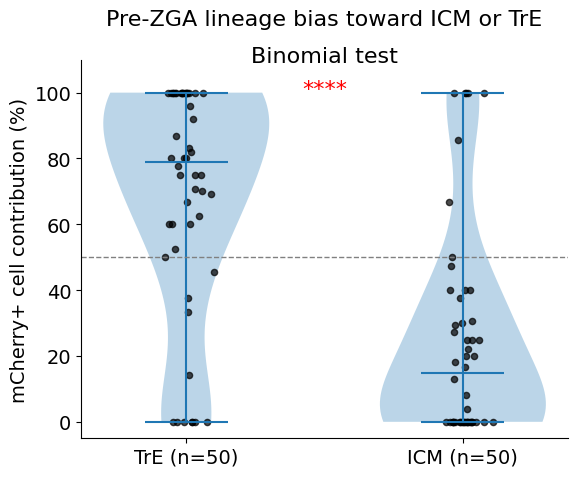

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binomtest

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 14,
    'axes.titlesize': 16,
    'axes.labelsize': 14
})

# =========================
# 1. 读取数据
# =========================
df = pd.read_csv("red_icm_te_count.txt", sep="\t")

icm = pd.to_numeric(df["Red ICM/Red total%"], errors='coerce')
te  = pd.to_numeric(df["Red TE/Red total%"], errors='coerce')

mask = ~(icm.isna() | te.isna())
icm = icm[mask]
te  = te[mask]

icm_all = icm.values
te_all  = te.values
n = len(icm_all)

print(f"Total embryos: {n}")

# =========================
# 显著性函数
# =========================
def get_significance_label(p):
    if p < 1e-4:
        return "****"
    elif p < 1e-3:
        return "***"
    elif p < 1e-2:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

# =========================
# 2. binomial test
# =========================
ICM_more = (icm_all > 50).sum()
TrE_more = (te_all > 50).sum()
res = binomtest(ICM_more, n, p=0.5)
p_binom = res.pvalue

sig_label = get_significance_label(p_binom)


print(f"ICM-biased: {ICM_more}/{n}")
print(f"TrE-biased: {TrE_more}/{n}")
print(f"p-value: {p_binom:.3e}")
print(f"significance: {sig_label}")

# =========================
# 3. 作图
# =========================
def plot_panel(ax, data, title):

    positions = [1, 2]

    # violin
    ax.violinplot(
        data,
        positions=positions,
        showmedians=True,
        widths=0.6
    )

    # =========================
    # scatter（统一黑色）
    # =========================
    for i, d in enumerate(data):
        x = np.random.normal(positions[i], 0.04, size=len(d))
        x = np.clip(x, positions[i]-0.15, positions[i]+0.15)
        ax.scatter(x, d, 
                   color='black',   # ⭐ 核心修改
                   alpha=0.7, 
                   s=20)

    # 50% line
    ax.axhline(50, linestyle='--', linewidth=1, color='grey')

    # axis
    ax.set_xticks(positions)
    ax.set_xticklabels([f"TrE (n={n})", f"ICM (n={n})"])
    ax.set_title(title, pad=25)

    # =========================
    # 显著性标注
    # =========================
    y = max(np.max(data[0]), np.max(data[1])) + 5
    h = 3

    ax.text(1.5, y+h-10, sig_label,
            ha='center', va='bottom',
            fontsize=16,
            color='red')   # ⭐ 红色显著性

    ax.text(1.5, y+h, "Binomial test",
            ha='center', va='bottom',
            fontsize=16)

    # clean style
    ax.set_ylim(-5, 110)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# =========================
# 4. plot
# =========================
fig, ax = plt.subplots(1, 1, figsize=(6, 5))

data_all = [te_all, icm_all]

plot_panel(
    ax,
    data_all,
    "Pre-ZGA lineage bias toward ICM or TrE"
)

ax.set_ylabel("mCherry+ cell contribution (%)")

plt.tight_layout()
plt.savefig('Lineage_allocation_bias.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


Per-embryo results:
 编号  SOX2  ICM_mCherry_pos  ICM_mCherry_neg  ICM_mCherry_pos_pct  ICM_mCherry_neg_pct  GATA3  TrE_mCherry_pos  TrE_mCherry_neg  TrE_mCherry_pos_pct  TrE_mCherry_neg_pct
  1     6                2                4                33.33                66.67     16                8                8                50.00                50.00
  2     3                0                3                 0.00               100.00     21               11               10                52.38                47.62
  3     2                0                2                 0.00               100.00     24                9               15                37.50                62.50
  4     4                4                0               100.00                 0.00     21                0               21                 0.00               100.00
  5     7                1                6                14.29                85.71      5                0                5        

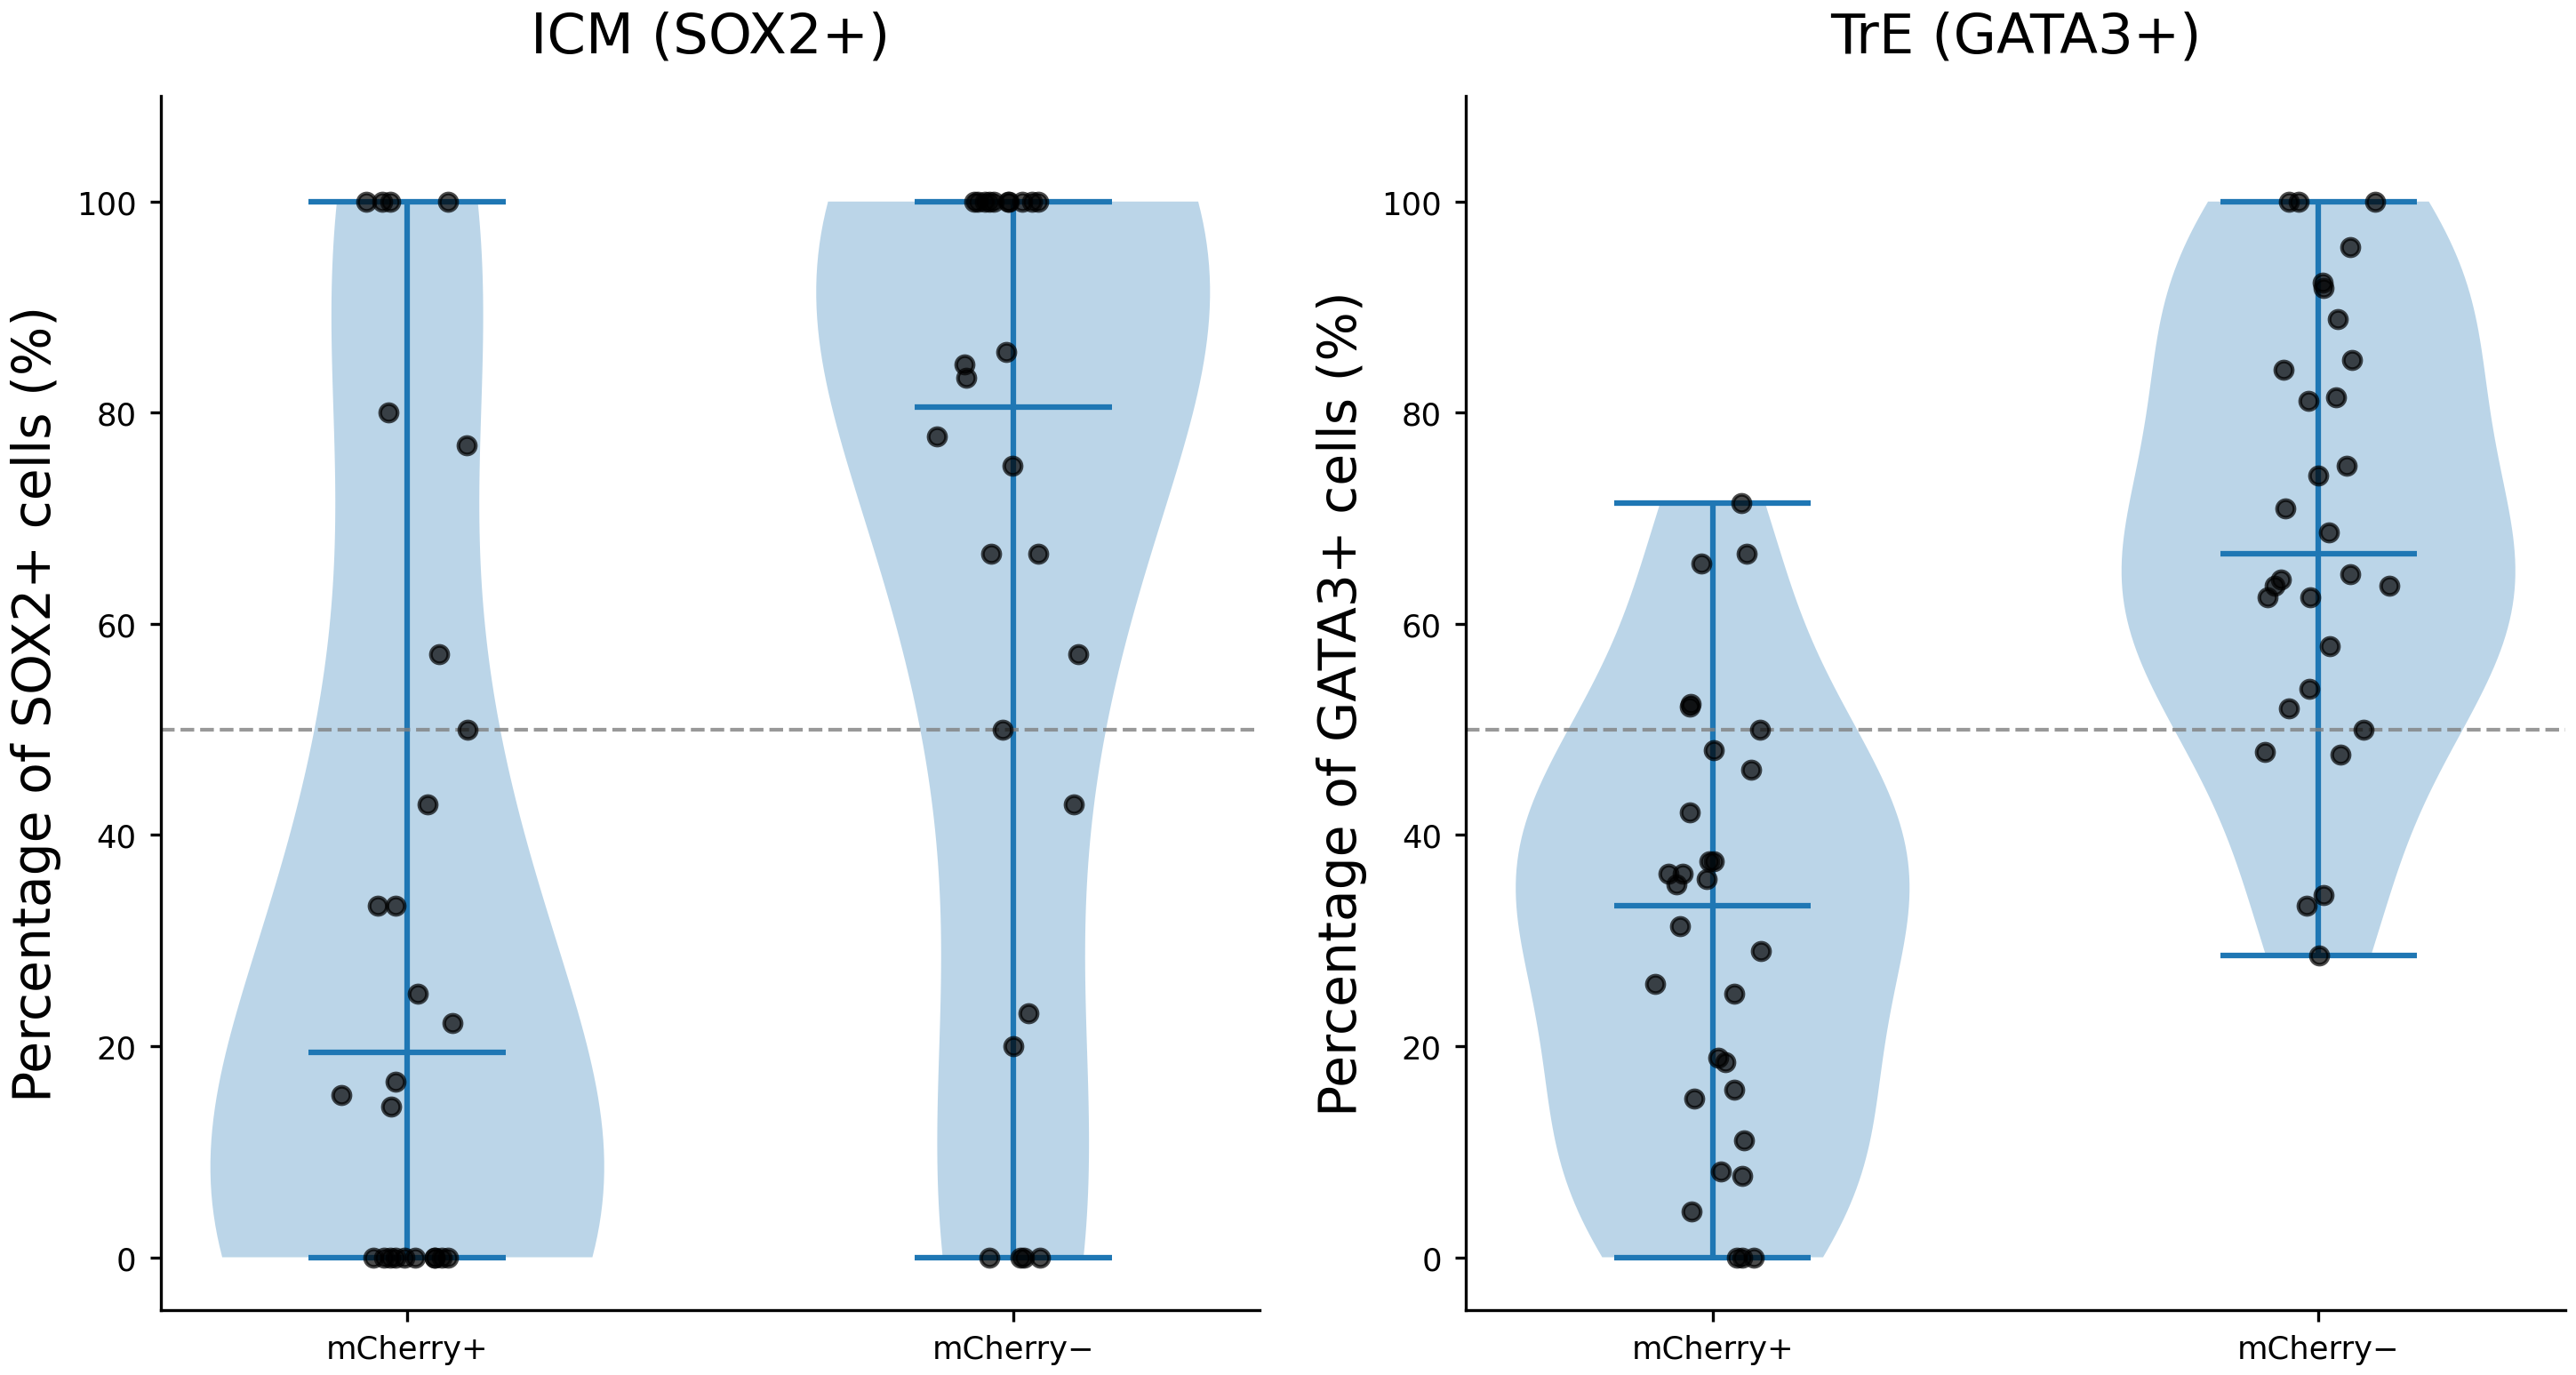

In [48]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Matplotlib settings
# ============================================================
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 14,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'svg.fonttype': 'none',
    'svg.hashsalt': 'hello'
})

np.random.seed(123)

# ============================================================
# 2. Read data
# ============================================================
df = pd.read_csv("red_icm_te_count.txt", sep="\t")

# Keep WT embryos only
df = df[df["treatment"].astype(str).str.strip() == "WT"].copy()

# Convert required columns to numeric
required_cols = [
    "编号",
    "mCherry-ICM",
    "mCherry-TE",
    "SOX2",
    "GATA3"
]

for col in required_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=required_cols).copy()

# ============================================================
# 3. Calculate mCherry-positive and negative cell numbers
# ============================================================

# ICM: SOX2-positive cells
df["ICM_mCherry_pos"] = df["mCherry-ICM"]
df["ICM_mCherry_neg"] = df["SOX2"] - df["mCherry-ICM"]

# TrE: GATA3-positive cells
df["TrE_mCherry_pos"] = df["mCherry-TE"]
df["TrE_mCherry_neg"] = df["GATA3"] - df["mCherry-TE"]

# Check for impossible cell counts
count_cols = [
    "ICM_mCherry_pos",
    "ICM_mCherry_neg",
    "TrE_mCherry_pos",
    "TrE_mCherry_neg"
]

if (df[count_cols] < 0).any().any():
    invalid = df.loc[
        (df[count_cols] < 0).any(axis=1),
        ["编号"] + count_cols
    ]
    raise ValueError(
        "Some embryos have negative calculated cell counts:\n"
        + invalid.to_string(index=False)
    )

# ============================================================
# 4. Calculate percentages within each lineage
# ============================================================

# Avoid division by zero
df["ICM_mCherry_pos_pct"] = np.where(
    df["SOX2"] > 0,
    df["ICM_mCherry_pos"] / df["SOX2"] * 100,
    np.nan
)

df["ICM_mCherry_neg_pct"] = np.where(
    df["SOX2"] > 0,
    df["ICM_mCherry_neg"] / df["SOX2"] * 100,
    np.nan
)

df["TrE_mCherry_pos_pct"] = np.where(
    df["GATA3"] > 0,
    df["TrE_mCherry_pos"] / df["GATA3"] * 100,
    np.nan
)

df["TrE_mCherry_neg_pct"] = np.where(
    df["GATA3"] > 0,
    df["TrE_mCherry_neg"] / df["GATA3"] * 100,
    np.nan
)

# ============================================================
# 5. Export per-embryo results
# ============================================================

output_cols = [
    "编号",
    "SOX2",
    "ICM_mCherry_pos",
    "ICM_mCherry_neg",
    "ICM_mCherry_pos_pct",
    "ICM_mCherry_neg_pct",
    "GATA3",
    "TrE_mCherry_pos",
    "TrE_mCherry_neg",
    "TrE_mCherry_pos_pct",
    "TrE_mCherry_neg_pct"
]

result = df[output_cols].copy()

result.to_csv(
    "WT_embryo_lineage_mCherry_percentages.txt",
    sep="\t",
    index=False,
    float_format="%.4f"
)

print("\nPer-embryo results:")
print(result.to_string(index=False, float_format="%.2f"))

# ============================================================
# 6. Plot
# Each point represents one embryo
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(10, 5.5))

panels = [
    {
        "ax": axes[0],
        "data": [
            df["ICM_mCherry_pos_pct"].dropna().values,
            df["ICM_mCherry_neg_pct"].dropna().values
        ],
        "labels": ["mCherry+", "mCherry−"],
        "title": "ICM (SOX2+)",
        "ylabel": "Percentage of SOX2+ cells (%)"
    },
    {
        "ax": axes[1],
        "data": [
            df["TrE_mCherry_pos_pct"].dropna().values,
            df["TrE_mCherry_neg_pct"].dropna().values
        ],
        "labels": ["mCherry+", "mCherry−"],
        "title": "TrE (GATA3+)",
        "ylabel": "Percentage of GATA3+ cells (%)"
    }
]

for panel in panels:
    ax = panel["ax"]
    data = panel["data"]

    positions = [1, 2]

    # Violin plots
    vp = ax.violinplot(
        data,
        positions=positions,
        showmedians=True,
        widths=0.65
    )

    # Black scatter points
    for i, values in enumerate(data):
        if len(values) == 0:
            continue

        x = np.random.normal(
            positions[i],
            0.045,
            size=len(values)
        )
        x = np.clip(
            x,
            positions[i] - 0.15,
            positions[i] + 0.15
        )

        ax.scatter(
            x,
            values,
            color="black",
            alpha=0.7,
            s=22,
            zorder=3
        )

    # Reference line at 50%
    ax.axhline(
        50,
        linestyle="--",
        linewidth=1,
        color="grey",
        alpha=0.8
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(panel["labels"])
    ax.set_title(panel["title"], pad=12)
    ax.set_ylabel(panel["ylabel"])
    ax.set_ylim(-5, 110)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "WT_lineage_mCherry_percentages.svg",
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    "WT_lineage_mCherry_percentages.pdf",
    bbox_inches="tight",
    transparent=True
)

plt.show()



BIMODALITY TESTS FOR mCherry+ PROPORTIONS

------------------------------------------------------------
  ICM (n = 26)
------------------------------------------------------------
  Hartigan dip test:
    dip statistic = 0.0769
    P value       = 0.2324
    -> no significant deviation from unimodality
  GMM comparison:
    BIC (1 comp) = 267.674
    BIC (2 comp) = 88.044
    ΔBIC (1-2)   = +179.630
    Preferred    = 2-component
  0.5 split:
    > 50%  : 7  (26.9%)
    ≤ 50%  : 19
    Binomial P (vs 50:50) = 0.028959

------------------------------------------------------------
  TrE (n = 30)
------------------------------------------------------------
  Hartigan dip test:
    dip statistic = 0.0500
    P value       = 0.83908
    -> no significant deviation from unimodality
  GMM comparison:
    BIC (1 comp) = 271.954
    BIC (2 comp) = 278.488
    ΔBIC (1-2)   = -6.534
    Preferred    = 1-component
  0.5 split:
    > 50%  : 5  (16.7%)
    ≤ 50%  : 25
    Binomial P (vs 50:50) = 0.

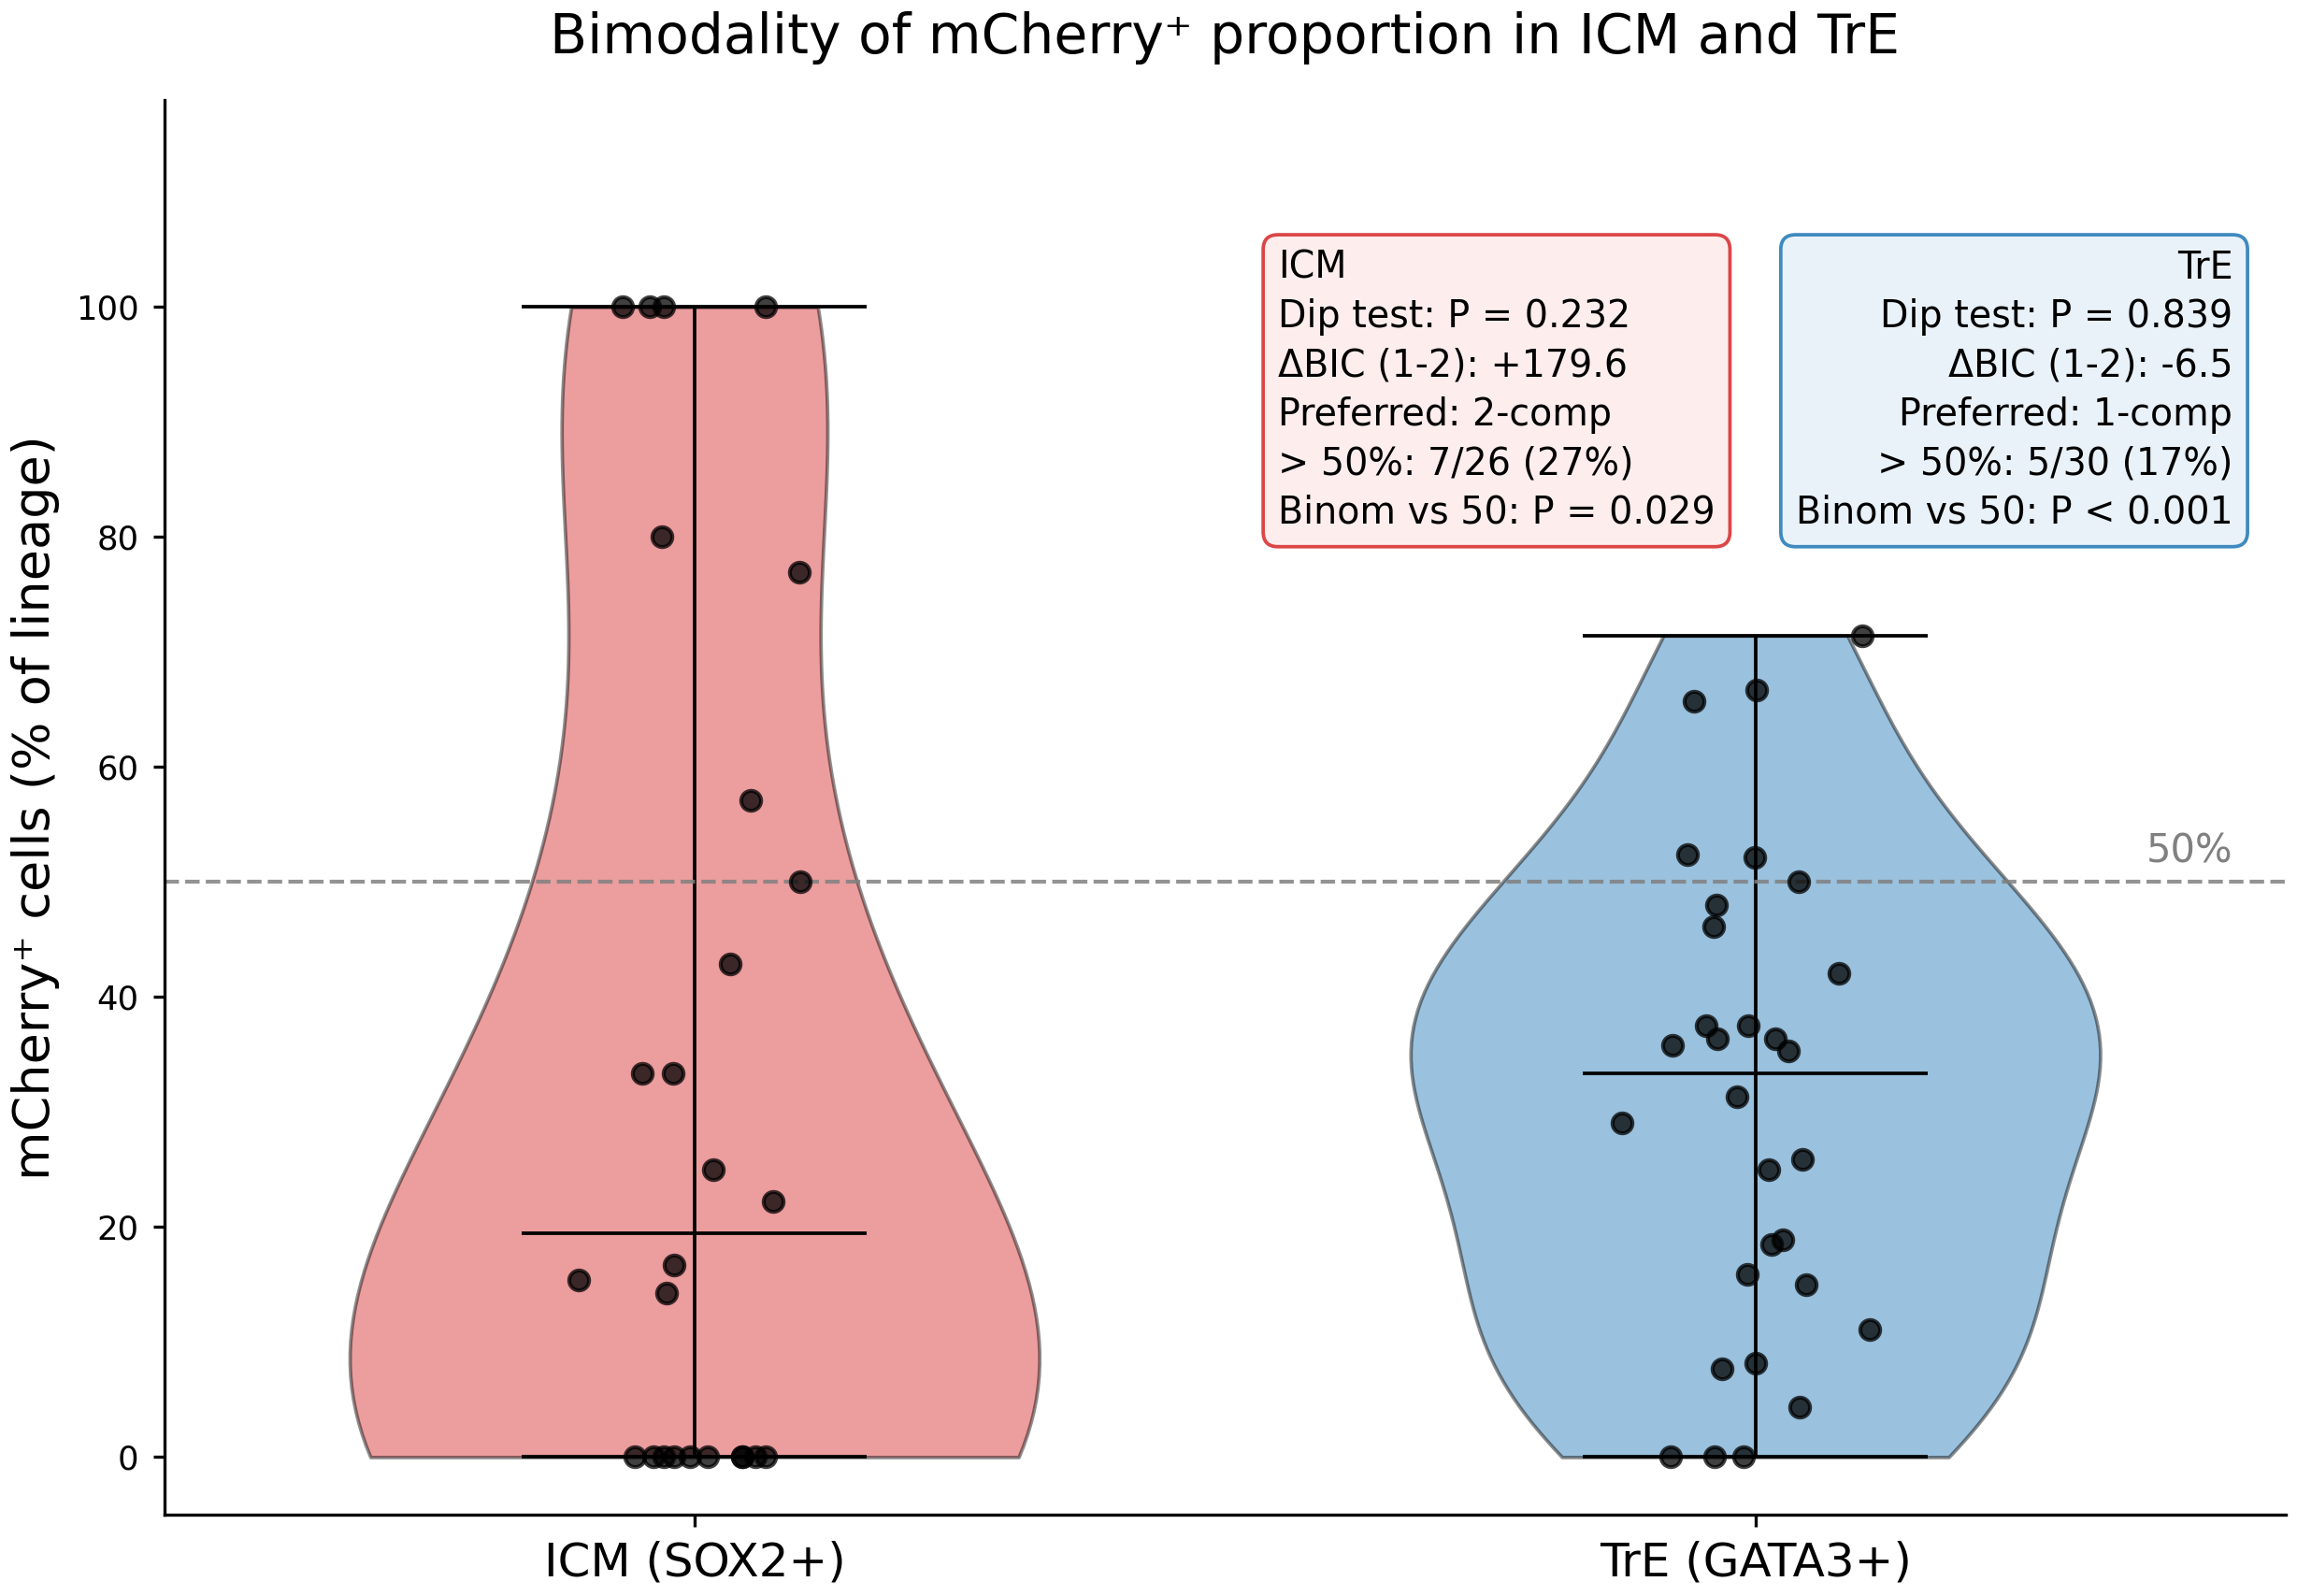


Figure saved: WT_mCherry_pos_bimodality_tests.svg / .pdf


In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from scipy.stats import gaussian_kde, binomtest
from sklearn.mixture import GaussianMixture

try:
    from diptest import diptest
except ImportError:
    raise ImportError("Install diptest: pip install diptest")

# ============================================================
# 1. Matplotlib settings
# ============================================================
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 13,
    'axes.titlesize': 14,
    'axes.labelsize': 13,
    'svg.fonttype': 'none',
    'svg.hashsalt': 'hello'
})

np.random.seed(123)
RANDOM_SEED = 12345

# ============================================================
# 2. Read data (WT only)
# ============================================================
df = pd.read_csv("red_icm_te_count.txt", sep="\t")
df = df[df["treatment"].astype(str).str.strip() == "WT"].copy()

required_cols = ["编号", "mCherry-ICM", "mCherry-TE", "SOX2", "GATA3"]
for col in required_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=required_cols).copy()

# ============================================================
# 3. mCherry+ percentage per lineage
# ============================================================
df["ICM_mCherry_pos_pct"] = np.where(
    df["SOX2"] > 0, df["mCherry-ICM"] / df["SOX2"] * 100, np.nan
)
df["TrE_mCherry_pos_pct"] = np.where(
    df["GATA3"] > 0, df["mCherry-TE"] / df["GATA3"] * 100, np.nan
)

# ============================================================
# 4. Bimodality / 0.5-based tests for each lineage
# ============================================================
def analyze_bimodality(values, name):
    """
    Run dip test + GMM 1v2 BIC + 0.5 split binomial test.
    """
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)

    result = {
        "name": name,
        "n": n,
        "dip_stat": np.nan,
        "dip_pvalue": np.nan,
        "gmm_bic_1": np.nan,
        "gmm_bic_2": np.nan,
        "delta_bic_1_minus_2": np.nan,
        "preferred": "NA",
        "n_above_50": int(np.sum(x > 50)),
        "n_below_50": int(np.sum(x <= 50)),
        "frac_above_50": np.nan,
        "binom_p_vs_50": np.nan,
    }

    if n < 3:
        return result

    # --- Hartigan dip test ---
    try:
        dip_stat, dip_p = diptest(x)
        result["dip_stat"] = float(dip_stat)
        result["dip_pvalue"] = float(dip_p)
    except Exception as exc:
        print(f"Warning: dip test failed for {name}: {exc}")

    # --- GMM 1 vs 2 components ---
    if n >= 5 and np.unique(x).size >= 2:
        X = x.reshape(-1, 1)
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                g1 = GaussianMixture(
                    n_components=1, covariance_type="full",
                    n_init=50, random_state=RANDOM_SEED,
                    reg_covar=1e-6
                ).fit(X)
                g2 = GaussianMixture(
                    n_components=2, covariance_type="full",
                    n_init=50, random_state=RANDOM_SEED,
                    reg_covar=1e-6
                ).fit(X)
            bic1 = float(g1.bic(X))
            bic2 = float(g2.bic(X))
            result["gmm_bic_1"] = bic1
            result["gmm_bic_2"] = bic2
            result["delta_bic_1_minus_2"] = bic1 - bic2
            if bic2 < bic1:
                result["preferred"] = "2-component"
            elif bic1 < bic2:
                result["preferred"] = "1-component"
            else:
                result["preferred"] = "Tie"
        except (ValueError, np.linalg.LinAlgError) as exc:
            print(f"Warning: GMM failed for {name}: {exc}")

    # --- 0.5 split binomial test ---
    n_above = int(np.sum(x > 50))
    n_below = int(np.sum(x <= 50))
    n_nonzero = n_above + n_below
    result["n_above_50"] = n_above
    result["n_below_50"] = n_below
    result["frac_above_50"] = n_above / n_nonzero if n_nonzero > 0 else np.nan

    if n_nonzero > 0:
        try:
            result["binom_p_vs_50"] = float(
                binomtest(n_above, n_nonzero, 0.5,
                          alternative="two-sided").pvalue
            )
        except Exception:
            pass

    return result

icm_stats = analyze_bimodality(df["ICM_mCherry_pos_pct"], "ICM")
tre_stats = analyze_bimodality(df["TrE_mCherry_pos_pct"], "TrE")

# ============================================================
# 5. Print results
# ============================================================
def print_stats(s):
    print(f"\n{'-' * 60}")
    print(f"  {s['name']} (n = {s['n']})")
    print(f"{'-' * 60}")

    if np.isfinite(s["dip_pvalue"]):
        print(f"  Hartigan dip test:")
        print(f"    dip statistic = {s['dip_stat']:.4f}")
        print(f"    P value       = {s['dip_pvalue']:.5g}")
        if s["dip_pvalue"] < 0.05:
            print(f"    -> significant deviation from unimodality")
        else:
            print(f"    -> no significant deviation from unimodality")
    else:
        print(f"  Hartigan dip test: unavailable")

    if np.isfinite(s["delta_bic_1_minus_2"]):
        print(f"  GMM comparison:")
        print(f"    BIC (1 comp) = {s['gmm_bic_1']:.3f}")
        print(f"    BIC (2 comp) = {s['gmm_bic_2']:.3f}")
        print(f"    ΔBIC (1-2)   = {s['delta_bic_1_minus_2']:+.3f}")
        print(f"    Preferred    = {s['preferred']}")

    print(f"  0.5 split:")
    print(f"    > 50%  : {s['n_above_50']}  ({s['frac_above_50']*100:.1f}%)")
    print(f"    ≤ 50%  : {s['n_below_50']}")
    print(f"    Binomial P (vs 50:50) = {s['binom_p_vs_50']:.5g}")

print("\n" + "=" * 60)
print("BIMODALITY TESTS FOR mCherry+ PROPORTIONS")
print("=" * 60)
print_stats(icm_stats)
print_stats(tre_stats)

# ============================================================
# 6. Plot: 2 violins (ICM / TrE), annotated with test results
# ============================================================
fig, ax = plt.subplots(figsize=(8.5, 6.0))

positions = [1, 2]
labels    = ["ICM (SOX2+)", "TrE (GATA3+)"]
colors    = ["#D62728", "#1F77B4"]

data = [
    df["ICM_mCherry_pos_pct"].dropna().values,
    df["TrE_mCherry_pos_pct"].dropna().values,
]

# Violin
vp = ax.violinplot(
    data,
    positions=positions,
    showmedians=True,
    widths=0.65
)

for body, col in zip(vp["bodies"], colors):
    body.set_facecolor(col)
    body.set_edgecolor("black")
    body.set_alpha(0.45)
    body.set_linewidth(0.9)

for part in ("cmedians", "cbars", "cmins", "cmaxes"):
    if part in vp:
        vp[part].set_color("black")
        vp[part].set_linewidth(0.9)

# Scatter points
for i, values in enumerate(data):
    if len(values) == 0:
        continue
    x = np.random.normal(positions[i], 0.045, size=len(values))
    x = np.clip(x, positions[i] - 0.15, positions[i] + 0.15)
    ax.scatter(
        x, values,
        color="black", alpha=0.75, s=26, zorder=3
    )

# Reference line at 50%
ax.axhline(
    50, linestyle="--", linewidth=1.0,
    color="grey", alpha=0.85, zorder=2
)
ax.text(
    2.45, 51, "50%", ha="right", va="bottom",
    fontsize=10, color="grey"
)

# ---------- Statistics annotation ----------
def fmt_p(p):
    if not np.isfinite(p):
        return "NA"
    if p < 0.001:
        return "P < 0.001"
    return f"P = {p:.3f}"

def make_annotation(s, label):
    lines = [label]

    if np.isfinite(s["dip_pvalue"]):
        lines.append(f"Dip test: {fmt_p(s['dip_pvalue'])}")

    if np.isfinite(s["delta_bic_1_minus_2"]):
        db = s["delta_bic_1_minus_2"]
        pref = "2-comp" if db > 0 else "1-comp"
        lines.append(f"ΔBIC (1-2): {db:+.1f}")
        lines.append(f"Preferred: {pref}")

    lines.append(f"> 50%: {s['n_above_50']}/{s['n']} "
                 f"({s['frac_above_50']*100:.0f}%)")
    lines.append(f"Binom vs 50: {fmt_p(s['binom_p_vs_50'])}")

    return "\n".join(lines)

ax.text(
    1.55, 105, make_annotation(icm_stats, "ICM"),
    ha="left", va="top",
    fontsize=9.5, linespacing=1.4,
    bbox=dict(boxstyle="round,pad=0.4",
              facecolor="#FDECEA", edgecolor="#D62728",
              linewidth=0.9, alpha=0.85)
)

ax.text(
    2.45, 105, make_annotation(tre_stats, "TrE"),
    ha="right", va="top",
    fontsize=9.5, linespacing=1.4,
    bbox=dict(boxstyle="round,pad=0.4",
              facecolor="#E7F0F9", edgecolor="#1F77B4",
              linewidth=0.9, alpha=0.85)
)

# Axis
ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=12)
ax.set_ylabel("mCherry⁺ cells (% of lineage)", fontsize=13)
ax.set_xlim(0.5, 2.5)
ax.set_ylim(-5, 118)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_title(
    "Bimodality of mCherry⁺ proportion in ICM and TrE",
    pad=12
)

plt.tight_layout()

plt.savefig(
    "WT_mCherry_pos_bimodality_tests.svg",
    bbox_inches="tight", transparent=True
)
plt.savefig(
    "WT_mCherry_pos_bimodality_tests.pdf",
    bbox_inches="tight", transparent=True
)

plt.show()

print("\nFigure saved: WT_mCherry_pos_bimodality_tests.svg / .pdf")


Welch's t-test results (D vs ND):
  ICM : t = +9.986, P = 9.8366e-07  (***)
  TrE : t = +7.292, P = 2.4217e-05  (***)


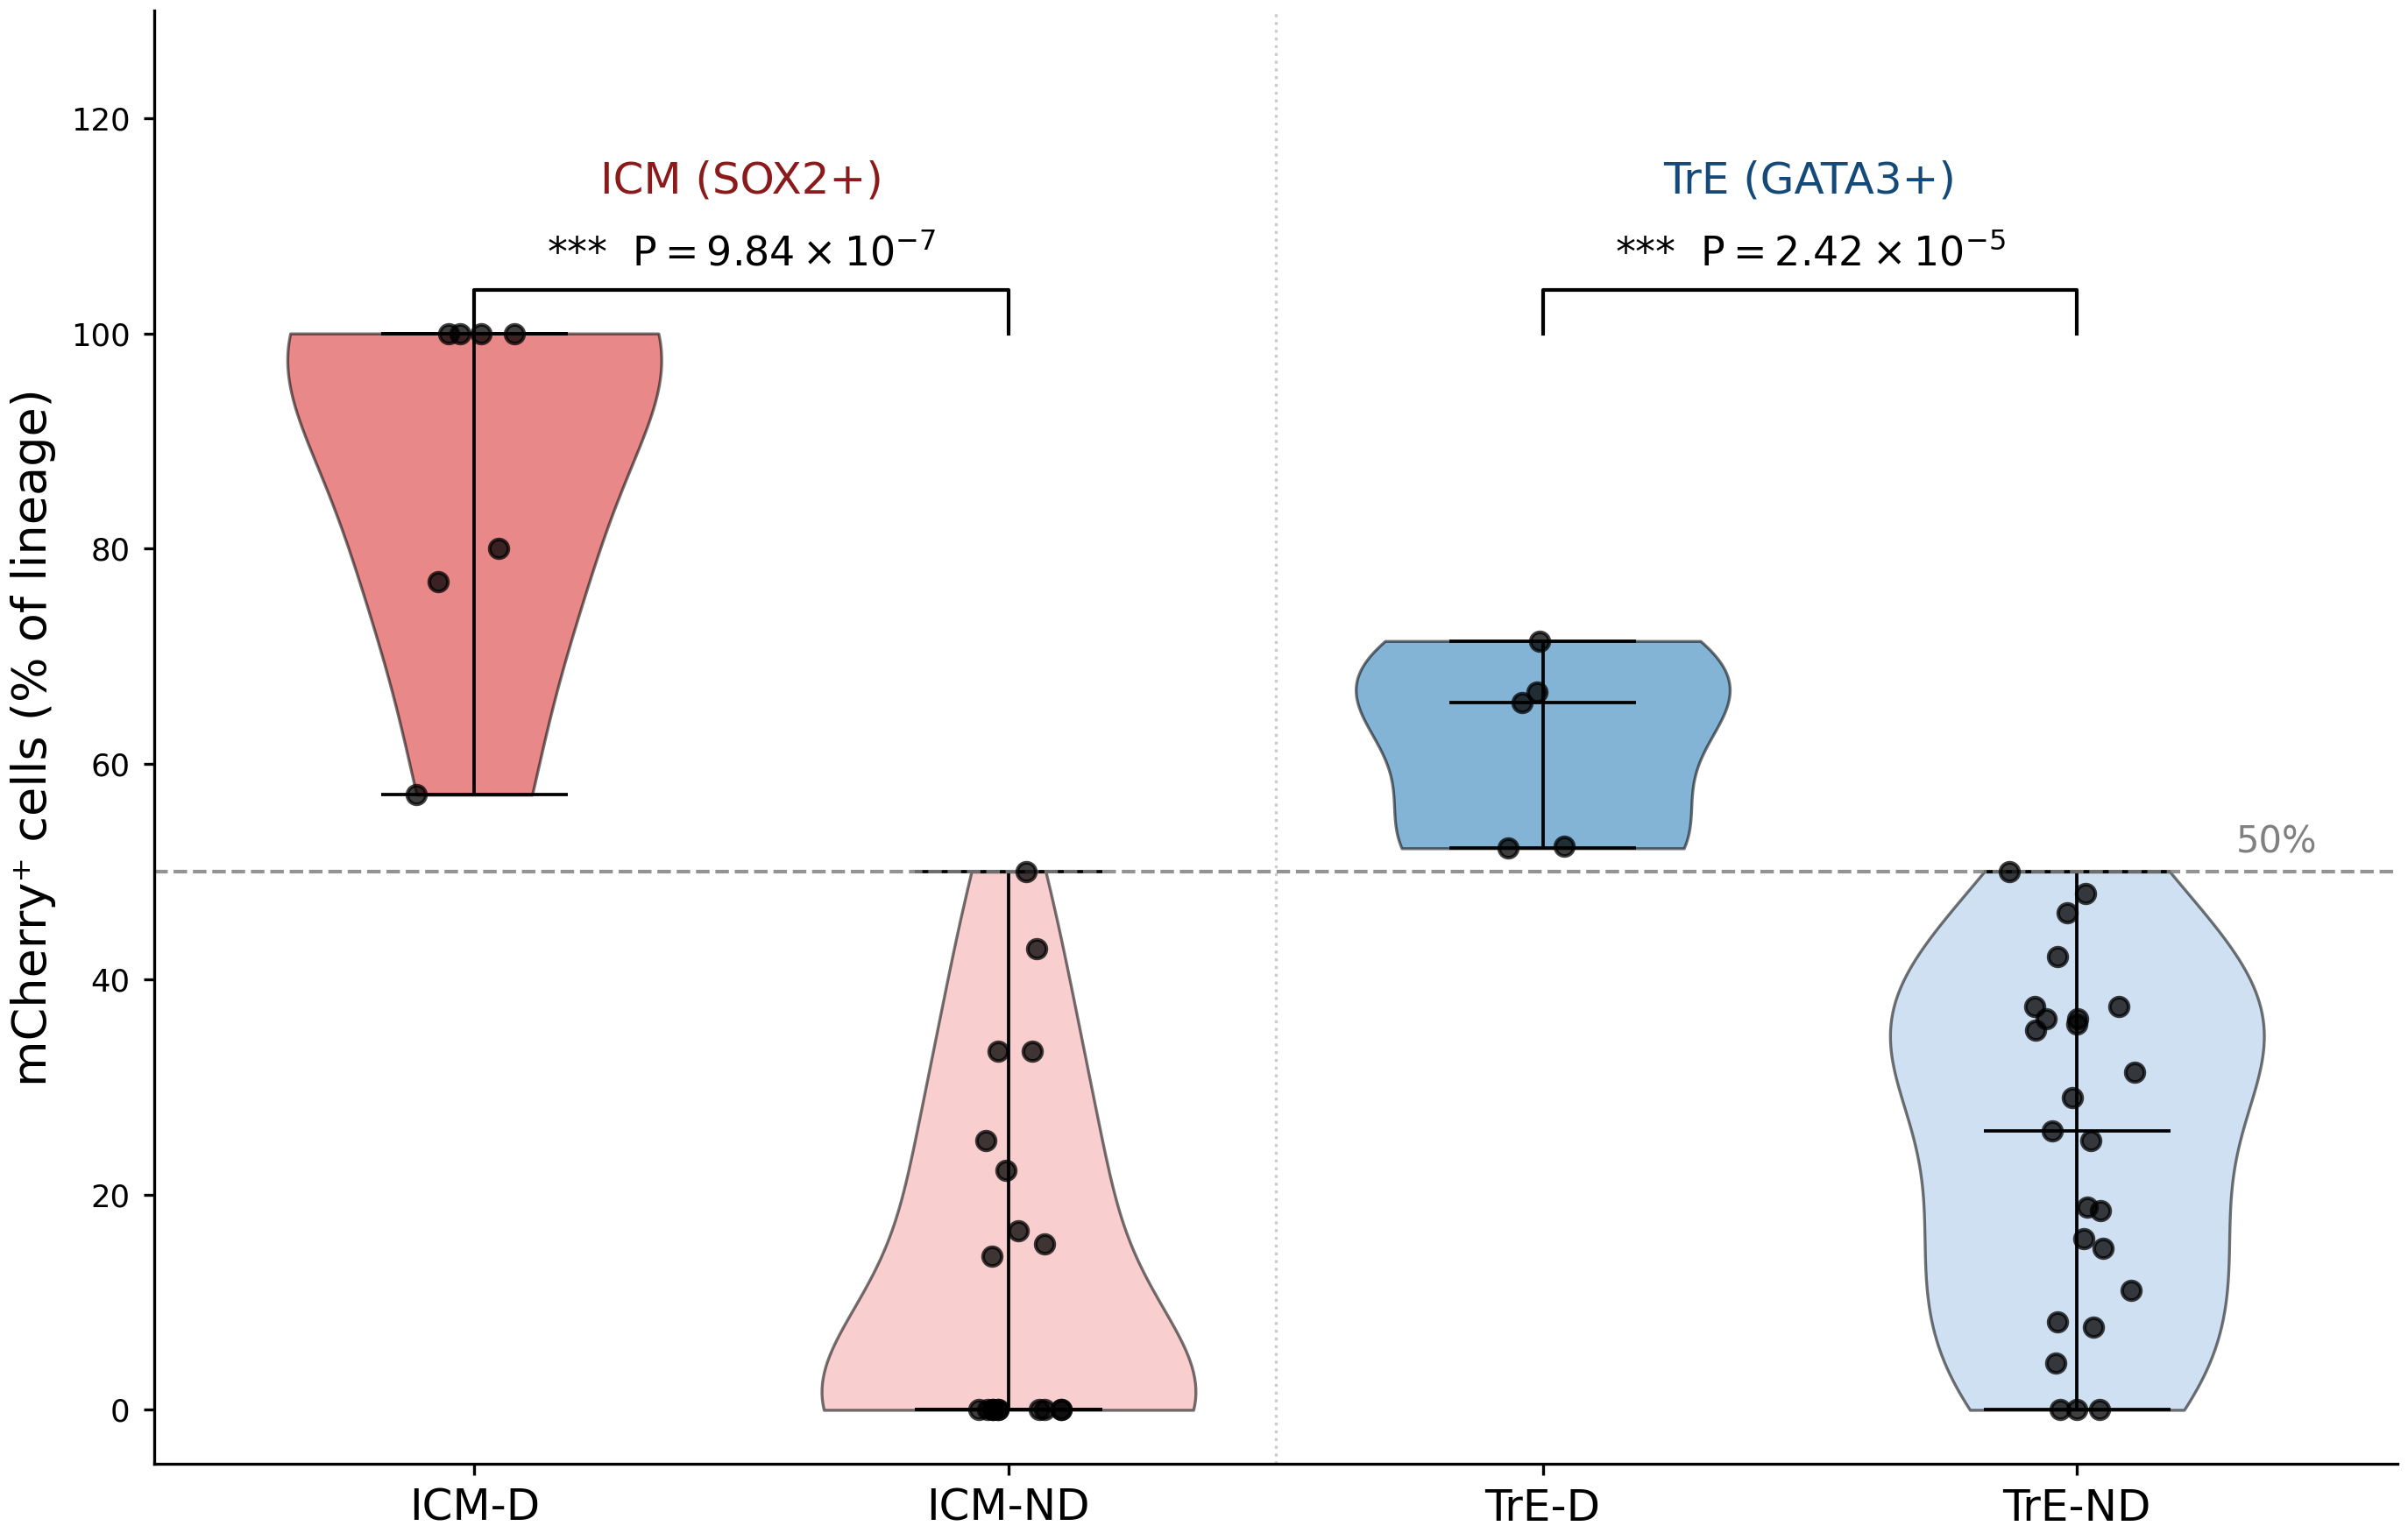

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ============================================================
# 1. Matplotlib settings
# ============================================================
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 14,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'svg.fonttype': 'none',
    'svg.hashsalt': 'hello'
})

np.random.seed(123)

# ============================================================
# 2. Read data
# ============================================================
df = pd.read_csv("red_icm_te_count.txt", sep="\t")
df = df[df["treatment"].astype(str).str.strip() == "WT"].copy()

required_cols = ["编号", "mCherry-ICM", "mCherry-TE", "SOX2", "GATA3"]
for col in required_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=required_cols).copy()

# ============================================================
# 3. mCherry+ percentages within each lineage
# ============================================================
df["ICM_mCherry_pos_pct"] = np.where(
    df["SOX2"] > 0, df["mCherry-ICM"] / df["SOX2"] * 100, np.nan
)
df["TrE_mCherry_pos_pct"] = np.where(
    df["GATA3"] > 0, df["mCherry-TE"] / df["GATA3"] * 100, np.nan
)

# ============================================================
# 4. Classify each embryo by > 50% rule
# ============================================================
df["ICM_class"] = np.where(
    df["ICM_mCherry_pos_pct"] > 50, "ICM-D",
    np.where(df["ICM_mCherry_pos_pct"].notna(), "ICM-ND", np.nan)
)
df["TrE_class"] = np.where(
    df["TrE_mCherry_pos_pct"] > 50, "TrE-D",
    np.where(df["TrE_mCherry_pos_pct"].notna(), "TrE-ND", np.nan)
)

# ============================================================
# 5. Group data
# ============================================================
groups = {
    "ICM-D":  df.loc[df["ICM_class"] == "ICM-D",  "ICM_mCherry_pos_pct"].dropna().values,
    "ICM-ND": df.loc[df["ICM_class"] == "ICM-ND", "ICM_mCherry_pos_pct"].dropna().values,
    "TrE-D":  df.loc[df["TrE_class"] == "TrE-D",  "TrE_mCherry_pos_pct"].dropna().values,
    "TrE-ND": df.loc[df["TrE_class"] == "TrE-ND", "TrE_mCherry_pos_pct"].dropna().values,
}

# ============================================================
# 6. t-tests: D vs ND within each lineage (Welch's)
# ============================================================
def fmt_p(p):
    if not np.isfinite(p):
        return r"$P = \mathrm{NA}$"
    if p <= 0:
        return r"$P < 10^{-300}$"

    exponent = int(np.floor(np.log10(p)))
    coefficient = p / (10 ** exponent)

    return rf"$P = {coefficient:.2f} \times 10^{{{exponent}}}$"

def stars(p):
    if not np.isfinite(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "ns"

# ICM: D vs ND
t_icm, p_icm = stats.ttest_ind(
    groups["ICM-D"], groups["ICM-ND"], equal_var=False
)

# TrE: D vs ND
t_tre, p_tre = stats.ttest_ind(
    groups["TrE-D"], groups["TrE-ND"], equal_var=False
)

print("\nWelch's t-test results (D vs ND):")
print(f"  ICM : t = {t_icm:+.3f}, P = {p_icm:.5g}  ({stars(p_icm)})")
print(f"  TrE : t = {t_tre:+.3f}, P = {p_tre:.5g}  ({stars(p_tre)})")

# ============================================================
# 7. Plot: 4 violins + t-test annotation
# ============================================================
fig, ax = plt.subplots(1, 1, figsize=(9.5, 6.2))

positions = [1, 2, 3, 4]
labels    = ["ICM-D", "ICM-ND", "TrE-D", "TrE-ND"]
data      = [groups["ICM-D"], groups["ICM-ND"],
             groups["TrE-D"], groups["TrE-ND"]]

colors = ["#D62728", "#F4A6A6", "#1F77B4", "#A6C8E8"]

# Violin
vp = ax.violinplot(
    data, positions=positions,
    showmedians=True, widths=0.7
)

for body, col in zip(vp["bodies"], colors):
    body.set_facecolor(col)
    body.set_edgecolor("black")
    body.set_alpha(0.55)
    body.set_linewidth(0.8)

for part in ("cmedians", "cbars", "cmins", "cmaxes"):
    if part in vp:
        vp[part].set_color("black")
        vp[part].set_linewidth(0.9)

# Scatter points
for i, values in enumerate(data):
    if len(values) == 0:
        continue
    x = np.random.normal(positions[i], 0.045, size=len(values))
    x = np.clip(x, positions[i] - 0.16, positions[i] + 0.16)
    ax.scatter(
        x, values,
        color="black", alpha=0.75, s=26, zorder=3
    )

# Reference line at 50%
ax.axhline(
    50, linestyle="--", linewidth=1,
    color="grey", alpha=0.85, zorder=2
)
ax.text(
    4.45, 51, "50%", ha="right", va="bottom",
    fontsize=10, color="grey"
)

# Panel separator
ax.axvline(2.5, color="#CCCCCC", linewidth=0.8,
           linestyle=":", zorder=0)

# Lineage labels above groups
ax.text(1.5, 113, "ICM (SOX2+)", ha="center",
        fontsize=12, color="#8B1A1A")
ax.text(3.5, 113, "TrE (GATA3+)", ha="center",
        fontsize=12, color="#134A7A")

# ---- t-test bracket + P value for ICM ----
def add_sig_bracket(ax, x1, x2, y, y_h, text):
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + y_h, y + y_h, y],
        color="black", linewidth=1.0, clip_on=False
    )
    ax.text(
        (x1 + x2) / 2, y + y_h + 1.5, text,
        ha="center", va="bottom", fontsize=11
    )

bracket_y = 100
add_sig_bracket(
    ax, 1, 2, bracket_y, 4,
    f"{stars(p_icm)}  {fmt_p(p_icm)}"
)
add_sig_bracket(
    ax, 3, 4, bracket_y, 4,
    f"{stars(p_tre)}  {fmt_p(p_tre)}"
)

# Axis
ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=12)
ax.set_ylabel("mCherry⁺ cells (% of lineage)", fontsize=13)
ax.set_ylim(-5, 130)
ax.set_xlim(0.4, 4.6)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "WT_mCherry_pos_ICM_TrE_classified.svg",
    bbox_inches="tight", transparent=True
)
plt.savefig(
    "WT_mCherry_pos_ICM_TrE_classified.pdf",
    bbox_inches="tight", transparent=True
)

plt.show()


Per-embryo mCherry+ percentages:
 编号  SOX2  GATA3  mCherry-ICM  mCherry-TE  pct_of_All  pct_of_TrE  pct_of_ICM
  1     6     16            2           8       45.45       50.00       33.33
  2     3     21            0          11       45.83       52.38        0.00
  3     2     24            0           9       34.62       37.50        0.00
  4     4     21            4           0       16.00        0.00      100.00
  5     7      5            1           0        8.33        0.00       14.29
  6     9     31            2           9       27.50       29.03       22.22
  7    13      9            2           0        9.09        0.00       15.38
  8     2     39            0           3        7.32        7.69        0.00
  9     2     23            0           1        4.00        4.35        0.00
 10    10     44            0           7       12.96       15.91        0.00
 11     5     49            4           4       14.81        8.16       80.00
 12     4     34            0 

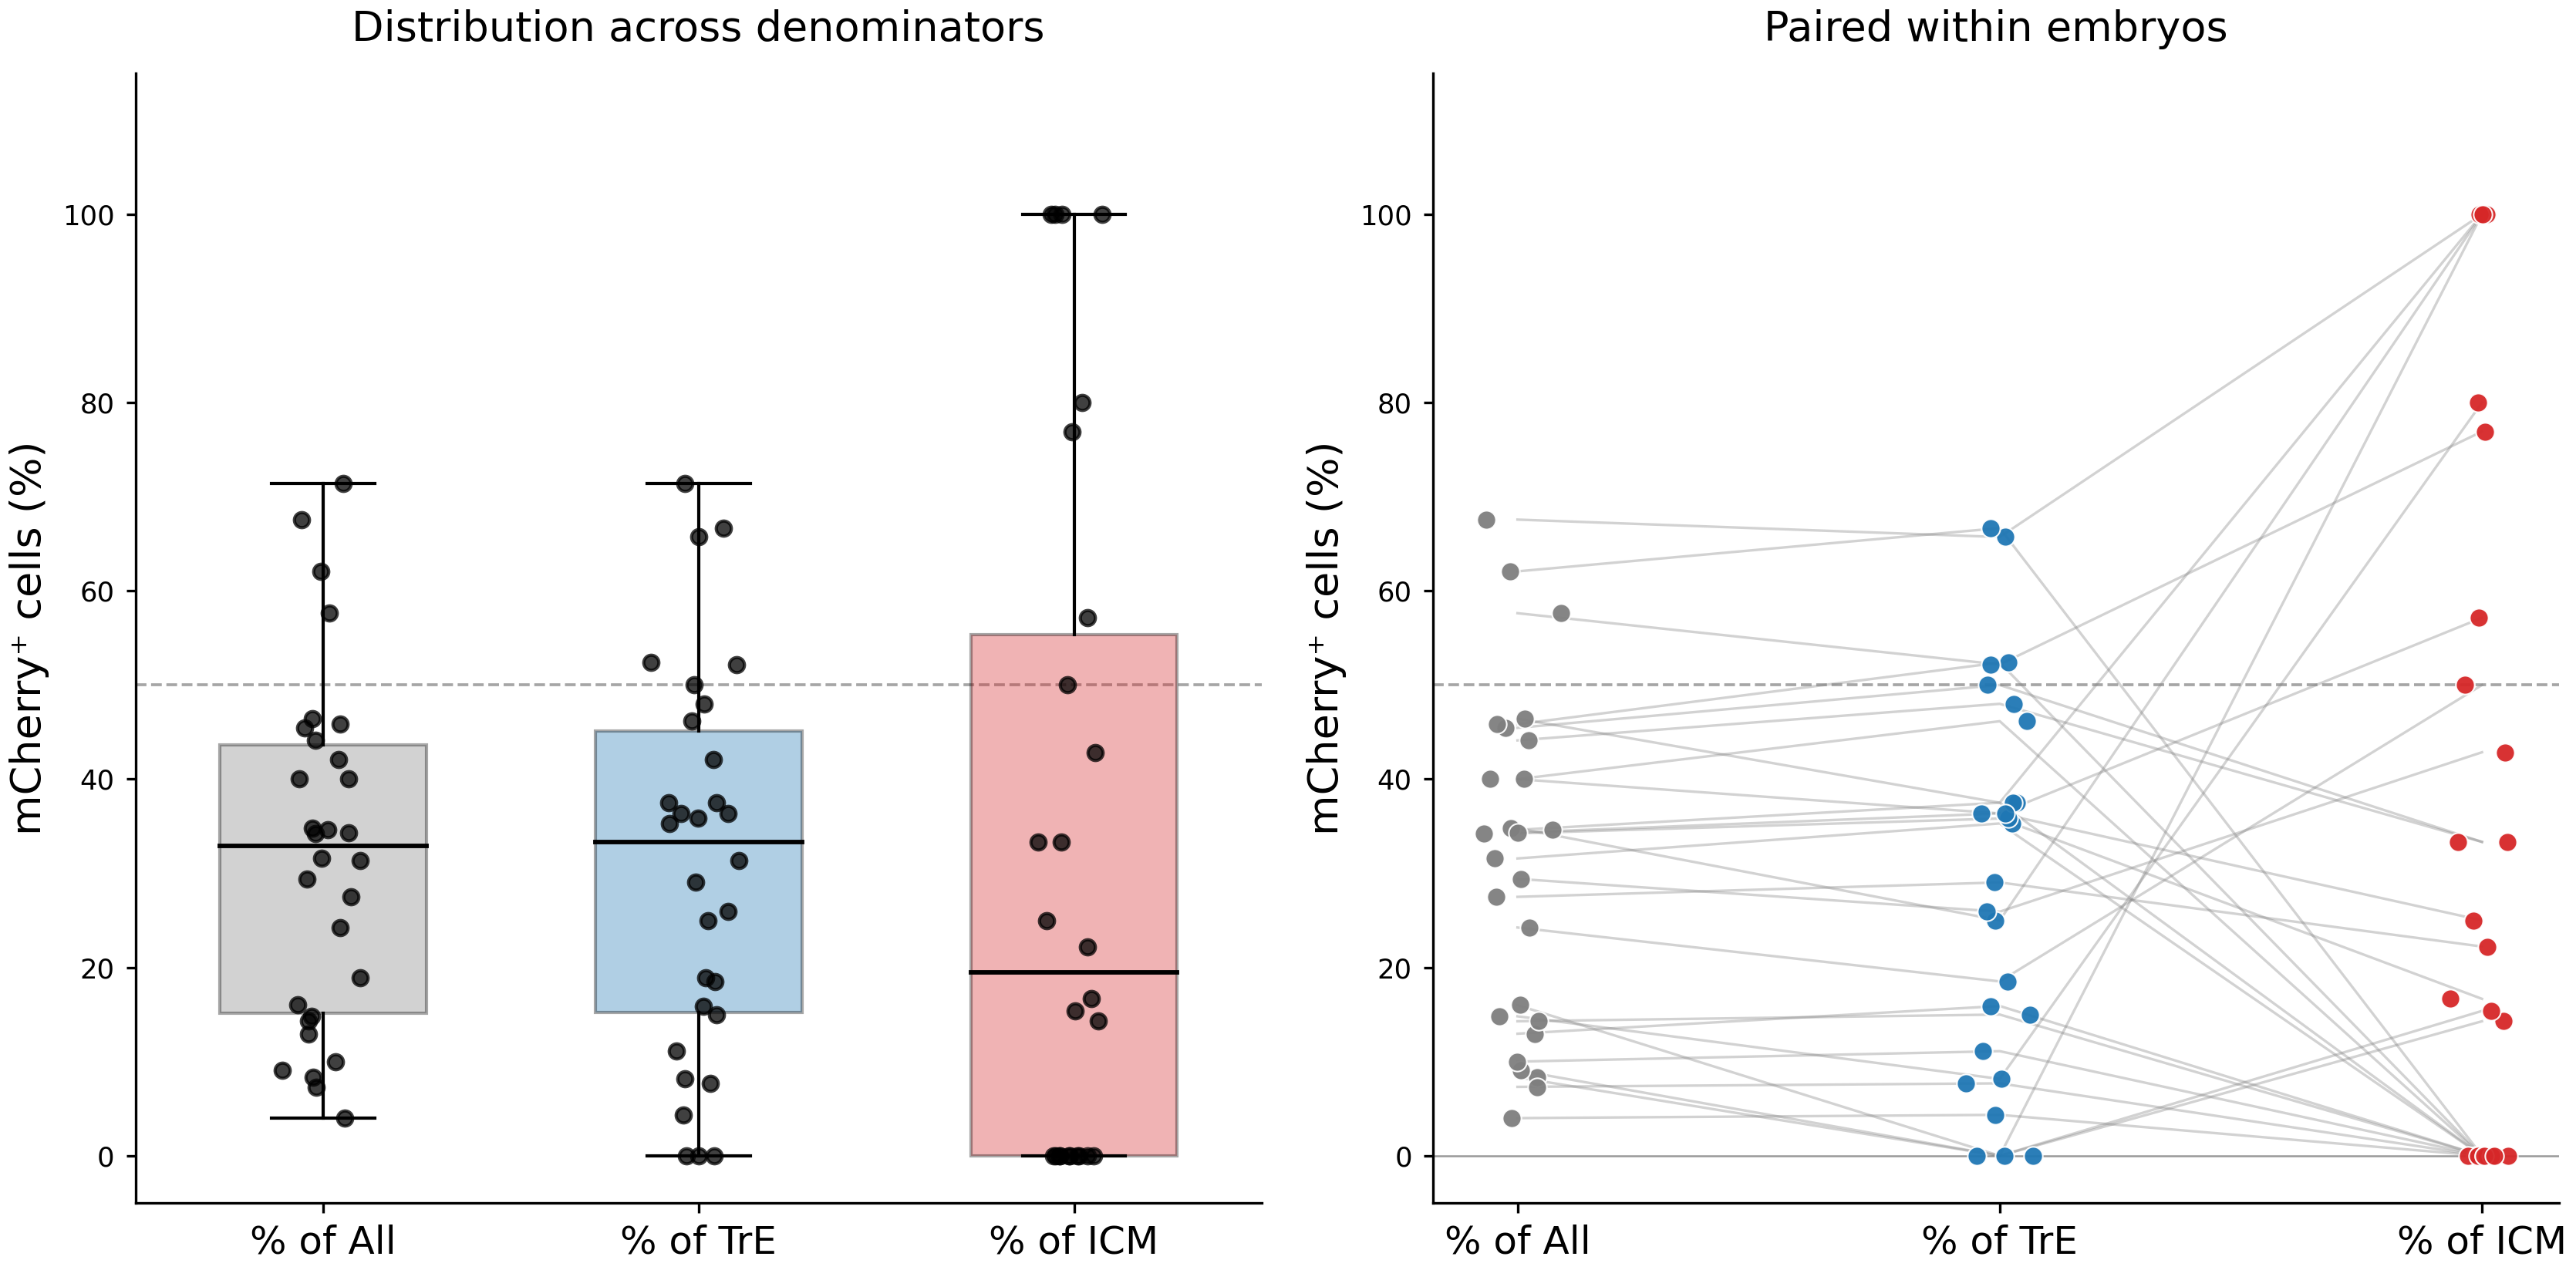


Figure saved: WT_mCherry_pos_All_TrE_ICM.svg / .pdf


In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ============================================================
# 1. Matplotlib settings
# ============================================================
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 13,
    'axes.titlesize': 14,
    'axes.labelsize': 13,
    'svg.fonttype': 'none',
    'svg.hashsalt': 'hello'
})

np.random.seed(123)

# ============================================================
# 2. Read data (WT only)
# ============================================================
df = pd.read_csv("red_icm_te_count.txt", sep="\t")
df = df[df["treatment"].astype(str).str.strip() == "WT"].copy()

required_cols = ["编号", "mCherry-ICM", "mCherry-TE", "SOX2", "GATA3"]
for col in required_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=required_cols).copy()

# ============================================================
# 3. Calculate three mCherry+ percentages
# ============================================================
total_cells = df["SOX2"] + df["GATA3"]
cherry_total = df["mCherry-ICM"] + df["mCherry-TE"]

df["pct_of_All"] = np.where(
    total_cells > 0, cherry_total / total_cells * 100, np.nan
)
df["pct_of_TrE"] = np.where(
    df["GATA3"] > 0, df["mCherry-TE"] / df["GATA3"] * 100, np.nan
)
df["pct_of_ICM"] = np.where(
    df["SOX2"] > 0, df["mCherry-ICM"] / df["SOX2"] * 100, np.nan
)

# ============================================================
# 4. Export per-embryo results
# ============================================================
output_cols = [
    "编号",
    "SOX2", "GATA3", "mCherry-ICM", "mCherry-TE",
    "pct_of_All", "pct_of_TrE", "pct_of_ICM"
]
result = df[output_cols].copy()
result.to_csv(
    "WT_mCherry_pos_three_percentages.txt",
    sep="\t", index=False, float_format="%.4f"
)
print("\nPer-embryo mCherry+ percentages:")
print(result.to_string(index=False, float_format="%.2f"))

# ============================================================
# 5. Plot: left = 3 boxplots, right = paired line plot
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.8))

positions = [1, 2, 3]
labels    = ["% of All", "% of TrE", "% of ICM"]
colors    = ["#7F7F7F", "#1F77B4", "#D62728"]

# Use same embryos across all three metrics for the line plot
valid = df[["pct_of_All", "pct_of_TrE", "pct_of_ICM"]].notna().all(axis=1)
plot_df = df.loc[valid].copy()
print(f"\nEmbryos with all three metrics: {len(plot_df)}")

# ---------- Left panel: 3 boxplots --------------------------
ax = axes[0]

box_data = [
    df["pct_of_All"].dropna().values,
    df["pct_of_TrE"].dropna().values,
    df["pct_of_ICM"].dropna().values,
]

bp = ax.boxplot(
    box_data,
    positions=positions,
    widths=0.55,
    patch_artist=True,
    showfliers=False,   # we'll draw our own scatter
    medianprops=dict(color="black", linewidth=1.4),
    whiskerprops=dict(color="black", linewidth=1.0),
    capprops=dict(color="black", linewidth=1.0),
    boxprops=dict(linewidth=1.0)
)

for patch, col in zip(bp["boxes"], colors):
    patch.set_facecolor(col)
    patch.set_alpha(0.35)
    patch.set_edgecolor("black")

# Scatter points on top of boxplots
for i, values in enumerate(box_data):
    if len(values) == 0:
        continue
    x = np.random.normal(positions[i], 0.045, size=len(values))
    x = np.clip(x, positions[i] - 0.14, positions[i] + 0.14)
    ax.scatter(
        x, values,
        color="black", alpha=0.75, s=22, zorder=3
    )

# Reference lines
ax.axhline(50, linestyle="--", linewidth=0.9,
           color="grey", alpha=0.7, zorder=1)

ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=12)
ax.set_ylabel("mCherry⁺ cells (%)", fontsize=13)
ax.set_title("Distribution across denominators", pad=10, fontsize=13)
ax.set_ylim(-5, 115)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ---------- Right panel: paired line plot -------------------
ax = axes[1]

# Paired lines: one line per embryo across the 3 metrics
for _, row in plot_df.iterrows():
    vals = [row["pct_of_All"], row["pct_of_TrE"], row["pct_of_ICM"]]
    ax.plot(
        positions, vals,
        color="grey", alpha=0.35,
        linewidth=0.8, zorder=1
    )

# Scatter points per metric
for i, (col, colr) in enumerate(
    zip(["pct_of_All", "pct_of_TrE", "pct_of_ICM"], colors)
):
    vals = plot_df[col].values
    x = np.random.normal(positions[i], 0.035, size=len(vals))
    x = np.clip(x, positions[i] - 0.12, positions[i] + 0.12)
    ax.scatter(
        x, vals,
        color=colr, edgecolor="white",
        linewidth=0.5, alpha=0.95, s=34, zorder=3
    )

# Reference lines
ax.axhline(50, linestyle="--", linewidth=0.9,
           color="grey", alpha=0.7, zorder=0)
ax.axhline(0, linestyle="-", linewidth=0.6,
           color="black", alpha=0.4, zorder=0)

ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=12)
ax.set_ylabel("mCherry⁺ cells (%)", fontsize=13)
ax.set_title("Paired within embryos", pad=10, fontsize=13)
ax.set_ylim(-5, 115)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "WT_mCherry_pos_All_TrE_ICM.svg",
    bbox_inches="tight", transparent=True
)
plt.savefig(
    "WT_mCherry_pos_All_TrE_ICM.pdf",
    bbox_inches="tight", transparent=True
)
plt.show()

print("\nFigure saved: WT_mCherry_pos_All_TrE_ICM.svg / .pdf")


Per-embryo mCherry+ percentages:
 编号  SOX2  GATA3  mCherry-ICM  mCherry-TE  pct_of_All  pct_of_TrE  pct_of_ICM
  1     6     16            2           8       45.45       50.00       33.33
  2     3     21            0          11       45.83       52.38        0.00
  3     2     24            0           9       34.62       37.50        0.00
  4     4     21            4           0       16.00        0.00      100.00
  5     7      5            1           0        8.33        0.00       14.29
  6     9     31            2           9       27.50       29.03       22.22
  7    13      9            2           0        9.09        0.00       15.38
  8     2     39            0           3        7.32        7.69        0.00
  9     2     23            0           1        4.00        4.35        0.00
 10    10     44            0           7       12.96       15.91        0.00
 11     5     49            4           4       14.81        8.16       80.00
 12     4     34            0 

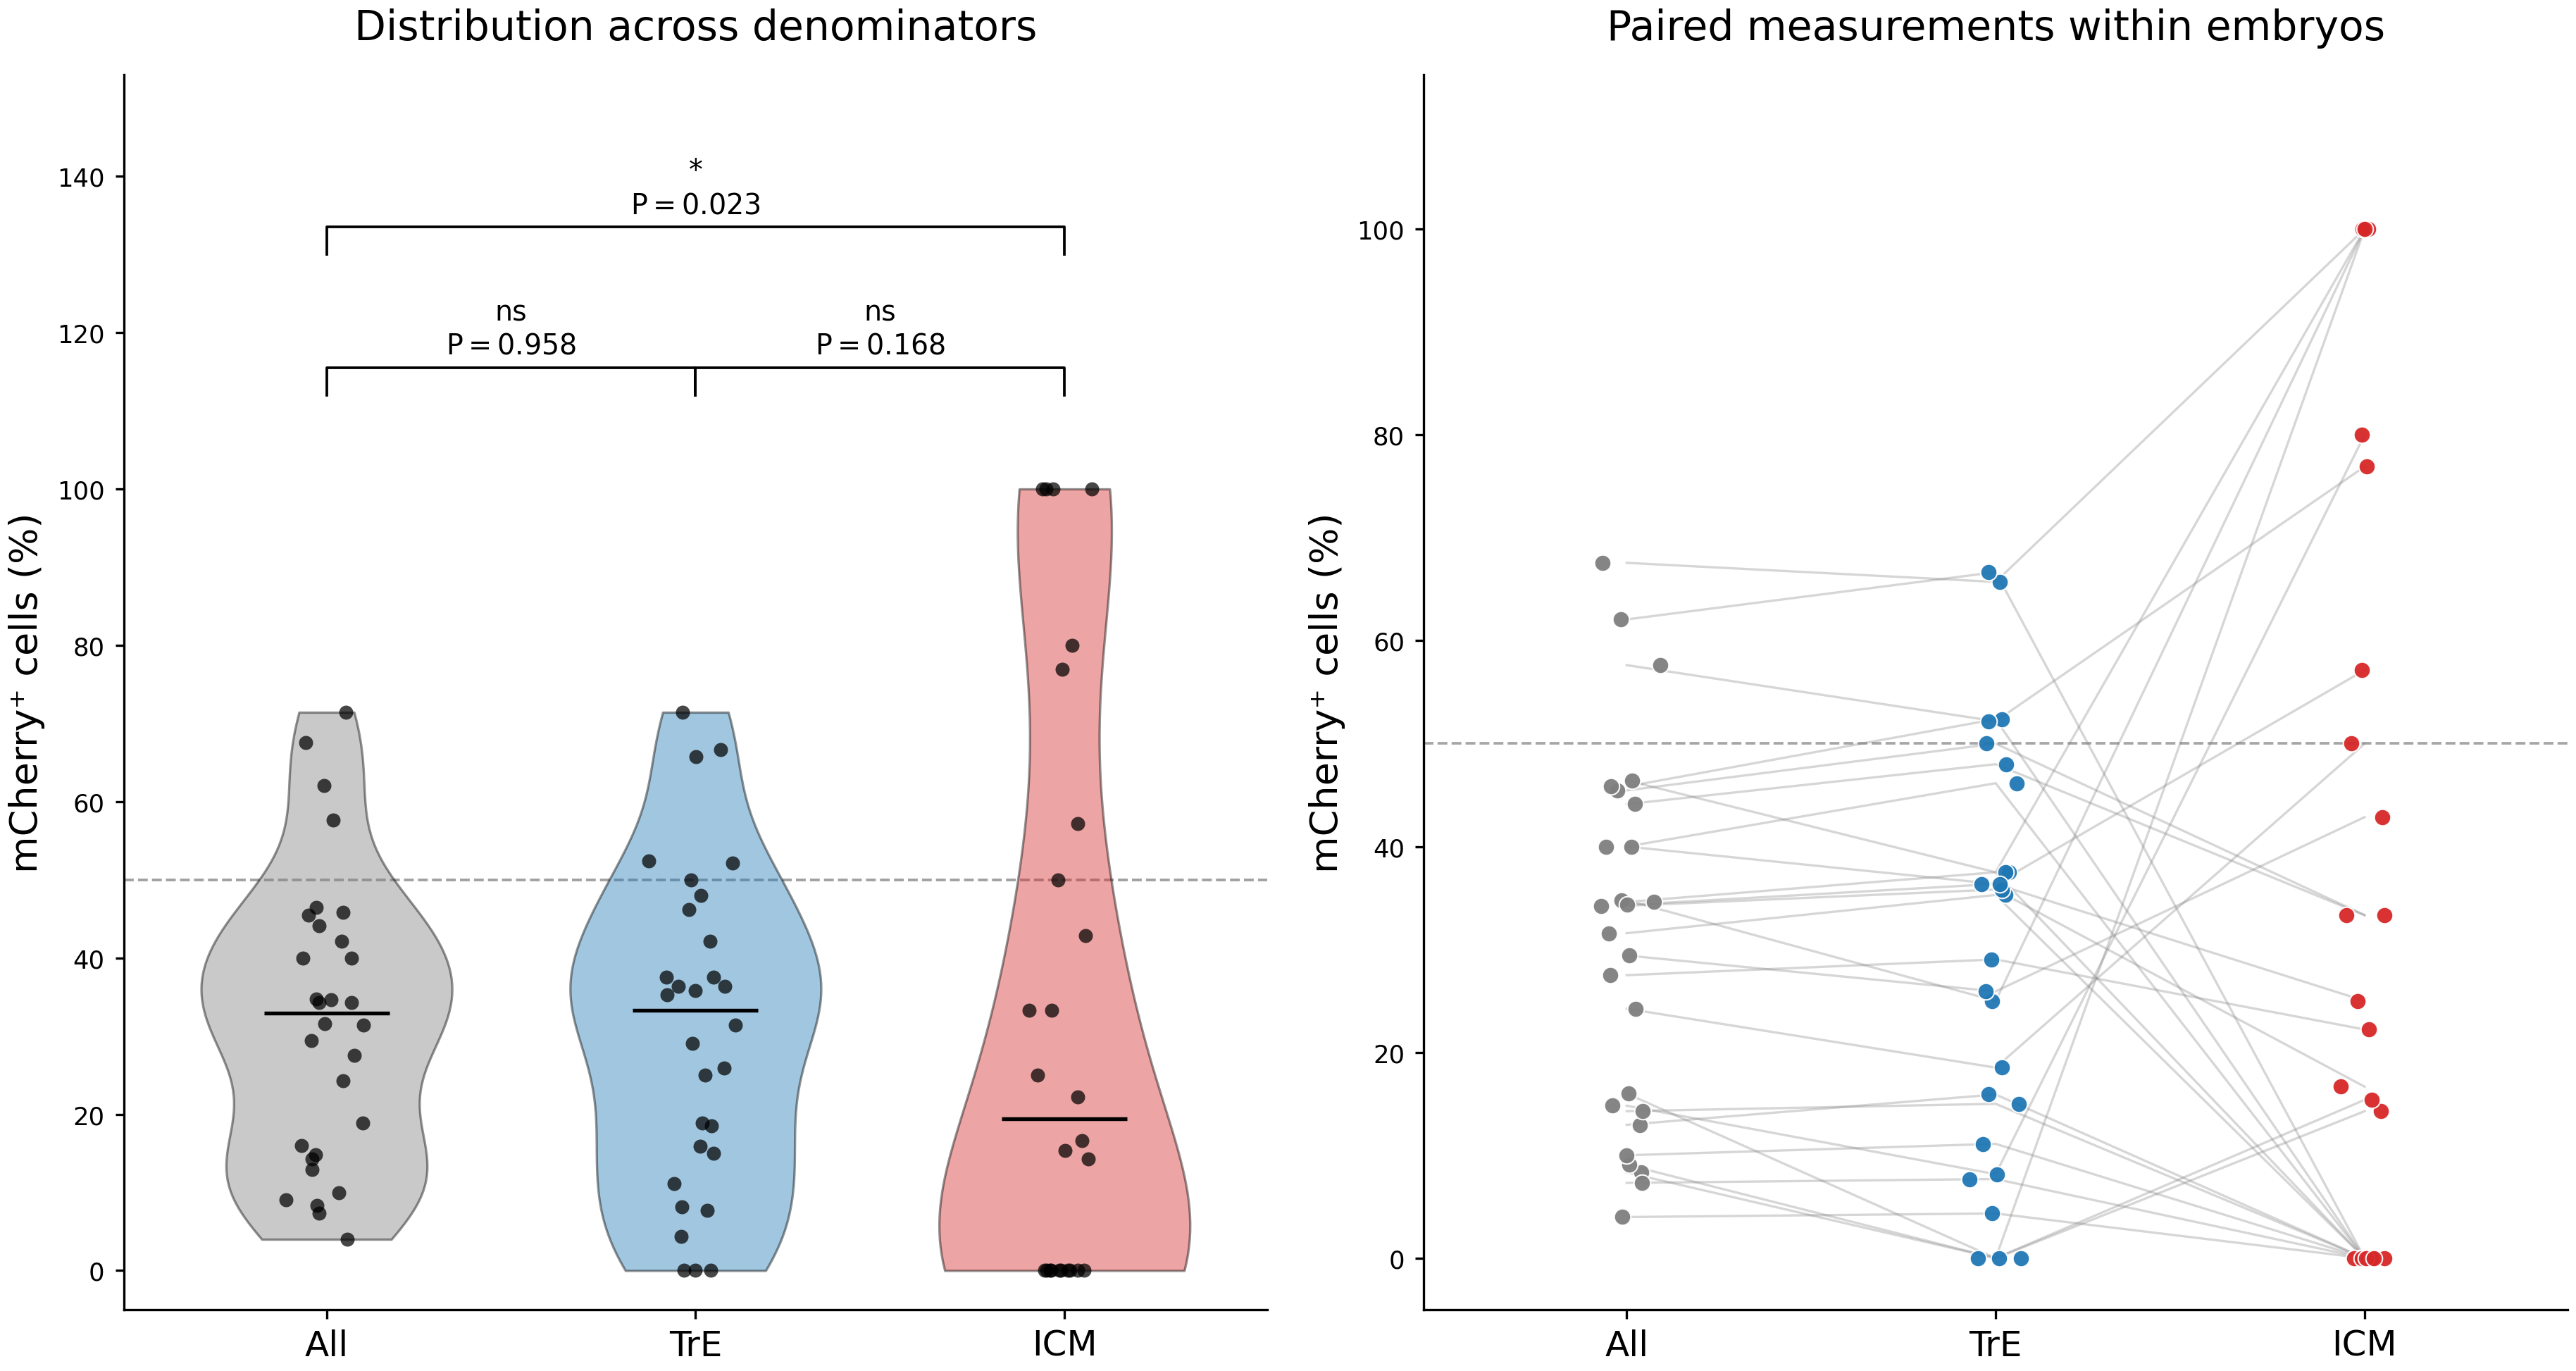


Files saved:
  WT_mCherry_pos_All_TrE_ICM_violin_KS.svg
  WT_mCherry_pos_All_TrE_ICM_violin_KS.pdf
  WT_mCherry_pos_three_percentages.txt
  WT_mCherry_pos_KS_statistics.txt


In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ============================================================
# 1. Matplotlib settings
# ============================================================
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 13,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "svg.fonttype": "none",
    "svg.hashsalt": "hello",
    "mathtext.fontset": "dejavusans"
})

np.random.seed(123)

# ============================================================
# 2. Read data (WT only)
# ============================================================
df = pd.read_csv("red_icm_te_count.txt", sep="\t")
df = df[df["treatment"].astype(str).str.strip() == "WT"].copy()

required_cols = [
    "编号", "mCherry-ICM", "mCherry-TE", "SOX2", "GATA3"
]

for col in required_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=required_cols).copy()

# ============================================================
# 3. Calculate three mCherry+ percentages
# ============================================================
total_cells = df["SOX2"] + df["GATA3"]
cherry_total = df["mCherry-ICM"] + df["mCherry-TE"]

df["pct_of_All"] = np.where(
    total_cells > 0,
    cherry_total / total_cells * 100,
    np.nan
)

df["pct_of_TrE"] = np.where(
    df["GATA3"] > 0,
    df["mCherry-TE"] / df["GATA3"] * 100,
    np.nan
)

df["pct_of_ICM"] = np.where(
    df["SOX2"] > 0,
    df["mCherry-ICM"] / df["SOX2"] * 100,
    np.nan
)

# ============================================================
# 4. Export per-embryo results
# ============================================================
output_cols = [
    "编号",
    "SOX2", "GATA3",
    "mCherry-ICM", "mCherry-TE",
    "pct_of_All", "pct_of_TrE", "pct_of_ICM"
]

result = df[output_cols].copy()

result.to_csv(
    "WT_mCherry_pos_three_percentages.txt",
    sep="\t",
    index=False,
    float_format="%.4f"
)

print("\nPer-embryo mCherry+ percentages:")
print(result.to_string(index=False, float_format="%.2f"))

# ============================================================
# 5. Prepare plotting data
# ============================================================
metrics = ["pct_of_All", "pct_of_TrE", "pct_of_ICM"]
labels = ["All", "TrE", "ICM"]
colors = ["#7F7F7F", "#1F77B4", "#D62728"]
positions = [1, 2, 3]

box_data = [
    df[col].dropna().to_numpy()
    for col in metrics
]

# Same embryos with valid values for all three metrics
plot_df = df.dropna(subset=metrics).copy()

print(f"\nTotal WT embryos: {len(df)}")
print(f"Embryos with all three metrics: {len(plot_df)}")

# ============================================================
# 6. Two-sided KS tests: original P values only
# ============================================================
comparisons = [
    (0, 1),  # All vs TrE
    (0, 2),  # All vs ICM
    (1, 2)   # TrE vs ICM
]

test_results = []

print("\n" + "=" * 65)
print("Two-sided Kolmogorov-Smirnov tests")
print("P values shown are unadjusted")
print("=" * 65)

for i, j in comparisons:
    a = box_data[i]
    b = box_data[j]

    if len(a) > 0 and len(b) > 0:
        ks_stat, p_value = stats.ks_2samp(
            a,
            b,
            alternative="two-sided",
            method="auto"
        )
    else:
        ks_stat, p_value = np.nan, np.nan

    test_results.append({
        "Comparison": f"{labels[i]} vs {labels[j]}",
        "KS_statistic": ks_stat,
        "P_raw": p_value
    })

stats_df = pd.DataFrame(test_results)

for _, row in stats_df.iterrows():
    print(
        f'{row["Comparison"]:15s} '
        f'D = {row["KS_statistic"]:.4f}, '
        f'P = {row["P_raw"]:.8g}'
    )

stats_df.to_csv(
    "WT_mCherry_pos_KS_statistics.txt",
    sep="\t",
    index=False,
    float_format="%.8g"
)

# ============================================================
# 7. Format exact P values using superscript exponents
# ============================================================
def fmt_p_math(p):
    """Format P values using proper mathematical superscripts."""
    if not np.isfinite(p):
        return r"$P = \mathrm{NA}$"

    if p <= 0:
        return r"$P < 10^{-300}$"

    if p >= 0.001:
        return rf"$P = {p:.3f}$"

    exponent = int(np.floor(np.log10(p)))
    coefficient = p / (10.0 ** exponent)

    return (
        rf"$P = {coefficient:.2f}"
        rf" \times 10^{{{exponent}}}$"
    )


def get_stars(p):
    """Significance symbols based on the original P value."""
    if not np.isfinite(p):
        return "NA"
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "ns"


# ============================================================
# 8. Significance bracket helper
# ============================================================
def add_sig_bracket(ax, x1, x2, y, height, p):
    """
    Draw a significance bracket.
    Both significance stars and P-value annotation use raw P.
    """
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + height, y + height, y],
        color="black",
        linewidth=0.9,
        clip_on=False
    )

    annotation = f"{get_stars(p)}\n{fmt_p_math(p)}"

    ax.text(
        (x1 + x2) / 2,
        y + height + 1.0,
        annotation,
        ha="center",
        va="bottom",
        fontsize=9.5,
        linespacing=1.25
    )


# ============================================================
# 9. Create figure
# ============================================================
fig, axes = plt.subplots(
    1, 2,
    figsize=(12.5, 6.8),
    gridspec_kw={"width_ratios": [1, 1]}
)

# ============================================================
# 10. Left panel: violin plots
# ============================================================
ax = axes[0]

vp = ax.violinplot(
    box_data,
    positions=positions,
    widths=0.68,
    showmeans=False,
    showmedians=True,
    showextrema=False,
    bw_method=0.4
)

# Violin styling
for body, col in zip(vp["bodies"], colors):
    body.set_facecolor(col)
    body.set_edgecolor("black")
    body.set_alpha(0.42)
    body.set_linewidth(0.8)

vp["cmedians"].set_color("black")
vp["cmedians"].set_linewidth(1.3)

# Individual embryo points
for i, values in enumerate(box_data):
    if len(values) == 0:
        continue

    x = np.random.normal(
        positions[i],
        0.045,
        size=len(values)
    )

    x = np.clip(
        x,
        positions[i] - 0.17,
        positions[i] + 0.17
    )

    ax.scatter(
        x,
        values,
        s=23,
        color="black",
        alpha=0.72,
        linewidths=0,
        zorder=3
    )

# Reference line at 50%
ax.axhline(
    50,
    linestyle="--",
    linewidth=0.9,
    color="grey",
    alpha=0.75,
    zorder=0
)

ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=12)
ax.set_ylabel("mCherry⁺ cells (%)", fontsize=13)
ax.set_title("Distribution across denominators", pad=12)

# Space for significance brackets
ax.set_ylim(-5, 153)
ax.set_xlim(0.45, 3.55)

# Pairwise comparisons and bracket heights
bracket_specs = [
    (1, 2, 112),  # All vs TrE
    (1, 3, 130),  # All vs ICM
    (2, 3, 112)   # TrE vs ICM
]

# IMPORTANT: use P_raw, not P_adj
for (x1, x2, y), (_, row) in zip(
    bracket_specs,
    stats_df.iterrows()
):
    add_sig_bracket(
        ax,
        x1,
        x2,
        y=y,
        height=3.5,
        p=row["P_raw"]
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ============================================================
# 11. Right panel: paired line plot
# ============================================================
ax = axes[1]

# Connect measurements from the same embryo
for _, row in plot_df.iterrows():
    vals = [row[col] for col in metrics]

    ax.plot(
        positions,
        vals,
        color="grey",
        alpha=0.32,
        linewidth=0.8,
        zorder=1
    )

# Scatter points for each metric
for i, (col, colr) in enumerate(zip(metrics, colors)):
    vals = plot_df[col].to_numpy()

    x = np.random.normal(
        positions[i],
        0.035,
        size=len(vals)
    )

    x = np.clip(
        x,
        positions[i] - 0.12,
        positions[i] + 0.12
    )

    ax.scatter(
        x,
        vals,
        color=colr,
        edgecolor="white",
        linewidth=0.5,
        alpha=0.95,
        s=32,
        zorder=3
    )

# Reference line at 50%
ax.axhline(
    50,
    linestyle="--",
    linewidth=0.9,
    color="grey",
    alpha=0.7,
    zorder=0
)

ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=12)
ax.set_ylabel("mCherry⁺ cells (%)", fontsize=13)
ax.set_title("Paired measurements within embryos", pad=12)
ax.set_ylim(-5, 115)
ax.set_xlim(0.45, 3.55)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ============================================================
# 12. Save figures
# ============================================================
plt.tight_layout()

plt.savefig(
    "WT_mCherry_pos_All_TrE_ICM_violin_KS.svg",
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    "WT_mCherry_pos_All_TrE_ICM_violin_KS.pdf",
    bbox_inches="tight",
    transparent=True
)

plt.show()

# ============================================================
# 13. Output summary
# ============================================================
print("\nFiles saved:")
print("  WT_mCherry_pos_All_TrE_ICM_violin_KS.svg")
print("  WT_mCherry_pos_All_TrE_ICM_violin_KS.pdf")
print("  WT_mCherry_pos_three_percentages.txt")
print("  WT_mCherry_pos_KS_statistics.txt")

Number of WT embryos before filtering: 30
Embryos with SOX2 = 0 removed: 4
Number of WT embryos after filtering: 26 (removed 4)
[ICM | Whole embryo] done (Silverman: 0.7s)
[ICM | mCherry+] done (Silverman: 0.6s)
[TrE | Whole embryo] done (Silverman: 1.0s)
[TrE | mCherry+] done (Silverman: 0.6s)

DISTRIBUTION SHAPE: DIP TEST, SILVERMAN TEST, GMM

ICM | Whole embryo | n=26
  Mean proportion: 0.1743
  Median (Q1-Q3): 0.1381 (0.0848-0.2007)
  Hartigan dip: stat=0.05487, P=0.80413, BH q=0.80413
  Silverman k=1: h_crit=0.86148, P=0.019802
  Silverman k=2: h_crit=0.19279, P=0.77228
  GMM BIC: 1comp=-23.873; 2comp=-48.771
  Preferred by BIC: 2 components

ICM | mCherry+ | n=26
  Mean proportion: 0.2398
  Median (Q1-Q3): 0.1561 (0.0000-0.3058)
  Hartigan dip: stat=0.05769, P=0.72714, BH q=0.80413
  Silverman k=1: h_crit=0.72937, P=0.009901
  Silverman k=2: h_crit=0.14928, P=0.64356
  GMM BIC: 1comp=19.500; 2comp=-21.714
  Preferred by BIC: 2 components

TrE | Whole embryo | n=26
  Mean proporti

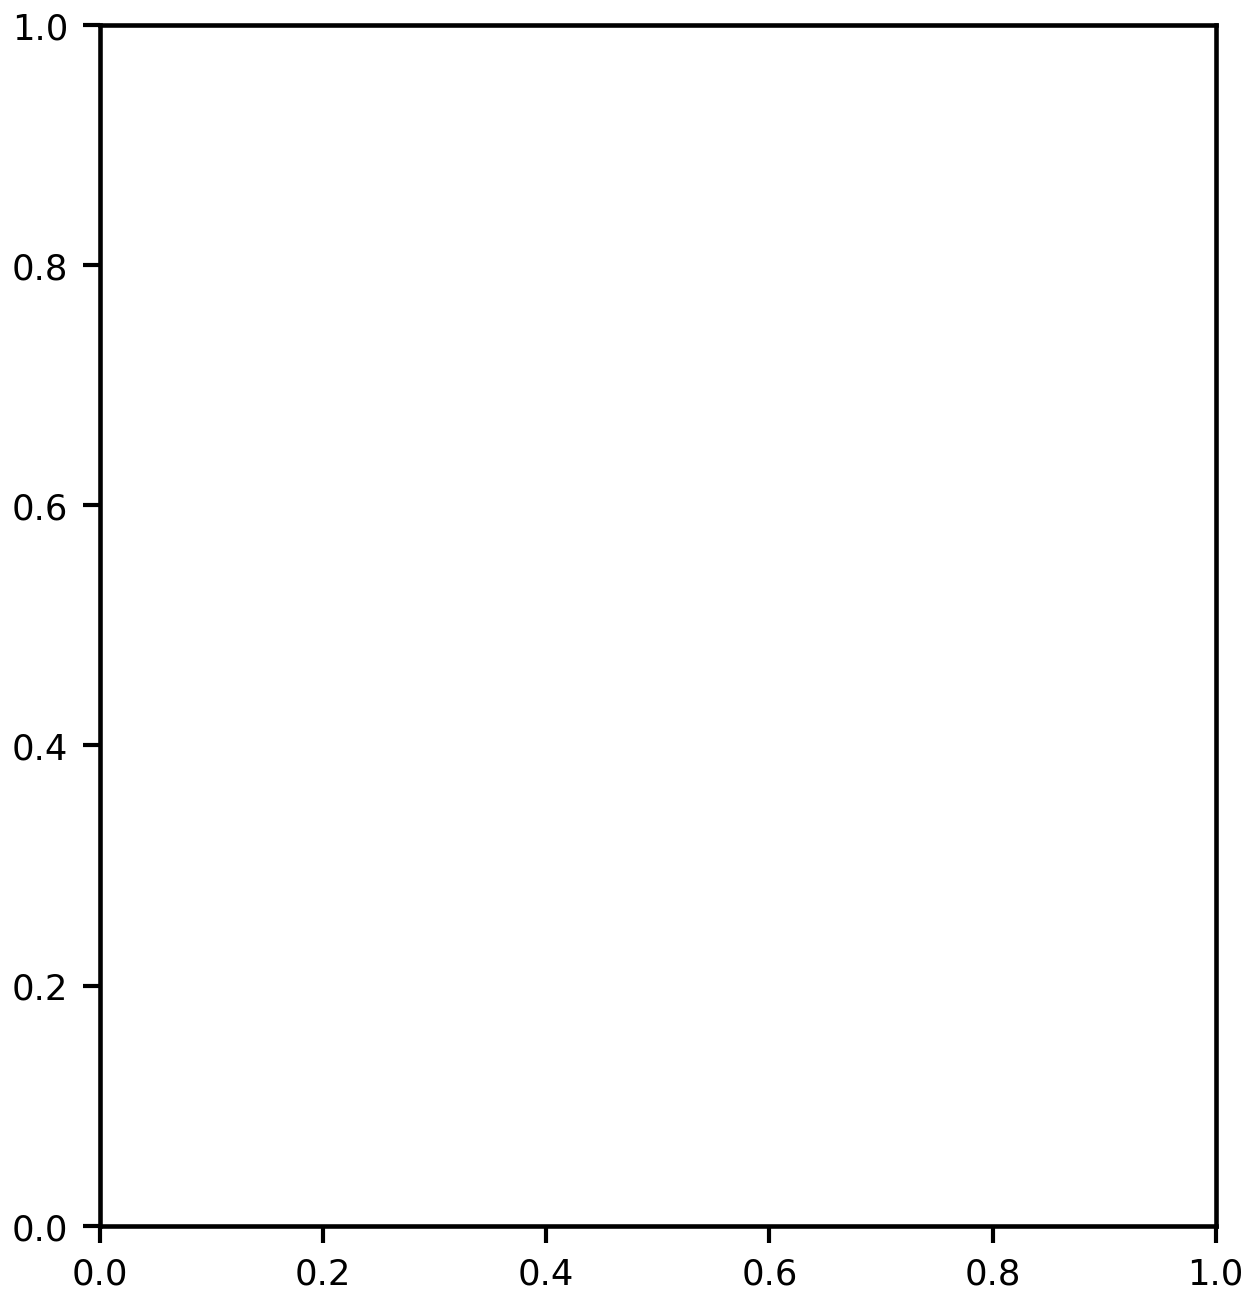

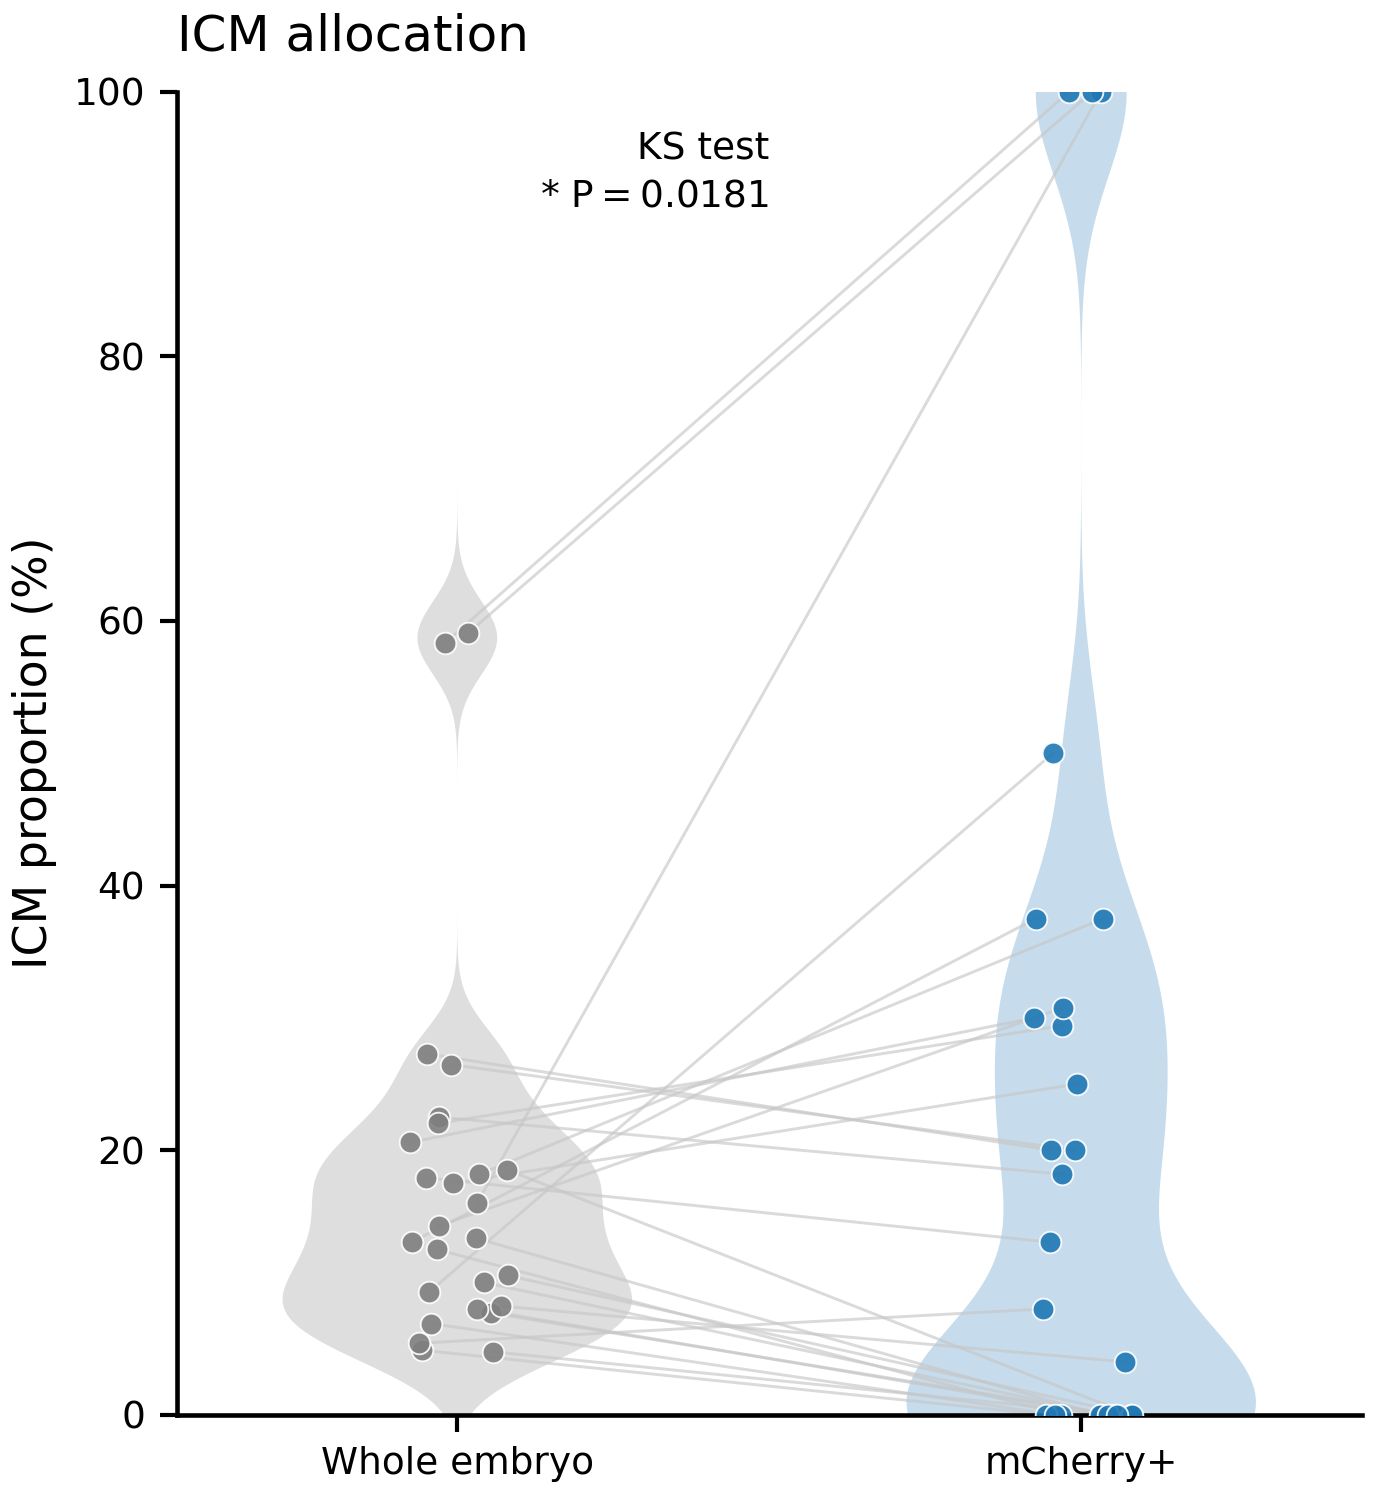

In [79]:

# ============================================================
# WT embryo lineage allocation
# Actual vs mCherry+
#
# Analysis:
#   - Remove embryos with SOX2 = 0
#   - Hartigan dip test
#   - Silverman critical-bandwidth tests
#   - GMM model comparison
#   - KDE peak-count sensitivity analysis
#   - Paired distribution permutation test
#   - Paired mean-difference sign-flip test
#   - Two-sample KS test (raw P values)
#
# Plot:
#   - ICM only: Actual vs mCherry+
#   - KDE violins, bw_method = 0.2
#   - Paired embryo lines and individual points
#   - KS statistic, raw P value and significance
#
# Outputs:
#   - Statistical result TXT files
#   - ICM-only SVG and PDF figures
# ============================================================

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import (
    gaussian_kde,
    ks_2samp,
)
from scipy.signal import find_peaks
from sklearn.mixture import GaussianMixture

try:
    from diptest import diptest
except ImportError:
    raise ImportError("Install diptest: pip install diptest")


# ============================================================
# 0. Parameters
# ============================================================

input_file = "red_icm_te_count.txt"

RANDOM_SEED = 12345
N_PERMUTATIONS = 20000

N_SILVERMAN_BOOTSTRAP = 100
SILVERMAN_GRIDSIZE = 300
SILVERMAN_GRID = np.linspace(0.0, 1.0, SILVERMAN_GRIDSIZE)
SILVERMAN_MAX_ITER = 20

KDE_BANDWIDTHS = [0.1, 0.2, 0.3, 0.5]
KDE_GRIDSIZE = 1000
PEAK_PROMINENCE_FRACTION = 0.05

GMM_N_INIT = 20

rng = np.random.default_rng(RANDOM_SEED)
t_start = time.time()


# ============================================================
# 1. Plot settings
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "svg.hashsalt": "hello",
    "axes.linewidth": 1.1,
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "mathtext.fontset": "dejavusans",
})


# ============================================================
# 2. Read and validate input
# ============================================================

df = pd.read_csv(input_file, sep="\t")

required_cols = [
    "treatment", "编号",
    "mCherry-ICM", "mCherry-TE",
    "SOX2", "GATA3"
]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

df = df[
    df["treatment"].astype(str).str.strip().str.upper() == "WT"
].copy().reset_index(drop=True)

if len(df) == 0:
    raise ValueError("No WT embryos found.")

print(f"Number of WT embryos before filtering: {len(df)}")

count_cols = ["mCherry-ICM", "mCherry-TE", "SOX2", "GATA3"]

for col in count_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if df[count_cols].isna().any().any():
    raise ValueError("Missing or non-numeric cell counts detected.")

if (df[count_cols] < 0).any().any():
    raise ValueError("Negative cell counts detected.")

for col in count_cols:
    if not np.allclose(df[col], np.round(df[col])):
        raise ValueError(f"Non-integer counts detected in {col}")
    df[col] = df[col].astype(int)


# ============================================================
# 2b. Remove embryos with SOX2 = 0
# ============================================================

n_before = len(df)
sox2_zero_mask = df["SOX2"] == 0

print(
    f"Embryos with SOX2 = 0 removed: "
    f"{int(sox2_zero_mask.sum())}"
)

df = df[~sox2_zero_mask].copy().reset_index(drop=True)

print(
    f"Number of WT embryos after filtering: {len(df)} "
    f"(removed {n_before - len(df)})"
)

if len(df) == 0:
    raise ValueError("No embryos left after filtering.")


# ============================================================
# 3. Calculate lineage proportions
# ============================================================

df["actual_total"] = df["SOX2"] + df["GATA3"]
df["mCherry_pos_total"] = df["mCherry-ICM"] + df["mCherry-TE"]

df["actual_ICM_prop"] = np.where(
    df["actual_total"] > 0,
    df["SOX2"] / df["actual_total"],
    np.nan
)

df["actual_TrE_prop"] = np.where(
    df["actual_total"] > 0,
    df["GATA3"] / df["actual_total"],
    np.nan
)

df["mCherry_pos_ICM_prop"] = np.where(
    df["mCherry_pos_total"] > 0,
    df["mCherry-ICM"] / df["mCherry_pos_total"],
    np.nan
)

df["mCherry_pos_TrE_prop"] = np.where(
    df["mCherry_pos_total"] > 0,
    df["mCherry-TE"] / df["mCherry_pos_total"],
    np.nan
)


# ============================================================
# 4. BH correction helper (used for dip-test results only)
# ============================================================

def bh_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(p_values.shape, np.nan)

    valid_idx = np.where(np.isfinite(p_values))[0]
    if len(valid_idx) == 0:
        return adjusted

    p = p_values[valid_idx]
    order = np.argsort(p)
    sorted_p = p[order]
    m = len(sorted_p)

    sorted_q = sorted_p * m / np.arange(1, m + 1)
    sorted_q = np.minimum.accumulate(sorted_q[::-1])[::-1]
    sorted_q = np.clip(sorted_q, 0, 1)

    q_orig = np.empty(m)
    q_orig[order] = sorted_q
    adjusted[valid_idx] = q_orig

    return adjusted


# ============================================================
# 5. Hartigan dip test
# ============================================================

def run_dip_test(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "dip_statistic": np.nan,
        "dip_pvalue": np.nan
    }

    if len(x) >= 3 and np.unique(x).size >= 2:
        dip_stat, p_value = diptest(x)
        result["dip_statistic"] = float(dip_stat)
        result["dip_pvalue"] = float(p_value)

    return result


# ============================================================
# 6. Silverman critical-bandwidth test
# ============================================================

def _count_modes_fast(grid_minus_x, sd, h):
    bw = h * sd
    if bw <= 0:
        return 0

    z = grid_minus_x / bw
    density = np.exp(-0.5 * z * z).sum(axis=1)
    peaks, _ = find_peaks(density)

    return len(peaks)


def silverman_critical_bandwidth(
    x,
    k=1,
    grid=SILVERMAN_GRID,
    max_iter=SILVERMAN_MAX_ITER
):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)

    if n < 3 or np.unique(x).size < 3:
        return np.nan

    sd = float(np.std(x, ddof=1))
    if sd <= 0:
        return np.nan

    grid_minus_x = grid[:, None] - x[None, :]

    lo, hi = 1e-5, 5.0

    if _count_modes_fast(grid_minus_x, sd, hi) > k:
        return np.nan

    for _ in range(max_iter):
        mid = 0.5 * (lo + hi)

        if _count_modes_fast(grid_minus_x, sd, mid) <= k:
            hi = mid
        else:
            lo = mid

        if hi - lo < 1e-5:
            break

    return hi


def silverman_test(
    x,
    k=1,
    n_boot=N_SILVERMAN_BOOTSTRAP,
    grid=SILVERMAN_GRID
):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)

    result = {
        "k_null": k,
        "h_crit": np.nan,
        "silverman_pvalue": np.nan
    }

    if n < 10 or np.unique(x).size < 3:
        return result

    h_crit = silverman_critical_bandwidth(x, k=k, grid=grid)

    if not np.isfinite(h_crit):
        return result

    result["h_crit"] = float(h_crit)

    sd_x = float(np.std(x, ddof=1))
    if sd_x <= 0:
        return result

    idx = rng.integers(0, n, size=(n_boot, n))
    noise = rng.normal(0.0, h_crit * sd_x, size=(n_boot, n))
    boot = x[idx] + noise

    exceed = 0

    for b in range(n_boot):
        h_b = silverman_critical_bandwidth(
            boot[b], k=k, grid=grid
        )

        if np.isfinite(h_b) and h_b > h_crit:
            exceed += 1

    result["silverman_pvalue"] = (
        exceed + 1
    ) / (n_boot + 1)

    return result


# ============================================================
# 7. GMM comparison
# ============================================================

def run_gmm_comparison(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "BIC_1_component": np.nan,
        "BIC_2_components": np.nan,
        "delta_BIC_1_minus_2": np.nan,
        "preferred_by_BIC": "NA",
        "GMM_2_component_means": "NA",
        "GMM_2_component_weights": "NA",
    }

    if len(x) < 5 or np.unique(x).size < 2:
        return result

    X = x.reshape(-1, 1)

    try:
        model1 = GaussianMixture(
            n_components=1,
            covariance_type="full",
            n_init=GMM_N_INIT,
            random_state=RANDOM_SEED,
            reg_covar=1e-6,
        )

        model2 = GaussianMixture(
            n_components=2,
            covariance_type="full",
            n_init=GMM_N_INIT,
            random_state=RANDOM_SEED,
            reg_covar=1e-6,
        )

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model1.fit(X)
            model2.fit(X)

        bic1 = float(model1.bic(X))
        bic2 = float(model2.bic(X))

        result["BIC_1_component"] = bic1
        result["BIC_2_components"] = bic2
        result["delta_BIC_1_minus_2"] = bic1 - bic2

        if bic2 < bic1:
            result["preferred_by_BIC"] = "2 components"
        elif bic1 < bic2:
            result["preferred_by_BIC"] = "1 component"
        else:
            result["preferred_by_BIC"] = "Tie"

        result["GMM_2_component_means"] = ",".join(
            f"{v:.6g}" for v in np.sort(model2.means_.ravel())
        )

        result["GMM_2_component_weights"] = ",".join(
            f"{v:.6g}" for v in model2.weights_
        )

    except (ValueError, np.linalg.LinAlgError) as exc:
        print(f"Warning: GMM fitting failed: {exc}")

    return result


# ============================================================
# 8. KDE peak count
# ============================================================

def count_kde_peaks(values, bw_factor):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "bandwidth_factor": bw_factor,
        "n_KDE_peaks": np.nan,
        "peak_locations": "NA",
    }

    if len(x) < 3 or np.unique(x).size < 2:
        return result

    try:
        kde = gaussian_kde(x, bw_method=bw_factor)
        grid = np.linspace(0, 1, KDE_GRIDSIZE)
        density = kde(grid)

        if not np.isfinite(density).all() or density.max() <= 0:
            return result

        prominence = density.max() * PEAK_PROMINENCE_FRACTION
        peak_indices, _ = find_peaks(
            density, prominence=prominence
        )

        result["n_KDE_peaks"] = int(len(peak_indices))
        result["peak_locations"] = ",".join(
            f"{grid[i]:.4f}" for i in peak_indices
        )

    except (ValueError, np.linalg.LinAlgError) as exc:
        print(f"Warning: KDE peak analysis failed: {exc}")

    return result


# ============================================================
# 9. Paired distribution permutation test
# ============================================================

def paired_distribution_permutation(
    actual,
    positive,
    n_permutations=N_PERMUTATIONS
):
    actual = np.asarray(actual, dtype=float)
    positive = np.asarray(positive, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(positive)
    a = actual[valid]
    b = positive[valid]
    n = len(a)

    result = {
        "n_paired": n,
        "Wasserstein_distance": np.nan,
        "distribution_permutation_pvalue": np.nan,
    }

    if n < 2:
        return result

    observed = float(
        np.mean(np.abs(np.sort(a) - np.sort(b)))
    )

    swaps = rng.random((n_permutations, n)) < 0.5
    perm_a = np.where(swaps, b, a)
    perm_b = np.where(swaps, a, b)

    perm_a.sort(axis=1)
    perm_b.sort(axis=1)

    perm_stats = np.mean(
        np.abs(perm_a - perm_b), axis=1
    )

    exceed = int(
        np.sum(perm_stats >= observed - 1e-12)
    )

    result["Wasserstein_distance"] = observed
    result["distribution_permutation_pvalue"] = (
        exceed + 1
    ) / (n_permutations + 1)

    return result


# ============================================================
# 10. Paired mean-difference sign-flip test
# ============================================================

def paired_mean_signflip_test(
    actual,
    positive,
    n_permutations=N_PERMUTATIONS
):
    actual = np.asarray(actual, dtype=float)
    positive = np.asarray(positive, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(positive)
    a = actual[valid]
    b = positive[valid]

    d = b - a
    n = len(d)

    result = {
        "n_paired": n,
        "mean_paired_difference_pp": np.nan,
        "median_paired_difference_pp": np.nan,
        "paired_mean_signflip_pvalue": np.nan,
    }

    if n < 2:
        return result

    observed = abs(np.mean(d))

    signs = rng.choice(
        [-1.0, 1.0],
        size=(n_permutations, n)
    )

    perm_means = np.abs(
        np.mean(signs * d, axis=1)
    )

    p_value = (
        np.sum(perm_means >= observed - 1e-12) + 1
    ) / (n_permutations + 1)

    result["mean_paired_difference_pp"] = float(
        np.mean(d) * 100
    )

    result["median_paired_difference_pp"] = float(
        np.median(d) * 100
    )

    result["paired_mean_signflip_pvalue"] = float(p_value)

    return result


# ============================================================
# 10b. Two-sample KS test
# ============================================================

def ks_test(actual, positive):
    """
    Two-sample KS test on marginal distributions.
    P value is unadjusted.
    """
    actual = np.asarray(actual, dtype=float)
    positive = np.asarray(positive, dtype=float)

    a = actual[np.isfinite(actual)]
    b = positive[np.isfinite(positive)]

    result = {
        "n_KS_a": len(a),
        "n_KS_b": len(b),
        "KS_statistic": np.nan,
        "KS_pvalue": np.nan,
    }

    if len(a) < 2 or len(b) < 2:
        return result

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            stat, p = ks_2samp(
                a, b, alternative="two-sided", method="auto"
            )

        result["KS_statistic"] = float(stat)
        result["KS_pvalue"] = float(p)

    except ValueError as exc:
        print(f"Warning: KS test failed: {exc}")

    return result


# ============================================================
# 11. Run analyses: retain ICM and TrE statistics
# ============================================================

lineage_specs = {
    "ICM": {
        "actual": "actual_ICM_prop",
        "positive": "mCherry_pos_ICM_prop",
    },
    "TrE": {
        "actual": "actual_TrE_prop",
        "positive": "mCherry_pos_TrE_prop",
    },
}

distribution_results = []
gmm_results = []
kde_results = []
comparison_results = []
multimodality_results = []

for lineage, spec in lineage_specs.items():

    for group_name, col in [
        ("Whole embryo", spec["actual"]),
        ("mCherry+", spec["positive"]),
    ]:

        values = df[col].to_numpy(dtype=float)
        values = values[np.isfinite(values)]

        summary = {
            "Lineage": lineage,
            "Group": group_name,
            "n": len(values),
            "Mean_proportion": (
                float(np.mean(values)) if len(values) else np.nan
            ),
            "SD_proportion": (
                float(np.std(values, ddof=1))
                if len(values) > 1 else np.nan
            ),
            "Median_proportion": (
                float(np.median(values)) if len(values) else np.nan
            ),
            "Q1_proportion": (
                float(np.percentile(values, 25))
                if len(values) else np.nan
            ),
            "Q3_proportion": (
                float(np.percentile(values, 75))
                if len(values) else np.nan
            ),
        }

        dip = run_dip_test(values)
        summary.update(dip)

        t0 = time.time()

        silver_k1 = silverman_test(
            values, k=1, n_boot=N_SILVERMAN_BOOTSTRAP
        )

        silver_k2 = silverman_test(
            values, k=2, n_boot=N_SILVERMAN_BOOTSTRAP
        )

        t_silver = time.time() - t0

        summary["Silverman_k1_h_crit"] = silver_k1["h_crit"]
        summary["Silverman_k1_pvalue"] = silver_k1["silverman_pvalue"]
        summary["Silverman_k2_h_crit"] = silver_k2["h_crit"]
        summary["Silverman_k2_pvalue"] = silver_k2["silverman_pvalue"]

        distribution_results.append(summary)

        multimodality_results.append({
            "Lineage": lineage,
            "Group": group_name,
            "n": len(values),
            "Hartigan_dip_pvalue": dip["dip_pvalue"],
            "Silverman_k1_h_crit": silver_k1["h_crit"],
            "Silverman_k1_pvalue": silver_k1["silverman_pvalue"],
            "Silverman_k2_h_crit": silver_k2["h_crit"],
            "Silverman_k2_pvalue": silver_k2["silverman_pvalue"],
        })

        gmm = run_gmm_comparison(values)
        gmm["Lineage"] = lineage
        gmm["Group"] = group_name
        gmm_results.append(gmm)

        for bw in KDE_BANDWIDTHS:
            peak_result = count_kde_peaks(values, bw)
            peak_result["Lineage"] = lineage
            peak_result["Group"] = group_name
            kde_results.append(peak_result)

        print(
            f"[{lineage} | {group_name}] done "
            f"(Silverman: {t_silver:.1f}s)"
        )

    actual = df[spec["actual"]].to_numpy(dtype=float)
    positive = df[spec["positive"]].to_numpy(dtype=float)

    dist_test = paired_distribution_permutation(
        actual, positive,
        n_permutations=N_PERMUTATIONS
    )

    mean_test = paired_mean_signflip_test(
        actual, positive,
        n_permutations=N_PERMUTATIONS
    )

    ks = ks_test(actual, positive)

    comparison_results.append({
        "Lineage": lineage,
        **ks,
        **dist_test,
        **mean_test,
    })


# ============================================================
# 12. DataFrames and dip-test BH correction
# ============================================================

distribution_df = pd.DataFrame(distribution_results)

distribution_df["dip_BH_qvalue"] = bh_adjust(
    distribution_df["dip_pvalue"].to_numpy(dtype=float)
)

gmm_df = pd.DataFrame(gmm_results)
kde_df = pd.DataFrame(kde_results)
comparison_df = pd.DataFrame(comparison_results)
multimodality_df = pd.DataFrame(multimodality_results)


# ============================================================
# 13. Print distribution-shape statistics
# ============================================================

print("\n" + "=" * 80)
print("DISTRIBUTION SHAPE: DIP TEST, SILVERMAN TEST, GMM")
print("=" * 80)

for _, row in distribution_df.iterrows():

    print(f"\n{row['Lineage']} | {row['Group']} | n={row['n']}")

    print(f"  Mean proportion: {row['Mean_proportion']:.4f}")

    print(
        f"  Median (Q1-Q3): {row['Median_proportion']:.4f} "
        f"({row['Q1_proportion']:.4f}-"
        f"{row['Q3_proportion']:.4f})"
    )

    if np.isfinite(row["dip_pvalue"]):
        print(
            f"  Hartigan dip: stat={row['dip_statistic']:.5f}, "
            f"P={row['dip_pvalue']:.5g}, "
            f"BH q={row['dip_BH_qvalue']:.5g}"
        )
    else:
        print("  Hartigan dip: unavailable")

    for k in [1, 2]:
        p_col = f"Silverman_k{k}_pvalue"
        h_col = f"Silverman_k{k}_h_crit"

        if np.isfinite(row[p_col]):
            print(
                f"  Silverman k={k}: h_crit={row[h_col]:.5f}, "
                f"P={row[p_col]:.5g}"
            )
        else:
            print(f"  Silverman k={k}: unavailable")

    gmm_row = gmm_df[
        (gmm_df["Lineage"] == row["Lineage"]) &
        (gmm_df["Group"] == row["Group"])
    ].iloc[0]

    print(
        f"  GMM BIC: 1comp={gmm_row['BIC_1_component']:.3f}; "
        f"2comp={gmm_row['BIC_2_components']:.3f}"
    )

    print(f"  Preferred by BIC: {gmm_row['preferred_by_BIC']}")


# ============================================================
# 14. Print KDE peak-count sensitivity
# ============================================================

print("\n" + "=" * 80)
print("KDE PEAK COUNT SENSITIVITY")
print("=" * 80)

for _, row in kde_df.iterrows():
    print(
        f"{row['Lineage']:>4} | {row['Group']:>9} | "
        f"bw={row['bandwidth_factor']:<4} | "
        f"n_peaks={row['n_KDE_peaks']} | "
        f"locations={row['peak_locations']}"
    )


# ============================================================
# 15. Print Actual vs mCherry+ comparisons
# ============================================================

print("\n" + "=" * 80)
print("Whole embryo vs mCherry+ COMPARISONS")
print("=" * 80)

for _, row in comparison_df.iterrows():

    print(f"\n{row['Lineage']}")
    print(f"  Paired embryos: {row['n_paired']}")

    if np.isfinite(row["KS_pvalue"]):
        print(
            f"  KS test: D={row['KS_statistic']:.4f}, "
            f"P={row['KS_pvalue']:.8g} "
            f"(n_a={row['n_KS_a']}, n_b={row['n_KS_b']})"
        )
    else:
        print("  KS test: unavailable")

    print(
        f"  Wasserstein distance: "
        f"{row['Wasserstein_distance']:.5f}"
    )

    print(
        f"  Paired label-swap permutation P: "
        f"{row['distribution_permutation_pvalue']:.5g}"
    )

    print(
        f"  Mean paired difference (mCherry+ - Actual): "
        f"{row['mean_paired_difference_pp']:.3f} pp"
    )

    print(
        f"  Median paired difference: "
        f"{row['median_paired_difference_pp']:.3f} pp"
    )

    print(
        f"  Paired mean sign-flip P: "
        f"{row['paired_mean_signflip_pvalue']:.5g}"
    )


# ============================================================
# 16. Save statistical results
# ============================================================

files = {
    "distribution": "WT_lineage_distribution_statistics.txt",
    "comparison": "WT_lineage_distribution_comparison.txt",
    "gmm": "WT_lineage_GMM_BIC_comparison.txt",
    "kde": "WT_lineage_KDE_peak_sensitivity.txt",
    "multimodality": "WT_lineage_multimodality_tests.txt",
}

distribution_df.to_csv(
    files["distribution"], sep="\t",
    index=False, float_format="%.8g"
)

comparison_df.to_csv(
    files["comparison"], sep="\t",
    index=False, float_format="%.8g"
)

gmm_df.to_csv(
    files["gmm"], sep="\t",
    index=False, float_format="%.8g"
)

kde_df.to_csv(
    files["kde"], sep="\t",
    index=False, float_format="%.8g"
)

multimodality_df.to_csv(
    files["multimodality"], sep="\t",
    index=False, float_format="%.8g"
)

print("\nStatistics saved:")
for filename in files.values():
    print(f"  {filename}")


# ============================================================
# 17. Plot ICM only: Actual vs mCherry+
# ============================================================

COLORS = {
    "Whole embryo": "#7F7F7F",
    "mCherry+": "#1F77B4"
}

LINE_COLOR = "#C7C7C7"

fig, ax = plt.subplots(1, 1, figsize=(4.8, 5.2))

positions = {
    "Whole embryo": 1.0,
    "mCherry+": 2.0
}

jitter_rng = np.random.default_rng(RANDOM_SEED)
jitter = jitter_rng.uniform(-0.09, 0.09, size=len(df))

# ICM proportions expressed as percentages
actual = df["actual_ICM_prop"].to_numpy(dtype=float) * 100
positive = df["mCherry_pos_ICM_prop"].to_numpy(dtype=float) * 100



# ============================================================
# 17. Plot ICM only: Actual vs mCherry+
# ============================================================

COLORS = {
    "Whole embryo": "#7F7F7F",
    "mCherry+": "#1F77B4"
}

LINE_COLOR = "#C7C7C7"

fig, ax = plt.subplots(1, 1, figsize=(4.8, 5.2))

positions = {
    "Whole embryo": 1.0,
    "mCherry+": 2.0
}

jitter_rng = np.random.default_rng(RANDOM_SEED)
jitter = jitter_rng.uniform(-0.09, 0.09, size=len(df))

# ICM proportions expressed as percentages
actual = df["actual_ICM_prop"].to_numpy(dtype=float) * 100
positive = df["mCherry_pos_ICM_prop"].to_numpy(dtype=float) * 100


# ------------------------------------------------------------
# 17a. KDE violins
# ------------------------------------------------------------

grid = np.linspace(0, 100, 500)

for group_name, values in [
    ("Whole embryo", actual),
    ("mCherry+", positive)
]:
    valid_values = values[np.isfinite(values)]

    if len(valid_values) >= 2 and np.unique(valid_values).size >= 2:
        try:
            kde = gaussian_kde(valid_values, bw_method=0.2)
            density = kde(grid)

            if np.isfinite(density).all() and density.max() > 0:
                density_scaled = density / density.max() * 0.28
                pos = positions[group_name]

                ax.fill_betweenx(
                    grid,
                    pos - density_scaled,
                    pos + density_scaled,
                    facecolor=COLORS[group_name],
                    edgecolor="none",
                    alpha=0.25,
                    zorder=1
                )
        except (ValueError, np.linalg.LinAlgError) as exc:
            print(f"Warning: KDE failed for {group_name}: {exc}")


# ------------------------------------------------------------
# 17b. Paired lines and individual observations
# ------------------------------------------------------------

for i in range(len(df)):
    ya = actual[i]
    yp = positive[i]

    if not (np.isfinite(ya) and np.isfinite(yp)):
        continue

    x1 = positions["Whole embryo"] + jitter[i]
    x2 = positions["mCherry+"] + jitter[i]

    ax.plot(
        [x1, x2],
        [ya, yp],
        color=LINE_COLOR,
        linewidth=0.7,
        alpha=0.65,
        zorder=2
    )

    ax.scatter(
        x1, ya,
        s=27,
        facecolor=COLORS["Whole embryo"],
        edgecolor="white",
        linewidth=0.45,
        alpha=0.9,
        zorder=3
    )

    ax.scatter(
        x2, yp,
        s=27,
        facecolor=COLORS["mCherry+"],
        edgecolor="white",
        linewidth=0.45,
        alpha=0.9,
        zorder=3
    )


# ------------------------------------------------------------
# 17c. KS test annotation: raw, unadjusted P value
# ------------------------------------------------------------

def format_p_value_math(p):
    """Format the original P value using mathtext superscripts."""
    if not np.isfinite(p):
        return r"$P = \mathrm{NA}$"

    if p == 0:
        # Numerical underflow: the computed value is zero.
        return r"$P < 10^{-300}$"

    if p < 0.001 or p >= 0.9995:
        exponent = int(np.floor(np.log10(p)))
        coefficient = p / (10.0 ** exponent)

        return (
            rf"$P = {coefficient:.2f}"
            rf" \times 10^{{{exponent}}}$"
        )

    return rf"$P = {p:.4f}$"


valid_a = actual[np.isfinite(actual)]
valid_p = positive[np.isfinite(positive)]

if len(valid_a) >= 2 and len(valid_p) >= 2:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        ks_d, ks_p = ks_2samp(
            valid_a,
            valid_p,
            alternative="two-sided",
            method="auto"
        )

    if ks_p < 0.001:
        sig_label = "***"
    elif ks_p < 0.01:
        sig_label = "**"
    elif ks_p < 0.05:
        sig_label = "*"
    else:
        sig_label = "ns"

    p_label = format_p_value_math(ks_p)

    annotation = (
        f"KS test\n"
        f"{sig_label} {p_label}\n"
    )

else:
    annotation = "KS test\nNot available"

ax.text(
    0.5, 0.97,
    annotation,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    linespacing=1.4
)


# ------------------------------------------------------------
# 17d. Axis formatting
# ------------------------------------------------------------

ax.set_title(
    "ICM allocation",
    loc="left",
    fontsize=12,
    pad=10
)

ax.set_xticks([1, 2])
ax.set_xticklabels(
    ["Whole embryo", "mCherry+"],
    fontsize=10
)

ax.set_ylabel("ICM proportion (%)", fontsize=11)
ax.set_xlim(0.55, 2.45)
ax.set_ylim(0, 100)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)
ax.tick_params(axis="both", labelsize=9)

fig.tight_layout()


# ------------------------------------------------------------
# 17e. Save ICM-only figure as SVG and PDF
# ------------------------------------------------------------

svg_file = "WT_ICM_distribution_comparison.svg"

fig.savefig(
    svg_file,
    format="svg",
    bbox_inches="tight",
    transparent=True
)

# ============================================================
# 18. Final summary
# ============================================================

print("\nFigure saved:")
print(f"  {svg_file}")

print(f"\nTotal run time: {time.time() - t_start:.1f} s")

print("\nAnalysis completed.")
print("Embryos with SOX2 = 0 were excluded.")
print("The figure displays ICM only.")
print("KS P value shown on the figure is the original, unadjusted P value.")
print("TrE statistics are retained in the output files but are not plotted.")



In [81]:
import numpy as np
import pandas as pd

# 提取 WT Whole embryo 的 ICM proportion
wt = df[
    (df["treatment"] == "WT") &
    ((df["SOX2"] + df["GATA3"]) > 0)
].copy()

icm_prop = (
    wt["SOX2"] / (wt["SOX2"] + wt["GATA3"])
).dropna().to_numpy()

# 所有胚胎之间两两计算绝对差值
pairwise_diff = np.abs(
    icm_prop[:, None] - icm_prop[None, :]
)

# 只保留上三角，排除自身比较和重复配对
pairwise_diff = pairwise_diff[
    np.triu_indices(len(icm_prop), k=1)
]

# 取差值分布中央 90%（第 5–95 百分位）
q05, q95 = np.percentile(pairwise_diff, [5, 95])

central90 = pairwise_diff[
    (pairwise_diff >= q05) &
    (pairwise_diff <= q95)
]

# 统计结果
print("=" * 65)
print("WT Whole-embryo ICM proportion: pairwise absolute differences")
print("=" * 65)
print(f"Number of embryos: {len(icm_prop)}")
print(f"Number of pairwise differences: {len(pairwise_diff)}")
print(f"Mean pairwise difference: {np.mean(pairwise_diff):.6f}")
print(f"Pairwise difference variance: {np.var(pairwise_diff, ddof=1):.8f}")
print(f"Central 90% interval: [{q05:.6f}, {q95:.6f}]")
print(f"Number of differences in central 90%: {len(central90)}")
print(f"Central 90% mean: {np.mean(central90):.6f}")
print(f"Central 90% variance: {np.var(central90, ddof=1):.8f}")
print(f"Central 90% SD: {np.std(central90, ddof=1):.6f}")

# 保存统计结果
output_file = "WT_WholeEmbryo_ICM_pairwise_difference_variance.txt"

with open(output_file, "w", encoding="utf-8") as f:
    f.write("WT Whole-embryo ICM proportion pairwise difference analysis\n")
    f.write(f"Number of embryos: {len(icm_prop)}\n")
    f.write(f"Number of pairwise differences: {len(pairwise_diff)}\n")
    f.write(f"Mean pairwise absolute difference: {np.mean(pairwise_diff):.8f}\n")
    f.write(f"Full pairwise difference variance: {np.var(pairwise_diff, ddof=1):.8f}\n")
    f.write(f"Central 90% lower bound: {q05:.8f}\n")
    f.write(f"Central 90% upper bound: {q95:.8f}\n")
    f.write(f"Central 90% sample size: {len(central90)}\n")
    f.write(f"Central 90% mean: {np.mean(central90):.8f}\n")
    f.write(f"Central 90% variance: {np.var(central90, ddof=1):.8f}\n")
    f.write(f"Central 90% SD: {np.std(central90, ddof=1):.8f}\n")

print(f"\nResults saved to: {output_file}")

WT Whole-embryo ICM proportion: pairwise absolute differences
Number of embryos: 26
Number of pairwise differences: 325
Mean pairwise difference: 0.132426
Pairwise difference variance: 0.02036786
Central 90% interval: [0.007652, 0.489722]
Number of differences in central 90%: 291
Central 90% mean: 0.117444
Central 90% variance: 0.01290401
Central 90% SD: 0.113596

Results saved to: WT_WholeEmbryo_ICM_pairwise_difference_variance.txt


Number of ZSCAN4-KO embryos before filtering: 41
Embryos with SOX2 = 0 removed: 8
Number of ZSCAN4-KO embryos after filtering: 33 (removed 8)
[ICM | Whole embryo] done (Silverman: 0.8s)
[ICM | mCherry+] done (Silverman: 0.7s)
[TrE | Whole embryo] done (Silverman: 0.7s)
[TrE | mCherry+] done (Silverman: 0.7s)

DISTRIBUTION SHAPE: DIP TEST, SILVERMAN TEST, GMM

ICM | Whole embryo | n=33
  Mean proportion: 0.1372
  Median (Q1-Q3): 0.1250 (0.0784-0.1692)
  Hartigan dip: stat=0.05297, P=0.6923, BH q=0.6923
  Silverman k=1: h_crit=0.46032, P=0.37624
  Silverman k=2: h_crit=0.30690, P=0.38614
  GMM BIC: 1comp=-65.263; 2comp=-62.862
  Preferred by BIC: 1 component

ICM | mCherry+ | n=33
  Mean proportion: 0.3116
  Median (Q1-Q3): 0.2500 (0.0000-0.5000)
  Hartigan dip: stat=0.06380, P=0.35683, BH q=0.6923
  Silverman k=1: h_crit=0.41486, P=0.41584
  Silverman k=2: h_crit=0.33748, P=0.12871
  GMM BIC: 1comp=19.469; 2comp=20.523
  Preferred by BIC: 1 component

TrE | Whole embryo | n=33
  Mean pr

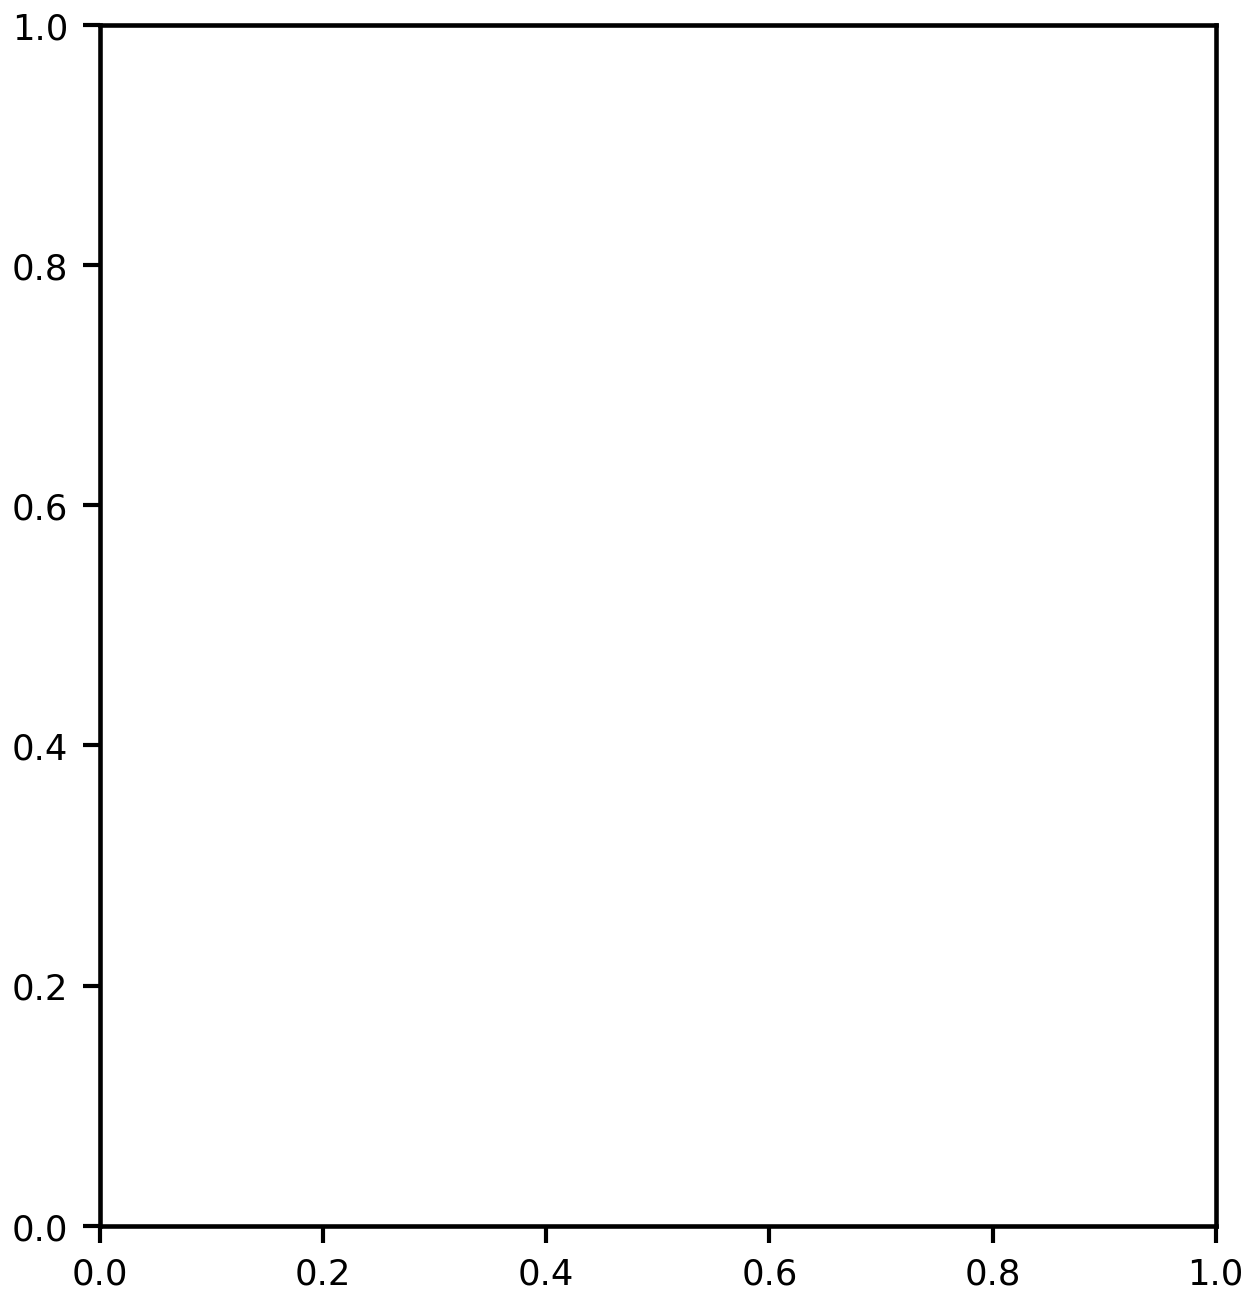

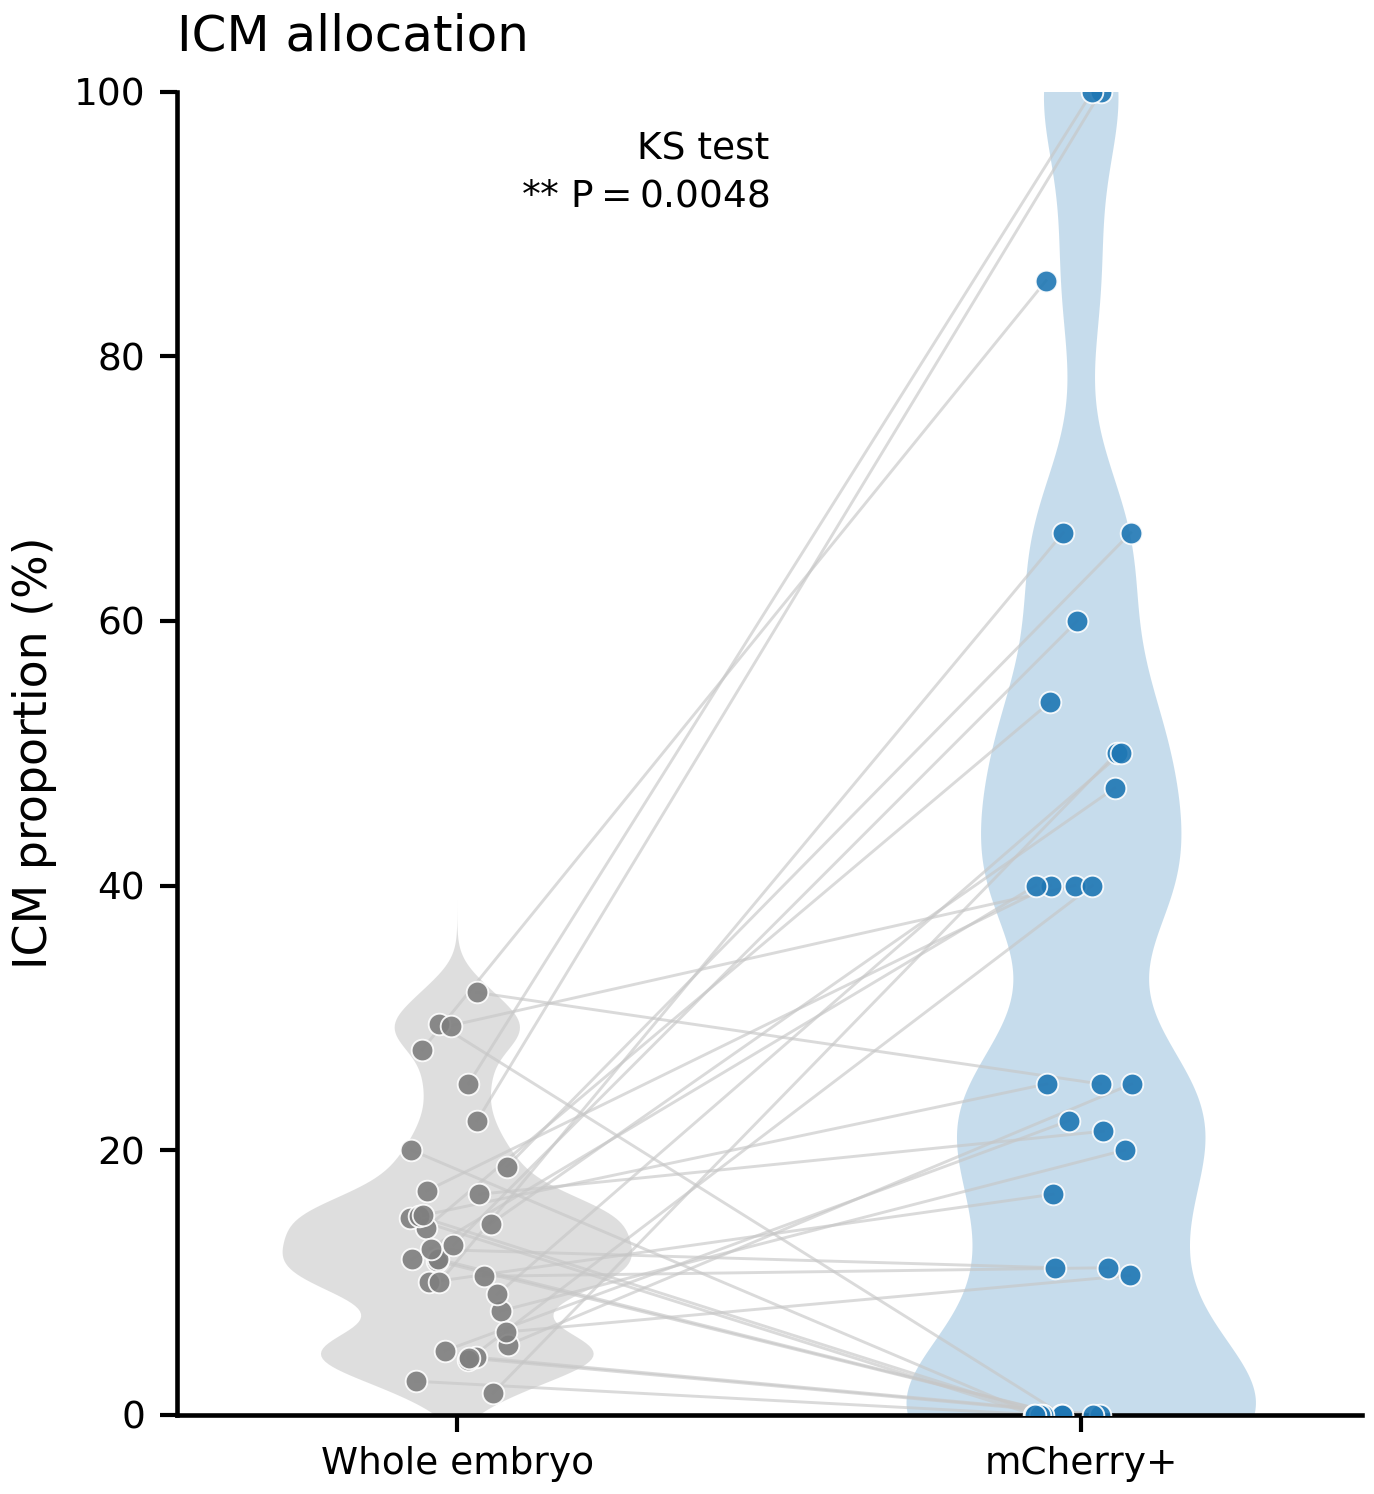

In [76]:

# ============================================================
# ZSCAN4-KO embryo lineage allocation
# Actual vs mCherry+
#
# Analysis:
#   - Remove embryos with SOX2 = 0
#   - Hartigan dip test
#   - Silverman critical-bandwidth tests
#   - GMM model comparison
#   - KDE peak-count sensitivity analysis
#   - Paired distribution permutation test
#   - Paired mean-difference sign-flip test
#   - Two-sample KS test (raw P values)
#
# Plot:
#   - ICM only: Actual vs mCherry+
#   - KDE violins, bw_method = 0.2
#   - Paired embryo lines and individual points
#   - KS statistic, raw P value and significance
#
# Outputs:
#   - Statistical result TXT files
#   - ICM-only SVG and PDF figures
# ============================================================

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import (
    gaussian_kde,
    ks_2samp,
)
from scipy.signal import find_peaks
from sklearn.mixture import GaussianMixture

try:
    from diptest import diptest
except ImportError:
    raise ImportError("Install diptest: pip install diptest")


# ============================================================
# 0. Parameters
# ============================================================

input_file = "red_icm_te_count.txt"

RANDOM_SEED = 12345
N_PERMUTATIONS = 20000

N_SILVERMAN_BOOTSTRAP = 100
SILVERMAN_GRIDSIZE = 300
SILVERMAN_GRID = np.linspace(0.0, 1.0, SILVERMAN_GRIDSIZE)
SILVERMAN_MAX_ITER = 20

KDE_BANDWIDTHS = [0.1, 0.2, 0.3, 0.5]
KDE_GRIDSIZE = 1000
PEAK_PROMINENCE_FRACTION = 0.05

GMM_N_INIT = 20

rng = np.random.default_rng(RANDOM_SEED)
t_start = time.time()


# ============================================================
# 1. Plot settings
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "svg.hashsalt": "hello",
    "axes.linewidth": 1.1,
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "mathtext.fontset": "dejavusans",
})


# ============================================================
# 2. Read and validate input
# ============================================================

df = pd.read_csv(input_file, sep="\t")

required_cols = [
    "treatment", "编号",
    "mCherry-ICM", "mCherry-TE",
    "SOX2", "GATA3"
]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

df = df[
    df["treatment"].astype(str).str.strip().str.upper() == "ZSCAN4-KO"
].copy().reset_index(drop=True)

if len(df) == 0:
    raise ValueError("No ZSCAN4-KO embryos found.")

print(f"Number of ZSCAN4-KO embryos before filtering: {len(df)}")

count_cols = ["mCherry-ICM", "mCherry-TE", "SOX2", "GATA3"]

for col in count_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if df[count_cols].isna().any().any():
    raise ValueError("Missing or non-numeric cell counts detected.")

if (df[count_cols] < 0).any().any():
    raise ValueError("Negative cell counts detected.")

for col in count_cols:
    if not np.allclose(df[col], np.round(df[col])):
        raise ValueError(f"Non-integer counts detected in {col}")
    df[col] = df[col].astype(int)


# ============================================================
# 2b. Remove embryos with SOX2 = 0
# ============================================================

n_before = len(df)
sox2_zero_mask = df["SOX2"] == 0

print(
    f"Embryos with SOX2 = 0 removed: "
    f"{int(sox2_zero_mask.sum())}"
)

df = df[~sox2_zero_mask].copy().reset_index(drop=True)

print(
    f"Number of ZSCAN4-KO embryos after filtering: {len(df)} "
    f"(removed {n_before - len(df)})"
)

if len(df) == 0:
    raise ValueError("No embryos left after filtering.")


# ============================================================
# 3. Calculate lineage proportions
# ============================================================

df["actual_total"] = df["SOX2"] + df["GATA3"]
df["mCherry_pos_total"] = df["mCherry-ICM"] + df["mCherry-TE"]

df["actual_ICM_prop"] = np.where(
    df["actual_total"] > 0,
    df["SOX2"] / df["actual_total"],
    np.nan
)

df["actual_TrE_prop"] = np.where(
    df["actual_total"] > 0,
    df["GATA3"] / df["actual_total"],
    np.nan
)

df["mCherry_pos_ICM_prop"] = np.where(
    df["mCherry_pos_total"] > 0,
    df["mCherry-ICM"] / df["mCherry_pos_total"],
    np.nan
)

df["mCherry_pos_TrE_prop"] = np.where(
    df["mCherry_pos_total"] > 0,
    df["mCherry-TE"] / df["mCherry_pos_total"],
    np.nan
)


# ============================================================
# 4. BH correction helper (used for dip-test results only)
# ============================================================

def bh_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(p_values.shape, np.nan)

    valid_idx = np.where(np.isfinite(p_values))[0]
    if len(valid_idx) == 0:
        return adjusted

    p = p_values[valid_idx]
    order = np.argsort(p)
    sorted_p = p[order]
    m = len(sorted_p)

    sorted_q = sorted_p * m / np.arange(1, m + 1)
    sorted_q = np.minimum.accumulate(sorted_q[::-1])[::-1]
    sorted_q = np.clip(sorted_q, 0, 1)

    q_orig = np.empty(m)
    q_orig[order] = sorted_q
    adjusted[valid_idx] = q_orig

    return adjusted


# ============================================================
# 5. Hartigan dip test
# ============================================================

def run_dip_test(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "dip_statistic": np.nan,
        "dip_pvalue": np.nan
    }

    if len(x) >= 3 and np.unique(x).size >= 2:
        dip_stat, p_value = diptest(x)
        result["dip_statistic"] = float(dip_stat)
        result["dip_pvalue"] = float(p_value)

    return result


# ============================================================
# 6. Silverman critical-bandwidth test
# ============================================================

def _count_modes_fast(grid_minus_x, sd, h):
    bw = h * sd
    if bw <= 0:
        return 0

    z = grid_minus_x / bw
    density = np.exp(-0.5 * z * z).sum(axis=1)
    peaks, _ = find_peaks(density)

    return len(peaks)


def silverman_critical_bandwidth(
    x,
    k=1,
    grid=SILVERMAN_GRID,
    max_iter=SILVERMAN_MAX_ITER
):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)

    if n < 3 or np.unique(x).size < 3:
        return np.nan

    sd = float(np.std(x, ddof=1))
    if sd <= 0:
        return np.nan

    grid_minus_x = grid[:, None] - x[None, :]

    lo, hi = 1e-5, 5.0

    if _count_modes_fast(grid_minus_x, sd, hi) > k:
        return np.nan

    for _ in range(max_iter):
        mid = 0.5 * (lo + hi)

        if _count_modes_fast(grid_minus_x, sd, mid) <= k:
            hi = mid
        else:
            lo = mid

        if hi - lo < 1e-5:
            break

    return hi


def silverman_test(
    x,
    k=1,
    n_boot=N_SILVERMAN_BOOTSTRAP,
    grid=SILVERMAN_GRID
):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)

    result = {
        "k_null": k,
        "h_crit": np.nan,
        "silverman_pvalue": np.nan
    }

    if n < 10 or np.unique(x).size < 3:
        return result

    h_crit = silverman_critical_bandwidth(x, k=k, grid=grid)

    if not np.isfinite(h_crit):
        return result

    result["h_crit"] = float(h_crit)

    sd_x = float(np.std(x, ddof=1))
    if sd_x <= 0:
        return result

    idx = rng.integers(0, n, size=(n_boot, n))
    noise = rng.normal(0.0, h_crit * sd_x, size=(n_boot, n))
    boot = x[idx] + noise

    exceed = 0

    for b in range(n_boot):
        h_b = silverman_critical_bandwidth(
            boot[b], k=k, grid=grid
        )

        if np.isfinite(h_b) and h_b > h_crit:
            exceed += 1

    result["silverman_pvalue"] = (
        exceed + 1
    ) / (n_boot + 1)

    return result


# ============================================================
# 7. GMM comparison
# ============================================================

def run_gmm_comparison(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "BIC_1_component": np.nan,
        "BIC_2_components": np.nan,
        "delta_BIC_1_minus_2": np.nan,
        "preferred_by_BIC": "NA",
        "GMM_2_component_means": "NA",
        "GMM_2_component_weights": "NA",
    }

    if len(x) < 5 or np.unique(x).size < 2:
        return result

    X = x.reshape(-1, 1)

    try:
        model1 = GaussianMixture(
            n_components=1,
            covariance_type="full",
            n_init=GMM_N_INIT,
            random_state=RANDOM_SEED,
            reg_covar=1e-6,
        )

        model2 = GaussianMixture(
            n_components=2,
            covariance_type="full",
            n_init=GMM_N_INIT,
            random_state=RANDOM_SEED,
            reg_covar=1e-6,
        )

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model1.fit(X)
            model2.fit(X)

        bic1 = float(model1.bic(X))
        bic2 = float(model2.bic(X))

        result["BIC_1_component"] = bic1
        result["BIC_2_components"] = bic2
        result["delta_BIC_1_minus_2"] = bic1 - bic2

        if bic2 < bic1:
            result["preferred_by_BIC"] = "2 components"
        elif bic1 < bic2:
            result["preferred_by_BIC"] = "1 component"
        else:
            result["preferred_by_BIC"] = "Tie"

        result["GMM_2_component_means"] = ",".join(
            f"{v:.6g}" for v in np.sort(model2.means_.ravel())
        )

        result["GMM_2_component_weights"] = ",".join(
            f"{v:.6g}" for v in model2.weights_
        )

    except (ValueError, np.linalg.LinAlgError) as exc:
        print(f"Warning: GMM fitting failed: {exc}")

    return result


# ============================================================
# 8. KDE peak count
# ============================================================

def count_kde_peaks(values, bw_factor):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "bandwidth_factor": bw_factor,
        "n_KDE_peaks": np.nan,
        "peak_locations": "NA",
    }

    if len(x) < 3 or np.unique(x).size < 2:
        return result

    try:
        kde = gaussian_kde(x, bw_method=bw_factor)
        grid = np.linspace(0, 1, KDE_GRIDSIZE)
        density = kde(grid)

        if not np.isfinite(density).all() or density.max() <= 0:
            return result

        prominence = density.max() * PEAK_PROMINENCE_FRACTION
        peak_indices, _ = find_peaks(
            density, prominence=prominence
        )

        result["n_KDE_peaks"] = int(len(peak_indices))
        result["peak_locations"] = ",".join(
            f"{grid[i]:.4f}" for i in peak_indices
        )

    except (ValueError, np.linalg.LinAlgError) as exc:
        print(f"Warning: KDE peak analysis failed: {exc}")

    return result


# ============================================================
# 9. Paired distribution permutation test
# ============================================================

def paired_distribution_permutation(
    actual,
    positive,
    n_permutations=N_PERMUTATIONS
):
    actual = np.asarray(actual, dtype=float)
    positive = np.asarray(positive, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(positive)
    a = actual[valid]
    b = positive[valid]
    n = len(a)

    result = {
        "n_paired": n,
        "Wasserstein_distance": np.nan,
        "distribution_permutation_pvalue": np.nan,
    }

    if n < 2:
        return result

    observed = float(
        np.mean(np.abs(np.sort(a) - np.sort(b)))
    )

    swaps = rng.random((n_permutations, n)) < 0.5
    perm_a = np.where(swaps, b, a)
    perm_b = np.where(swaps, a, b)

    perm_a.sort(axis=1)
    perm_b.sort(axis=1)

    perm_stats = np.mean(
        np.abs(perm_a - perm_b), axis=1
    )

    exceed = int(
        np.sum(perm_stats >= observed - 1e-12)
    )

    result["Wasserstein_distance"] = observed
    result["distribution_permutation_pvalue"] = (
        exceed + 1
    ) / (n_permutations + 1)

    return result


# ============================================================
# 10. Paired mean-difference sign-flip test
# ============================================================

def paired_mean_signflip_test(
    actual,
    positive,
    n_permutations=N_PERMUTATIONS
):
    actual = np.asarray(actual, dtype=float)
    positive = np.asarray(positive, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(positive)
    a = actual[valid]
    b = positive[valid]

    d = b - a
    n = len(d)

    result = {
        "n_paired": n,
        "mean_paired_difference_pp": np.nan,
        "median_paired_difference_pp": np.nan,
        "paired_mean_signflip_pvalue": np.nan,
    }

    if n < 2:
        return result

    observed = abs(np.mean(d))

    signs = rng.choice(
        [-1.0, 1.0],
        size=(n_permutations, n)
    )

    perm_means = np.abs(
        np.mean(signs * d, axis=1)
    )

    p_value = (
        np.sum(perm_means >= observed - 1e-12) + 1
    ) / (n_permutations + 1)

    result["mean_paired_difference_pp"] = float(
        np.mean(d) * 100
    )

    result["median_paired_difference_pp"] = float(
        np.median(d) * 100
    )

    result["paired_mean_signflip_pvalue"] = float(p_value)

    return result


# ============================================================
# 10b. Two-sample KS test
# ============================================================

def ks_test(actual, positive):
    """
    Two-sample KS test on marginal distributions.
    P value is unadjusted.
    """
    actual = np.asarray(actual, dtype=float)
    positive = np.asarray(positive, dtype=float)

    a = actual[np.isfinite(actual)]
    b = positive[np.isfinite(positive)]

    result = {
        "n_KS_a": len(a),
        "n_KS_b": len(b),
        "KS_statistic": np.nan,
        "KS_pvalue": np.nan,
    }

    if len(a) < 2 or len(b) < 2:
        return result

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            stat, p = ks_2samp(
                a, b, alternative="two-sided", method="auto"
            )

        result["KS_statistic"] = float(stat)
        result["KS_pvalue"] = float(p)

    except ValueError as exc:
        print(f"Warning: KS test failed: {exc}")

    return result


# ============================================================
# 11. Run analyses: retain ICM and TrE statistics
# ============================================================

lineage_specs = {
    "ICM": {
        "actual": "actual_ICM_prop",
        "positive": "mCherry_pos_ICM_prop",
    },
    "TrE": {
        "actual": "actual_TrE_prop",
        "positive": "mCherry_pos_TrE_prop",
    },
}

distribution_results = []
gmm_results = []
kde_results = []
comparison_results = []
multimodality_results = []

for lineage, spec in lineage_specs.items():

    for group_name, col in [
        ("Whole embryo", spec["actual"]),
        ("mCherry+", spec["positive"]),
    ]:

        values = df[col].to_numpy(dtype=float)
        values = values[np.isfinite(values)]

        summary = {
            "Lineage": lineage,
            "Group": group_name,
            "n": len(values),
            "Mean_proportion": (
                float(np.mean(values)) if len(values) else np.nan
            ),
            "SD_proportion": (
                float(np.std(values, ddof=1))
                if len(values) > 1 else np.nan
            ),
            "Median_proportion": (
                float(np.median(values)) if len(values) else np.nan
            ),
            "Q1_proportion": (
                float(np.percentile(values, 25))
                if len(values) else np.nan
            ),
            "Q3_proportion": (
                float(np.percentile(values, 75))
                if len(values) else np.nan
            ),
        }

        dip = run_dip_test(values)
        summary.update(dip)

        t0 = time.time()

        silver_k1 = silverman_test(
            values, k=1, n_boot=N_SILVERMAN_BOOTSTRAP
        )

        silver_k2 = silverman_test(
            values, k=2, n_boot=N_SILVERMAN_BOOTSTRAP
        )

        t_silver = time.time() - t0

        summary["Silverman_k1_h_crit"] = silver_k1["h_crit"]
        summary["Silverman_k1_pvalue"] = silver_k1["silverman_pvalue"]
        summary["Silverman_k2_h_crit"] = silver_k2["h_crit"]
        summary["Silverman_k2_pvalue"] = silver_k2["silverman_pvalue"]

        distribution_results.append(summary)

        multimodality_results.append({
            "Lineage": lineage,
            "Group": group_name,
            "n": len(values),
            "Hartigan_dip_pvalue": dip["dip_pvalue"],
            "Silverman_k1_h_crit": silver_k1["h_crit"],
            "Silverman_k1_pvalue": silver_k1["silverman_pvalue"],
            "Silverman_k2_h_crit": silver_k2["h_crit"],
            "Silverman_k2_pvalue": silver_k2["silverman_pvalue"],
        })

        gmm = run_gmm_comparison(values)
        gmm["Lineage"] = lineage
        gmm["Group"] = group_name
        gmm_results.append(gmm)

        for bw in KDE_BANDWIDTHS:
            peak_result = count_kde_peaks(values, bw)
            peak_result["Lineage"] = lineage
            peak_result["Group"] = group_name
            kde_results.append(peak_result)

        print(
            f"[{lineage} | {group_name}] done "
            f"(Silverman: {t_silver:.1f}s)"
        )

    actual = df[spec["actual"]].to_numpy(dtype=float)
    positive = df[spec["positive"]].to_numpy(dtype=float)

    dist_test = paired_distribution_permutation(
        actual, positive,
        n_permutations=N_PERMUTATIONS
    )

    mean_test = paired_mean_signflip_test(
        actual, positive,
        n_permutations=N_PERMUTATIONS
    )

    ks = ks_test(actual, positive)

    comparison_results.append({
        "Lineage": lineage,
        **ks,
        **dist_test,
        **mean_test,
    })


# ============================================================
# 12. DataFrames and dip-test BH correction
# ============================================================

distribution_df = pd.DataFrame(distribution_results)

distribution_df["dip_BH_qvalue"] = bh_adjust(
    distribution_df["dip_pvalue"].to_numpy(dtype=float)
)

gmm_df = pd.DataFrame(gmm_results)
kde_df = pd.DataFrame(kde_results)
comparison_df = pd.DataFrame(comparison_results)
multimodality_df = pd.DataFrame(multimodality_results)


# ============================================================
# 13. Print distribution-shape statistics
# ============================================================

print("\n" + "=" * 80)
print("DISTRIBUTION SHAPE: DIP TEST, SILVERMAN TEST, GMM")
print("=" * 80)

for _, row in distribution_df.iterrows():

    print(f"\n{row['Lineage']} | {row['Group']} | n={row['n']}")

    print(f"  Mean proportion: {row['Mean_proportion']:.4f}")

    print(
        f"  Median (Q1-Q3): {row['Median_proportion']:.4f} "
        f"({row['Q1_proportion']:.4f}-"
        f"{row['Q3_proportion']:.4f})"
    )

    if np.isfinite(row["dip_pvalue"]):
        print(
            f"  Hartigan dip: stat={row['dip_statistic']:.5f}, "
            f"P={row['dip_pvalue']:.5g}, "
            f"BH q={row['dip_BH_qvalue']:.5g}"
        )
    else:
        print("  Hartigan dip: unavailable")

    for k in [1, 2]:
        p_col = f"Silverman_k{k}_pvalue"
        h_col = f"Silverman_k{k}_h_crit"

        if np.isfinite(row[p_col]):
            print(
                f"  Silverman k={k}: h_crit={row[h_col]:.5f}, "
                f"P={row[p_col]:.5g}"
            )
        else:
            print(f"  Silverman k={k}: unavailable")

    gmm_row = gmm_df[
        (gmm_df["Lineage"] == row["Lineage"]) &
        (gmm_df["Group"] == row["Group"])
    ].iloc[0]

    print(
        f"  GMM BIC: 1comp={gmm_row['BIC_1_component']:.3f}; "
        f"2comp={gmm_row['BIC_2_components']:.3f}"
    )

    print(f"  Preferred by BIC: {gmm_row['preferred_by_BIC']}")


# ============================================================
# 14. Print KDE peak-count sensitivity
# ============================================================

print("\n" + "=" * 80)
print("KDE PEAK COUNT SENSITIVITY")
print("=" * 80)

for _, row in kde_df.iterrows():
    print(
        f"{row['Lineage']:>4} | {row['Group']:>9} | "
        f"bw={row['bandwidth_factor']:<4} | "
        f"n_peaks={row['n_KDE_peaks']} | "
        f"locations={row['peak_locations']}"
    )


# ============================================================
# 15. Print Actual vs mCherry+ comparisons
# ============================================================

print("\n" + "=" * 80)
print("Whole embryo vs mCherry+ COMPARISONS")
print("=" * 80)

for _, row in comparison_df.iterrows():

    print(f"\n{row['Lineage']}")
    print(f"  Paired embryos: {row['n_paired']}")

    if np.isfinite(row["KS_pvalue"]):
        print(
            f"  KS test: D={row['KS_statistic']:.4f}, "
            f"P={row['KS_pvalue']:.8g} "
            f"(n_a={row['n_KS_a']}, n_b={row['n_KS_b']})"
        )
    else:
        print("  KS test: unavailable")

    print(
        f"  Wasserstein distance: "
        f"{row['Wasserstein_distance']:.5f}"
    )

    print(
        f"  Paired label-swap permutation P: "
        f"{row['distribution_permutation_pvalue']:.5g}"
    )

    print(
        f"  Mean paired difference (mCherry+ - Actual): "
        f"{row['mean_paired_difference_pp']:.3f} pp"
    )

    print(
        f"  Median paired difference: "
        f"{row['median_paired_difference_pp']:.3f} pp"
    )

    print(
        f"  Paired mean sign-flip P: "
        f"{row['paired_mean_signflip_pvalue']:.5g}"
    )


# ============================================================
# 16. Save statistical results
# ============================================================

files = {
    "distribution": "ZSCAN4-KO_lineage_distribution_statistics.txt",
    "comparison": "ZSCAN4-KO_lineage_distribution_comparison.txt",
    "gmm": "ZSCAN4-KO_lineage_GMM_BIC_comparison.txt",
    "kde": "ZSCAN4-KO_lineage_KDE_peak_sensitivity.txt",
    "multimodality": "ZSCAN4-KO_lineage_multimodality_tests.txt",
}

distribution_df.to_csv(
    files["distribution"], sep="\t",
    index=False, float_format="%.8g"
)

comparison_df.to_csv(
    files["comparison"], sep="\t",
    index=False, float_format="%.8g"
)

gmm_df.to_csv(
    files["gmm"], sep="\t",
    index=False, float_format="%.8g"
)

kde_df.to_csv(
    files["kde"], sep="\t",
    index=False, float_format="%.8g"
)

multimodality_df.to_csv(
    files["multimodality"], sep="\t",
    index=False, float_format="%.8g"
)

print("\nStatistics saved:")
for filename in files.values():
    print(f"  {filename}")


# ============================================================
# 17. Plot ICM only: Actual vs mCherry+
# ============================================================

COLORS = {
    "Whole embryo": "#7F7F7F",
    "mCherry+": "#1F77B4"
}

LINE_COLOR = "#C7C7C7"

fig, ax = plt.subplots(1, 1, figsize=(4.8, 5.2))

positions = {
    "Whole embryo": 1.0,
    "mCherry+": 2.0
}

jitter_rng = np.random.default_rng(RANDOM_SEED)
jitter = jitter_rng.uniform(-0.09, 0.09, size=len(df))

# ICM proportions expressed as percentages
actual = df["actual_ICM_prop"].to_numpy(dtype=float) * 100
positive = df["mCherry_pos_ICM_prop"].to_numpy(dtype=float) * 100



# ============================================================
# 17. Plot ICM only: Actual vs mCherry+
# ============================================================

COLORS = {
    "Whole embryo": "#7F7F7F",
    "mCherry+": "#1F77B4"
}

LINE_COLOR = "#C7C7C7"

fig, ax = plt.subplots(1, 1, figsize=(4.8, 5.2))

positions = {
    "Whole embryo": 1.0,
    "mCherry+": 2.0
}

jitter_rng = np.random.default_rng(RANDOM_SEED)
jitter = jitter_rng.uniform(-0.09, 0.09, size=len(df))

# ICM proportions expressed as percentages
actual = df["actual_ICM_prop"].to_numpy(dtype=float) * 100
positive = df["mCherry_pos_ICM_prop"].to_numpy(dtype=float) * 100


# ------------------------------------------------------------
# 17a. KDE violins
# ------------------------------------------------------------

grid = np.linspace(0, 100, 500)

for group_name, values in [
    ("Whole embryo", actual),
    ("mCherry+", positive)
]:
    valid_values = values[np.isfinite(values)]

    if len(valid_values) >= 2 and np.unique(valid_values).size >= 2:
        try:
            kde = gaussian_kde(valid_values, bw_method=0.2)
            density = kde(grid)

            if np.isfinite(density).all() and density.max() > 0:
                density_scaled = density / density.max() * 0.28
                pos = positions[group_name]

                ax.fill_betweenx(
                    grid,
                    pos - density_scaled,
                    pos + density_scaled,
                    facecolor=COLORS[group_name],
                    edgecolor="none",
                    alpha=0.25,
                    zorder=1
                )
        except (ValueError, np.linalg.LinAlgError) as exc:
            print(f"Warning: KDE failed for {group_name}: {exc}")


# ------------------------------------------------------------
# 17b. Paired lines and individual observations
# ------------------------------------------------------------

for i in range(len(df)):
    ya = actual[i]
    yp = positive[i]

    if not (np.isfinite(ya) and np.isfinite(yp)):
        continue

    x1 = positions["Whole embryo"] + jitter[i]
    x2 = positions["mCherry+"] + jitter[i]

    ax.plot(
        [x1, x2],
        [ya, yp],
        color=LINE_COLOR,
        linewidth=0.7,
        alpha=0.65,
        zorder=2
    )

    ax.scatter(
        x1, ya,
        s=27,
        facecolor=COLORS["Whole embryo"],
        edgecolor="white",
        linewidth=0.45,
        alpha=0.9,
        zorder=3
    )

    ax.scatter(
        x2, yp,
        s=27,
        facecolor=COLORS["mCherry+"],
        edgecolor="white",
        linewidth=0.45,
        alpha=0.9,
        zorder=3
    )


# ------------------------------------------------------------
# 17c. KS test annotation: raw, unadjusted P value
# ------------------------------------------------------------

def format_p_value_math(p):
    """Format the original P value using mathtext superscripts."""
    if not np.isfinite(p):
        return r"$P = \mathrm{NA}$"

    if p == 0:
        # Numerical underflow: the computed value is zero.
        return r"$P < 10^{-300}$"

    if p < 0.001 or p >= 0.9995:
        exponent = int(np.floor(np.log10(p)))
        coefficient = p / (10.0 ** exponent)

        return (
            rf"$P = {coefficient:.2f}"
            rf" \times 10^{{{exponent}}}$"
        )

    return rf"$P = {p:.4f}$"


valid_a = actual[np.isfinite(actual)]
valid_p = positive[np.isfinite(positive)]

if len(valid_a) >= 2 and len(valid_p) >= 2:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        ks_d, ks_p = ks_2samp(
            valid_a,
            valid_p,
            alternative="two-sided",
            method="auto"
        )

    if ks_p < 0.001:
        sig_label = "***"
    elif ks_p < 0.01:
        sig_label = "**"
    elif ks_p < 0.05:
        sig_label = "*"
    else:
        sig_label = "ns"

    p_label = format_p_value_math(ks_p)

    annotation = (
        f"KS test\n"
        f"{sig_label} {p_label}\n"
    )

else:
    annotation = "KS test\nNot available"

ax.text(
    0.5, 0.97,
    annotation,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    linespacing=1.4
)


# ------------------------------------------------------------
# 17d. Axis formatting
# ------------------------------------------------------------

ax.set_title(
    "ICM allocation",
    loc="left",
    fontsize=12,
    pad=10
)

ax.set_xticks([1, 2])
ax.set_xticklabels(
    ["Whole embryo", "mCherry+"],
    fontsize=10
)

ax.set_ylabel("ICM proportion (%)", fontsize=11)
ax.set_xlim(0.55, 2.45)
ax.set_ylim(0, 100)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)
ax.tick_params(axis="both", labelsize=9)

fig.tight_layout()


# ------------------------------------------------------------
# 17e. Save ICM-only figure as SVG and PDF
# ------------------------------------------------------------

svg_file = "ZSCAN4-KO_ICM_distribution_comparison.svg"

fig.savefig(
    svg_file,
    format="svg",
    bbox_inches="tight",
    transparent=True
)

# ============================================================
# 18. Final summary
# ============================================================

print("\nFigure saved:")
print(f"  {svg_file}")

print(f"\nTotal run time: {time.time() - t_start:.1f} s")

print("\nAnalysis completed.")
print("Embryos with SOX2 = 0 were excluded.")
print("The figure displays ICM only.")
print("KS P value shown on the figure is the original, unadjusted P value.")
print("TrE statistics are retained in the output files but are not plotted.")



In [77]:

# ============================================================
# WT and ZSCAN4-KO embryo lineage allocation
# Combined ICM distributions and four requested KS comparisons
#
# Analysis:
#   - Remove embryos with SOX2 = 0
#   - Hartigan dip test
#   - Silverman critical-bandwidth tests
#   - GMM model comparison
#   - KDE peak-count sensitivity analysis
#   - Paired distribution permutation test
#   - Paired mean-difference sign-flip test
#   - Two-sample KS test (raw P values)
#
# Plot:
#   - Detailed distribution analyses remain on ZSCAN4-KO
#   - Combined WT and ZSCAN4-KO ICM figure
#   - Four two-sided KS tests annotated on the figure
#
# Outputs:
#   - Statistical result TXT files
#   - ICM-only SVG and PDF figures
# ============================================================

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import (
    gaussian_kde,
    ks_2samp,
)
from scipy.signal import find_peaks
from sklearn.mixture import GaussianMixture

try:
    from diptest import diptest
except ImportError:
    raise ImportError("Install diptest: pip install diptest")


# ============================================================
# 0. Parameters
# ============================================================

input_file = "red_icm_te_count.txt"

RANDOM_SEED = 12345
N_PERMUTATIONS = 20000

N_SILVERMAN_BOOTSTRAP = 100
SILVERMAN_GRIDSIZE = 300
SILVERMAN_GRID = np.linspace(0.0, 1.0, SILVERMAN_GRIDSIZE)
SILVERMAN_MAX_ITER = 20

KDE_BANDWIDTHS = [0.1, 0.2, 0.3, 0.5]
KDE_GRIDSIZE = 1000
PEAK_PROMINENCE_FRACTION = 0.05

GMM_N_INIT = 20

rng = np.random.default_rng(RANDOM_SEED)
t_start = time.time()


# ============================================================
# 1. Plot settings
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "svg.hashsalt": "hello",
    "axes.linewidth": 1.1,
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "mathtext.fontset": "dejavusans",
})


# ============================================================
# 2. Read and validate input
# ============================================================

df_all = pd.read_csv(input_file, sep="\t")

required_cols = [
    "treatment", "编号",
    "mCherry-ICM", "mCherry-TE",
    "SOX2", "GATA3"
]

missing_cols = [c for c in required_cols if c not in df_all.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

count_cols = ["mCherry-ICM", "mCherry-TE", "SOX2", "GATA3"]
for col in count_cols:
    df_all[col] = pd.to_numeric(df_all[col], errors="coerce")

if df_all[count_cols].isna().any().any():
    raise ValueError("Missing or non-numeric cell counts detected.")
if (df_all[count_cols] < 0).any().any():
    raise ValueError("Negative cell counts detected.")
for col in count_cols:
    if not np.allclose(df_all[col], np.round(df_all[col])):
        raise ValueError(f"Non-integer counts detected in {col}")
    df_all[col] = df_all[col].astype(int)

df_all["treatment_clean"] = df_all["treatment"].astype(str).str.strip().str.casefold()

# Keep the ZSCAN4-KO subset for the original detailed distribution analyses.
df = df_all[
    df_all["treatment_clean"] == "zscan4-ko"
].copy().reset_index(drop=True)

if len(df) == 0:
    raise ValueError("No ZSCAN4-KO embryos found. Check the treatment labels in the input file.")

print(f"Number of ZSCAN4-KO embryos before filtering: {len(df)}")

# ============================================================
# 2b. Remove embryos with SOX2 = 0
# ============================================================

n_before = len(df)
sox2_zero_mask = df["SOX2"] == 0

print(
    f"Embryos with SOX2 = 0 removed: "
    f"{int(sox2_zero_mask.sum())}"
)

df = df[~sox2_zero_mask].copy().reset_index(drop=True)

print(
    f"Number of ZSCAN4-KO embryos after filtering: {len(df)} "
    f"(removed {n_before - len(df)})"
)

if len(df) == 0:
    raise ValueError("No embryos left after filtering.")


# ============================================================
# 3. Calculate lineage proportions
# ============================================================

df["actual_total"] = df["SOX2"] + df["GATA3"]
df["mCherry_pos_total"] = df["mCherry-ICM"] + df["mCherry-TE"]

df["actual_ICM_prop"] = np.where(
    df["actual_total"] > 0,
    df["SOX2"] / df["actual_total"],
    np.nan
)

df["actual_TrE_prop"] = np.where(
    df["actual_total"] > 0,
    df["GATA3"] / df["actual_total"],
    np.nan
)

df["mCherry_pos_ICM_prop"] = np.where(
    df["mCherry_pos_total"] > 0,
    df["mCherry-ICM"] / df["mCherry_pos_total"],
    np.nan
)

df["mCherry_pos_TrE_prop"] = np.where(
    df["mCherry_pos_total"] > 0,
    df["mCherry-TE"] / df["mCherry_pos_total"],
    np.nan
)


# ============================================================
# 4. BH correction helper (used for dip-test results only)
# ============================================================

def bh_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(p_values.shape, np.nan)

    valid_idx = np.where(np.isfinite(p_values))[0]
    if len(valid_idx) == 0:
        return adjusted

    p = p_values[valid_idx]
    order = np.argsort(p)
    sorted_p = p[order]
    m = len(sorted_p)

    sorted_q = sorted_p * m / np.arange(1, m + 1)
    sorted_q = np.minimum.accumulate(sorted_q[::-1])[::-1]
    sorted_q = np.clip(sorted_q, 0, 1)

    q_orig = np.empty(m)
    q_orig[order] = sorted_q
    adjusted[valid_idx] = q_orig

    return adjusted


# ============================================================
# 5. Hartigan dip test
# ============================================================

def run_dip_test(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "dip_statistic": np.nan,
        "dip_pvalue": np.nan
    }

    if len(x) >= 3 and np.unique(x).size >= 2:
        dip_stat, p_value = diptest(x)
        result["dip_statistic"] = float(dip_stat)
        result["dip_pvalue"] = float(p_value)

    return result


# ============================================================
# 6. Silverman critical-bandwidth test
# ============================================================

def _count_modes_fast(grid_minus_x, sd, h):
    bw = h * sd
    if bw <= 0:
        return 0

    z = grid_minus_x / bw
    density = np.exp(-0.5 * z * z).sum(axis=1)
    peaks, _ = find_peaks(density)

    return len(peaks)


def silverman_critical_bandwidth(
    x,
    k=1,
    grid=SILVERMAN_GRID,
    max_iter=SILVERMAN_MAX_ITER
):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)

    if n < 3 or np.unique(x).size < 3:
        return np.nan

    sd = float(np.std(x, ddof=1))
    if sd <= 0:
        return np.nan

    grid_minus_x = grid[:, None] - x[None, :]

    lo, hi = 1e-5, 5.0

    if _count_modes_fast(grid_minus_x, sd, hi) > k:
        return np.nan

    for _ in range(max_iter):
        mid = 0.5 * (lo + hi)

        if _count_modes_fast(grid_minus_x, sd, mid) <= k:
            hi = mid
        else:
            lo = mid

        if hi - lo < 1e-5:
            break

    return hi


def silverman_test(
    x,
    k=1,
    n_boot=N_SILVERMAN_BOOTSTRAP,
    grid=SILVERMAN_GRID
):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)

    result = {
        "k_null": k,
        "h_crit": np.nan,
        "silverman_pvalue": np.nan
    }

    if n < 10 or np.unique(x).size < 3:
        return result

    h_crit = silverman_critical_bandwidth(x, k=k, grid=grid)

    if not np.isfinite(h_crit):
        return result

    result["h_crit"] = float(h_crit)

    sd_x = float(np.std(x, ddof=1))
    if sd_x <= 0:
        return result

    idx = rng.integers(0, n, size=(n_boot, n))
    noise = rng.normal(0.0, h_crit * sd_x, size=(n_boot, n))
    boot = x[idx] + noise

    exceed = 0

    for b in range(n_boot):
        h_b = silverman_critical_bandwidth(
            boot[b], k=k, grid=grid
        )

        if np.isfinite(h_b) and h_b > h_crit:
            exceed += 1

    result["silverman_pvalue"] = (
        exceed + 1
    ) / (n_boot + 1)

    return result


# ============================================================
# 7. GMM comparison
# ============================================================

def run_gmm_comparison(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "BIC_1_component": np.nan,
        "BIC_2_components": np.nan,
        "delta_BIC_1_minus_2": np.nan,
        "preferred_by_BIC": "NA",
        "GMM_2_component_means": "NA",
        "GMM_2_component_weights": "NA",
    }

    if len(x) < 5 or np.unique(x).size < 2:
        return result

    X = x.reshape(-1, 1)

    try:
        model1 = GaussianMixture(
            n_components=1,
            covariance_type="full",
            n_init=GMM_N_INIT,
            random_state=RANDOM_SEED,
            reg_covar=1e-6,
        )

        model2 = GaussianMixture(
            n_components=2,
            covariance_type="full",
            n_init=GMM_N_INIT,
            random_state=RANDOM_SEED,
            reg_covar=1e-6,
        )

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model1.fit(X)
            model2.fit(X)

        bic1 = float(model1.bic(X))
        bic2 = float(model2.bic(X))

        result["BIC_1_component"] = bic1
        result["BIC_2_components"] = bic2
        result["delta_BIC_1_minus_2"] = bic1 - bic2

        if bic2 < bic1:
            result["preferred_by_BIC"] = "2 components"
        elif bic1 < bic2:
            result["preferred_by_BIC"] = "1 component"
        else:
            result["preferred_by_BIC"] = "Tie"

        result["GMM_2_component_means"] = ",".join(
            f"{v:.6g}" for v in np.sort(model2.means_.ravel())
        )

        result["GMM_2_component_weights"] = ",".join(
            f"{v:.6g}" for v in model2.weights_
        )

    except (ValueError, np.linalg.LinAlgError) as exc:
        print(f"Warning: GMM fitting failed: {exc}")

    return result


# ============================================================
# 8. KDE peak count
# ============================================================

def count_kde_peaks(values, bw_factor):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "bandwidth_factor": bw_factor,
        "n_KDE_peaks": np.nan,
        "peak_locations": "NA",
    }

    if len(x) < 3 or np.unique(x).size < 2:
        return result

    try:
        kde = gaussian_kde(x, bw_method=bw_factor)
        grid = np.linspace(0, 1, KDE_GRIDSIZE)
        density = kde(grid)

        if not np.isfinite(density).all() or density.max() <= 0:
            return result

        prominence = density.max() * PEAK_PROMINENCE_FRACTION
        peak_indices, _ = find_peaks(
            density, prominence=prominence
        )

        result["n_KDE_peaks"] = int(len(peak_indices))
        result["peak_locations"] = ",".join(
            f"{grid[i]:.4f}" for i in peak_indices
        )

    except (ValueError, np.linalg.LinAlgError) as exc:
        print(f"Warning: KDE peak analysis failed: {exc}")

    return result


# ============================================================
# 9. Paired distribution permutation test
# ============================================================

def paired_distribution_permutation(
    actual,
    positive,
    n_permutations=N_PERMUTATIONS
):
    actual = np.asarray(actual, dtype=float)
    positive = np.asarray(positive, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(positive)
    a = actual[valid]
    b = positive[valid]
    n = len(a)

    result = {
        "n_paired": n,
        "Wasserstein_distance": np.nan,
        "distribution_permutation_pvalue": np.nan,
    }

    if n < 2:
        return result

    observed = float(
        np.mean(np.abs(np.sort(a) - np.sort(b)))
    )

    swaps = rng.random((n_permutations, n)) < 0.5
    perm_a = np.where(swaps, b, a)
    perm_b = np.where(swaps, a, b)

    perm_a.sort(axis=1)
    perm_b.sort(axis=1)

    perm_stats = np.mean(
        np.abs(perm_a - perm_b), axis=1
    )

    exceed = int(
        np.sum(perm_stats >= observed - 1e-12)
    )

    result["Wasserstein_distance"] = observed
    result["distribution_permutation_pvalue"] = (
        exceed + 1
    ) / (n_permutations + 1)

    return result


# ============================================================
# 10. Paired mean-difference sign-flip test
# ============================================================

def paired_mean_signflip_test(
    actual,
    positive,
    n_permutations=N_PERMUTATIONS
):
    actual = np.asarray(actual, dtype=float)
    positive = np.asarray(positive, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(positive)
    a = actual[valid]
    b = positive[valid]

    d = b - a
    n = len(d)

    result = {
        "n_paired": n,
        "mean_paired_difference_pp": np.nan,
        "median_paired_difference_pp": np.nan,
        "paired_mean_signflip_pvalue": np.nan,
    }

    if n < 2:
        return result

    observed = abs(np.mean(d))

    signs = rng.choice(
        [-1.0, 1.0],
        size=(n_permutations, n)
    )

    perm_means = np.abs(
        np.mean(signs * d, axis=1)
    )

    p_value = (
        np.sum(perm_means >= observed - 1e-12) + 1
    ) / (n_permutations + 1)

    result["mean_paired_difference_pp"] = float(
        np.mean(d) * 100
    )

    result["median_paired_difference_pp"] = float(
        np.median(d) * 100
    )

    result["paired_mean_signflip_pvalue"] = float(p_value)

    return result


# ============================================================
# 10b. Two-sample KS test
# ============================================================

def ks_test(actual, positive):
    """
    Two-sample KS test on marginal distributions.
    P value is unadjusted.
    """
    actual = np.asarray(actual, dtype=float)
    positive = np.asarray(positive, dtype=float)

    a = actual[np.isfinite(actual)]
    b = positive[np.isfinite(positive)]

    result = {
        "n_KS_a": len(a),
        "n_KS_b": len(b),
        "KS_statistic": np.nan,
        "KS_pvalue": np.nan,
    }

    if len(a) < 2 or len(b) < 2:
        return result

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            stat, p = ks_2samp(
                a, b, alternative="two-sided", method="auto"
            )

        result["KS_statistic"] = float(stat)
        result["KS_pvalue"] = float(p)

    except ValueError as exc:
        print(f"Warning: KS test failed: {exc}")

    return result


# ============================================================
# 11. Run analyses: retain ICM and TrE statistics
# ============================================================

lineage_specs = {
    "ICM": {
        "actual": "actual_ICM_prop",
        "positive": "mCherry_pos_ICM_prop",
    },
    "TrE": {
        "actual": "actual_TrE_prop",
        "positive": "mCherry_pos_TrE_prop",
    },
}

distribution_results = []
gmm_results = []
kde_results = []
comparison_results = []
multimodality_results = []

for lineage, spec in lineage_specs.items():

    for group_name, col in [
        ("Whole embryo", spec["actual"]),
        ("mCherry+", spec["positive"]),
    ]:

        values = df[col].to_numpy(dtype=float)
        values = values[np.isfinite(values)]

        summary = {
            "Lineage": lineage,
            "Group": group_name,
            "n": len(values),
            "Mean_proportion": (
                float(np.mean(values)) if len(values) else np.nan
            ),
            "SD_proportion": (
                float(np.std(values, ddof=1))
                if len(values) > 1 else np.nan
            ),
            "Median_proportion": (
                float(np.median(values)) if len(values) else np.nan
            ),
            "Q1_proportion": (
                float(np.percentile(values, 25))
                if len(values) else np.nan
            ),
            "Q3_proportion": (
                float(np.percentile(values, 75))
                if len(values) else np.nan
            ),
        }

        dip = run_dip_test(values)
        summary.update(dip)

        t0 = time.time()

        silver_k1 = silverman_test(
            values, k=1, n_boot=N_SILVERMAN_BOOTSTRAP
        )

        silver_k2 = silverman_test(
            values, k=2, n_boot=N_SILVERMAN_BOOTSTRAP
        )

        t_silver = time.time() - t0

        summary["Silverman_k1_h_crit"] = silver_k1["h_crit"]
        summary["Silverman_k1_pvalue"] = silver_k1["silverman_pvalue"]
        summary["Silverman_k2_h_crit"] = silver_k2["h_crit"]
        summary["Silverman_k2_pvalue"] = silver_k2["silverman_pvalue"]

        distribution_results.append(summary)

        multimodality_results.append({
            "Lineage": lineage,
            "Group": group_name,
            "n": len(values),
            "Hartigan_dip_pvalue": dip["dip_pvalue"],
            "Silverman_k1_h_crit": silver_k1["h_crit"],
            "Silverman_k1_pvalue": silver_k1["silverman_pvalue"],
            "Silverman_k2_h_crit": silver_k2["h_crit"],
            "Silverman_k2_pvalue": silver_k2["silverman_pvalue"],
        })

        gmm = run_gmm_comparison(values)
        gmm["Lineage"] = lineage
        gmm["Group"] = group_name
        gmm_results.append(gmm)

        for bw in KDE_BANDWIDTHS:
            peak_result = count_kde_peaks(values, bw)
            peak_result["Lineage"] = lineage
            peak_result["Group"] = group_name
            kde_results.append(peak_result)

        print(
            f"[{lineage} | {group_name}] done "
            f"(Silverman: {t_silver:.1f}s)"
        )

    actual = df[spec["actual"]].to_numpy(dtype=float)
    positive = df[spec["positive"]].to_numpy(dtype=float)

    dist_test = paired_distribution_permutation(
        actual, positive,
        n_permutations=N_PERMUTATIONS
    )

    mean_test = paired_mean_signflip_test(
        actual, positive,
        n_permutations=N_PERMUTATIONS
    )

    ks = ks_test(actual, positive)

    comparison_results.append({
        "Lineage": lineage,
        **ks,
        **dist_test,
        **mean_test,
    })


# ============================================================
# 12. DataFrames and dip-test BH correction
# ============================================================

distribution_df = pd.DataFrame(distribution_results)

distribution_df["dip_BH_qvalue"] = bh_adjust(
    distribution_df["dip_pvalue"].to_numpy(dtype=float)
)

gmm_df = pd.DataFrame(gmm_results)
kde_df = pd.DataFrame(kde_results)
comparison_df = pd.DataFrame(comparison_results)
multimodality_df = pd.DataFrame(multimodality_results)


# ============================================================
# 13. Print distribution-shape statistics
# ============================================================

print("\n" + "=" * 80)
print("DISTRIBUTION SHAPE: DIP TEST, SILVERMAN TEST, GMM")
print("=" * 80)

for _, row in distribution_df.iterrows():

    print(f"\n{row['Lineage']} | {row['Group']} | n={row['n']}")

    print(f"  Mean proportion: {row['Mean_proportion']:.4f}")

    print(
        f"  Median (Q1-Q3): {row['Median_proportion']:.4f} "
        f"({row['Q1_proportion']:.4f}-"
        f"{row['Q3_proportion']:.4f})"
    )

    if np.isfinite(row["dip_pvalue"]):
        print(
            f"  Hartigan dip: stat={row['dip_statistic']:.5f}, "
            f"P={row['dip_pvalue']:.5g}, "
            f"BH q={row['dip_BH_qvalue']:.5g}"
        )
    else:
        print("  Hartigan dip: unavailable")

    for k in [1, 2]:
        p_col = f"Silverman_k{k}_pvalue"
        h_col = f"Silverman_k{k}_h_crit"

        if np.isfinite(row[p_col]):
            print(
                f"  Silverman k={k}: h_crit={row[h_col]:.5f}, "
                f"P={row[p_col]:.5g}"
            )
        else:
            print(f"  Silverman k={k}: unavailable")

    gmm_row = gmm_df[
        (gmm_df["Lineage"] == row["Lineage"]) &
        (gmm_df["Group"] == row["Group"])
    ].iloc[0]

    print(
        f"  GMM BIC: 1comp={gmm_row['BIC_1_component']:.3f}; "
        f"2comp={gmm_row['BIC_2_components']:.3f}"
    )

    print(f"  Preferred by BIC: {gmm_row['preferred_by_BIC']}")


# ============================================================
# 14. Print KDE peak-count sensitivity
# ============================================================

print("\n" + "=" * 80)
print("KDE PEAK COUNT SENSITIVITY")
print("=" * 80)

for _, row in kde_df.iterrows():
    print(
        f"{row['Lineage']:>4} | {row['Group']:>9} | "
        f"bw={row['bandwidth_factor']:<4} | "
        f"n_peaks={row['n_KDE_peaks']} | "
        f"locations={row['peak_locations']}"
    )


# ============================================================
# 15. Print Actual vs mCherry+ comparisons
# ============================================================

print("\n" + "=" * 80)
print("Whole embryo vs mCherry+ COMPARISONS")
print("=" * 80)

for _, row in comparison_df.iterrows():

    print(f"\n{row['Lineage']}")
    print(f"  Paired embryos: {row['n_paired']}")

    if np.isfinite(row["KS_pvalue"]):
        print(
            f"  KS test: D={row['KS_statistic']:.4f}, "
            f"P={row['KS_pvalue']:.8g} "
            f"(n_a={row['n_KS_a']}, n_b={row['n_KS_b']})"
        )
    else:
        print("  KS test: unavailable")

    print(
        f"  Wasserstein distance: "
        f"{row['Wasserstein_distance']:.5f}"
    )

    print(
        f"  Paired label-swap permutation P: "
        f"{row['distribution_permutation_pvalue']:.5g}"
    )

    print(
        f"  Mean paired difference (mCherry+ - Actual): "
        f"{row['mean_paired_difference_pp']:.3f} pp"
    )

    print(
        f"  Median paired difference: "
        f"{row['median_paired_difference_pp']:.3f} pp"
    )

    print(
        f"  Paired mean sign-flip P: "
        f"{row['paired_mean_signflip_pvalue']:.5g}"
    )


# ============================================================
# 16. Save statistical results
# ============================================================

files = {
    "distribution": "ZSCAN4-KO_lineage_distribution_statistics.txt",
    "comparison": "ZSCAN4-KO_lineage_distribution_comparison.txt",
    "gmm": "ZSCAN4-KO_lineage_GMM_BIC_comparison.txt",
    "kde": "ZSCAN4-KO_lineage_KDE_peak_sensitivity.txt",
    "multimodality": "ZSCAN4-KO_lineage_multimodality_tests.txt",
}

distribution_df.to_csv(
    files["distribution"], sep="\t",
    index=False, float_format="%.8g"
)

comparison_df.to_csv(
    files["comparison"], sep="\t",
    index=False, float_format="%.8g"
)

gmm_df.to_csv(
    files["gmm"], sep="\t",
    index=False, float_format="%.8g"
)

kde_df.to_csv(
    files["kde"], sep="\t",
    index=False, float_format="%.8g"
)

multimodality_df.to_csv(
    files["multimodality"], sep="\t",
    index=False, float_format="%.8g"
)

print("\nStatistics saved:")
for filename in files.values():
    print(f"  {filename}")


# ============================================================
# 17. Combined WT and ZSCAN4-KO ICM allocation figure
# ============================================================

# The detailed analyses above remain focused on ZSCAN4-KO. For the combined
# figure, use both treatment groups from df_all and apply the same SOX2 > 0
# inclusion rule used by the original script.
plot_df = df_all[
    df_all["treatment_clean"].isin(["wt", "zscan4-ko"])
    & (df_all["SOX2"] > 0)
].copy()

if plot_df.empty:
    raise ValueError("No WT or ZSCAN4-KO embryos remain for plotting after SOX2 = 0 exclusion.")

plot_df["actual_total"] = plot_df["SOX2"] + plot_df["GATA3"]
plot_df["mCherry_pos_total"] = plot_df["mCherry-ICM"] + plot_df["mCherry-TE"]
plot_df["actual_ICM_prop"] = np.where(
    plot_df["actual_total"] > 0,
    plot_df["SOX2"] / plot_df["actual_total"] * 100,
    np.nan
)
plot_df["mCherry_pos_ICM_prop"] = np.where(
    plot_df["mCherry_pos_total"] > 0,
    plot_df["mCherry-ICM"] / plot_df["mCherry_pos_total"] * 100,
    np.nan
)

# Four distributions, in the order used on the x-axis.
plot_specs = [
    ("WT\nWhole embryo", "wt", "actual_ICM_prop", 1, "#7F7F7F"),
    ("WT\nmCherry+", "wt", "mCherry_pos_ICM_prop", 2, "#1F77B4"),
    ("ZSCAN4-KO\nWhole embryo", "zscan4-ko", "actual_ICM_prop", 3, "#7F7F7F"),
    ("ZSCAN4-KO\nmCherry+", "zscan4-ko", "mCherry_pos_ICM_prop", 4, "#1F77B4"),
]

values_by_key = {}
rows_by_key = {}
for label, treatment, col, pos, color in plot_specs:
    subset = plot_df[plot_df["treatment_clean"] == treatment].copy()
    vals = subset[col].to_numpy(dtype=float)
    vals = vals[np.isfinite(vals)]
    values_by_key[(treatment, col)] = vals
    rows_by_key[(treatment, col)] = subset
    print(f"{label.replace(chr(10), ' ')}: n={len(vals)}")

COLORS = {
    "Whole embryo": "#7F7F7F",
    "mCherry+": "#1F77B4",
}

fig, ax = plt.subplots(figsize=(8.0, 5.8))
grid = np.linspace(0, 100, 500)
rng_plot = np.random.default_rng(RANDOM_SEED)

# KDE violin silhouettes and jittered observations.
for label, treatment, col, pos, color in plot_specs:
    vals = values_by_key[(treatment, col)]
    if len(vals) >= 2 and np.unique(vals).size >= 2:
        try:
            kde = gaussian_kde(vals, bw_method=0.2)
            density = kde(grid)
            if np.isfinite(density).all() and density.max() > 0:
                density_scaled = density / density.max() * 0.28
                ax.fill_betweenx(
                    grid, pos - density_scaled, pos + density_scaled,
                    facecolor=color, edgecolor="none", alpha=0.22, zorder=1
                )
        except (ValueError, np.linalg.LinAlgError) as exc:
            print(f"Warning: KDE failed for {label.replace(chr(10), ' ')}: {exc}")

    if len(vals):
        xj = pos + rng_plot.uniform(-0.075, 0.075, size=len(vals))
        ax.scatter(
            xj, vals, s=25, facecolor=color, edgecolor="white",
            linewidth=0.45, alpha=0.88, zorder=3
        )

# Paired lines within each embryo group: whole embryo -> mCherry+.
for treatment, x1, x2 in [("wt", 1, 2), ("zscan4-ko", 3, 4)]:
    subset = plot_df[plot_df["treatment_clean"] == treatment]
    for _, row in subset.iterrows():
        ya = row["actual_ICM_prop"]
        yp = row["mCherry_pos_ICM_prop"]
        if np.isfinite(ya) and np.isfinite(yp):
            offset = rng_plot.uniform(-0.055, 0.055)
            ax.plot(
                [x1 + offset, x2 + offset], [ya, yp],
                color="#BDBDBD", linewidth=0.65, alpha=0.5, zorder=2
            )

# Requested two-sample, two-sided KS tests.
comparisons = [
    ("WT vs ZSCAN4-KO: whole embryo", ("wt", "actual_ICM_prop"), ("zscan4-ko", "actual_ICM_prop"), 108),
    ("WT vs ZSCAN4-KO: mCherry+", ("wt", "mCherry_pos_ICM_prop"), ("zscan4-ko", "mCherry_pos_ICM_prop"), 119),
    ("WT: whole embryo vs mCherry+", ("wt", "actual_ICM_prop"), ("wt", "mCherry_pos_ICM_prop"), 130),
    ("ZSCAN4-KO: whole embryo vs mCherry+", ("zscan4-ko", "actual_ICM_prop"), ("zscan4-ko", "mCherry_pos_ICM_prop"), 141),
]

def p_to_text(p):
    if not np.isfinite(p):
        return "P = NA"
    if p == 0:
        return "P < 1e-300"
    if p < 0.001:
        return f"P = {p:.2e}"
    return f"P = {p:.3f}"

def sig_text(p):
    if not np.isfinite(p):
        return "NA"
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "ns"

def add_bracket(ax, x1, x2, y, label, height=2.3):
    ax.plot([x1, x1, x2, x2], [y, y + height, y + height, y],
            color="black", linewidth=0.9, clip_on=False, zorder=5)
    ax.text((x1 + x2) / 2, y + height + 1.2, label,
            ha="center", va="bottom", fontsize=8.2, zorder=6)

ks_results = []
for name, key_a, key_b, y in comparisons:
    a = values_by_key[key_a]
    b = values_by_key[key_b]
    if len(a) >= 2 and len(b) >= 2:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            stat, pval = ks_2samp(a, b, alternative="two-sided", method="auto")
    else:
        stat, pval = np.nan, np.nan
    ks_results.append({
        "comparison": name,
        "n_group1": len(a),
        "n_group2": len(b),
        "KS_D": stat,
        "P_value_raw": pval,
        "significance": sig_text(pval),
    })

    # Brackets correspond to the four comparisons requested by the user.
    x_brackets = {
        "WT vs ZSCAN4-KO: whole embryo": (1, 3),
        "WT vs ZSCAN4-KO: mCherry+": (2, 4),
        "WT: whole embryo vs mCherry+": (1, 2),
        "ZSCAN4-KO: whole embryo vs mCherry+": (3, 4),
    }
    bx1, bx2 = x_brackets[name]
    add_bracket(ax, bx1, bx2, y, f"{sig_text(pval)}; {p_to_text(pval)}")

ks_df = pd.DataFrame(ks_results)
ks_file = "WT_ZSCAN4-KO_ICM_KS_tests.txt"
ks_df.to_csv(ks_file, sep="\t", index=False, float_format="%.8g")
print("\nRequested KS tests (two-sided; raw P values):")
print(ks_df.to_string(index=False))
print(f"\nKS results saved: {ks_file}")

ax.set_title("ICM allocation", loc="left", fontsize=12, pad=10)
ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels([spec[0] for spec in plot_specs], fontsize=9)
ax.set_ylabel("ICM proportion (%)", fontsize=11)
ax.set_xlim(0.45, 4.55)
ax.set_ylim(0, 157)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)
ax.tick_params(axis="both", labelsize=9)
fig.tight_layout()

svg_file = "WT_ZSCAN4-KO_ICM_distribution_comparison.svg"
pdf_file = "WT_ZSCAN4-KO_ICM_distribution_comparison.pdf"
fig.savefig(svg_file, format="svg", bbox_inches="tight", transparent=True)
fig.savefig(pdf_file, format="pdf", bbox_inches="tight", transparent=True)
plt.close(fig)

print("\nCombined figure saved:")
print(f"  {svg_file}")
print(f"  {pdf_file}")
print(f"  {ks_file}")
print(f"\nTotal run time: {time.time() - t_start:.1f} s")
print("Analysis completed.")
print("SOX2 = 0 embryos were excluded from both groups for the combined figure and KO detailed analysis.")
print("All KS tests are two-sided; plotted P values are raw (unadjusted).")
print("The figure displays ICM proportions only; TrE statistics from the original analysis are retained in the KO output files.")


Number of ZSCAN4-KO embryos before filtering: 41
Embryos with SOX2 = 0 removed: 8
Number of ZSCAN4-KO embryos after filtering: 33 (removed 8)
[ICM | Whole embryo] done (Silverman: 0.9s)
[ICM | mCherry+] done (Silverman: 0.7s)
[TrE | Whole embryo] done (Silverman: 0.9s)
[TrE | mCherry+] done (Silverman: 0.7s)

DISTRIBUTION SHAPE: DIP TEST, SILVERMAN TEST, GMM

ICM | Whole embryo | n=33
  Mean proportion: 0.1372
  Median (Q1-Q3): 0.1250 (0.0784-0.1692)
  Hartigan dip: stat=0.05297, P=0.6923, BH q=0.6923
  Silverman k=1: h_crit=0.46032, P=0.37624
  Silverman k=2: h_crit=0.30690, P=0.38614
  GMM BIC: 1comp=-65.263; 2comp=-62.862
  Preferred by BIC: 1 component

ICM | mCherry+ | n=33
  Mean proportion: 0.3116
  Median (Q1-Q3): 0.2500 (0.0000-0.5000)
  Hartigan dip: stat=0.06380, P=0.35683, BH q=0.6923
  Silverman k=1: h_crit=0.41486, P=0.41584
  Silverman k=2: h_crit=0.33748, P=0.12871
  GMM BIC: 1comp=19.469; 2comp=20.523
  Preferred by BIC: 1 component

TrE | Whole embryo | n=33
  Mean pr

In [78]:

# ============================================================
# WT and ZSCAN4-KO embryo lineage allocation
#
# Analyses:
#   1. ZSCAN4-KO detailed distribution analyses
#      - Hartigan dip test
#      - Silverman critical-bandwidth tests
#      - GMM model comparison
#      - KDE peak-count sensitivity analysis
#      - Paired distribution permutation test
#      - Paired mean-difference sign-flip test
#      - Two-sample KS tests
#
#   2. Combined WT and ZSCAN4-KO ICM allocation figure
#      - Four two-sided KS tests (raw P values)
#
#   3. NEW: WT mCherry+ vs ZSCAN4-KO mCherry+ ICM allocation
#      - Welch's independent two-sample t-test
#      - Mann-Whitney U test (two-sided)
#      - Mean difference and 95% CI
#
# Filtering:
#   - Exclude embryos with SOX2 = 0 from both treatment groups
#   - Exclude undefined proportions separately for each test
#
# Outputs:
#   - Statistical result TXT files
#   - Combined ICM SVG and PDF figures
# ============================================================

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import (
    gaussian_kde,
    ks_2samp,
    ttest_ind,
    mannwhitneyu,
    t as student_t,
)
from scipy.signal import find_peaks
from sklearn.mixture import GaussianMixture

try:
    from diptest import diptest
except ImportError:
    raise ImportError("Install diptest: pip install diptest")


# ============================================================
# 0. Parameters
# ============================================================

input_file = "red_icm_te_count.txt"

RANDOM_SEED = 12345
N_PERMUTATIONS = 20000

N_SILVERMAN_BOOTSTRAP = 100
SILVERMAN_GRIDSIZE = 300
SILVERMAN_GRID = np.linspace(0.0, 1.0, SILVERMAN_GRIDSIZE)
SILVERMAN_MAX_ITER = 20

KDE_BANDWIDTHS = [0.1, 0.2, 0.3, 0.5]
KDE_GRIDSIZE = 1000
PEAK_PROMINENCE_FRACTION = 0.05

GMM_N_INIT = 20

rng = np.random.default_rng(RANDOM_SEED)
t_start = time.time()


# ============================================================
# 1. Plot settings
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "svg.hashsalt": "hello",
    "axes.linewidth": 1.1,
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "mathtext.fontset": "dejavusans",
})


# ============================================================
# 2. Read and validate input
# ============================================================

df_all = pd.read_csv(input_file, sep="\t")

required_cols = [
    "treatment", "编号",
    "mCherry-ICM", "mCherry-TE",
    "SOX2", "GATA3"
]

missing_cols = [c for c in required_cols if c not in df_all.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

count_cols = ["mCherry-ICM", "mCherry-TE", "SOX2", "GATA3"]

for col in count_cols:
    df_all[col] = pd.to_numeric(df_all[col], errors="coerce")

if df_all[count_cols].isna().any().any():
    raise ValueError("Missing or non-numeric cell counts detected.")

if (df_all[count_cols] < 0).any().any():
    raise ValueError("Negative cell counts detected.")

for col in count_cols:
    if not np.allclose(df_all[col], np.round(df_all[col])):
        raise ValueError(f"Non-integer counts detected in {col}")
    df_all[col] = df_all[col].astype(int)

df_all["treatment_clean"] = (
    df_all["treatment"].astype(str).str.strip().str.casefold()
)

valid_treatments = ["wt", "zscan4-ko"]
unexpected = sorted(
    set(df_all["treatment_clean"].unique()) - set(valid_treatments)
)

if unexpected:
    print(f"Warning: unrecognized treatment labels: {unexpected}")

df_all = df_all[
    df_all["treatment_clean"].isin(valid_treatments)
].copy()

if df_all.empty:
    raise ValueError("No WT or ZSCAN4-KO embryos found.")


# ============================================================
# 2b. Exclude embryos with SOX2 = 0
# Apply consistently to both groups
# ============================================================

print("=" * 80)
print("EMBRYO FILTERING")
print("=" * 80)

print("Embryos before SOX2 filtering:")
print(df_all.groupby("treatment_clean").size().to_string())

sox2_zero_mask = df_all["SOX2"] == 0

print("\nEmbryos with SOX2 = 0 removed by treatment:")
print(
    df_all.loc[sox2_zero_mask]
    .groupby("treatment_clean")
    .size()
    .to_string()
)

df_all = df_all.loc[~sox2_zero_mask].copy().reset_index(drop=True)

print("\nEmbryos retained after filtering:")
print(df_all.groupby("treatment_clean").size().to_string())

df = df_all[
    df_all["treatment_clean"] == "zscan4-ko"
].copy().reset_index(drop=True)

if df.empty:
    raise ValueError("No ZSCAN4-KO embryos remain after filtering.")


# ============================================================
# 3. Calculate lineage proportions
# ============================================================

def calculate_proportions(data):
    data = data.copy()

    data["actual_total"] = data["SOX2"] + data["GATA3"]
    data["mCherry_pos_total"] = (
        data["mCherry-ICM"] + data["mCherry-TE"]
    )

    data["actual_ICM_prop"] = np.where(
        data["actual_total"] > 0,
        data["SOX2"] / data["actual_total"],
        np.nan
    )

    data["actual_TrE_prop"] = np.where(
        data["actual_total"] > 0,
        data["GATA3"] / data["actual_total"],
        np.nan
    )

    data["mCherry_pos_ICM_prop"] = np.where(
        data["mCherry_pos_total"] > 0,
        data["mCherry-ICM"] / data["mCherry_pos_total"],
        np.nan
    )

    data["mCherry_pos_TrE_prop"] = np.where(
        data["mCherry_pos_total"] > 0,
        data["mCherry-TE"] / data["mCherry_pos_total"],
        np.nan
    )

    return data


df = calculate_proportions(df)
df_all = calculate_proportions(df_all)

print(f"\nZSCAN4-KO embryos for detailed analysis: {len(df)}")


# ============================================================
# 4. BH correction helper (dip-test results only)
# ============================================================

def bh_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(p_values.shape, np.nan)

    valid_idx = np.where(np.isfinite(p_values))[0]
    if len(valid_idx) == 0:
        return adjusted

    p = p_values[valid_idx]
    order = np.argsort(p)
    sorted_p = p[order]
    m = len(sorted_p)

    sorted_q = sorted_p * m / np.arange(1, m + 1)
    sorted_q = np.minimum.accumulate(sorted_q[::-1])[::-1]
    sorted_q = np.clip(sorted_q, 0, 1)

    q_orig = np.empty(m)
    q_orig[order] = sorted_q
    adjusted[valid_idx] = q_orig

    return adjusted


# ============================================================
# 5. Hartigan dip test
# ============================================================

def run_dip_test(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "dip_statistic": np.nan,
        "dip_pvalue": np.nan
    }

    if len(x) >= 3 and np.unique(x).size >= 2:
        dip_stat, p_value = diptest(x)
        result["dip_statistic"] = float(dip_stat)
        result["dip_pvalue"] = float(p_value)

    return result


# ============================================================
# 6. Silverman critical-bandwidth test
# ============================================================

def _count_modes_fast(grid_minus_x, sd, h):
    bw = h * sd
    if bw <= 0:
        return 0

    z = grid_minus_x / bw
    density = np.exp(-0.5 * z * z).sum(axis=1)
    peaks, _ = find_peaks(density)

    return len(peaks)


def silverman_critical_bandwidth(
    x,
    k=1,
    grid=SILVERMAN_GRID,
    max_iter=SILVERMAN_MAX_ITER
):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)

    if n < 3 or np.unique(x).size < 3:
        return np.nan

    sd = float(np.std(x, ddof=1))
    if sd <= 0:
        return np.nan

    grid_minus_x = grid[:, None] - x[None, :]

    lo, hi = 1e-5, 5.0

    if _count_modes_fast(grid_minus_x, sd, hi) > k:
        return np.nan

    for _ in range(max_iter):
        mid = 0.5 * (lo + hi)

        if _count_modes_fast(grid_minus_x, sd, mid) <= k:
            hi = mid
        else:
            lo = mid

        if hi - lo < 1e-5:
            break

    return hi


def silverman_test(
    x,
    k=1,
    n_boot=N_SILVERMAN_BOOTSTRAP,
    grid=SILVERMAN_GRID
):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)

    result = {
        "k_null": k,
        "h_crit": np.nan,
        "silverman_pvalue": np.nan
    }

    if n < 10 or np.unique(x).size < 3:
        return result

    h_crit = silverman_critical_bandwidth(x, k=k, grid=grid)

    if not np.isfinite(h_crit):
        return result

    result["h_crit"] = float(h_crit)

    sd_x = float(np.std(x, ddof=1))
    if sd_x <= 0:
        return result

    idx = rng.integers(0, n, size=(n_boot, n))
    noise = rng.normal(0.0, h_crit * sd_x, size=(n_boot, n))
    boot = x[idx] + noise

    exceed = 0

    for b in range(n_boot):
        h_b = silverman_critical_bandwidth(
            boot[b], k=k, grid=grid
        )

        if np.isfinite(h_b) and h_b > h_crit:
            exceed += 1

    result["silverman_pvalue"] = (
        exceed + 1
    ) / (n_boot + 1)

    return result


# ============================================================
# 7. GMM comparison
# ============================================================

def run_gmm_comparison(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "BIC_1_component": np.nan,
        "BIC_2_components": np.nan,
        "delta_BIC_1_minus_2": np.nan,
        "preferred_by_BIC": "NA",
        "GMM_2_component_means": "NA",
        "GMM_2_component_weights": "NA",
    }

    if len(x) < 5 or np.unique(x).size < 2:
        return result

    X = x.reshape(-1, 1)

    try:
        model1 = GaussianMixture(
            n_components=1,
            covariance_type="full",
            n_init=GMM_N_INIT,
            random_state=RANDOM_SEED,
            reg_covar=1e-6,
        )

        model2 = GaussianMixture(
            n_components=2,
            covariance_type="full",
            n_init=GMM_N_INIT,
            random_state=RANDOM_SEED,
            reg_covar=1e-6,
        )

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model1.fit(X)
            model2.fit(X)

        bic1 = float(model1.bic(X))
        bic2 = float(model2.bic(X))

        result["BIC_1_component"] = bic1
        result["BIC_2_components"] = bic2
        result["delta_BIC_1_minus_2"] = bic1 - bic2

        if bic2 < bic1:
            result["preferred_by_BIC"] = "2 components"
        elif bic1 < bic2:
            result["preferred_by_BIC"] = "1 component"
        else:
            result["preferred_by_BIC"] = "Tie"

        result["GMM_2_component_means"] = ",".join(
            f"{v:.6g}" for v in np.sort(model2.means_.ravel())
        )

        result["GMM_2_component_weights"] = ",".join(
            f"{v:.6g}" for v in model2.weights_
        )

    except (ValueError, np.linalg.LinAlgError) as exc:
        print(f"Warning: GMM fitting failed: {exc}")

    return result


# ============================================================
# 8. KDE peak count
# ============================================================

def count_kde_peaks(values, bw_factor):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "bandwidth_factor": bw_factor,
        "n_KDE_peaks": np.nan,
        "peak_locations": "NA",
    }

    if len(x) < 3 or np.unique(x).size < 2:
        return result

    try:
        kde = gaussian_kde(x, bw_method=bw_factor)
        grid = np.linspace(0, 1, KDE_GRIDSIZE)
        density = kde(grid)

        if not np.isfinite(density).all() or density.max() <= 0:
            return result

        prominence = density.max() * PEAK_PROMINENCE_FRACTION
        peak_indices, _ = find_peaks(
            density, prominence=prominence
        )

        result["n_KDE_peaks"] = int(len(peak_indices))
        result["peak_locations"] = ",".join(
            f"{grid[i]:.4f}" for i in peak_indices
        )

    except (ValueError, np.linalg.LinAlgError) as exc:
        print(f"Warning: KDE peak analysis failed: {exc}")

    return result


# ============================================================
# 9. Paired distribution permutation test
# ============================================================

def paired_distribution_permutation(
    actual,
    positive,
    n_permutations=N_PERMUTATIONS
):
    actual = np.asarray(actual, dtype=float)
    positive = np.asarray(positive, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(positive)
    a = actual[valid]
    b = positive[valid]
    n = len(a)

    result = {
        "n_paired": n,
        "Wasserstein_distance": np.nan,
        "distribution_permutation_pvalue": np.nan,
    }

    if n < 2:
        return result

    observed = float(
        np.mean(np.abs(np.sort(a) - np.sort(b)))
    )

    swaps = rng.random((n_permutations, n)) < 0.5
    perm_a = np.where(swaps, b, a)
    perm_b = np.where(swaps, a, b)

    perm_a.sort(axis=1)
    perm_b.sort(axis=1)

    perm_stats = np.mean(
        np.abs(perm_a - perm_b), axis=1
    )

    exceed = int(
        np.sum(perm_stats >= observed - 1e-12)
    )

    result["Wasserstein_distance"] = observed
    result["distribution_permutation_pvalue"] = (
        exceed + 1
    ) / (n_permutations + 1)

    return result


# ============================================================
# 10. Paired mean-difference sign-flip test
# ============================================================

def paired_mean_signflip_test(
    actual,
    positive,
    n_permutations=N_PERMUTATIONS
):
    actual = np.asarray(actual, dtype=float)
    positive = np.asarray(positive, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(positive)
    a = actual[valid]
    b = positive[valid]

    d = b - a
    n = len(d)

    result = {
        "n_paired": n,
        "mean_paired_difference_pp": np.nan,
        "median_paired_difference_pp": np.nan,
        "paired_mean_signflip_pvalue": np.nan,
    }

    if n < 2:
        return result

    observed = abs(np.mean(d))

    signs = rng.choice(
        [-1.0, 1.0],
        size=(n_permutations, n)
    )

    perm_means = np.abs(
        np.mean(signs * d, axis=1)
    )

    p_value = (
        np.sum(perm_means >= observed - 1e-12) + 1
    ) / (n_permutations + 1)

    result["mean_paired_difference_pp"] = float(
        np.mean(d) * 100
    )

    result["median_paired_difference_pp"] = float(
        np.median(d) * 100
    )

    result["paired_mean_signflip_pvalue"] = float(p_value)

    return result


# ============================================================
# 11. Two-sample KS test helper
# ============================================================

def ks_test(actual, positive):
    a = np.asarray(actual, dtype=float)
    b = np.asarray(positive, dtype=float)

    a = a[np.isfinite(a)]
    b = b[np.isfinite(b)]

    result = {
        "n_KS_a": len(a),
        "n_KS_b": len(b),
        "KS_statistic": np.nan,
        "KS_pvalue": np.nan,
    }

    if len(a) < 2 or len(b) < 2:
        return result

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            stat, p = ks_2samp(
                a, b,
                alternative="two-sided",
                method="auto"
            )

        result["KS_statistic"] = float(stat)
        result["KS_pvalue"] = float(p)

    except ValueError as exc:
        print(f"Warning: KS test failed: {exc}")

    return result


# ============================================================
# 12. Run detailed ZSCAN4-KO analyses
# ============================================================

lineage_specs = {
    "ICM": {
        "actual": "actual_ICM_prop",
        "positive": "mCherry_pos_ICM_prop",
    },
    "TrE": {
        "actual": "actual_TrE_prop",
        "positive": "mCherry_pos_TrE_prop",
    },
}

distribution_results = []
gmm_results = []
kde_results = []
comparison_results = []
multimodality_results = []

for lineage, spec in lineage_specs.items():

    for group_name, col in [
        ("Whole embryo", spec["actual"]),
        ("mCherry+", spec["positive"]),
    ]:

        values = df[col].to_numpy(dtype=float)
        values = values[np.isfinite(values)]

        summary = {
            "Lineage": lineage,
            "Group": group_name,
            "n": len(values),
            "Mean_proportion": (
                float(np.mean(values)) if len(values) else np.nan
            ),
            "SD_proportion": (
                float(np.std(values, ddof=1))
                if len(values) > 1 else np.nan
            ),
            "Median_proportion": (
                float(np.median(values)) if len(values) else np.nan
            ),
            "Q1_proportion": (
                float(np.percentile(values, 25))
                if len(values) else np.nan
            ),
            "Q3_proportion": (
                float(np.percentile(values, 75))
                if len(values) else np.nan
            ),
        }

        dip = run_dip_test(values)
        summary.update(dip)

        t0 = time.time()

        silver_k1 = silverman_test(
            values, k=1, n_boot=N_SILVERMAN_BOOTSTRAP
        )

        silver_k2 = silverman_test(
            values, k=2, n_boot=N_SILVERMAN_BOOTSTRAP
        )

        t_silver = time.time() - t0

        summary["Silverman_k1_h_crit"] = silver_k1["h_crit"]
        summary["Silverman_k1_pvalue"] = silver_k1["silverman_pvalue"]
        summary["Silverman_k2_h_crit"] = silver_k2["h_crit"]
        summary["Silverman_k2_pvalue"] = silver_k2["silverman_pvalue"]

        distribution_results.append(summary)

        multimodality_results.append({
            "Lineage": lineage,
            "Group": group_name,
            "n": len(values),
            "Hartigan_dip_pvalue": dip["dip_pvalue"],
            "Silverman_k1_h_crit": silver_k1["h_crit"],
            "Silverman_k1_pvalue": silver_k1["silverman_pvalue"],
            "Silverman_k2_h_crit": silver_k2["h_crit"],
            "Silverman_k2_pvalue": silver_k2["silverman_pvalue"],
        })

        gmm = run_gmm_comparison(values)
        gmm["Lineage"] = lineage
        gmm["Group"] = group_name
        gmm_results.append(gmm)

        for bw in KDE_BANDWIDTHS:
            peak_result = count_kde_peaks(values, bw)
            peak_result["Lineage"] = lineage
            peak_result["Group"] = group_name
            kde_results.append(peak_result)

        print(
            f"[{lineage} | {group_name}] done "
            f"(Silverman: {t_silver:.1f}s)"
        )

    actual = df[spec["actual"]].to_numpy(dtype=float)
    positive = df[spec["positive"]].to_numpy(dtype=float)

    dist_test = paired_distribution_permutation(
        actual, positive,
        n_permutations=N_PERMUTATIONS
    )

    mean_test = paired_mean_signflip_test(
        actual, positive,
        n_permutations=N_PERMUTATIONS
    )

    ks = ks_test(actual, positive)

    comparison_results.append({
        "Lineage": lineage,
        **ks,
        **dist_test,
        **mean_test,
    })


# ============================================================
# 13. DataFrames and dip-test BH correction
# ============================================================

distribution_df = pd.DataFrame(distribution_results)

distribution_df["dip_BH_qvalue"] = bh_adjust(
    distribution_df["dip_pvalue"].to_numpy(dtype=float)
)

gmm_df = pd.DataFrame(gmm_results)
kde_df = pd.DataFrame(kde_results)
comparison_df = pd.DataFrame(comparison_results)
multimodality_df = pd.DataFrame(multimodality_results)


# ============================================================
# 14. Print distribution-shape statistics
# ============================================================

print("\n" + "=" * 80)
print("DISTRIBUTION SHAPE: DIP TEST, SILVERMAN TEST, GMM")
print("=" * 80)

for _, row in distribution_df.iterrows():

    print(f"\n{row['Lineage']} | {row['Group']} | n={row['n']}")
    print(f"  Mean proportion: {row['Mean_proportion']:.4f}")

    print(
        f"  Median (Q1-Q3): {row['Median_proportion']:.4f} "
        f"({row['Q1_proportion']:.4f}-"
        f"{row['Q3_proportion']:.4f})"
    )

    if np.isfinite(row["dip_pvalue"]):
        print(
            f"  Hartigan dip: stat={row['dip_statistic']:.5f}, "
            f"P={row['dip_pvalue']:.5g}, "
            f"BH q={row['dip_BH_qvalue']:.5g}"
        )
    else:
        print("  Hartigan dip: unavailable")

    for k in [1, 2]:
        p_col = f"Silverman_k{k}_pvalue"
        h_col = f"Silverman_k{k}_h_crit"

        if np.isfinite(row[p_col]):
            print(
                f"  Silverman k={k}: h_crit={row[h_col]:.5f}, "
                f"P={row[p_col]:.5g}"
            )
        else:
            print(f"  Silverman k={k}: unavailable")

    gmm_row = gmm_df[
        (gmm_df["Lineage"] == row["Lineage"]) &
        (gmm_df["Group"] == row["Group"])
    ].iloc[0]

    print(
        f"  GMM BIC: 1comp={gmm_row['BIC_1_component']:.3f}; "
        f"2comp={gmm_row['BIC_2_components']:.3f}"
    )

    print(f"  Preferred by BIC: {gmm_row['preferred_by_BIC']}")


# ============================================================
# 15. Print KDE peak-count sensitivity
# ============================================================

print("\n" + "=" * 80)
print("KDE PEAK COUNT SENSITIVITY")
print("=" * 80)

for _, row in kde_df.iterrows():
    print(
        f"{row['Lineage']:>4} | {row['Group']:>12} | "
        f"bw={row['bandwidth_factor']:<4} | "
        f"n_peaks={row['n_KDE_peaks']} | "
        f"locations={row['peak_locations']}"
    )


# ============================================================
# 16. Print Whole embryo vs mCherry+ comparisons in KO
# ============================================================

print("\n" + "=" * 80)
print("ZSCAN4-KO: Whole embryo vs mCherry+ COMPARISONS")
print("=" * 80)

for _, row in comparison_df.iterrows():

    print(f"\n{row['Lineage']}")
    print(f"  Paired embryos: {row['n_paired']}")

    if np.isfinite(row["KS_pvalue"]):
        print(
            f"  KS test: D={row['KS_statistic']:.4f}, "
            f"P={row['KS_pvalue']:.8g} "
            f"(n_a={row['n_KS_a']}, n_b={row['n_KS_b']})"
        )
    else:
        print("  KS test: unavailable")

    print(
        f"  Wasserstein distance: "
        f"{row['Wasserstein_distance']:.5f}"
    )

    print(
        f"  Paired label-swap permutation P: "
        f"{row['distribution_permutation_pvalue']:.5g}"
    )

    print(
        f"  Mean paired difference (mCherry+ - Actual): "
        f"{row['mean_paired_difference_pp']:.3f} pp"
    )

    print(
        f"  Median paired difference: "
        f"{row['median_paired_difference_pp']:.3f} pp"
    )

    print(
        f"  Paired mean sign-flip P: "
        f"{row['paired_mean_signflip_pvalue']:.5g}"
    )


# ============================================================
# 17. Save detailed statistical results
# ============================================================

files = {
    "distribution": "ZSCAN4-KO_lineage_distribution_statistics.txt",
    "comparison": "ZSCAN4-KO_lineage_distribution_comparison.txt",
    "gmm": "ZSCAN4-KO_lineage_GMM_BIC_comparison.txt",
    "kde": "ZSCAN4-KO_lineage_KDE_peak_sensitivity.txt",
    "multimodality": "ZSCAN4-KO_lineage_multimodality_tests.txt",
}

distribution_df.to_csv(
    files["distribution"], sep="\t",
    index=False, float_format="%.8g"
)

comparison_df.to_csv(
    files["comparison"], sep="\t",
    index=False, float_format="%.8g"
)

gmm_df.to_csv(
    files["gmm"], sep="\t",
    index=False, float_format="%.8g"
)

kde_df.to_csv(
    files["kde"], sep="\t",
    index=False, float_format="%.8g"
)

multimodality_df.to_csv(
    files["multimodality"], sep="\t",
    index=False, float_format="%.8g"
)

print("\nDetailed statistics saved:")
for filename in files.values():
    print(f"  {filename}")


# ============================================================
# 18. Combined WT and ZSCAN4-KO ICM allocation figure
# ============================================================

plot_df = df_all.copy()

plot_df["actual_ICM_percent"] = (
    plot_df["actual_ICM_prop"] * 100
)

plot_df["mCherry_pos_ICM_percent"] = (
    plot_df["mCherry_pos_ICM_prop"] * 100
)

plot_specs = [
    ("WT\nWhole embryo", "wt", "actual_ICM_percent", 1, "#7F7F7F"),
    ("WT\nmCherry+", "wt", "mCherry_pos_ICM_percent", 2, "#1F77B4"),
    ("ZSCAN4-KO\nWhole embryo", "zscan4-ko", "actual_ICM_percent", 3, "#7F7F7F"),
    ("ZSCAN4-KO\nmCherry+", "zscan4-ko", "mCherry_pos_ICM_percent", 4, "#1F77B4"),
]

values_by_key = {}

for label, treatment, col, pos, color in plot_specs:
    subset = plot_df[plot_df["treatment_clean"] == treatment]
    vals = subset[col].to_numpy(dtype=float)
    vals = vals[np.isfinite(vals)]

    values_by_key[(treatment, col)] = vals

    print(f"{label.replace(chr(10), ' ')}: n={len(vals)}")


# ------------------------------------------------------------
# Plot KDE distributions, observations, and paired embryo lines
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8.0, 5.8))
grid = np.linspace(0, 100, 500)
rng_plot = np.random.default_rng(RANDOM_SEED)

for label, treatment, col, pos, color in plot_specs:
    vals = values_by_key[(treatment, col)]

    if len(vals) >= 2 and np.unique(vals).size >= 2:
        try:
            kde = gaussian_kde(vals, bw_method=0.2)
            density = kde(grid)

            if np.isfinite(density).all() and density.max() > 0:
                density_scaled = density / density.max() * 0.28

                ax.fill_betweenx(
                    grid,
                    pos - density_scaled,
                    pos + density_scaled,
                    facecolor=color,
                    edgecolor="none",
                    alpha=0.22,
                    zorder=1
                )

        except (ValueError, np.linalg.LinAlgError) as exc:
            print(
                f"Warning: KDE failed for "
                f"{label.replace(chr(10), ' ')}: {exc}"
            )

    if len(vals):
        xj = pos + rng_plot.uniform(-0.075, 0.075, size=len(vals))

        ax.scatter(
            xj,
            vals,
            s=25,
            facecolor=color,
            edgecolor="white",
            linewidth=0.45,
            alpha=0.88,
            zorder=3
        )


# Paired lines within each treatment group.
# Lines are drawn only when both proportions are finite.
for treatment, x1, x2 in [("wt", 1, 2), ("zscan4-ko", 3, 4)]:
    subset = plot_df[plot_df["treatment_clean"] == treatment]

    for _, row in subset.iterrows():
        ya = row["actual_ICM_percent"]
        yp = row["mCherry_pos_ICM_percent"]

        if np.isfinite(ya) and np.isfinite(yp):
            offset = rng_plot.uniform(-0.055, 0.055)

            ax.plot(
                [x1 + offset, x2 + offset],
                [ya, yp],
                color="#BDBDBD",
                linewidth=0.65,
                alpha=0.5,
                zorder=2
            )


# ------------------------------------------------------------
# Four requested two-sided KS tests (raw P values)
# ------------------------------------------------------------

comparisons = [
    (
        "WT vs ZSCAN4-KO: whole embryo",
        ("wt", "actual_ICM_percent"),
        ("zscan4-ko", "actual_ICM_percent"),
        108,
    ),
    (
        "WT vs ZSCAN4-KO: mCherry+",
        ("wt", "mCherry_pos_ICM_percent"),
        ("zscan4-ko", "mCherry_pos_ICM_percent"),
        119,
    ),
    (
        "WT: whole embryo vs mCherry+",
        ("wt", "actual_ICM_percent"),
        ("wt", "mCherry_pos_ICM_percent"),
        130,
    ),
    (
        "ZSCAN4-KO: whole embryo vs mCherry+",
        ("zscan4-ko", "actual_ICM_percent"),
        ("zscan4-ko", "mCherry_pos_ICM_percent"),
        141,
    ),
]


def p_to_text(p):
    if not np.isfinite(p):
        return "P = NA"
    if p == 0:
        return "P < 1e-300"
    if p < 0.001:
        return f"P = {p:.2e}"
    return f"P = {p:.3f}"


def sig_text(p):
    if not np.isfinite(p):
        return "NA"
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "ns"


def add_bracket(ax, x1, x2, y, label, height=2.3):
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + height, y + height, y],
        color="black",
        linewidth=0.9,
        clip_on=False,
        zorder=5
    )

    ax.text(
        (x1 + x2) / 2,
        y + height + 1.2,
        label,
        ha="center",
        va="bottom",
        fontsize=8.2,
        zorder=6
    )


ks_results = []

x_brackets = {
    "WT vs ZSCAN4-KO: whole embryo": (1, 3),
    "WT vs ZSCAN4-KO: mCherry+": (2, 4),
    "WT: whole embryo vs mCherry+": (1, 2),
    "ZSCAN4-KO: whole embryo vs mCherry+": (3, 4),
}

for name, key_a, key_b, y in comparisons:
    a = values_by_key[key_a]
    b = values_by_key[key_b]

    if len(a) >= 2 and len(b) >= 2:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            stat, pval = ks_2samp(
                a,
                b,
                alternative="two-sided",
                method="auto"
            )
    else:
        stat, pval = np.nan, np.nan

    ks_results.append({
        "comparison": name,
        "n_group1": len(a),
        "n_group2": len(b),
        "KS_D": stat,
        "P_value_raw": pval,
        "significance": sig_text(pval),
    })

    bx1, bx2 = x_brackets[name]

    add_bracket(
        ax,
        bx1,
        bx2,
        y,
        f"{sig_text(pval)}; {p_to_text(pval)}"
    )


ks_df = pd.DataFrame(ks_results)

ks_file = "WT_ZSCAN4-KO_ICM_KS_tests.txt"

ks_df.to_csv(
    ks_file,
    sep="\t",
    index=False,
    float_format="%.8g"
)

print("\nFour requested KS tests (two-sided; raw P values):")
print(ks_df.to_string(index=False))
print(f"\nKS results saved: {ks_file}")


# ============================================================
# 19. NEW: WT mCherry+ vs ZSCAN4-KO mCherry+
#     Welch t-test and Mann-Whitney U test
# ============================================================

wt_values = values_by_key[("wt", "mCherry_pos_ICM_percent")]
ko_values = values_by_key[("zscan4-ko", "mCherry_pos_ICM_percent")]

wt_values = np.asarray(wt_values, dtype=float)
ko_values = np.asarray(ko_values, dtype=float)

wt_values = wt_values[np.isfinite(wt_values)]
ko_values = ko_values[np.isfinite(ko_values)]

if len(wt_values) < 2 or len(ko_values) < 2:
    raise ValueError(
        "Insufficient valid observations for WT mCherry+ "
        "vs ZSCAN4-KO mCherry+ comparison."
    )


# Descriptive statistics
wt_mean = float(np.mean(wt_values))
ko_mean = float(np.mean(ko_values))

wt_sd = float(np.std(wt_values, ddof=1))
ko_sd = float(np.std(ko_values, ddof=1))

wt_median = float(np.median(wt_values))
ko_median = float(np.median(ko_values))

wt_q1, wt_q3 = np.percentile(wt_values, [25, 75])
ko_q1, ko_q3 = np.percentile(ko_values, [25, 75])


# 1. Welch's independent two-sample t-test
t_stat, t_pvalue = ttest_ind(
    wt_values,
    ko_values,
    equal_var=False,
    alternative="two-sided",
    nan_policy="omit"
)

t_stat = float(t_stat)
t_pvalue = float(t_pvalue)


# 2. Two-sided Mann-Whitney U test
mw_result = mannwhitneyu(
    wt_values,
    ko_values,
    alternative="two-sided",
    method="auto"
)

mw_stat = float(mw_result.statistic)
mw_pvalue = float(mw_result.pvalue)


# Mean difference and Welch 95% confidence interval
# Difference is WT minus ZSCAN4-KO, in percentage points.
mean_diff = wt_mean - ko_mean

a = wt_sd**2 / len(wt_values)
b = ko_sd**2 / len(ko_values)

se_diff = np.sqrt(a + b)

denominator = (
    a**2 / (len(wt_values) - 1)
    + b**2 / (len(ko_values) - 1)
)

if denominator > 0:
    df_welch = (a + b)**2 / denominator
else:
    df_welch = np.nan

if np.isfinite(df_welch) and se_diff > 0:
    t_critical = student_t.ppf(0.975, df_welch)
    ci_lower = mean_diff - t_critical * se_diff
    ci_upper = mean_diff + t_critical * se_diff
elif se_diff == 0:
    ci_lower = mean_diff
    ci_upper = mean_diff
else:
    ci_lower = np.nan
    ci_upper = np.nan


results_wt_ko_mcherry = {
    "Comparison": "WT mCherry+ vs ZSCAN4-KO mCherry+",
    "n_WT": len(wt_values),
    "n_ZSCAN4_KO": len(ko_values),

    "WT_mean_percent": wt_mean,
    "WT_SD_percent": wt_sd,
    "WT_median_percent": wt_median,
    "WT_Q1_percent": float(wt_q1),
    "WT_Q3_percent": float(wt_q3),

    "ZSCAN4_KO_mean_percent": ko_mean,
    "ZSCAN4_KO_SD_percent": ko_sd,
    "ZSCAN4_KO_median_percent": ko_median,
    "ZSCAN4_KO_Q1_percent": float(ko_q1),
    "ZSCAN4_KO_Q3_percent": float(ko_q3),

    "Mean_difference_WT_minus_KO_pp": mean_diff,
    "Mean_difference_95CI_lower_pp": float(ci_lower),
    "Mean_difference_95CI_upper_pp": float(ci_upper),

    "Welch_t_statistic": t_stat,
    "Welch_degrees_of_freedom": float(df_welch),
    "Welch_t_test_P_raw": t_pvalue,

    "Mann_Whitney_U": mw_stat,
    "Mann_Whitney_P_raw": mw_pvalue,
}


print("\n" + "=" * 80)
print("WT mCherry+ vs ZSCAN4-KO mCherry+: ICM PROPORTION")
print("=" * 80)

print(f"\nWT mCherry+: n = {len(wt_values)}")
print(f"  Mean +/- SD: {wt_mean:.3f} +/- {wt_sd:.3f}%")
print(
    f"  Median (Q1-Q3): "
    f"{wt_median:.3f}% ({wt_q1:.3f}-{wt_q3:.3f}%)"
)

print(f"\nZSCAN4-KO mCherry+: n = {len(ko_values)}")
print(f"  Mean +/- SD: {ko_mean:.3f} +/- {ko_sd:.3f}%")
print(
    f"  Median (Q1-Q3): "
    f"{ko_median:.3f}% ({ko_q1:.3f}-{ko_q3:.3f}%)"
)

print("\nWelch's two-sample t-test:")
print(f"  t = {t_stat:.6f}")
print(f"  df = {df_welch:.4f}")
print(f"  P = {t_pvalue:.10g}")
print(f"  Significance: {sig_text(t_pvalue)}")

print("\nMann-Whitney U test:")
print(f"  U = {mw_stat:.6f}")
print(f"  P = {mw_pvalue:.10g}")
print(f"  Significance: {sig_text(mw_pvalue)}")

print(
    f"\nMean difference (WT - ZSCAN4-KO): "
    f"{mean_diff:.3f} percentage points"
)
print(
    f"  Welch 95% CI: [{ci_lower:.3f}, {ci_upper:.3f}] pp"
)

test_output_file = (
    "WT_vs_ZSCAN4-KO_mCherry_positive_ICM_ttest_MW.txt"
)

pd.DataFrame([results_wt_ko_mcherry]).to_csv(
    test_output_file,
    sep="\t",
    index=False,
    float_format="%.10g"
)

print(f"\nAdditional test results saved: {test_output_file}")


# ============================================================
# 20. Finish combined figure
# ============================================================

ax.set_title("ICM allocation", loc="left", fontsize=12, pad=10)
ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels([spec[0] for spec in plot_specs], fontsize=9)
ax.set_ylabel("ICM proportion (%)", fontsize=11)
ax.set_xlim(0.45, 4.55)
ax.set_ylim(0, 157)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)
ax.tick_params(axis="both", labelsize=9)

fig.tight_layout()

svg_file = "WT_ZSCAN4-KO_ICM_distribution_comparison.svg"
pdf_file = "WT_ZSCAN4-KO_ICM_distribution_comparison.pdf"

fig.savefig(
    svg_file,
    format="svg",
    bbox_inches="tight",
    transparent=True
)

fig.savefig(
    pdf_file,
    format="pdf",
    bbox_inches="tight",
    transparent=True
)

plt.close(fig)


# ============================================================
# 21. Final output summary
# ============================================================

print("\n" + "=" * 80)
print("ANALYSIS COMPLETED")
print("=" * 80)

print("\nCombined figure:")
print(f"  {svg_file}")
print(f"  {pdf_file}")

print("\nKS test results:")
print(f"  {ks_file}")

print("\nWT vs ZSCAN4-KO mCherry+ t-test and MW test:")
print(f"  {test_output_file}")

print("\nDetailed ZSCAN4-KO analysis files:")
for filename in files.values():
    print(f"  {filename}")

print(f"\nTotal run time: {time.time() - t_start:.1f} s")

print(
    "\nFiltering: embryos with SOX2 = 0 were excluded "
    "from both WT and ZSCAN4-KO groups."
)

print(
    "The four plotted KS tests use raw two-sided P values. "
    "The additional Welch t-test and Mann-Whitney U test "
    "also report raw two-sided P values."
)


EMBRYO FILTERING
Embryos before SOX2 filtering:
treatment_clean
wt           30
zscan4-ko    41

Embryos with SOX2 = 0 removed by treatment:
treatment_clean
wt           4
zscan4-ko    8

Embryos retained after filtering:
treatment_clean
wt           26
zscan4-ko    33

ZSCAN4-KO embryos for detailed analysis: 33
[ICM | Whole embryo] done (Silverman: 0.7s)
[ICM | mCherry+] done (Silverman: 0.8s)
[TrE | Whole embryo] done (Silverman: 0.7s)
[TrE | mCherry+] done (Silverman: 0.7s)

DISTRIBUTION SHAPE: DIP TEST, SILVERMAN TEST, GMM

ICM | Whole embryo | n=33
  Mean proportion: 0.1372
  Median (Q1-Q3): 0.1250 (0.0784-0.1692)
  Hartigan dip: stat=0.05297, P=0.6923, BH q=0.6923
  Silverman k=1: h_crit=0.46032, P=0.37624
  Silverman k=2: h_crit=0.30690, P=0.38614
  GMM BIC: 1comp=-65.263; 2comp=-62.862
  Preferred by BIC: 1 component

ICM | mCherry+ | n=33
  Mean proportion: 0.3116
  Median (Q1-Q3): 0.2500 (0.0000-0.5000)
  Hartigan dip: stat=0.06380, P=0.35683, BH q=0.6923
  Silverman k=1: h_

Number of WT embryos before filtering: 30
Embryos with SOX2 = 0 removed: 4
Number of WT embryos after filtering: 26 (removed 4)
[ICM | Whole embryo] done (Silverman: 0.9s)
[ICM | mCherry+] done (Silverman: 0.5s)
[TrE | Whole embryo] done (Silverman: 0.5s)
[TrE | mCherry+] done (Silverman: 0.5s)

DISTRIBUTION SHAPE: DIP TEST, SILVERMAN TEST, GMM

ICM | Whole embryo | n=26
  Mean proportion: 0.1743
  Median (Q1-Q3): 0.1381 (0.0848-0.2007)
  Hartigan dip: stat=0.05487, P=0.80413, BH q=0.80413
  Silverman k=1: h_crit=0.86148, P=0.019802
  Silverman k=2: h_crit=0.19279, P=0.77228
  GMM BIC: 1comp=-23.873; 2comp=-48.771
  Preferred by BIC: 2 components

ICM | mCherry+ | n=26
  Mean proportion: 0.2398
  Median (Q1-Q3): 0.1561 (0.0000-0.3058)
  Hartigan dip: stat=0.05769, P=0.72714, BH q=0.80413
  Silverman k=1: h_crit=0.72937, P=0.009901
  Silverman k=2: h_crit=0.14928, P=0.64356
  GMM BIC: 1comp=19.500; 2comp=-21.714
  Preferred by BIC: 2 components

TrE | Whole embryo | n=26
  Mean proporti

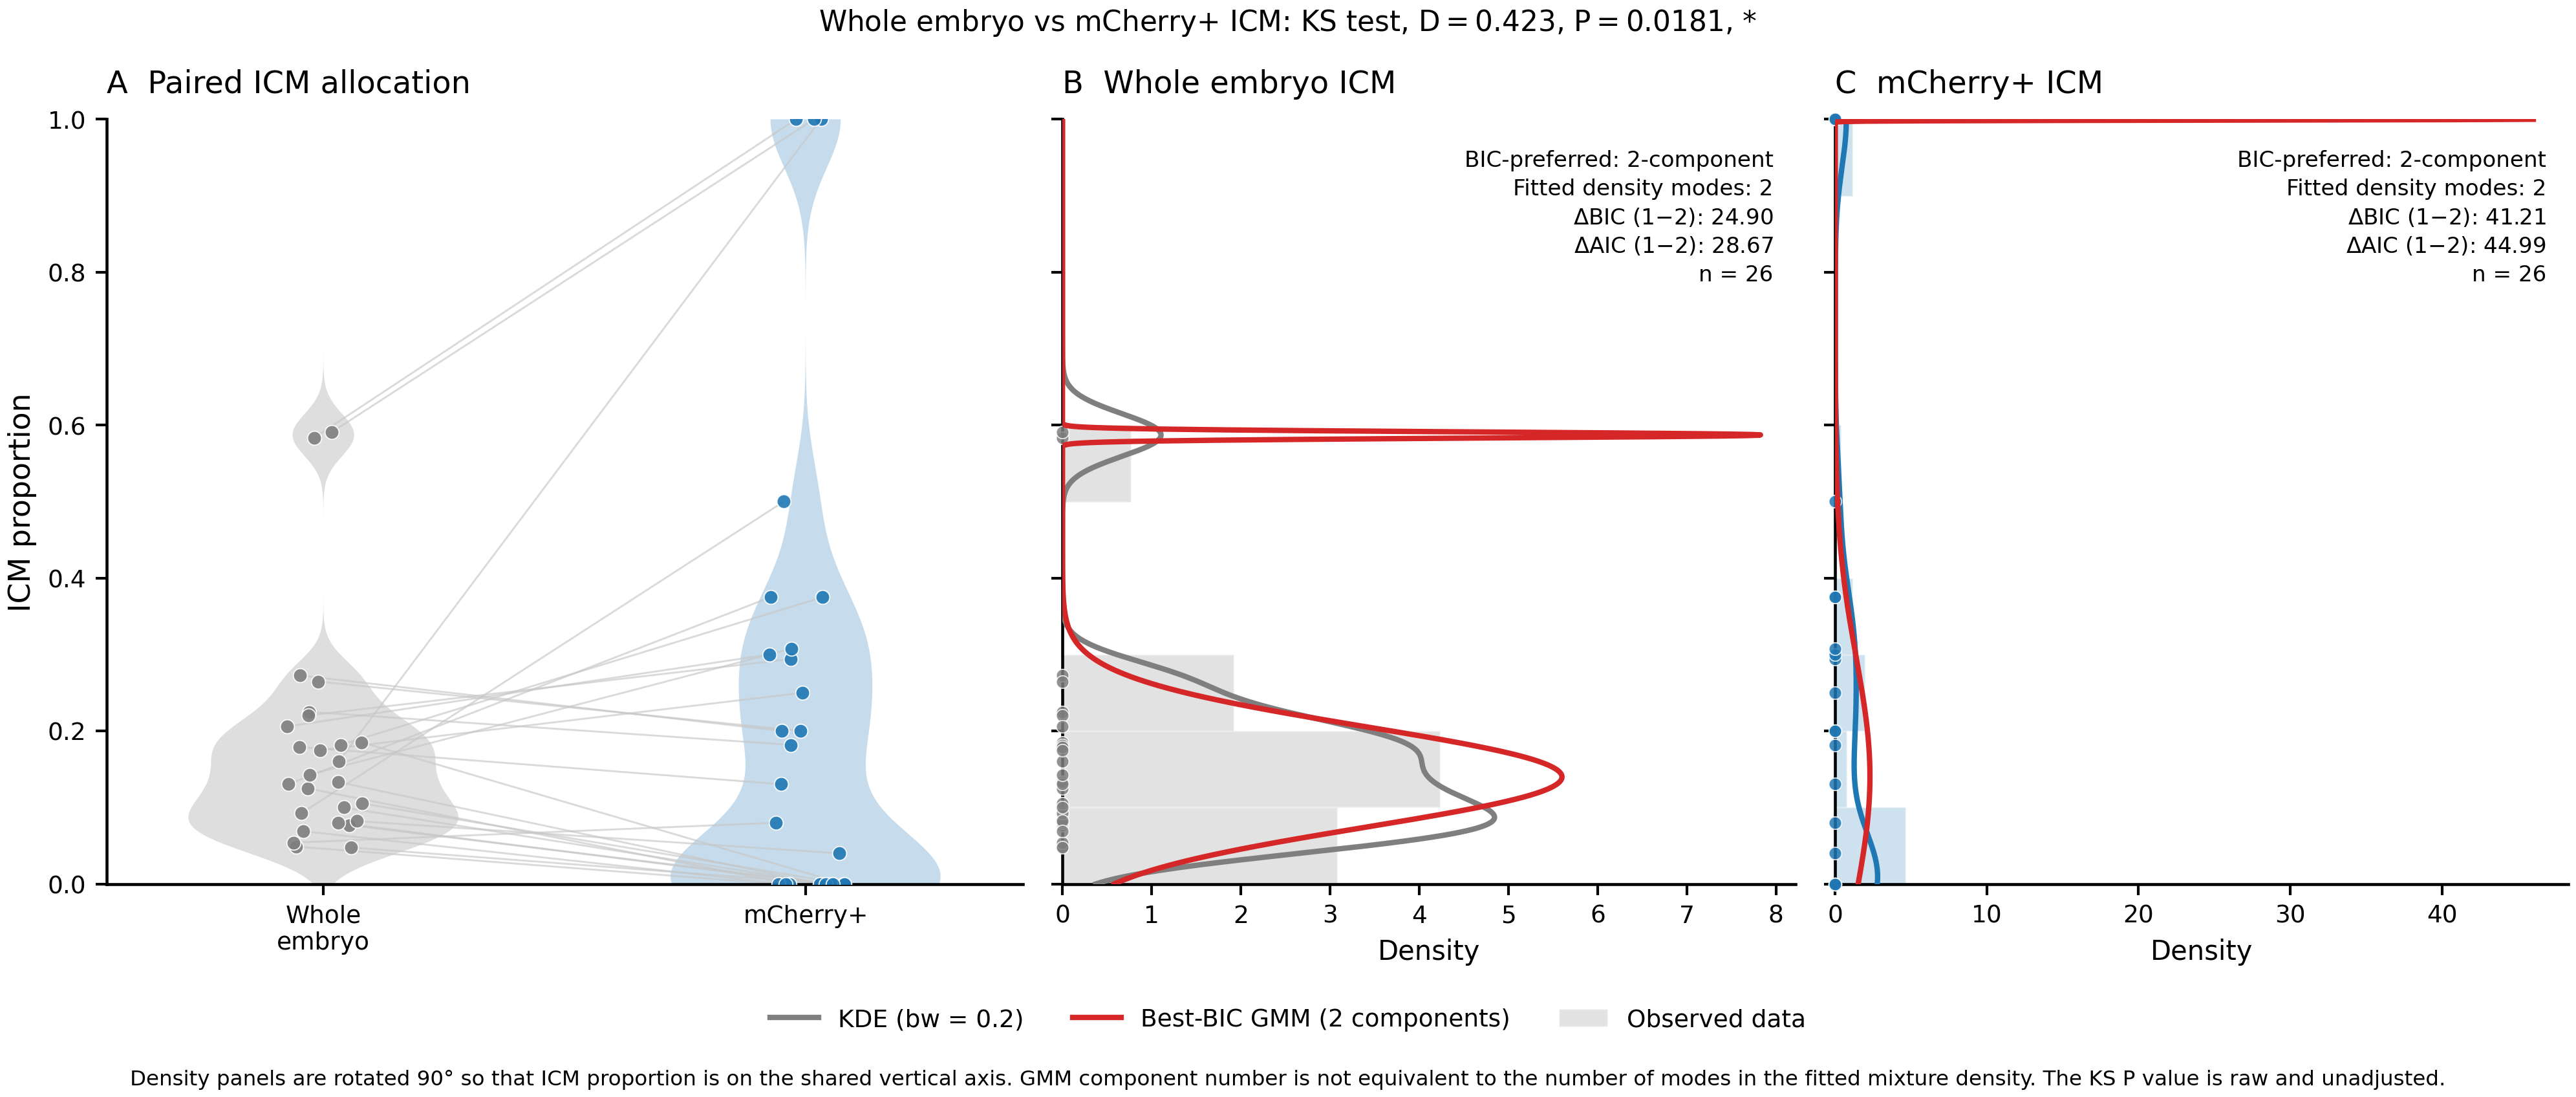


Figure saved:
  WT_ICM_integrated.svg
  WT_ICM_integrated.pdf

Total run time: 7.2 s

Analysis completed.
Embryos with SOX2 = 0 were excluded.
The figure displays ICM only.
KS P value shown on the figure is the original, unadjusted P value.
TrE statistics are retained in the output files but are not plotted.


In [75]:
# ============================================================
# WT embryo lineage allocation
# Actual vs mCherry+
#
# Analysis:
#   - Remove embryos with SOX2 = 0
#   - Hartigan dip test
#   - Silverman critical-bandwidth tests
#   - GMM model comparison
#   - KDE peak-count sensitivity analysis
#   - Paired distribution permutation test
#   - Paired mean-difference sign-flip test
#   - Two-sample KS test (raw P values)
#
# Plot (integrated single figure, 1 x 3, shared y axis):
#   A. Paired embryo lines + individual points + KDE violins
#   B. Whole embryo ICM: histogram + KDE + best-BIC GMM (vertical)
#   C. mCherry+ ICM:   histogram + KDE + best-BIC GMM (vertical)
#
# Outputs:
#   - Statistical result TXT files
#   - Integrated SVG and PDF figure
# ============================================================

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import (
    gaussian_kde,
    ks_2samp,
)
from scipy.signal import find_peaks
from sklearn.mixture import GaussianMixture

try:
    from diptest import diptest
except ImportError:
    raise ImportError("Install diptest: pip install diptest")


# ============================================================
# 0. Parameters
# ============================================================

input_file = "red_icm_te_count.txt"

RANDOM_SEED = 12345
N_PERMUTATIONS = 20000

N_SILVERMAN_BOOTSTRAP = 100
SILVERMAN_GRIDSIZE = 300
SILVERMAN_GRID = np.linspace(0.0, 1.0, SILVERMAN_GRIDSIZE)
SILVERMAN_MAX_ITER = 20

KDE_BANDWIDTHS = [0.1, 0.2, 0.3, 0.5]
KDE_GRIDSIZE = 1000
PEAK_PROMINENCE_FRACTION = 0.05

GMM_N_INIT = 20

rng = np.random.default_rng(RANDOM_SEED)
t_start = time.time()


# ============================================================
# 1. Plot settings
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "svg.hashsalt": "hello",
    "axes.linewidth": 1.1,
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "mathtext.fontset": "dejavusans",
})


# ============================================================
# 2. Read and validate input
# ============================================================

df = pd.read_csv(input_file, sep="\t")

required_cols = [
    "treatment", "编号",
    "mCherry-ICM", "mCherry-TE",
    "SOX2", "GATA3"
]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

df = df[
    df["treatment"].astype(str).str.strip().str.upper() == "WT"
].copy().reset_index(drop=True)

if len(df) == 0:
    raise ValueError("No WT embryos found.")

print(f"Number of WT embryos before filtering: {len(df)}")

count_cols = ["mCherry-ICM", "mCherry-TE", "SOX2", "GATA3"]

for col in count_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if df[count_cols].isna().any().any():
    raise ValueError("Missing or non-numeric cell counts detected.")

if (df[count_cols] < 0).any().any():
    raise ValueError("Negative cell counts detected.")

for col in count_cols:
    if not np.allclose(df[col], np.round(df[col])):
        raise ValueError(f"Non-integer counts detected in {col}")
    df[col] = df[col].astype(int)


# ============================================================
# 2b. Remove embryos with SOX2 = 0
# ============================================================

n_before = len(df)
sox2_zero_mask = df["SOX2"] == 0

print(
    f"Embryos with SOX2 = 0 removed: "
    f"{int(sox2_zero_mask.sum())}"
)

df = df[~sox2_zero_mask].copy().reset_index(drop=True)

print(
    f"Number of WT embryos after filtering: {len(df)} "
    f"(removed {n_before - len(df)})"
)

if len(df) == 0:
    raise ValueError("No embryos left after filtering.")


# ============================================================
# 3. Calculate lineage proportions
# ============================================================

df["actual_total"] = df["SOX2"] + df["GATA3"]
df["mCherry_pos_total"] = df["mCherry-ICM"] + df["mCherry-TE"]

df["actual_ICM_prop"] = np.where(
    df["actual_total"] > 0,
    df["SOX2"] / df["actual_total"],
    np.nan
)

df["actual_TrE_prop"] = np.where(
    df["actual_total"] > 0,
    df["GATA3"] / df["actual_total"],
    np.nan
)

df["mCherry_pos_ICM_prop"] = np.where(
    df["mCherry_pos_total"] > 0,
    df["mCherry-ICM"] / df["mCherry_pos_total"],
    np.nan
)

df["mCherry_pos_TrE_prop"] = np.where(
    df["mCherry_pos_total"] > 0,
    df["mCherry-TE"] / df["mCherry_pos_total"],
    np.nan
)


# ============================================================
# 4. BH correction helper (used for dip-test results only)
# ============================================================

def bh_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(p_values.shape, np.nan)

    valid_idx = np.where(np.isfinite(p_values))[0]
    if len(valid_idx) == 0:
        return adjusted

    p = p_values[valid_idx]
    order = np.argsort(p)
    sorted_p = p[order]
    m = len(sorted_p)

    sorted_q = sorted_p * m / np.arange(1, m + 1)
    sorted_q = np.minimum.accumulate(sorted_q[::-1])[::-1]
    sorted_q = np.clip(sorted_q, 0, 1)

    q_orig = np.empty(m)
    q_orig[order] = sorted_q
    adjusted[valid_idx] = q_orig

    return adjusted


# ============================================================
# 5. Hartigan dip test
# ============================================================

def run_dip_test(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "dip_statistic": np.nan,
        "dip_pvalue": np.nan
    }

    if len(x) >= 3 and np.unique(x).size >= 2:
        dip_stat, p_value = diptest(x)
        result["dip_statistic"] = float(dip_stat)
        result["dip_pvalue"] = float(p_value)

    return result


# ============================================================
# 6. Silverman critical-bandwidth test
# ============================================================

def _count_modes_fast(grid_minus_x, sd, h):
    bw = h * sd
    if bw <= 0:
        return 0

    z = grid_minus_x / bw
    density = np.exp(-0.5 * z * z).sum(axis=1)
    peaks, _ = find_peaks(density)

    return len(peaks)


def silverman_critical_bandwidth(
    x,
    k=1,
    grid=SILVERMAN_GRID,
    max_iter=SILVERMAN_MAX_ITER
):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)

    if n < 3 or np.unique(x).size < 3:
        return np.nan

    sd = float(np.std(x, ddof=1))
    if sd <= 0:
        return np.nan

    grid_minus_x = grid[:, None] - x[None, :]

    lo, hi = 1e-5, 5.0

    if _count_modes_fast(grid_minus_x, sd, hi) > k:
        return np.nan

    for _ in range(max_iter):
        mid = 0.5 * (lo + hi)

        if _count_modes_fast(grid_minus_x, sd, mid) <= k:
            hi = mid
        else:
            lo = mid

        if hi - lo < 1e-5:
            break

    return hi


def silverman_test(
    x,
    k=1,
    n_boot=N_SILVERMAN_BOOTSTRAP,
    grid=SILVERMAN_GRID
):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)

    result = {
        "k_null": k,
        "h_crit": np.nan,
        "silverman_pvalue": np.nan
    }

    if n < 10 or np.unique(x).size < 3:
        return result

    h_crit = silverman_critical_bandwidth(x, k=k, grid=grid)

    if not np.isfinite(h_crit):
        return result

    result["h_crit"] = float(h_crit)

    sd_x = float(np.std(x, ddof=1))
    if sd_x <= 0:
        return result

    idx = rng.integers(0, n, size=(n_boot, n))
    noise = rng.normal(0.0, h_crit * sd_x, size=(n_boot, n))
    boot = x[idx] + noise

    exceed = 0

    for b in range(n_boot):
        h_b = silverman_critical_bandwidth(
            boot[b], k=k, grid=grid
        )

        if np.isfinite(h_b) and h_b > h_crit:
            exceed += 1

    result["silverman_pvalue"] = (
        exceed + 1
    ) / (n_boot + 1)

    return result


# ============================================================
# 7. GMM comparison
# ============================================================

def run_gmm_comparison(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "BIC_1_component": np.nan,
        "BIC_2_components": np.nan,
        "delta_BIC_1_minus_2": np.nan,
        "preferred_by_BIC": "NA",
        "GMM_2_component_means": "NA",
        "GMM_2_component_weights": "NA",
    }

    if len(x) < 5 or np.unique(x).size < 2:
        return result

    X = x.reshape(-1, 1)

    try:
        model1 = GaussianMixture(
            n_components=1,
            covariance_type="full",
            n_init=GMM_N_INIT,
            random_state=RANDOM_SEED,
            reg_covar=1e-6,
        )

        model2 = GaussianMixture(
            n_components=2,
            covariance_type="full",
            n_init=GMM_N_INIT,
            random_state=RANDOM_SEED,
            reg_covar=1e-6,
        )

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model1.fit(X)
            model2.fit(X)

        bic1 = float(model1.bic(X))
        bic2 = float(model2.bic(X))

        result["BIC_1_component"] = bic1
        result["BIC_2_components"] = bic2
        result["delta_BIC_1_minus_2"] = bic1 - bic2

        if bic2 < bic1:
            result["preferred_by_BIC"] = "2 components"
        elif bic1 < bic2:
            result["preferred_by_BIC"] = "1 component"
        else:
            result["preferred_by_BIC"] = "Tie"

        result["GMM_2_component_means"] = ",".join(
            f"{v:.6g}" for v in np.sort(model2.means_.ravel())
        )

        result["GMM_2_component_weights"] = ",".join(
            f"{v:.6g}" for v in model2.weights_
        )

    except (ValueError, np.linalg.LinAlgError) as exc:
        print(f"Warning: GMM fitting failed: {exc}")

    return result


# ============================================================
# 8. KDE peak count
# ============================================================

def count_kde_peaks(values, bw_factor):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    result = {
        "n": len(x),
        "bandwidth_factor": bw_factor,
        "n_KDE_peaks": np.nan,
        "peak_locations": "NA",
    }

    if len(x) < 3 or np.unique(x).size < 2:
        return result

    try:
        kde = gaussian_kde(x, bw_method=bw_factor)
        grid = np.linspace(0, 1, KDE_GRIDSIZE)
        density = kde(grid)

        if not np.isfinite(density).all() or density.max() <= 0:
            return result

        prominence = density.max() * PEAK_PROMINENCE_FRACTION
        peak_indices, _ = find_peaks(
            density, prominence=prominence
        )

        result["n_KDE_peaks"] = int(len(peak_indices))
        result["peak_locations"] = ",".join(
            f"{grid[i]:.4f}" for i in peak_indices
        )

    except (ValueError, np.linalg.LinAlgError) as exc:
        print(f"Warning: KDE peak analysis failed: {exc}")

    return result


# ============================================================
# 9. Paired distribution permutation test
# ============================================================

def paired_distribution_permutation(
    actual,
    positive,
    n_permutations=N_PERMUTATIONS
):
    actual = np.asarray(actual, dtype=float)
    positive = np.asarray(positive, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(positive)
    a = actual[valid]
    b = positive[valid]
    n = len(a)

    result = {
        "n_paired": n,
        "Wasserstein_distance": np.nan,
        "distribution_permutation_pvalue": np.nan,
    }

    if n < 2:
        return result

    observed = float(
        np.mean(np.abs(np.sort(a) - np.sort(b)))
    )

    swaps = rng.random((n_permutations, n)) < 0.5
    perm_a = np.where(swaps, b, a)
    perm_b = np.where(swaps, a, b)

    perm_a.sort(axis=1)
    perm_b.sort(axis=1)

    perm_stats = np.mean(
        np.abs(perm_a - perm_b), axis=1
    )

    exceed = int(
        np.sum(perm_stats >= observed - 1e-12)
    )

    result["Wasserstein_distance"] = observed
    result["distribution_permutation_pvalue"] = (
        exceed + 1
    ) / (n_permutations + 1)

    return result


# ============================================================
# 10. Paired mean-difference sign-flip test
# ============================================================

def paired_mean_signflip_test(
    actual,
    positive,
    n_permutations=N_PERMUTATIONS
):
    actual = np.asarray(actual, dtype=float)
    positive = np.asarray(positive, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(positive)
    a = actual[valid]
    b = positive[valid]

    d = b - a
    n = len(d)

    result = {
        "n_paired": n,
        "mean_paired_difference_pp": np.nan,
        "median_paired_difference_pp": np.nan,
        "paired_mean_signflip_pvalue": np.nan,
    }

    if n < 2:
        return result

    observed = abs(np.mean(d))

    signs = rng.choice(
        [-1.0, 1.0],
        size=(n_permutations, n)
    )

    perm_means = np.abs(
        np.mean(signs * d, axis=1)
    )

    p_value = (
        np.sum(perm_means >= observed - 1e-12) + 1
    ) / (n_permutations + 1)

    result["mean_paired_difference_pp"] = float(
        np.mean(d) * 100
    )

    result["median_paired_difference_pp"] = float(
        np.median(d) * 100
    )

    result["paired_mean_signflip_pvalue"] = float(p_value)

    return result


# ============================================================
# 10b. Two-sample KS test
# ============================================================

def ks_test(actual, positive):
    """
    Two-sample KS test on marginal distributions.
    P value is unadjusted.
    """
    actual = np.asarray(actual, dtype=float)
    positive = np.asarray(positive, dtype=float)

    a = actual[np.isfinite(actual)]
    b = positive[np.isfinite(positive)]

    result = {
        "n_KS_a": len(a),
        "n_KS_b": len(b),
        "KS_statistic": np.nan,
        "KS_pvalue": np.nan,
    }

    if len(a) < 2 or len(b) < 2:
        return result

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            stat, p = ks_2samp(
                a, b, alternative="two-sided", method="auto"
            )

        result["KS_statistic"] = float(stat)
        result["KS_pvalue"] = float(p)

    except ValueError as exc:
        print(f"Warning: KS test failed: {exc}")

    return result


# ============================================================
# 11. Run analyses: retain ICM and TrE statistics
# ============================================================

lineage_specs = {
    "ICM": {
        "actual": "actual_ICM_prop",
        "positive": "mCherry_pos_ICM_prop",
    },
    "TrE": {
        "actual": "actual_TrE_prop",
        "positive": "mCherry_pos_TrE_prop",
    },
}

distribution_results = []
gmm_results = []
kde_results = []
comparison_results = []
multimodality_results = []

for lineage, spec in lineage_specs.items():

    for group_name, col in [
        ("Whole embryo", spec["actual"]),
        ("mCherry+", spec["positive"]),
    ]:

        values = df[col].to_numpy(dtype=float)
        values = values[np.isfinite(values)]

        summary = {
            "Lineage": lineage,
            "Group": group_name,
            "n": len(values),
            "Mean_proportion": (
                float(np.mean(values)) if len(values) else np.nan
            ),
            "SD_proportion": (
                float(np.std(values, ddof=1))
                if len(values) > 1 else np.nan
            ),
            "Median_proportion": (
                float(np.median(values)) if len(values) else np.nan
            ),
            "Q1_proportion": (
                float(np.percentile(values, 25))
                if len(values) else np.nan
            ),
            "Q3_proportion": (
                float(np.percentile(values, 75))
                if len(values) else np.nan
            ),
        }

        dip = run_dip_test(values)
        summary.update(dip)

        t0 = time.time()

        silver_k1 = silverman_test(
            values, k=1, n_boot=N_SILVERMAN_BOOTSTRAP
        )

        silver_k2 = silverman_test(
            values, k=2, n_boot=N_SILVERMAN_BOOTSTRAP
        )

        t_silver = time.time() - t0

        summary["Silverman_k1_h_crit"] = silver_k1["h_crit"]
        summary["Silverman_k1_pvalue"] = silver_k1["silverman_pvalue"]
        summary["Silverman_k2_h_crit"] = silver_k2["h_crit"]
        summary["Silverman_k2_pvalue"] = silver_k2["silverman_pvalue"]

        distribution_results.append(summary)

        multimodality_results.append({
            "Lineage": lineage,
            "Group": group_name,
            "n": len(values),
            "Hartigan_dip_pvalue": dip["dip_pvalue"],
            "Silverman_k1_h_crit": silver_k1["h_crit"],
            "Silverman_k1_pvalue": silver_k1["silverman_pvalue"],
            "Silverman_k2_h_crit": silver_k2["h_crit"],
            "Silverman_k2_pvalue": silver_k2["silverman_pvalue"],
        })

        gmm = run_gmm_comparison(values)
        gmm["Lineage"] = lineage
        gmm["Group"] = group_name
        gmm_results.append(gmm)

        for bw in KDE_BANDWIDTHS:
            peak_result = count_kde_peaks(values, bw)
            peak_result["Lineage"] = lineage
            peak_result["Group"] = group_name
            kde_results.append(peak_result)

        print(
            f"[{lineage} | {group_name}] done "
            f"(Silverman: {t_silver:.1f}s)"
        )

    actual = df[spec["actual"]].to_numpy(dtype=float)
    positive = df[spec["positive"]].to_numpy(dtype=float)

    dist_test = paired_distribution_permutation(
        actual, positive,
        n_permutations=N_PERMUTATIONS
    )

    mean_test = paired_mean_signflip_test(
        actual, positive,
        n_permutations=N_PERMUTATIONS
    )

    ks = ks_test(actual, positive)

    comparison_results.append({
        "Lineage": lineage,
        **ks,
        **dist_test,
        **mean_test,
    })


# ============================================================
# 12. DataFrames and dip-test BH correction
# ============================================================

distribution_df = pd.DataFrame(distribution_results)

distribution_df["dip_BH_qvalue"] = bh_adjust(
    distribution_df["dip_pvalue"].to_numpy(dtype=float)
)

gmm_df = pd.DataFrame(gmm_results)
kde_df = pd.DataFrame(kde_results)
comparison_df = pd.DataFrame(comparison_results)
multimodality_df = pd.DataFrame(multimodality_results)


# ============================================================
# 13. Print distribution-shape statistics
# ============================================================

print("\n" + "=" * 80)
print("DISTRIBUTION SHAPE: DIP TEST, SILVERMAN TEST, GMM")
print("=" * 80)

for _, row in distribution_df.iterrows():

    print(f"\n{row['Lineage']} | {row['Group']} | n={row['n']}")

    print(f"  Mean proportion: {row['Mean_proportion']:.4f}")

    print(
        f"  Median (Q1-Q3): {row['Median_proportion']:.4f} "
        f"({row['Q1_proportion']:.4f}-"
        f"{row['Q3_proportion']:.4f})"
    )

    if np.isfinite(row["dip_pvalue"]):
        print(
            f"  Hartigan dip: stat={row['dip_statistic']:.5f}, "
            f"P={row['dip_pvalue']:.5g}, "
            f"BH q={row['dip_BH_qvalue']:.5g}"
        )
    else:
        print("  Hartigan dip: unavailable")

    for k in [1, 2]:
        p_col = f"Silverman_k{k}_pvalue"
        h_col = f"Silverman_k{k}_h_crit"

        if np.isfinite(row[p_col]):
            print(
                f"  Silverman k={k}: h_crit={row[h_col]:.5f}, "
                f"P={row[p_col]:.5g}"
            )
        else:
            print(f"  Silverman k={k}: unavailable")

    gmm_row = gmm_df[
        (gmm_df["Lineage"] == row["Lineage"]) &
        (gmm_df["Group"] == row["Group"])
    ].iloc[0]

    print(
        f"  GMM BIC: 1comp={gmm_row['BIC_1_component']:.3f}; "
        f"2comp={gmm_row['BIC_2_components']:.3f}"
    )

    print(f"  Preferred by BIC: {gmm_row['preferred_by_BIC']}")


# ============================================================
# 14. Print KDE peak-count sensitivity
# ============================================================

print("\n" + "=" * 80)
print("KDE PEAK COUNT SENSITIVITY")
print("=" * 80)

for _, row in kde_df.iterrows():
    print(
        f"{row['Lineage']:>4} | {row['Group']:>9} | "
        f"bw={row['bandwidth_factor']:<4} | "
        f"n_peaks={row['n_KDE_peaks']} | "
        f"locations={row['peak_locations']}"
    )


# ============================================================
# 15. Print Actual vs mCherry+ comparisons
# ============================================================

print("\n" + "=" * 80)
print("Whole embryo vs mCherry+ COMPARISONS")
print("=" * 80)

for _, row in comparison_df.iterrows():

    print(f"\n{row['Lineage']}")
    print(f"  Paired embryos: {row['n_paired']}")

    if np.isfinite(row["KS_pvalue"]):
        print(
            f"  KS test: D={row['KS_statistic']:.4f}, "
            f"P={row['KS_pvalue']:.8g} "
            f"(n_a={row['n_KS_a']}, n_b={row['n_KS_b']})"
        )
    else:
        print("  KS test: unavailable")

    print(
        f"  Wasserstein distance: "
        f"{row['Wasserstein_distance']:.5f}"
    )

    print(
        f"  Paired label-swap permutation P: "
        f"{row['distribution_permutation_pvalue']:.5g}"
    )

    print(
        f"  Mean paired difference (mCherry+ - Actual): "
        f"{row['mean_paired_difference_pp']:.3f} pp"
    )

    print(
        f"  Median paired difference: "
        f"{row['median_paired_difference_pp']:.3f} pp"
    )

    print(
        f"  Paired mean sign-flip P: "
        f"{row['paired_mean_signflip_pvalue']:.5g}"
    )


# ============================================================
# 16. Save statistical results
# ============================================================

files = {
    "distribution": "WT_lineage_distribution_statistics.txt",
    "comparison": "WT_lineage_distribution_comparison.txt",
    "gmm": "WT_lineage_GMM_BIC_comparison.txt",
    "kde": "WT_lineage_KDE_peak_sensitivity.txt",
    "multimodality": "WT_lineage_multimodality_tests.txt",
}

distribution_df.to_csv(
    files["distribution"], sep="\t",
    index=False, float_format="%.8g"
)

comparison_df.to_csv(
    files["comparison"], sep="\t",
    index=False, float_format="%.8g"
)

gmm_df.to_csv(
    files["gmm"], sep="\t",
    index=False, float_format="%.8g"
)

kde_df.to_csv(
    files["kde"], sep="\t",
    index=False, float_format="%.8g"
)

multimodality_df.to_csv(
    files["multimodality"], sep="\t",
    index=False, float_format="%.8g"
)

print("\nStatistics saved:")
for filename in files.values():
    print(f"  {filename}")


# ============================================================
# 17. Integrated ICM figure (A: paired violin/scatter;
#     B/C: vertical histogram + KDE + best-BIC GMM)
# ============================================================

COLORS = {
    "actual":   "#7F7F7F",
    "positive": "#1F77B4",
    "gmm":      "#D62728",
    "line":     "#C7C7C7",
}

# ------------------------------------------------------------
# 17a. Prepare paired data (proportions in [0, 1])
# ------------------------------------------------------------

actual_frac   = df["actual_ICM_prop"].to_numpy(dtype=float)
positive_frac = df["mCherry_pos_ICM_prop"].to_numpy(dtype=float)

valid = np.isfinite(actual_frac) & np.isfinite(positive_frac)
actual_frac   = actual_frac[valid]
positive_frac = positive_frac[valid]

n_paired = len(actual_frac)

print("\n" + "=" * 72)
print("ICM INTEGRATED FIGURE")
print("=" * 72)
print(f"Paired embryos plotted: {n_paired}")


# ------------------------------------------------------------
# 17b. Raw, two-sided KS test (unadjusted P value)
# ------------------------------------------------------------

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ks_d, ks_p = ks_2samp(
        actual_frac, positive_frac,
        alternative="two-sided", method="auto"
    )


def format_p_value_math(p):
    if not np.isfinite(p):
        return r"$P = \mathrm{NA}$"
    if p == 0:
        return r"$P < 10^{-300}$"
    if p < 0.001 or p >= 0.9995:
        exponent = int(np.floor(np.log10(p)))
        coefficient = p / (10.0 ** exponent)
        return rf"$P = {coefficient:.2f} \times 10^{{{exponent}}}$"
    return rf"$P = {p:.4f}$"


if ks_p < 0.001:
    significance = "***"
elif ks_p < 0.01:
    significance = "**"
elif ks_p < 0.05:
    significance = "*"
else:
    significance = "ns"

p_label = format_p_value_math(ks_p)

print("KS test: Whole embryo vs mCherry+ ICM")
print(f"  D = {ks_d:.6f}")
print(f"  Raw P = {ks_p:.10g}")
print(f"  Significance = {significance}")


# ------------------------------------------------------------
# 17c. GMM fitting (1- vs 2-component, BIC selection)
# ------------------------------------------------------------

def fit_gmm_models(values, random_state=RANDOM_SEED):
    """
    Fit 1- and 2-component GMMs.
    Select the model with the lower BIC.
    Count modes of the selected mixture density.
    """
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    if len(x) < 5 or np.unique(x).size < 2:
        return {
            "gmm1": None, "gmm2": None,
            "best_model": None, "best_n": np.nan,
            "grid": None, "best_density": None, "n_modes": np.nan,
        }

    X = x.reshape(-1, 1)

    model1 = GaussianMixture(
        n_components=1, covariance_type="full",
        n_init=GMM_N_INIT, random_state=random_state,
        reg_covar=1e-6,
    )
    model2 = GaussianMixture(
        n_components=2, covariance_type="full",
        n_init=GMM_N_INIT, random_state=random_state,
        reg_covar=1e-6,
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model1.fit(X)
        model2.fit(X)

    bic1 = float(model1.bic(X))
    bic2 = float(model2.bic(X))
    aic1 = float(model1.aic(X))
    aic2 = float(model2.aic(X))

    if bic2 < bic1:
        best_model, best_n = model2, 2
    else:
        best_model, best_n = model1, 1

    grid = np.linspace(0, 1, 2000)
    best_density = np.exp(best_model.score_samples(grid.reshape(-1, 1)))

    peaks, _ = find_peaks(best_density)
    if len(best_density) >= 2 and best_density[0] > best_density[1]:
        peaks = np.append(peaks, 0)
    if len(best_density) >= 2 and best_density[-1] > best_density[-2]:
        peaks = np.append(peaks, len(best_density) - 1)
    n_modes = len(np.unique(peaks))

    return {
        "gmm1": {"model": model1, "BIC": bic1, "AIC": aic1},
        "gmm2": {"model": model2, "BIC": bic2, "AIC": aic2},
        "best_model": best_model, "best_n": best_n,
        "grid": grid, "best_density": best_density, "n_modes": n_modes,
    }


actual_gmm   = fit_gmm_models(actual_frac)
positive_gmm = fit_gmm_models(positive_frac)

for name, result in [("Whole embryo", actual_gmm),
                     ("mCherry+", positive_gmm)]:
    print(f"\n{name} GMM")
    if result["best_model"] is None:
        print("  GMM unavailable")
        continue
    print(f"  1-component BIC: {result['gmm1']['BIC']:.3f}")
    print(f"  2-component BIC: {result['gmm2']['BIC']:.3f}")
    print(f"  Preferred by BIC: {result['best_n']}-component")
    print(f"  Modes in selected mixture density: {result['n_modes']}")


# ------------------------------------------------------------
# 17d. Vertical density panel helper
# ------------------------------------------------------------

def plot_vertical_density(ax, values, color, title, gmm_result):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    # Histogram (rotated 90 degrees)
    counts, edges = np.histogram(
        values, bins=10, range=(0, 1), density=True
    )
    centers = (edges[:-1] + edges[1:]) / 2
    widths  = np.diff(edges)

    ax.barh(
        centers, counts,
        height=widths,
        color=color, alpha=0.22,
        edgecolor="white", linewidth=0.8,
        zorder=1,
        label="Observed data",
    )

    # KDE (vertical)
    grid_y = np.linspace(0, 1, 2000)
    if len(values) >= 2 and np.unique(values).size >= 2:
        try:
            kde = gaussian_kde(values, bw_method=0.2)
            dens = kde(grid_y)
            ax.plot(
                dens, grid_y,
                color=color, linewidth=2.0,
                label="KDE (bw = 0.2)",
                zorder=3,
            )
        except (ValueError, np.linalg.LinAlgError) as exc:
            print(f"Warning: KDE failed for {title}: {exc}")

    # Baseline rug
    ax.scatter(
        np.zeros_like(values), values,
        s=22, color=color,
        edgecolor="white", linewidth=0.4,
        alpha=0.85, zorder=4, clip_on=False,
    )

    # Best-BIC GMM density (vertical)
    if gmm_result is not None and gmm_result["best_model"] is not None:
        best_n  = gmm_result["best_n"]
        n_modes = gmm_result["n_modes"]
        delta_bic = gmm_result["gmm1"]["BIC"] - gmm_result["gmm2"]["BIC"]
        delta_aic = gmm_result["gmm1"]["AIC"] - gmm_result["gmm2"]["AIC"]

        ax.plot(
            gmm_result["best_density"],
            gmm_result["grid"],
            color=COLORS["gmm"], linewidth=2.0,
            label=(
                f"Best-BIC GMM "
                f"({best_n} component{'' if best_n == 1 else 's'})"
            ),
            zorder=5,
        )

        info_text = (
            f"BIC-preferred: {best_n}-component\n"
            f"Fitted density modes: {n_modes}\n"
            f"$\\Delta$BIC (1$-$2): {delta_bic:.2f}\n"
            f"$\\Delta$AIC (1$-$2): {delta_aic:.2f}\n"
            f"n = {len(values)}"
        )
    else:
        info_text = f"GMM unavailable\nn = {len(values)}"

    ax.text(
        0.97, 0.96, info_text,
        transform=ax.transAxes,
        ha="right", va="top",
        fontsize=8.2, linespacing=1.4,
        bbox={"facecolor": "white", "edgecolor": "none",
              "alpha": 0.75, "pad": 2.5},
        zorder=10,
    )

    ax.set_xlabel("Density", fontsize=10)
    ax.set_title(title, loc="left", fontsize=11.5, pad=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)
    ax.tick_params(axis="both", labelsize=9)


# ------------------------------------------------------------
# 17e. Build integrated 1 x 3 figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(13.5, 5.5),
    sharey=True,
    gridspec_kw={"width_ratios": [1.25, 1.0, 1.0]},
)

ax_a, ax_b, ax_c = axes

# ----- Panel A: paired violin + scatter -----

positions = {"actual": 1.0, "positive": 2.0}
grid_y = np.linspace(0, 1, 500)

for name, vals, pos in [
    ("actual",   actual_frac,   1.0),
    ("positive", positive_frac, 2.0),
]:
    v = vals[np.isfinite(vals)]
    if len(v) >= 2 and np.unique(v).size >= 2:
        try:
            kde = gaussian_kde(v, bw_method=0.2)
            dens = kde(grid_y)
            if np.isfinite(dens).all() and dens.max() > 0:
                dens_scaled = dens / dens.max() * 0.28
                ax_a.fill_betweenx(
                    grid_y,
                    pos - dens_scaled, pos + dens_scaled,
                    facecolor=COLORS[name], edgecolor="none",
                    alpha=0.25, zorder=1,
                )
        except (ValueError, np.linalg.LinAlgError) as exc:
            print(f"Warning: KDE failed for panel A ({name}): {exc}")

jitter_rng = np.random.default_rng(RANDOM_SEED)
jitter = jitter_rng.uniform(-0.09, 0.09, size=len(actual_frac))

for i in range(len(actual_frac)):
    ya, yp = actual_frac[i], positive_frac[i]
    if not (np.isfinite(ya) and np.isfinite(yp)):
        continue

    x1 = 1.0 + jitter[i]
    x2 = 2.0 + jitter[i]

    ax_a.plot(
        [x1, x2], [ya, yp],
        color=COLORS["line"], linewidth=0.7,
        alpha=0.65, zorder=2,
    )
    ax_a.scatter(
        x1, ya, s=27,
        facecolor=COLORS["actual"],
        edgecolor="white", linewidth=0.45,
        alpha=0.9, zorder=3,
    )
    ax_a.scatter(
        x2, yp, s=27,
        facecolor=COLORS["positive"],
        edgecolor="white", linewidth=0.45,
        alpha=0.9, zorder=3,
    )

ax_a.set_xticks([1, 2])
ax_a.set_xticklabels(["Whole\nembryo", "mCherry+"], fontsize=9)
ax_a.set_xlim(0.55, 2.45)
ax_a.set_ylim(0, 1)
ax_a.set_ylabel("ICM proportion", fontsize=11)
ax_a.set_title("A  Paired ICM allocation",
               loc="left", fontsize=11.5, pad=10)
ax_a.spines["top"].set_visible(False)
ax_a.spines["right"].set_visible(False)
ax_a.grid(False)
ax_a.tick_params(axis="both", labelsize=9)

# ----- Panels B and C: vertical density + GMM -----

plot_vertical_density(
    ax_b, actual_frac,
    color=COLORS["actual"],
    title="B  Whole embryo ICM",
    gmm_result=actual_gmm,
)

plot_vertical_density(
    ax_c, positive_frac,
    color=COLORS["positive"],
    title="C  mCherry+ ICM",
    gmm_result=positive_gmm,
)


# ------------------------------------------------------------
# 17f. Common legend and KS annotation
# ------------------------------------------------------------

fig.text(
    0.5, 0.985,
    f"Whole embryo vs mCherry+ ICM: KS test, "
    f"$D = {ks_d:.3f}$, {p_label}, {significance}",
    ha="center", va="top", fontsize=10.5,
)

# Collect unique legend entries across B and C
legend_handles, legend_labels = [], []
for ax in (ax_b, ax_c):
    h, l = ax.get_legend_handles_labels()
    for hi, li in zip(h, l):
        if li not in legend_labels:
            legend_handles.append(hi)
            legend_labels.append(li)

fig.legend(
    legend_handles, legend_labels,
    loc="lower center", ncol=3,
    frameon=False, fontsize=9,
    bbox_to_anchor=(0.5, 0.005),
)

fig.text(
    0.5, -0.01,
    "Density panels are rotated 90° so that ICM proportion is on the "
    "shared vertical axis. GMM component number is not equivalent to the "
    "number of modes in the fitted mixture density. "
    "The KS P value is raw and unadjusted.",
    ha="center", va="top", fontsize=7.8,
)

fig.tight_layout(rect=[0, 0.06, 1, 0.955])


# ------------------------------------------------------------
# 17g. Save integrated figure
# ------------------------------------------------------------

svg_file = "WT_ICM_integrated.svg"
pdf_file = "WT_ICM_integrated.pdf"

fig.savefig(svg_file, format="svg",
            bbox_inches="tight", transparent=True)
fig.savefig(pdf_file, format="pdf",
            bbox_inches="tight", transparent=True)

plt.show()
plt.close(fig)


# ============================================================
# 18. Final summary
# ============================================================

print("\nFigure saved:")
print(f"  {svg_file}")
print(f"  {pdf_file}")

print(f"\nTotal run time: {time.time() - t_start:.1f} s")

print("\nAnalysis completed.")
print("Embryos with SOX2 = 0 were excluded.")
print("The figure displays ICM only.")
print("KS P value shown on the figure is the original, unadjusted P value.")
print("TrE statistics are retained in the output files but are not plotted.")

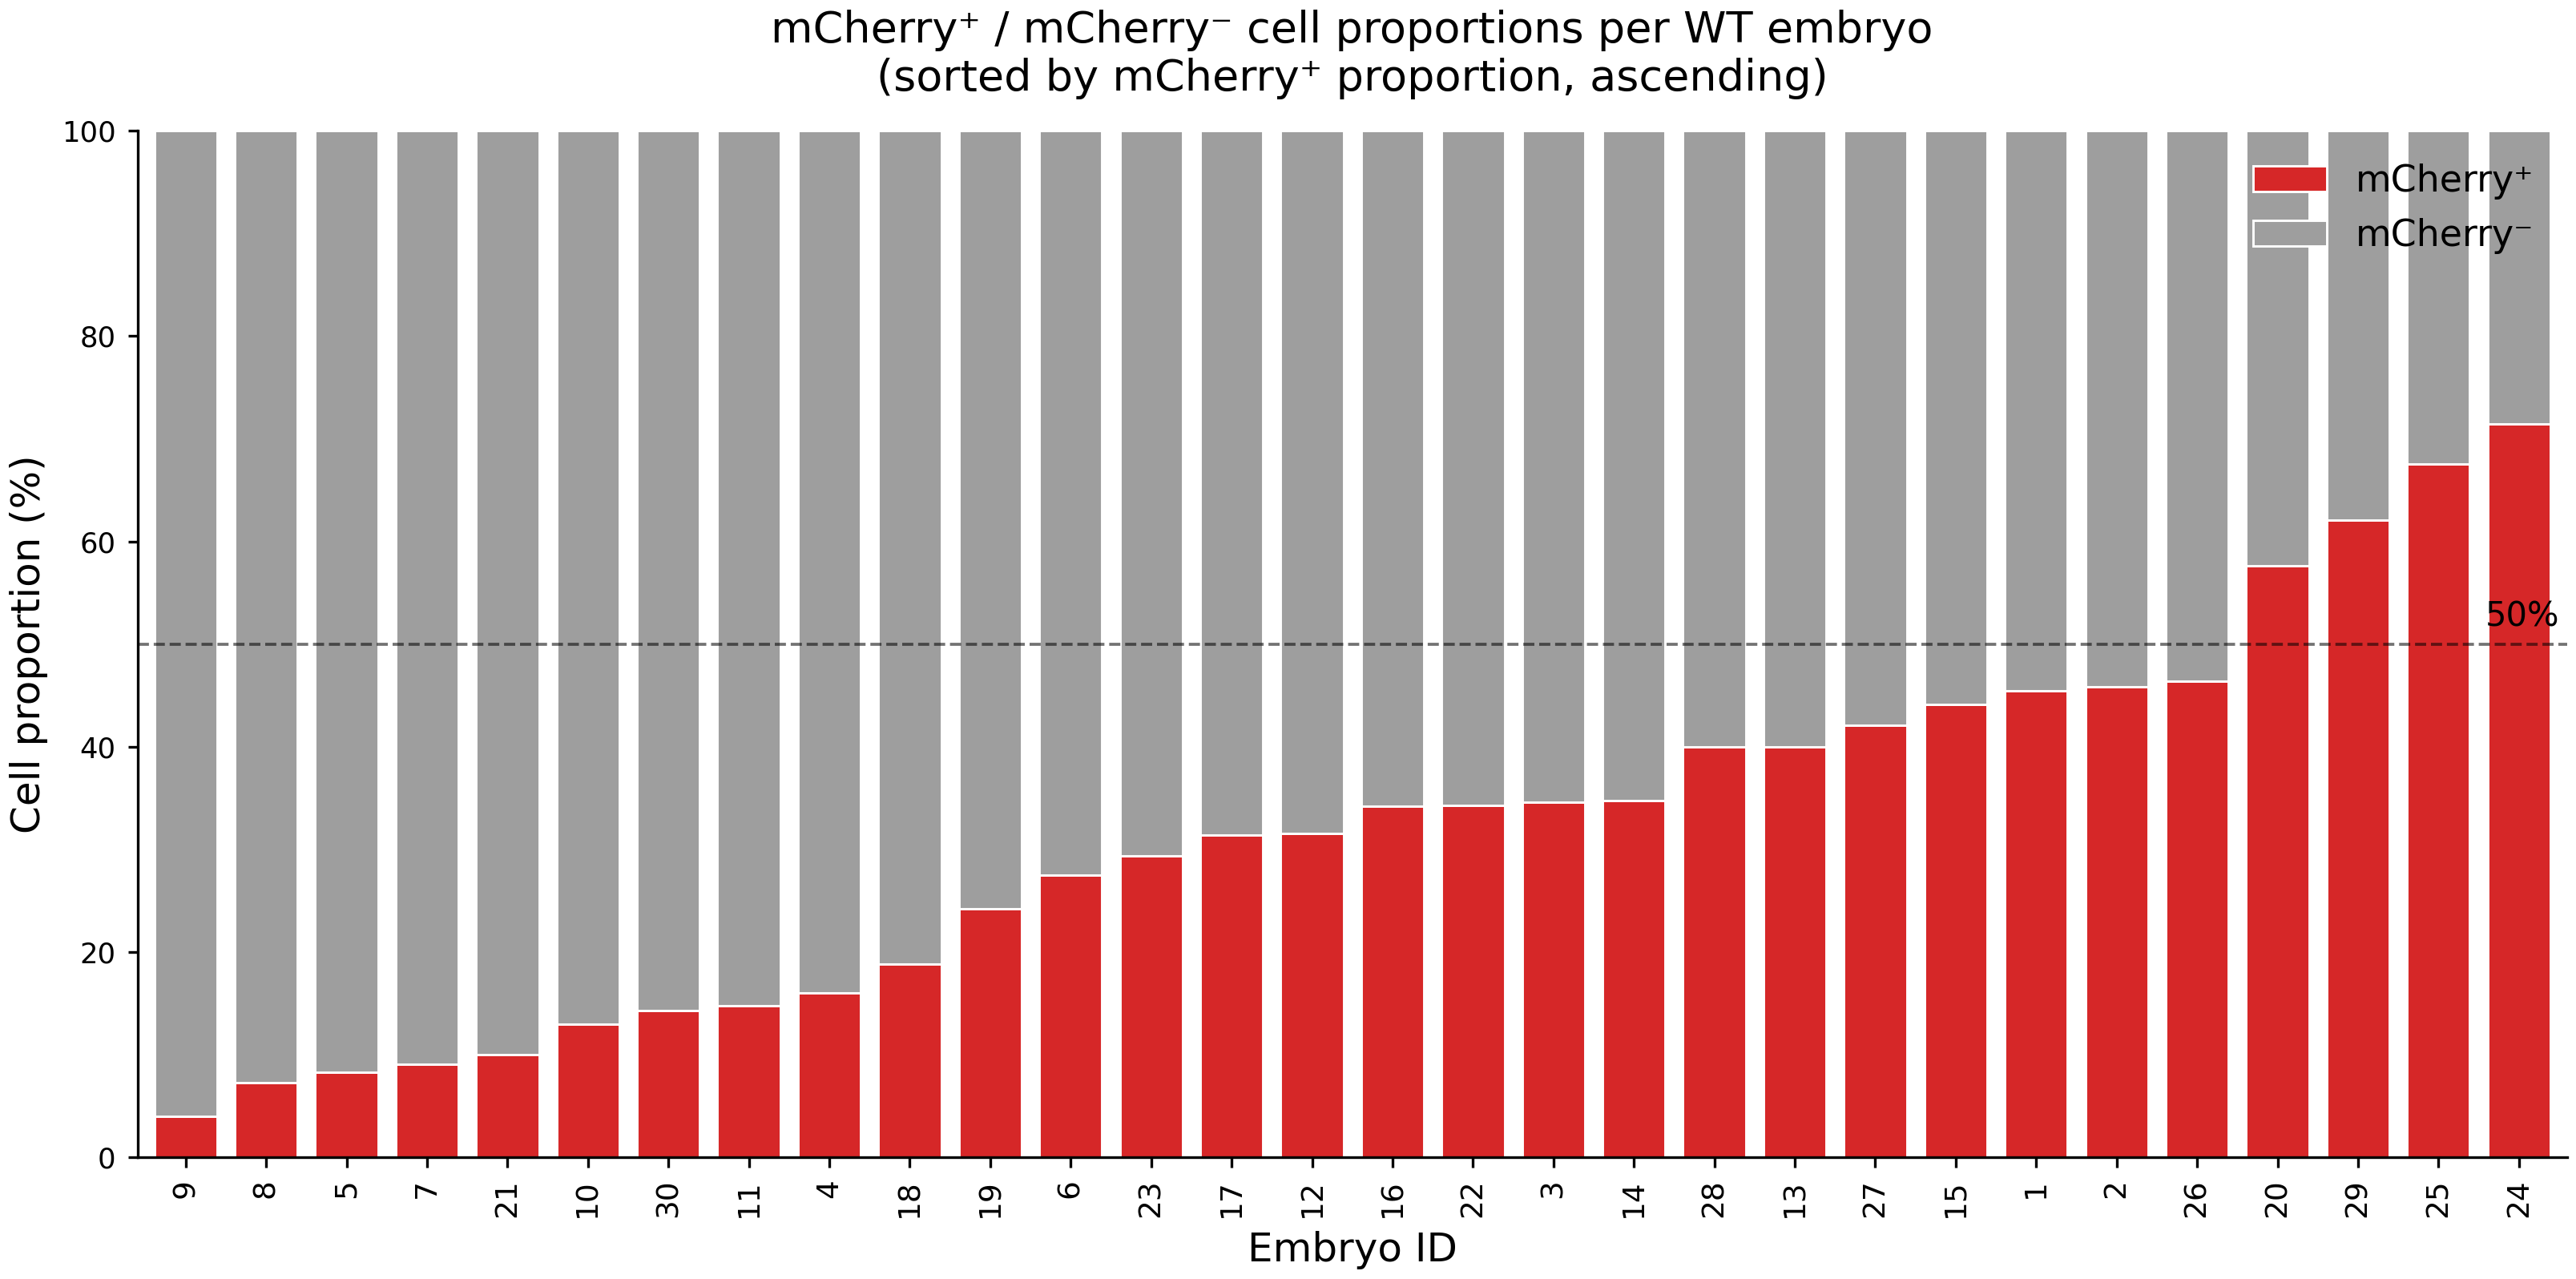


Figure saved: WT_mCherry_pos_neg_stacked_bars.svg / .pdf


In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Matplotlib settings
# ============================================================
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 12,
    'axes.titlesize': 13,
    'axes.labelsize': 13,
    'svg.fonttype': 'none',
    'svg.hashsalt': 'hello'
})

np.random.seed(123)

# ============================================================
# 2. Read data (WT only)
# ============================================================
df = pd.read_csv("red_icm_te_count.txt", sep="\t")
df = df[df["treatment"].astype(str).str.strip() == "WT"].copy()

required_cols = ["编号", "mCherry-ICM", "mCherry-TE", "SOX2", "GATA3"]
for col in required_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=required_cols).copy()

# ============================================================
# 3. Compute mCherry+ / mCherry- counts and percentages
# ============================================================
df["total_cells"]   = df["SOX2"] + df["GATA3"]
df["cherry_pos"]    = df["mCherry-ICM"] + df["mCherry-TE"]
df["cherry_neg"]    = df["total_cells"] - df["cherry_pos"]

df["cherry_pos_pct"] = np.where(
    df["total_cells"] > 0, df["cherry_pos"] / df["total_cells"] * 100, np.nan
)
df["cherry_neg_pct"] = np.where(
    df["total_cells"] > 0, df["cherry_neg"] / df["total_cells"] * 100, np.nan
)

# ============================================================
# 4. Sort embryos by mCherry+ percentage (ascending)
# ============================================================
df_sorted = df.sort_values("cherry_pos_pct", ascending=True).reset_index(drop=True)

x = np.arange(len(df_sorted))
embryo_labels = df_sorted["编号"].astype(str).tolist()

pos_pct = df_sorted["cherry_pos_pct"].values
neg_pct = df_sorted["cherry_neg_pct"].values

# ============================================================
# 5. Plot stacked bar chart
# ============================================================
fig, ax = plt.subplots(figsize=(11, 5.6))

bar_width = 0.78

# Bottom layer: mCherry+
ax.bar(
    x, pos_pct,
    width=bar_width,
    color="#D62728",
    edgecolor="white",
    linewidth=0.7,
    label="mCherry⁺"
)

# Top layer: mCherry- (stacked on top)
ax.bar(
    x, neg_pct,
    width=bar_width,
    bottom=pos_pct,
    color="#9E9E9E",
    edgecolor="white",
    linewidth=0.7,
    label="mCherry⁻"
)

# Reference line at 50%
ax.axhline(
    50, linestyle="--", linewidth=0.9,
    color="black", alpha=0.55, zorder=3
)
ax.text(
    len(x) - 0.5, 51, "50%",
    ha="right", va="bottom", fontsize=10, color="black"
)

# Axis
ax.set_xticks(x)
ax.set_xticklabels(embryo_labels, rotation=90, fontsize=9)
ax.set_xlabel("Embryo ID", fontsize=12)
ax.set_ylabel("Cell proportion (%)", fontsize=12)
ax.set_ylim(0, 100)
ax.set_xlim(-0.6, len(x) - 0.4)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Legend
ax.legend(
    loc="upper right",
    frameon=False,
    fontsize=11
)

# Title
ax.set_title(
    "mCherry⁺ / mCherry⁻ cell proportions per WT embryo\n"
    "(sorted by mCherry⁺ proportion, ascending)",
    pad=12
)

plt.tight_layout()

plt.savefig(
    "WT_mCherry_pos_neg_stacked_bars.svg",
    bbox_inches="tight", transparent=True
)
plt.savefig(
    "WT_mCherry_pos_neg_stacked_bars.pdf",
    bbox_inches="tight", transparent=True
)

plt.show()

print("\nFigure saved: WT_mCherry_pos_neg_stacked_bars.svg / .pdf")


Per-embryo exact binomial test results:
 编号  SOX2  ICM_mCherry_pos  ICM_mCherry_neg  ICM_mCherry_pos_pct  ICM_mCherry_neg_pct  ICM_binom_p ICM_significance  GATA3  TrE_mCherry_pos  TrE_mCherry_neg  TrE_mCherry_pos_pct  TrE_mCherry_neg_pct  TrE_binom_p TrE_significance
  1     6                2                4              33.3333              66.6667       0.6875               ns     16                8                8              50.0000              50.0000       1.0000               ns
  2     3                0                3               0.0000             100.0000       0.2500               ns     21               11               10              52.3810              47.6190       1.0000               ns
  3     2                0                2               0.0000             100.0000       0.5000               ns     24                9               15              37.5000              62.5000       0.3075               ns
  4     4                4                0

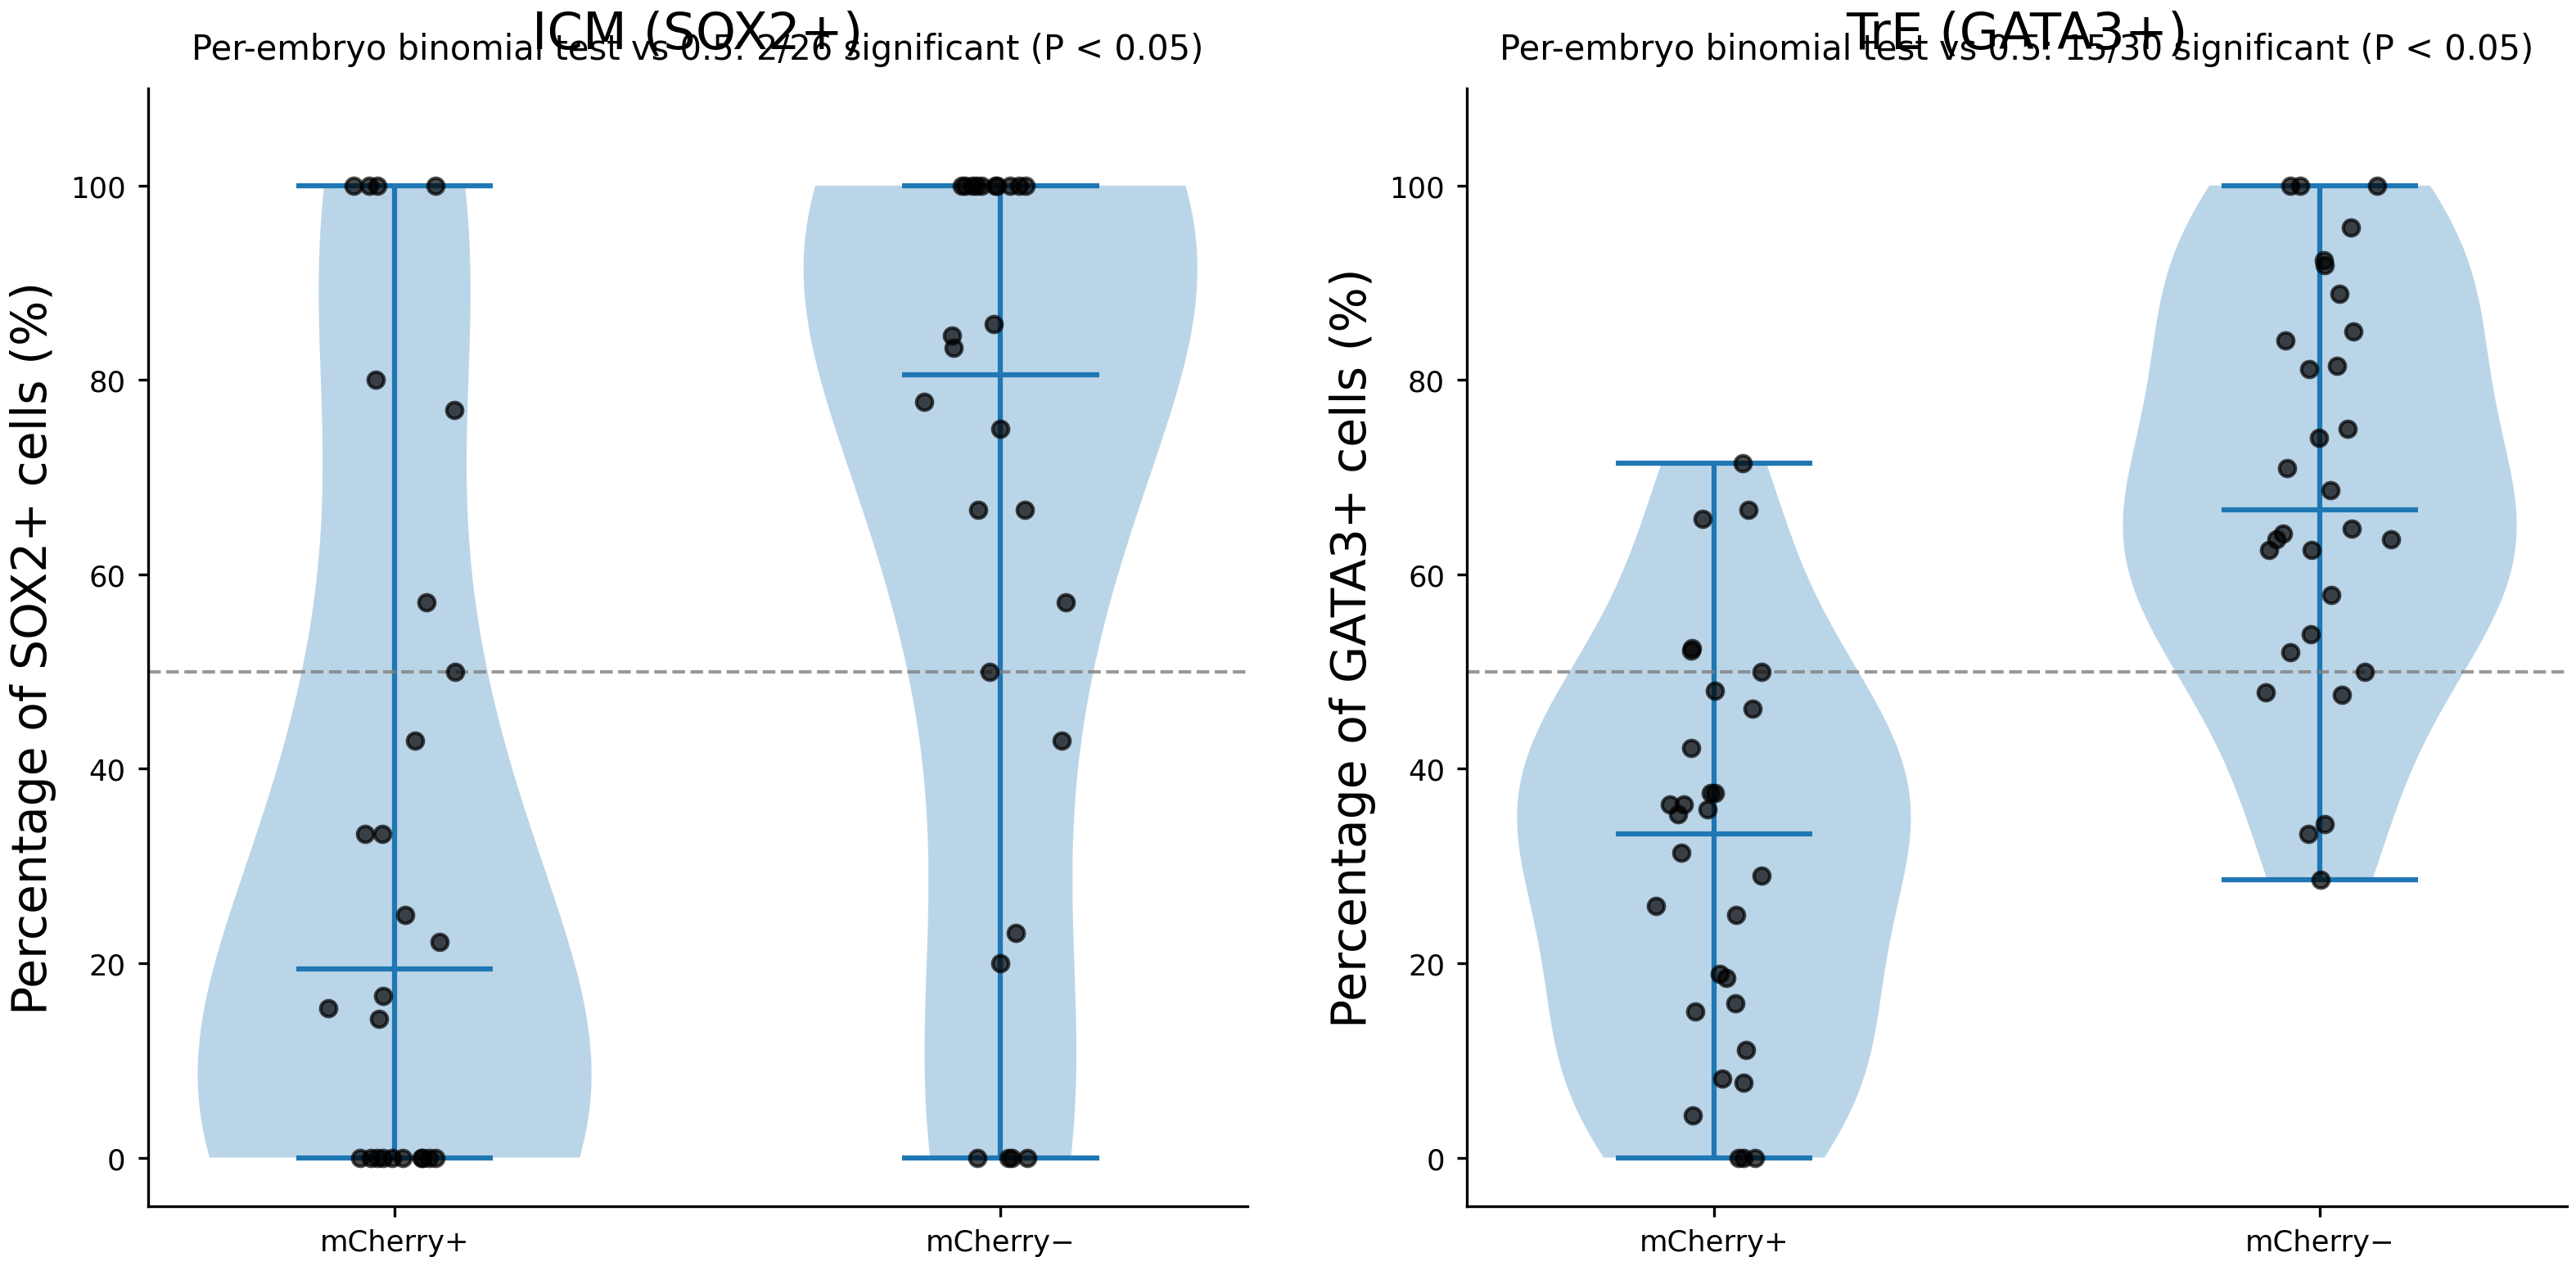


ICM:
  Embryos tested: 26
  Significant at P < 0.05: 2
  Non-significant: 24

TrE:
  Embryos tested: 30
  Significant at P < 0.05: 15
  Non-significant: 15


In [49]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binomtest

# ============================================================
# 1. Matplotlib settings
# ============================================================
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 14,
    "axes.titlesize": 15,
    "axes.labelsize": 14,
    "svg.fonttype": "none",
    "svg.hashsalt": "hello"
})

np.random.seed(123)

# ============================================================
# 2. Read data
# ============================================================
df = pd.read_csv("red_icm_te_count.txt", sep="\t")

# Keep WT embryos only
df = df[df["treatment"].astype(str).str.strip() == "WT"].copy()

required_cols = [
    "编号", "mCherry-ICM", "mCherry-TE", "SOX2", "GATA3"
]

for col in required_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=required_cols).copy()

# ============================================================
# 3. Calculate positive and negative cell counts
# ============================================================
df["ICM_mCherry_pos"] = df["mCherry-ICM"]
df["ICM_mCherry_neg"] = df["SOX2"] - df["mCherry-ICM"]

df["TrE_mCherry_pos"] = df["mCherry-TE"]
df["TrE_mCherry_neg"] = df["GATA3"] - df["mCherry-TE"]

# Validate counts
count_cols = [
    "mCherry-ICM", "mCherry-TE", "SOX2", "GATA3",
    "ICM_mCherry_neg", "TrE_mCherry_neg"
]

if (df[count_cols] < 0).any().any():
    raise ValueError(
        "Invalid data: a fluorescent cell count exceeds its lineage cell count."
    )

# ============================================================
# 4. Calculate percentages
# ============================================================
df["ICM_mCherry_pos_pct"] = np.where(
    df["SOX2"] > 0,
    df["ICM_mCherry_pos"] / df["SOX2"] * 100,
    np.nan
)

df["ICM_mCherry_neg_pct"] = np.where(
    df["SOX2"] > 0,
    df["ICM_mCherry_neg"] / df["SOX2"] * 100,
    np.nan
)

df["TrE_mCherry_pos_pct"] = np.where(
    df["GATA3"] > 0,
    df["TrE_mCherry_pos"] / df["GATA3"] * 100,
    np.nan
)

df["TrE_mCherry_neg_pct"] = np.where(
    df["GATA3"] > 0,
    df["TrE_mCherry_neg"] / df["GATA3"] * 100,
    np.nan
)

# ============================================================
# 5. Exact binomial tests against p = 0.5
# ============================================================
def exact_binomial_test(positive, total):
    """
    Two-sided exact binomial test:
    H0: probability of mCherry positivity = 0.5
    """
    positive = int(positive)
    total = int(total)

    if total <= 0:
        return np.nan

    return binomtest(
        k=positive,
        n=total,
        p=0.5,
        alternative="two-sided"
    ).pvalue


df["ICM_binom_p"] = [
    exact_binomial_test(pos, total)
    for pos, total in zip(df["ICM_mCherry_pos"], df["SOX2"])
]

df["TrE_binom_p"] = [
    exact_binomial_test(pos, total)
    for pos, total in zip(df["TrE_mCherry_pos"], df["GATA3"])
]

def significance_label(p):
    if pd.isna(p):
        return "NA"
    elif p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

df["ICM_significance"] = df["ICM_binom_p"].apply(significance_label)
df["TrE_significance"] = df["TrE_binom_p"].apply(significance_label)

# ============================================================
# 6. Export per-embryo results
# ============================================================
output_cols = [
    "编号",
    "SOX2",
    "ICM_mCherry_pos",
    "ICM_mCherry_neg",
    "ICM_mCherry_pos_pct",
    "ICM_mCherry_neg_pct",
    "ICM_binom_p",
    "ICM_significance",
    "GATA3",
    "TrE_mCherry_pos",
    "TrE_mCherry_neg",
    "TrE_mCherry_pos_pct",
    "TrE_mCherry_neg_pct",
    "TrE_binom_p",
    "TrE_significance"
]

result = df[output_cols].copy()

result.to_csv(
    "WT_embryo_lineage_binomial_test.txt",
    sep="\t",
    index=False,
    float_format="%.6g"
)

print("\nPer-embryo exact binomial test results:")
print(result.to_string(index=False, float_format="%.4f"))

# ============================================================
# 7. Plot lineage-specific percentages
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))

panels = [
    {
        "ax": axes[0],
        "pos_pct": "ICM_mCherry_pos_pct",
        "neg_pct": "ICM_mCherry_neg_pct",
        "p_col": "ICM_binom_p",
        "title": "ICM (SOX2+)",
        "ylabel": "Percentage of SOX2+ cells (%)"
    },
    {
        "ax": axes[1],
        "pos_pct": "TrE_mCherry_pos_pct",
        "neg_pct": "TrE_mCherry_neg_pct",
        "p_col": "TrE_binom_p",
        "title": "TrE (GATA3+)",
        "ylabel": "Percentage of GATA3+ cells (%)"
    }
]

for panel in panels:
    ax = panel["ax"]

    pos = df[panel["pos_pct"]].dropna().values
    neg = df[panel["neg_pct"]].dropna().values

    data = [pos, neg]
    positions = [1, 2]

    # Violin plot
    ax.violinplot(
        data,
        positions=positions,
        showmedians=True,
        widths=0.65
    )

    # Individual embryos
    for i, values in enumerate(data):
        x = np.random.normal(
            positions[i], 0.045, size=len(values)
        )
        x = np.clip(
            x,
            positions[i] - 0.15,
            positions[i] + 0.15
        )

        ax.scatter(
            x, values,
            color="black",
            alpha=0.7,
            s=22,
            zorder=3
        )

    # 50% reference line
    ax.axhline(
        50,
        linestyle="--",
        linewidth=1,
        color="grey",
        alpha=0.8
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(["mCherry+", "mCherry−"])
    ax.set_title(panel["title"], pad=12)
    ax.set_ylabel(panel["ylabel"])
    ax.set_ylim(-5, 110)

    # Overall annotation:
    # Number of embryos whose within-lineage binomial test is significant.
    pvals = df[panel["p_col"]].dropna()
    n_sig = int((pvals < 0.05).sum())
    n_tested = len(pvals)

    ax.text(
        0.5, 1.02,
        f"Per-embryo binomial test vs 0.5: "
        f"{n_sig}/{n_tested} significant (P < 0.05)",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=10
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "WT_lineage_mCherry_binomial_test.svg",
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    "WT_lineage_mCherry_binomial_test.pdf",
    bbox_inches="tight",
    transparent=True
)

plt.show()

# ============================================================
# 8. Summary
# ============================================================
for label, p_col in [
    ("ICM", "ICM_binom_p"),
    ("TrE", "TrE_binom_p")
]:
    valid = df[p_col].dropna()
    print(f"\n{label}:")
    print(f"  Embryos tested: {len(valid)}")
    print(f"  Significant at P < 0.05: {(valid < 0.05).sum()}")
    print(f"  Non-significant: {(valid >= 0.05).sum()}")


In [50]:

from scipy.stats import binomtest

# ============================================================
# 5. Four exact binomial tests against p = 0.5
# ============================================================

test_groups = [
    ("ICM mCherry+", "ICM_mCherry_pos", "SOX2"),
    ("ICM mCherry-", "ICM_mCherry_neg", "SOX2"),
    ("TrE mCherry+", "TrE_mCherry_pos", "GATA3"),
    ("TrE mCherry-", "TrE_mCherry_neg", "GATA3"),
]

print("\n" + "=" * 75)
print("Exact binomial tests against p = 0.5")
print("=" * 75)

for group_name, success_col, total_col in test_groups:

    # Total positive/negative cells across WT embryos
    k = int(df[success_col].sum())
    n = int(df[total_col].sum())

    if n == 0:
        print(f"\n{group_name}: no cells available for testing.")
        continue

    result = binomtest(
        k=k,
        n=n,
        p=0.5,
        alternative="two-sided"
    )

    p_value = result.pvalue

    if p_value < 0.0001:
        sig = "****"
    elif p_value < 0.001:
        sig = "***"
    elif p_value < 0.01:
        sig = "**"
    elif p_value < 0.05:
        sig = "*"
    else:
        sig = "ns"

    print(f"\nGroup: {group_name}")
    print(f"  Observed cells: {k}/{n}")
    print(f"  Observed proportion: {k / n:.4%}")
    print(f"  Null proportion: 50.0000%")
    print(f"  Exact binomial test P-value: {p_value:.6e}")
    print(f"  Significance: {sig}")

print("\n" + "=" * 75)



Exact binomial tests against p = 0.5

Group: ICM mCherry+
  Observed cells: 51/143
  Observed proportion: 35.6643%
  Null proportion: 50.0000%
  Exact binomial test P-value: 7.643052e-04
  Significance: ***

Group: ICM mCherry-
  Observed cells: 92/143
  Observed proportion: 64.3357%
  Null proportion: 50.0000%
  Exact binomial test P-value: 7.643052e-04
  Significance: ***

Group: TrE mCherry+
  Observed cells: 278/890
  Observed proportion: 31.2360%
  Null proportion: 50.0000%
  Exact binomial test P-value: 1.336779e-29
  Significance: ****

Group: TrE mCherry-
  Observed cells: 612/890
  Observed proportion: 68.7640%
  Null proportion: 50.0000%
  Exact binomial test P-value: 1.336779e-29
  Significance: ****




Exact binomial tests against p = 0.5
ICM mCherry+: 51/143, proportion=35.6643%, P=7.643052e-04, ***
ICM mCherry-: 92/143, proportion=64.3357%, P=7.643052e-04, ***
TrE mCherry+: 278/890, proportion=31.2360%, P=1.336779e-29, ****
TrE mCherry-: 612/890, proportion=68.7640%, P=1.336779e-29, ****


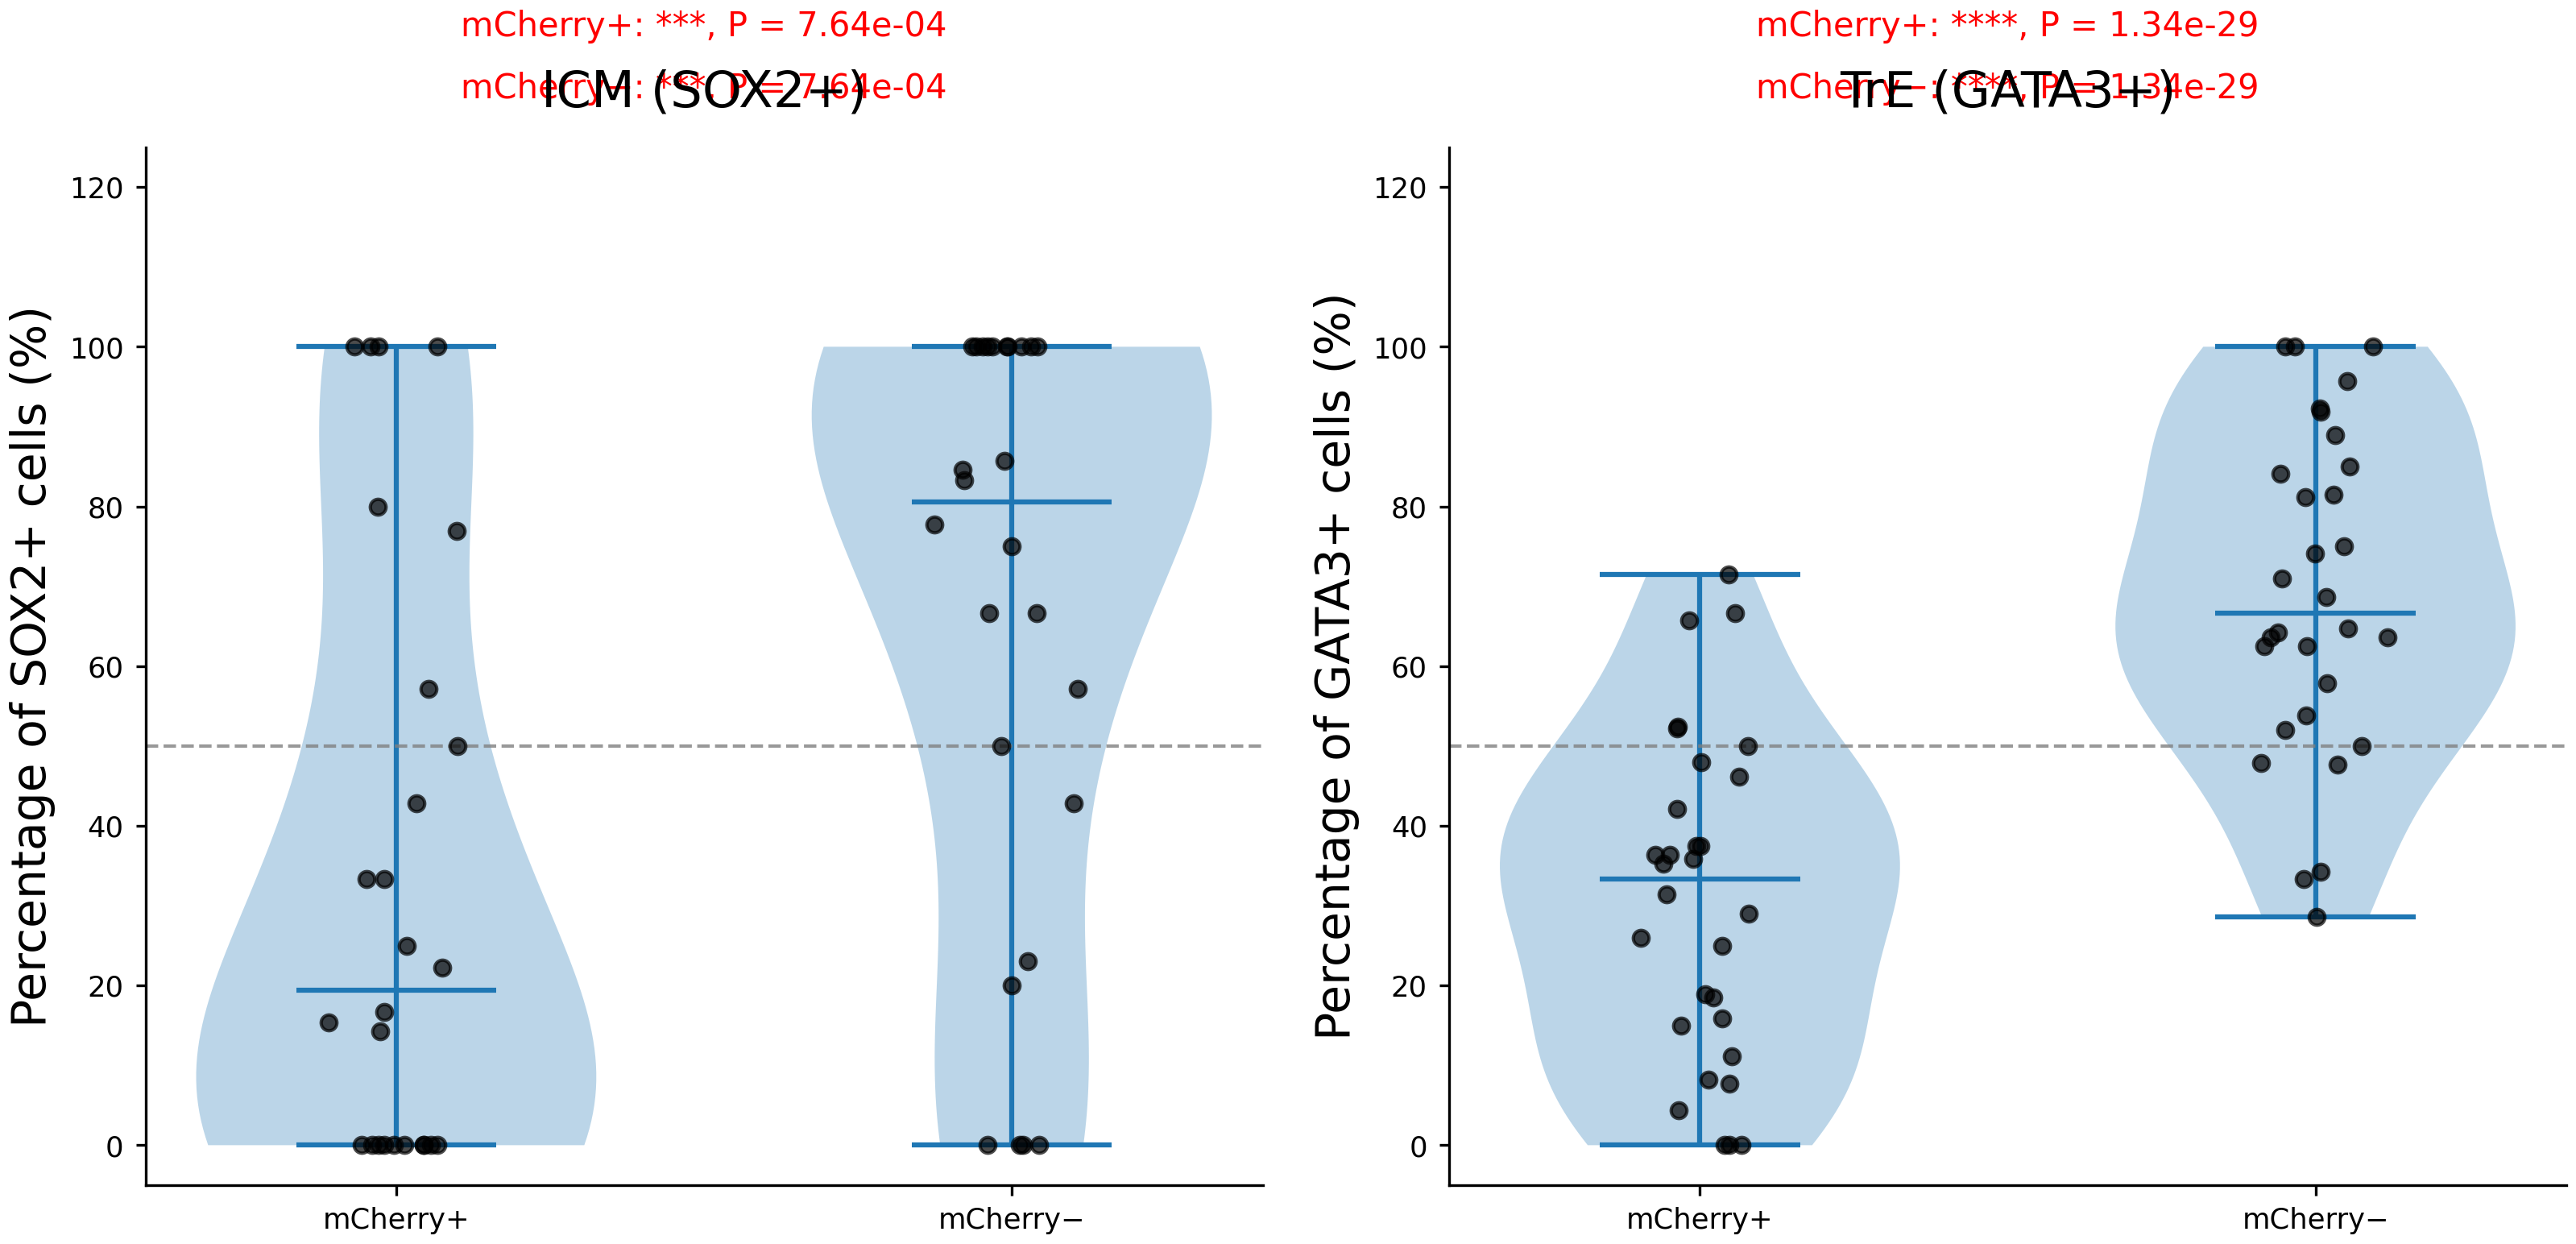

In [51]:

# ============================================================
# Plot four distributions and annotate four binomial tests
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binomtest

np.random.seed(123)

def get_sig(p):
    if p < 1e-4:
        return "****"
    elif p < 1e-3:
        return "***"
    elif p < 1e-2:
        return "**"
    elif p < 0.05:
        return "*"
    return "ns"


# Four tests, each against p = 0.5
test_groups = [
    ("ICM mCherry+", "ICM_mCherry_pos", "SOX2"),
    ("ICM mCherry-", "ICM_mCherry_neg", "SOX2"),
    ("TrE mCherry+", "TrE_mCherry_pos", "GATA3"),
    ("TrE mCherry-", "TrE_mCherry_neg", "GATA3"),
]

test_results = {}

for name, success_col, total_col in test_groups:
    k = int(df[success_col].sum())
    n = int(df[total_col].sum())

    if n > 0:
        res = binomtest(k, n, p=0.5, alternative="two-sided")
        test_results[name] = {
            "k": k,
            "n": n,
            "proportion": k / n,
            "p": res.pvalue,
            "sig": get_sig(res.pvalue)
        }
    else:
        test_results[name] = {
            "k": 0, "n": 0,
            "proportion": np.nan,
            "p": np.nan,
            "sig": "NA"
        }


# Print results
print("\nExact binomial tests against p = 0.5")
print("=" * 65)

for name, r in test_results.items():
    print(
        f"{name}: {r['k']}/{r['n']}, "
        f"proportion={r['proportion']:.4%}, "
        f"P={r['p']:.6e}, "
        f"{r['sig']}"
        if r["n"] > 0 else f"{name}: no cells available"
    )


# ============================================================
# Plot
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(11, 6))

panels = [
    {
        "ax": axes[0],
        "pos_pct": "ICM_mCherry_pos_pct",
        "neg_pct": "ICM_mCherry_neg_pct",
        "pos_name": "ICM mCherry+",
        "neg_name": "ICM mCherry-",
        "title": "ICM (SOX2+)",
        "ylabel": "Percentage of SOX2+ cells (%)"
    },
    {
        "ax": axes[1],
        "pos_pct": "TrE_mCherry_pos_pct",
        "neg_pct": "TrE_mCherry_neg_pct",
        "pos_name": "TrE mCherry+",
        "neg_name": "TrE mCherry-",
        "title": "TrE (GATA3+)",
        "ylabel": "Percentage of GATA3+ cells (%)"
    }
]

for panel in panels:
    ax = panel["ax"]

    data = [
        df[panel["pos_pct"]].dropna().values,
        df[panel["neg_pct"]].dropna().values
    ]

    positions = [1, 2]

    ax.violinplot(
        data,
        positions=positions,
        showmedians=True,
        widths=0.65
    )

    for i, values in enumerate(data):
        x = np.random.normal(positions[i], 0.045, size=len(values))
        x = np.clip(x, positions[i] - 0.15, positions[i] + 0.15)

        ax.scatter(
            x, values,
            color="black",
            alpha=0.7,
            s=22,
            zorder=3
        )

    ax.axhline(
        50,
        linestyle="--",
        linewidth=1,
        color="grey",
        alpha=0.8
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(["mCherry+", "mCherry−"])
    ax.set_title(panel["title"], pad=12)
    ax.set_ylabel(panel["ylabel"])
    ax.set_ylim(-5, 125)

    # Two annotation rows per panel: one for each test.
    # The annotation is placed above the plot to avoid overlapping points.
    pos_result = test_results[panel["pos_name"]]
    neg_result = test_results[panel["neg_name"]]

    pos_text = (
        f"mCherry+: {pos_result['sig']}, "
        f"P = {pos_result['p']:.2e}"
        if pos_result["n"] > 0 else "mCherry+: NA"
    )

    neg_text = (
        f"mCherry−: {neg_result['sig']}, "
        f"P = {neg_result['p']:.2e}"
        if neg_result["n"] > 0 else "mCherry−: NA"
    )

    ax.text(
        0.5, 1.10,
        pos_text,
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=10,
        color="red" if pos_result["n"] > 0 and pos_result["p"] < 0.05 else "black"
    )

    ax.text(
        0.5, 1.04,
        neg_text,
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=10,
        color="red" if neg_result["n"] > 0 and neg_result["p"] < 0.05 else "black"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.92])

plt.savefig(
    "WT_lineage_mCherry_binomial_test.svg",
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    "WT_lineage_mCherry_binomial_test.pdf",
    bbox_inches="tight",
    transparent=True
)

plt.show()



Filtering embryos with SOX2 = 0
WT embryos before filtering: 71
Embryos removed (SOX2 = 0):  12
WT embryos retained:         59
WT n = 26
ZSCAN-KO n = 33

WT
Total embryos: 26
ICM-biased: 3/26
TrE-biased: 20/26
ICM-biased proportion: 0.115
TrE-biased proportion: 0.769
Binomial test p-value: 8.798e-05
Significance: ****

ZSCAN-KO
Total embryos: 33
ICM-biased: 7/33
TrE-biased: 24/33
ICM-biased proportion: 0.212
TrE-biased proportion: 0.727
Binomial test p-value: 1.319e-03
Significance: **


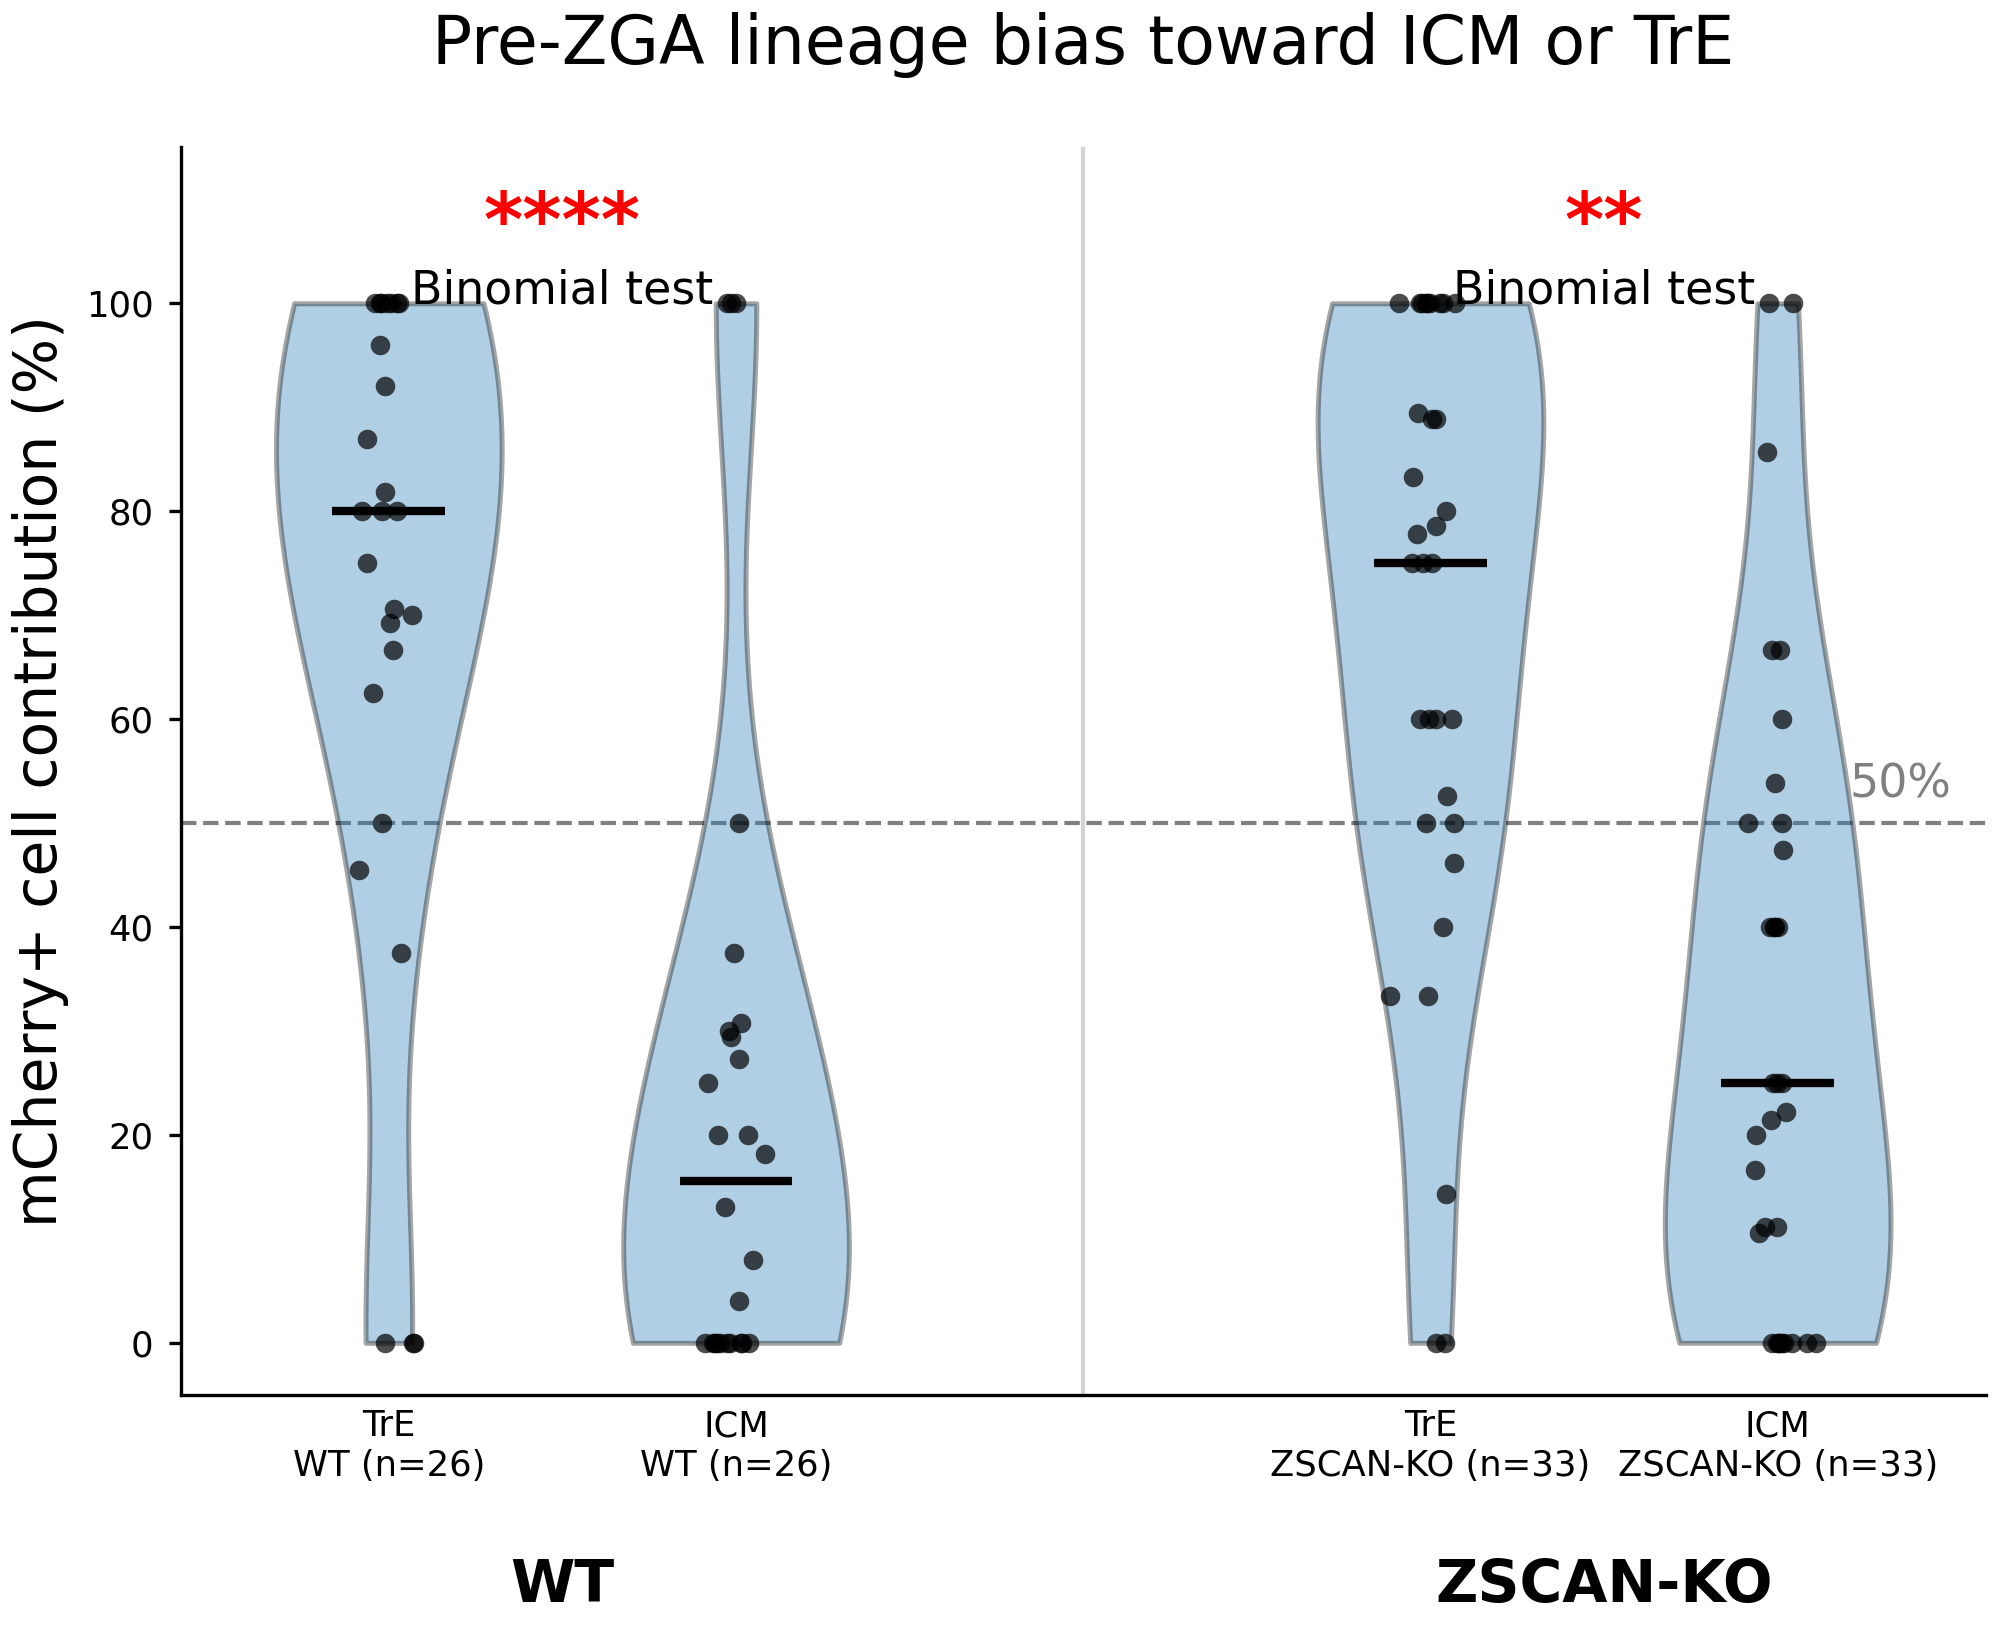

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binomtest

# ============================================================
# Global settings
# ============================================================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

np.random.seed(42)


# ============================================================
# 1. Read data
# ============================================================
df = pd.read_csv(
    "red_icm_te_count.txt",
    sep="\t"
)

# ============================================================
# Filter out embryos with SOX2 = 0
# ============================================================

n_before = len(df)

df = df[df["SOX2"] > 0].copy().reset_index(drop=True)

n_after = len(df)
n_removed = n_before - n_after

print("\n" + "=" * 60)
print("Filtering embryos with SOX2 = 0")
print("=" * 60)
print(f"WT embryos before filtering: {n_before}")
print(f"Embryos removed (SOX2 = 0):  {n_removed}")
print(f"WT embryos retained:         {n_after}")

icm = pd.to_numeric(
    df["Red ICM/Red total%"],
    errors="coerce"
)

te = pd.to_numeric(
    df["Red TE/Red total%"],
    errors="coerce"
)

treatment = df["treatment"].astype(str)

# Remove missing values
mask = ~(icm.isna() | te.isna())

icm = icm[mask].reset_index(drop=True)
te = te[mask].reset_index(drop=True)
treatment = treatment[mask].reset_index(drop=True)

# WT vs all ZSCAN-KO
group = treatment.where(
    treatment == "WT",
    "ZSCAN-KO"
)


# ============================================================
# 2. Significance function
# ============================================================
def get_significance_label(p):
    if p < 1e-4:
        return "****"
    elif p < 1e-3:
        return "***"
    elif p < 1e-2:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"


# ============================================================
# 3. Binomial test
#
#    Exactly following your original logic:
#
#    ICM_more = number of embryos with ICM > 50%
#    TrE_more = number of embryos with TrE > 50%
#
#    H0: probability = 0.5
#
#    Because ICM + TrE = 100%, only one binomial test
#    is necessary for each group.
# ============================================================
def run_binomial_test(te_vals, icm_vals, label):

    n = len(icm_vals)

    ICM_more = int((icm_vals > 50).sum())
    TrE_more = int((te_vals > 50).sum())

    # Exact binomial test
    res = binomtest(
        ICM_more,
        n,
        p=0.5,
        alternative="two-sided"
    )

    p_binom = res.pvalue

    sig_label = get_significance_label(
        p_binom
    )

    print("\n" + "=" * 50)
    print(label)
    print("=" * 50)

    print(f"Total embryos: {n}")
    print(f"ICM-biased: {ICM_more}/{n}")
    print(f"TrE-biased: {TrE_more}/{n}")
    print(f"ICM-biased proportion: {ICM_more/n:.3f}")
    print(f"TrE-biased proportion: {TrE_more/n:.3f}")
    print(f"Binomial test p-value: {p_binom:.3e}")
    print(f"Significance: {sig_label}")

    return {
        "n": n,
        "ICM_more": ICM_more,
        "TrE_more": TrE_more,
        "p": p_binom,
        "sig": sig_label
    }


# ============================================================
# 4. Split WT and ZSCAN-KO
# ============================================================
wt_mask = group == "WT"
ko_mask = group == "ZSCAN-KO"

wt_te = te[wt_mask].values
wt_icm = icm[wt_mask].values

ko_te = te[ko_mask].values
ko_icm = icm[ko_mask].values


print(f"WT n = {len(wt_te)}")
print(f"ZSCAN-KO n = {len(ko_te)}")


# ============================================================
# 5. Run binomial tests
# ============================================================
res_wt = run_binomial_test(
    wt_te,
    wt_icm,
    "WT"
)

res_ko = run_binomial_test(
    ko_te,
    ko_icm,
    "ZSCAN-KO"
)


# ============================================================
# 6. Plot
# ============================================================
fig, ax = plt.subplots(
    figsize=(7, 5.8)
)

# Four distributions
data = [
    wt_te,
    wt_icm,
    ko_te,
    ko_icm
]

positions = [
    1,
    2,
    4,
    5
]


# ============================================================
# Violin plots
# ============================================================
vp = ax.violinplot(
    data,
    positions=positions,
    showmeans=False,
    showmedians=True,
    showextrema=False,
    widths=0.65
)

# Violin styling
for body in vp["bodies"]:
    body.set_alpha(0.35)
    body.set_edgecolor("black")
    body.set_linewidth(1.2)

vp["cmedians"].set_color("black")
vp["cmedians"].set_linewidth(2)


# ============================================================
# Individual data points
# ============================================================
for pos, values in zip(positions, data):

    x = np.random.normal(
        loc=pos,
        scale=0.045,
        size=len(values)
    )

    x = np.clip(
        x,
        pos - 0.15,
        pos + 0.15
    )

    ax.scatter(
        x,
        values,
        color="black",
        alpha=0.7,
        s=22,
        linewidths=0,
        zorder=3
    )


# ============================================================
# 50% reference line
# ============================================================
ax.axhline(
    50,
    linestyle="--",
    linewidth=1,
    color="grey",
    zorder=0
)

ax.text(
    5.5,
    51.5,
    "50%",
    ha="right",
    va="bottom",
    fontsize=11,
    color="grey"
)


# ============================================================
# Significance annotation
#
# One test for WT:
#   WT ICM >50% vs 0.5
#
# One test for ZSCAN-KO:
#   ZSCAN-KO ICM >50% vs 0.5
#
# Since TrE and ICM are complementary, the same p-value
# describes the lineage allocation bias.
# ============================================================

# WT
ax.text(
    1.5,
    104,
    res_wt["sig"],
    ha="center",
    va="bottom",
    fontsize=18,
    fontweight="bold",
    color="red"
)

ax.text(
    1.5,
    99,
    "Binomial test",
    ha="center",
    va="bottom",
    fontsize=11,
    color="black"
)


# ZSCAN-KO
ax.text(
    4.5,
    104,
    res_ko["sig"],
    ha="center",
    va="bottom",
    fontsize=18,
    fontweight="bold",
    color="red"
)

ax.text(
    4.5,
    99,
    "Binomial test",
    ha="center",
    va="bottom",
    fontsize=11,
    color="black"
)


# ============================================================
# Group separator
# ============================================================
ax.axvline(
    3,
    color="lightgrey",
    linewidth=1
)


# ============================================================
# X-axis
# ============================================================
ax.set_xticks(positions)

ax.set_xticklabels([
    f"TrE\nWT (n={len(wt_te)})",
    f"ICM\nWT (n={len(wt_icm)})",
    f"TrE\nZSCAN-KO (n={len(ko_te)})",
    f"ICM\nZSCAN-KO (n={len(ko_icm)})"
])


# ============================================================
# Group labels
# ============================================================
ax.text(
    1.5,
    -0.13,
    "WT",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14,
    fontweight="bold"
)

ax.text(
    4.5,
    -0.13,
    "ZSCAN-KO",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14,
    fontweight="bold"
)


# ============================================================
# Axis formatting
# ============================================================
ax.set_ylabel(
    "mCherry+ cell contribution (%)"
)

ax.set_title(
    "Pre-ZGA lineage bias toward ICM or TrE",
    pad=20
)

ax.set_xlim(
    0.4,
    5.6
)

ax.set_ylim(
    -5,
    115
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="x",
    length=0
)


# ============================================================
# Save
# ============================================================
plt.tight_layout()

plt.savefig(
    "Lineage_allocation_bias_WT_ZSCAN-KO.svg",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    "Lineage_allocation_bias_WT_ZSCAN-KO.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()


Sample size
WT       n = 30
ZSCAN-KO n = 20

Binomial test: WT
Total embryos : 30
ICM-biased    : 3/30 (10.0%)
TrE-biased    : 24/30 (80.0%)
Binomial p    : 8.430e-06
Significance  : ****

Binomial test: ZSCAN-KO
Total embryos : 20
ICM-biased    : 4/20 (20.0%)
TrE-biased    : 14/20 (70.0%)
Binomial p    : 1.182e-02
Significance  : *

WT vs ZSCAN-KO
TrE: WT vs ZSCAN-KO
    WT median       = 80.91%
    ZSCAN-KO median = 67.50%
    Mann-Whitney U  = 366.0
    p-value         = 1.850e-01
    significance    = ns

ICM: WT vs ZSCAN-KO
    WT median       = 6.00%
    ZSCAN-KO median = 23.61%
    Mann-Whitney U  = 251.0
    p-value         = 3.150e-01
    significance    = ns


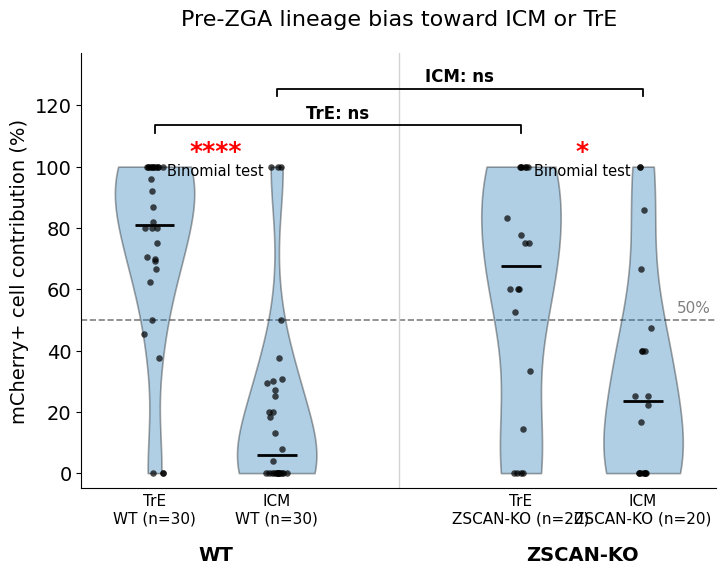

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import binomtest, mannwhitneyu


# ============================================================
# 0. Plot settings
# ============================================================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

np.random.seed(42)


# ============================================================
# 1. Read data
# ============================================================
df = pd.read_csv(
    "red_icm_te_count.txt",
    sep="\t"
)


# ============================================================
# 2. Extract variables
# ============================================================
icm = pd.to_numeric(
    df["Red ICM/Red total%"],
    errors="coerce"
)

te = pd.to_numeric(
    df["Red TE/Red total%"],
    errors="coerce"
)

treatment = df["treatment"].astype(str)


# ============================================================
# 3. Remove missing values
# ============================================================
mask = ~(
    icm.isna() |
    te.isna() |
    treatment.isna()
)

icm = icm[mask].reset_index(drop=True)
te = te[mask].reset_index(drop=True)
treatment = treatment[mask].reset_index(drop=True)


# ============================================================
# 4. Define groups
#
# WT remains WT
# All other treatments are combined as ZSCAN-KO
# ============================================================
group = treatment.where(
    treatment == "WT",
    "ZSCAN-KO"
)


# ============================================================
# 5. Extract WT and ZSCAN-KO
# ============================================================
wt_mask = group == "WT"
ko_mask = group == "ZSCAN-KO"

wt_te = te[wt_mask].values
wt_icm = icm[wt_mask].values

ko_te = te[ko_mask].values
ko_icm = icm[ko_mask].values


print("\n==============================")
print("Sample size")
print("==============================")

print(f"WT       n = {len(wt_te)}")
print(f"ZSCAN-KO n = {len(ko_te)}")


# ============================================================
# 6. Significance label
# ============================================================
def get_significance_label(p):

    if p < 1e-4:
        return "****"

    elif p < 1e-3:
        return "***"

    elif p < 1e-2:
        return "**"

    elif p < 0.05:
        return "*"

    else:
        return "ns"


# ============================================================
# 7. Exact binomial test against 50%
#
# ICM > 50% = ICM-biased
# ICM <= 50% = TrE-biased
#
# H0: probability of ICM-biased embryo = 0.5
#
# Because ICM% + TrE% = 100%, one binomial test
# represents the 50:50 lineage allocation test.
# ============================================================
def run_binomial_test(
    te_vals,
    icm_vals,
    label
):

    n = len(icm_vals)

    # Number of ICM-biased embryos
    icm_more = int(
        np.sum(icm_vals > 50)
    )

    # Number of TrE-biased embryos
    tre_more = int(
        np.sum(te_vals > 50)
    )

    # Exact two-sided binomial test
    result = binomtest(
        icm_more,
        n,
        p=0.5,
        alternative="two-sided"
    )

    p = result.pvalue

    sig = get_significance_label(p)

    print("\n==============================")
    print(f"Binomial test: {label}")
    print("==============================")

    print(f"Total embryos : {n}")
    print(
        f"ICM-biased    : "
        f"{icm_more}/{n} "
        f"({icm_more/n*100:.1f}%)"
    )

    print(
        f"TrE-biased    : "
        f"{tre_more}/{n} "
        f"({tre_more/n*100:.1f}%)"
    )

    print(
        f"Binomial p    : "
        f"{p:.3e}"
    )

    print(
        f"Significance  : "
        f"{sig}"
    )

    return {
        "n": n,
        "ICM_more": icm_more,
        "TrE_more": tre_more,
        "p": p,
        "sig": sig
    }


# ============================================================
# 8. Run binomial tests
# ============================================================
res_wt = run_binomial_test(
    wt_te,
    wt_icm,
    "WT"
)

res_ko = run_binomial_test(
    ko_te,
    ko_icm,
    "ZSCAN-KO"
)


# ============================================================
# 9. WT vs ZSCAN-KO
#
# Compare the actual contribution percentage distributions
# ============================================================

# ------------------------------------------------------------
# TrE
# ------------------------------------------------------------
u_tre, p_tre = mannwhitneyu(
    wt_te,
    ko_te,
    alternative="two-sided"
)

sig_tre = get_significance_label(
    p_tre
)


# ------------------------------------------------------------
# ICM
# ------------------------------------------------------------
u_icm, p_icm = mannwhitneyu(
    wt_icm,
    ko_icm,
    alternative="two-sided"
)

sig_icm = get_significance_label(
    p_icm
)


# ============================================================
# 10. Print WT vs KO results
# ============================================================
print("\n==============================")
print("WT vs ZSCAN-KO")
print("==============================")

print(
    f"TrE: WT vs ZSCAN-KO"
)

print(
    f"    WT median       = "
    f"{np.median(wt_te):.2f}%"
)

print(
    f"    ZSCAN-KO median = "
    f"{np.median(ko_te):.2f}%"
)

print(
    f"    Mann-Whitney U  = "
    f"{u_tre:.1f}"
)

print(
    f"    p-value         = "
    f"{p_tre:.3e}"
)

print(
    f"    significance    = "
    f"{sig_tre}"
)


print(
    f"\nICM: WT vs ZSCAN-KO"
)

print(
    f"    WT median       = "
    f"{np.median(wt_icm):.2f}%"
)

print(
    f"    ZSCAN-KO median = "
    f"{np.median(ko_icm):.2f}%"
)

print(
    f"    Mann-Whitney U  = "
    f"{u_icm:.1f}"
)

print(
    f"    p-value         = "
    f"{p_icm:.3e}"
)

print(
    f"    significance    = "
    f"{sig_icm}"
)


# ============================================================
# 11. Prepare plotting data
# ============================================================
data = [
    wt_te,
    wt_icm,
    ko_te,
    ko_icm
]

positions = [
    1,
    2,
    4,
    5
]

labels = [
    f"TrE\nWT (n={len(wt_te)})",
    f"ICM\nWT (n={len(wt_icm)})",
    f"TrE\nZSCAN-KO (n={len(ko_te)})",
    f"ICM\nZSCAN-KO (n={len(ko_icm)})"
]


# ============================================================
# 12. Create figure
# ============================================================
fig, ax = plt.subplots(
    figsize=(7.5, 6)
)


# ============================================================
# 13. Violin plots
# ============================================================
vp = ax.violinplot(
    data,
    positions=positions,
    widths=0.65,
    showmeans=False,
    showmedians=True,
    showextrema=False
)


# Violin styling
for body in vp["bodies"]:

    body.set_alpha(0.35)

    body.set_edgecolor(
        "black"
    )

    body.set_linewidth(
        1.2
    )


# Median line
vp["cmedians"].set_color(
    "black"
)

vp["cmedians"].set_linewidth(
    2
)


# ============================================================
# 14. Individual points
# ============================================================
for pos, values in zip(
    positions,
    data
):

    jitter = np.random.normal(
        loc=0,
        scale=0.045,
        size=len(values)
    )

    jitter = np.clip(
        jitter,
        -0.15,
        0.15
    )

    ax.scatter(
        pos + jitter,
        values,
        color="black",
        alpha=0.70,
        s=22,
        linewidths=0,
        zorder=3
    )


# ============================================================
# 15. 50% reference line
# ============================================================
ax.axhline(
    50,
    linestyle="--",
    linewidth=1.2,
    color="grey",
    zorder=0
)

ax.text(
    5.55,
    51.5,
    "50%",
    ha="right",
    va="bottom",
    fontsize=11,
    color="grey"
)


# ============================================================
# 16. Binomial test annotations
#
# WT significance
# KO significance
# ============================================================

# WT
ax.text(
    1.5,
    101,
    res_wt["sig"],
    ha="center",
    va="bottom",
    fontsize=18,
    fontweight="bold",
    color="red"
)

ax.text(
    1.5,
    96,
    "Binomial test",
    ha="center",
    va="bottom",
    fontsize=10.5,
    color="black"
)


# ZSCAN-KO
ax.text(
    4.5,
    101,
    res_ko["sig"],
    ha="center",
    va="bottom",
    fontsize=18,
    fontweight="bold",
    color="red"
)

ax.text(
    4.5,
    96,
    "Binomial test",
    ha="center",
    va="bottom",
    fontsize=10.5,
    color="black"
)


# ============================================================
# 17. Function for WT vs KO brackets
# ============================================================
def add_bracket(
    ax,
    x1,
    x2,
    y,
    h,
    text,
    fontsize=12
):

    ax.plot(
        [x1, x1, x2, x2],
        [y, y+h, y+h, y],
        linewidth=1.3,
        color="black",
        clip_on=False
    )

    ax.text(
        (x1 + x2) / 2,
        y + h + 1.0,
        text,
        ha="center",
        va="bottom",
        fontsize=fontsize,
        fontweight="bold"
    )


# ============================================================
# 18. WT vs KO statistical brackets
# ============================================================

# TrE:
# WT-TrE = position 1
# KO-TrE = position 4
add_bracket(
    ax,
    1,
    4,
    y=111,
    h=2.5,
    text=f"TrE: {sig_tre}"
)


# ICM:
# WT-ICM = position 2
# KO-ICM = position 5
add_bracket(
    ax,
    2,
    5,
    y=123,
    h=2.5,
    text=f"ICM: {sig_icm}"
)


# ============================================================
# 19. WT / KO separator
# ============================================================
ax.axvline(
    3,
    color="lightgrey",
    linewidth=1,
    zorder=0
)


# ============================================================
# 20. Group labels
# ============================================================
ax.text(
    1.5,
    -0.13,
    "WT",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14,
    fontweight="bold"
)

ax.text(
    4.5,
    -0.13,
    "ZSCAN-KO",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14,
    fontweight="bold"
)


# ============================================================
# 21. Axis formatting
# ============================================================
ax.set_xticks(
    positions
)

ax.set_xticklabels(
    labels,
    fontsize=11
)

ax.set_ylabel(
    "mCherry+ cell contribution (%)",
    fontsize=14
)

ax.set_title(
    "Pre-ZGA lineage bias toward ICM or TrE",
    fontsize=16,
    pad=20
)

ax.set_xlim(
    0.4,
    5.6
)

ax.set_ylim(
    -5,
    137
)

ax.spines["top"].set_visible(
    False
)

ax.spines["right"].set_visible(
    False
)

ax.tick_params(
    axis="x",
    length=0
)


# ============================================================
# 22. Save
# ============================================================
plt.tight_layout()

plt.savefig(
    "Lineage_allocation_bias_WT_ZSCAN-KO.svg",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    "Lineage_allocation_bias_WT_ZSCAN-KO.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()


Sample size
WT       n = 30
ZSCAN-KO n = 20

----------------------------------------
WT: vs 50%
----------------------------------------
ICM-biased: 3/30 (10.0%)
TrE-biased: 24/30 (80.0%)
Binomial p = 8.430e-06
Significance = ****

----------------------------------------
ZSCAN-KO: vs 50%
----------------------------------------
ICM-biased: 4/20 (20.0%)
TrE-biased: 14/20 (70.0%)
Binomial p = 1.182e-02
Significance = *

WT vs ZSCAN-KO

TrE:
WT       : 24/30 (80.0%)
ZSCAN-KO : 14/20 (70.0%)
WT proportion used as p = 0.8000
Binomial p = 2.650e-01
Significance = ns

ICM:
WT       : 3/30 (10.0%)
ZSCAN-KO : 4/20 (20.0%)
WT proportion used as p = 0.1000
Binomial p = 1.330e-01
Significance = ns


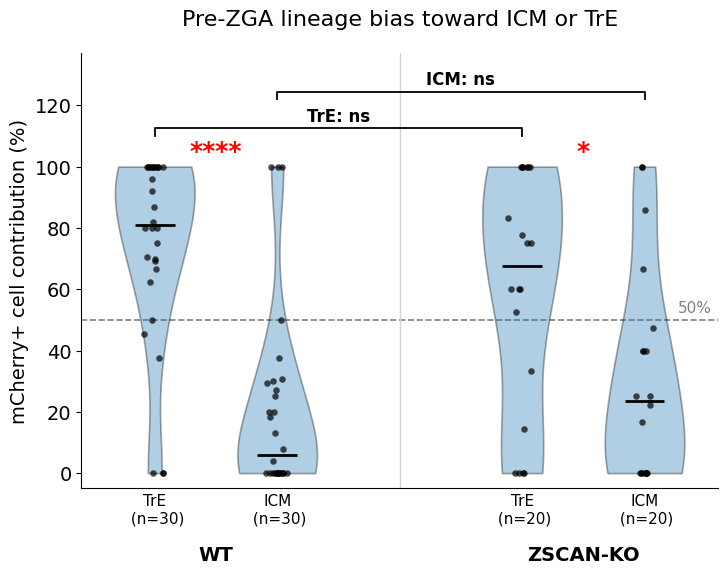

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import binomtest


# ============================================================
# 0. Plot settings
# ============================================================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

np.random.seed(42)


# ============================================================
# 1. Read data
# ============================================================
df = pd.read_csv(
    "red_icm_te_count.txt",
    sep="\t"
)


# ============================================================
# 2. Extract data
# ============================================================
icm = pd.to_numeric(
    df["Red ICM/Red total%"],
    errors="coerce"
)

te = pd.to_numeric(
    df["Red TE/Red total%"],
    errors="coerce"
)

treatment = df["treatment"].astype(str)


# ============================================================
# 3. Remove missing values
# ============================================================
mask = ~(
    icm.isna() |
    te.isna()
)

icm = icm[mask].reset_index(drop=True)
te = te[mask].reset_index(drop=True)
treatment = treatment[mask].reset_index(drop=True)


# ============================================================
# 4. Define groups
#
# WT remains WT
# All non-WT samples are combined as ZSCAN-KO
# ============================================================
group = treatment.where(
    treatment == "WT",
    "ZSCAN-KO"
)


# ============================================================
# 5. Extract WT and ZSCAN-KO data
# ============================================================
wt_mask = group == "WT"
ko_mask = group == "ZSCAN-KO"

wt_te = te[wt_mask].values
wt_icm = icm[wt_mask].values

ko_te = te[ko_mask].values
ko_icm = icm[ko_mask].values


print("\n========================================")
print("Sample size")
print("========================================")

print(f"WT       n = {len(wt_te)}")
print(f"ZSCAN-KO n = {len(ko_te)}")


# ============================================================
# 6. Significance function
# ============================================================
def get_significance_label(p):

    if p < 1e-4:
        return "****"

    elif p < 1e-3:
        return "***"

    elif p < 1e-2:
        return "**"

    elif p < 0.05:
        return "*"

    else:
        return "ns"


# ============================================================
# 7. Binomial test vs 50%
#
# Definition:
#
# ICM > 50%  -> ICM-biased
# ICM <= 50% -> not ICM-biased / TrE-biased
#
# H0: P(ICM-biased) = 0.5
#
# Because ICM% + TrE% = 100%, the TrE-biased proportion
# is complementary to the ICM-biased proportion.
# ============================================================
def binomial_vs_50(
    te_vals,
    icm_vals,
    label
):

    n = len(icm_vals)

    icm_more = int(
        np.sum(icm_vals > 50)
    )

    tre_more = int(
        np.sum(te_vals > 50)
    )

    result = binomtest(
        k=icm_more,
        n=n,
        p=0.5,
        alternative="two-sided"
    )

    p = result.pvalue

    sig = get_significance_label(p)

    print("\n----------------------------------------")
    print(f"{label}: vs 50%")
    print("----------------------------------------")

    print(
        f"ICM-biased: "
        f"{icm_more}/{n} "
        f"({icm_more/n*100:.1f}%)"
    )

    print(
        f"TrE-biased: "
        f"{tre_more}/{n} "
        f"({tre_more/n*100:.1f}%)"
    )

    print(
        f"Binomial p = {p:.3e}"
    )

    print(
        f"Significance = {sig}"
    )

    return {
        "n": n,
        "ICM_more": icm_more,
        "TrE_more": tre_more,
        "p": p,
        "sig": sig
    }


# ============================================================
# 8. Run binomial tests against 50%
# ============================================================
res_wt = binomial_vs_50(
    wt_te,
    wt_icm,
    "WT"
)

res_ko = binomial_vs_50(
    ko_te,
    ko_icm,
    "ZSCAN-KO"
)


# ============================================================
# 9. WT vs ZSCAN-KO using binomial test
#
# IMPORTANT:
#
# WT observed proportion is used as the null probability.
#
# For TrE:
#   p_WT = WT TrE-biased proportion
#   test KO TrE-biased embryos against p_WT
#
# For ICM:
#   p_WT = WT ICM-biased proportion
#   test KO ICM-biased embryos against p_WT
#
# Because TrE and ICM are complementary, the two tests
# represent the same lineage-allocation difference.
# ============================================================


# ============================================================
# 9A. TrE: WT vs ZSCAN-KO
# ============================================================

wt_tre_more = int(
    np.sum(wt_te > 50)
)

ko_tre_more = int(
    np.sum(ko_te > 50)
)

wt_tre_n = len(wt_te)
ko_tre_n = len(ko_te)

# WT observed TrE-biased proportion
p_wt_tre = (
    wt_tre_more /
    wt_tre_n
)

# Exact binomial test
res_tre_between = binomtest(
    k=ko_tre_more,
    n=ko_tre_n,
    p=p_wt_tre,
    alternative="two-sided"
)

p_tre_between = res_tre_between.pvalue

sig_tre_between = get_significance_label(
    p_tre_between
)


# ============================================================
# 9B. ICM: WT vs ZSCAN-KO
# ============================================================

wt_icm_more = int(
    np.sum(wt_icm > 50)
)

ko_icm_more = int(
    np.sum(ko_icm > 50)
)

wt_icm_n = len(wt_icm)
ko_icm_n = len(ko_icm)

# WT observed ICM-biased proportion
p_wt_icm = (
    wt_icm_more /
    wt_icm_n
)

# Exact binomial test
res_icm_between = binomtest(
    k=ko_icm_more,
    n=ko_icm_n,
    p=p_wt_icm,
    alternative="two-sided"
)

p_icm_between = res_icm_between.pvalue

sig_icm_between = get_significance_label(
    p_icm_between
)


# ============================================================
# 10. Print WT vs KO results
# ============================================================
print("\n========================================")
print("WT vs ZSCAN-KO")
print("========================================")

print("\nTrE:")
print(
    f"WT       : "
    f"{wt_tre_more}/{wt_tre_n} "
    f"({wt_tre_more/wt_tre_n*100:.1f}%)"
)

print(
    f"ZSCAN-KO : "
    f"{ko_tre_more}/{ko_tre_n} "
    f"({ko_tre_more/ko_tre_n*100:.1f}%)"
)

print(
    f"WT proportion used as p = "
    f"{p_wt_tre:.4f}"
)

print(
    f"Binomial p = "
    f"{p_tre_between:.3e}"
)

print(
    f"Significance = "
    f"{sig_tre_between}"
)


print("\nICM:")
print(
    f"WT       : "
    f"{wt_icm_more}/{wt_icm_n} "
    f"({wt_icm_more/wt_icm_n*100:.1f}%)"
)

print(
    f"ZSCAN-KO : "
    f"{ko_icm_more}/{ko_icm_n} "
    f"({ko_icm_more/ko_icm_n*100:.1f}%)"
)

print(
    f"WT proportion used as p = "
    f"{p_wt_icm:.4f}"
)

print(
    f"Binomial p = "
    f"{p_icm_between:.3e}"
)

print(
    f"Significance = "
    f"{sig_icm_between}"
)


# ============================================================
# 11. Plot data
# ============================================================
data = [
    wt_te,
    wt_icm,
    ko_te,
    ko_icm
]

positions = [
    1,
    2,
    4,
    5
]

labels = [
    f"TrE\n (n={len(wt_te)})",
    f"ICM\n (n={len(wt_icm)})",
    f"TrE\n (n={len(ko_te)})",
    f"ICM\n (n={len(ko_icm)})"
]


# ============================================================
# 12. Create figure
# ============================================================
fig, ax = plt.subplots(
    figsize=(7.5, 6)
)


# ============================================================
# 13. Violin plots
# ============================================================
vp = ax.violinplot(
    data,
    positions=positions,
    widths=0.65,
    showmeans=False,
    showmedians=True,
    showextrema=False
)


# Violin style
for body in vp["bodies"]:

    body.set_alpha(0.35)

    body.set_edgecolor(
        "black"
    )

    body.set_linewidth(
        1.2
    )


# Median
vp["cmedians"].set_color(
    "black"
)

vp["cmedians"].set_linewidth(
    2
)


# ============================================================
# 14. Scatter points
# ============================================================
for pos, values in zip(
    positions,
    data
):

    jitter = np.random.normal(
        0,
        0.045,
        size=len(values)
    )

    jitter = np.clip(
        jitter,
        -0.15,
        0.15
    )

    ax.scatter(
        pos + jitter,
        values,
        color="black",
        alpha=0.70,
        s=22,
        linewidths=0,
        zorder=3
    )


# ============================================================
# 15. 50% reference line
# ============================================================
ax.axhline(
    50,
    linestyle="--",
    linewidth=1.2,
    color="grey",
    zorder=0
)

ax.text(
    5.55,
    51.5,
    "50%",
    ha="right",
    va="bottom",
    fontsize=11,
    color="grey"
)


# ============================================================
# 16. Binomial test annotations
#
# WT vs 50%
# ZSCAN-KO vs 50%
# ============================================================

ax.text(
    1.5,
    101,
    res_wt["sig"],
    ha="center",
    va="bottom",
    fontsize=18,
    fontweight="bold",
    color="red"
)

ax.text(
    4.5,
    101,
    res_ko["sig"],
    ha="center",
    va="bottom",
    fontsize=18,
    fontweight="bold",
    color="red"
)

# ============================================================
# 17. Bracket function
# ============================================================
def add_bracket(
    ax,
    x1,
    x2,
    y,
    h,
    text,
    fontsize=12
):

    ax.plot(
        [x1, x1, x2, x2],
        [y, y+h, y+h, y],
        color="black",
        linewidth=1.3,
        clip_on=False
    )

    ax.text(
        (x1 + x2) / 2,
        y + h + 1,
        text,
        ha="center",
        va="bottom",
        fontsize=fontsize,
        fontweight="bold"
    )


# ============================================================
# 18. WT vs KO brackets
# ============================================================

# ------------------------------------------------------------
# TrE
# WT-TrE = 1
# KO-TrE = 4
# ------------------------------------------------------------
add_bracket(
    ax,
    1,
    4,
    y=110,
    h=2.5,
    text=f"TrE: {sig_tre_between}"
)


# ------------------------------------------------------------
# ICM
# WT-ICM = 2
# KO-ICM = 5
# ------------------------------------------------------------
add_bracket(
    ax,
    2,
    5,
    y=122,
    h=2.5,
    text=f"ICM: {sig_icm_between}"
)


# ============================================================
# 19. WT / KO separator
# ============================================================
ax.axvline(
    3,
    color="lightgrey",
    linewidth=1,
    zorder=0
)


# ============================================================
# 20. Group labels
# ============================================================
ax.text(
    1.5,
    -0.13,
    "WT",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14,
    fontweight="bold"
)

ax.text(
    4.5,
    -0.13,
    "ZSCAN-KO",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14,
    fontweight="bold"
)


# ============================================================
# 21. Axis formatting
# ============================================================
ax.set_xticks(
    positions
)

ax.set_xticklabels(
    labels,
    fontsize=11
)

ax.set_xlim(
    0.4,
    5.6
)

ax.set_ylim(
    -5,
    137
)

ax.set_ylabel(
    "mCherry+ cell contribution (%)",
    fontsize=14
)

ax.set_title(
    "Pre-ZGA lineage bias toward ICM or TrE",
    fontsize=16,
    pad=20
)

ax.spines["top"].set_visible(
    False
)

ax.spines["right"].set_visible(
    False
)

ax.tick_params(
    axis="x",
    length=0
)


# ============================================================
# 22. Save
# ============================================================
plt.tight_layout()

plt.savefig(
    "Lineage_allocation_bias_WT_ZSCAN-KO_binomtest.svg",
    dpi=300,
    bbox_inches="tight",
    transparent=True)


plt.show()


Sample size
WT       n = 30
ZSCAN-KO n = 20

Lineage-biased embryo proportions

WT:
ICM-biased: 3/30 = 0.100 (10.0%)
TrE-biased: 24/30 = 0.800 (80.0%)

ZSCAN-KO:
ICM-biased: 4/20 = 0.200 (20.0%)
TrE-biased: 14/20 = 0.700 (70.0%)

Binomial tests vs 50%
WT ICM: 3/30, p = 8.430e-06, ****
WT TrE: 24/30, p = 1.431e-03, **
ZSCAN-KO ICM: 4/20, p = 1.182e-02, *
ZSCAN-KO TrE: 14/20, p = 1.153e-01, ns

Between-group binomial tests

ICM:
WT       = 0.100 (3/30)
ZSCAN-KO = 0.200 (4/20)
WT proportion used as null p = 0.100
Binomial p = 1.330e-01
Significance = ns

TrE:
WT       = 0.800 (24/30)
ZSCAN-KO = 0.700 (14/20)
WT proportion used as null p = 0.800
Binomial p = 2.650e-01
Significance = ns


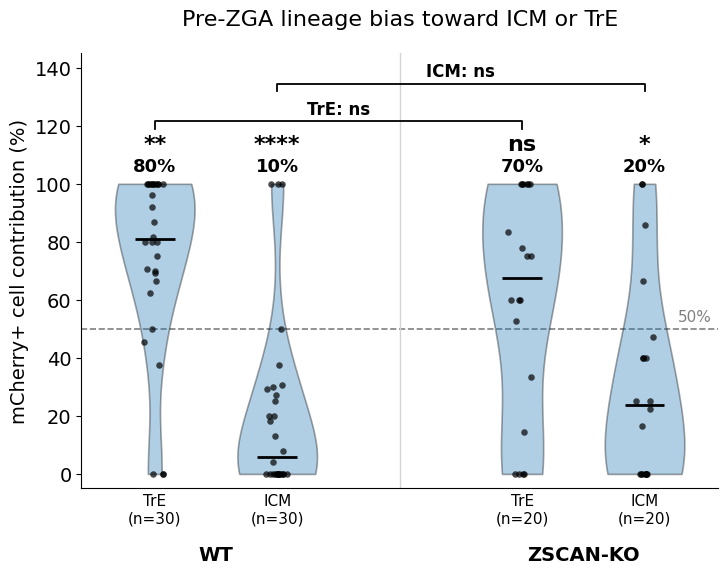

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import binomtest


# ============================================================
# 0. Plot settings
# ============================================================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

np.random.seed(42)


# ============================================================
# 1. Read data
# ============================================================
df = pd.read_csv(
    "red_icm_te_count.txt",
    sep="\t"
)


# ============================================================
# 2. Extract data
# ============================================================
icm = pd.to_numeric(
    df["Red ICM/Red total%"],
    errors="coerce"
)

te = pd.to_numeric(
    df["Red TE/Red total%"],
    errors="coerce"
)

treatment = df["treatment"].astype(str)


# ============================================================
# 3. Remove missing values
# ============================================================
mask = ~(
    icm.isna() |
    te.isna()
)

icm = icm[mask].reset_index(drop=True)
te = te[mask].reset_index(drop=True)
treatment = treatment[mask].reset_index(drop=True)


# ============================================================
# 4. Define groups
#
# WT remains WT
# All non-WT samples are combined as ZSCAN-KO
# ============================================================
group = treatment.where(
    treatment == "WT",
    "ZSCAN-KO"
)


# ============================================================
# 5. Extract WT and ZSCAN-KO
# ============================================================
wt_mask = group == "WT"
ko_mask = group == "ZSCAN-KO"

wt_te = te[wt_mask].values
wt_icm = icm[wt_mask].values

ko_te = te[ko_mask].values
ko_icm = icm[ko_mask].values


print("\n========================================")
print("Sample size")
print("========================================")

print(f"WT       n = {len(wt_te)}")
print(f"ZSCAN-KO n = {len(ko_te)}")


# ============================================================
# 6. Significance label
# ============================================================
def get_significance_label(p):

    if p < 1e-4:
        return "****"

    elif p < 1e-3:
        return "***"

    elif p < 1e-2:
        return "**"

    elif p < 0.05:
        return "*"

    else:
        return "ns"


# ============================================================
# 7. Determine lineage-biased embryos
#
# ICM-biased:
#     ICM contribution > 50%
#
# TrE-biased:
#     TrE contribution > 50%
# ============================================================

# WT
wt_icm_more = int(np.sum(wt_icm > 50))
wt_tre_more = int(np.sum(wt_te > 50))

wt_n = len(wt_icm)

# ZSCAN-KO
ko_icm_more = int(np.sum(ko_icm > 50))
ko_tre_more = int(np.sum(ko_te > 50))

ko_n = len(ko_icm)


# ============================================================
# 8. Calculate observed proportions
# ============================================================

# ICM-biased
wt_icm_prop = wt_icm_more / wt_n
ko_icm_prop = ko_icm_more / ko_n

# TrE-biased
wt_tre_prop = wt_tre_more / wt_n
ko_tre_prop = ko_tre_more / ko_n


# ============================================================
# 9. Within-group binomial tests
#
# H0: proportion = 0.5
# ============================================================

# WT ICM
res_wt_icm_50 = binomtest(
    k=wt_icm_more,
    n=wt_n,
    p=0.5,
    alternative="two-sided"
)

# WT TrE
res_wt_tre_50 = binomtest(
    k=wt_tre_more,
    n=wt_n,
    p=0.5,
    alternative="two-sided"
)

# KO ICM
res_ko_icm_50 = binomtest(
    k=ko_icm_more,
    n=ko_n,
    p=0.5,
    alternative="two-sided"
)

# KO TrE
res_ko_tre_50 = binomtest(
    k=ko_tre_more,
    n=ko_n,
    p=0.5,
    alternative="two-sided"
)


p_wt_icm_50 = res_wt_icm_50.pvalue
p_wt_tre_50 = res_wt_tre_50.pvalue

p_ko_icm_50 = res_ko_icm_50.pvalue
p_ko_tre_50 = res_ko_tre_50.pvalue


# ============================================================
# 10. Between-group binomial tests
#
# ICM:
#     WT = 3/30 = 0.10
#     KO = 4/20 = 0.20
#
#     Test KO against WT-observed proportion:
#     H0: p_KO = 0.10
#
# TrE:
#     WT = 24/30 = 0.80
#     KO = 14/20 = 0.70
#
#     Test KO against WT-observed proportion:
#     H0: p_KO = 0.80
# ============================================================

# ------------------------------------------------------------
# ICM: 0.1 vs 0.2
# ------------------------------------------------------------
res_icm_between = binomtest(
    k=ko_icm_more,
    n=ko_n,
    p=wt_icm_prop,
    alternative="two-sided"
)

p_icm_between = res_icm_between.pvalue


# ------------------------------------------------------------
# TrE: 0.8 vs 0.7
# ------------------------------------------------------------
res_tre_between = binomtest(
    k=ko_tre_more,
    n=ko_n,
    p=wt_tre_prop,
    alternative="two-sided"
)

p_tre_between = res_tre_between.pvalue


# ============================================================
# 11. Print complete statistical results
# ============================================================

print("\n========================================")
print("Lineage-biased embryo proportions")
print("========================================")

print("\nWT:")
print(
    f"ICM-biased: {wt_icm_more}/{wt_n} "
    f"= {wt_icm_prop:.3f} "
    f"({wt_icm_prop*100:.1f}%)"
)

print(
    f"TrE-biased: {wt_tre_more}/{wt_n} "
    f"= {wt_tre_prop:.3f} "
    f"({wt_tre_prop*100:.1f}%)"
)

print("\nZSCAN-KO:")
print(
    f"ICM-biased: {ko_icm_more}/{ko_n} "
    f"= {ko_icm_prop:.3f} "
    f"({ko_icm_prop*100:.1f}%)"
)

print(
    f"TrE-biased: {ko_tre_more}/{ko_n} "
    f"= {ko_tre_prop:.3f} "
    f"({ko_tre_prop*100:.1f}%)"
)


# ============================================================
# 12. Print tests vs 50%
# ============================================================

print("\n========================================")
print("Binomial tests vs 50%")
print("========================================")

print(
    f"WT ICM: "
    f"{wt_icm_more}/{wt_n}, "
    f"p = {p_wt_icm_50:.3e}, "
    f"{get_significance_label(p_wt_icm_50)}"
)

print(
    f"WT TrE: "
    f"{wt_tre_more}/{wt_n}, "
    f"p = {p_wt_tre_50:.3e}, "
    f"{get_significance_label(p_wt_tre_50)}"
)

print(
    f"ZSCAN-KO ICM: "
    f"{ko_icm_more}/{ko_n}, "
    f"p = {p_ko_icm_50:.3e}, "
    f"{get_significance_label(p_ko_icm_50)}"
)

print(
    f"ZSCAN-KO TrE: "
    f"{ko_tre_more}/{ko_n}, "
    f"p = {p_ko_tre_50:.3e}, "
    f"{get_significance_label(p_ko_tre_50)}"
)


# ============================================================
# 13. Print between-group tests
# ============================================================

print("\n========================================")
print("Between-group binomial tests")
print("========================================")

print("\nICM:")
print(
    f"WT       = {wt_icm_prop:.3f} "
    f"({wt_icm_more}/{wt_n})"
)

print(
    f"ZSCAN-KO = {ko_icm_prop:.3f} "
    f"({ko_icm_more}/{ko_n})"
)

print(
    f"WT proportion used as null p = "
    f"{wt_icm_prop:.3f}"
)

print(
    f"Binomial p = {p_icm_between:.3e}"
)

print(
    f"Significance = "
    f"{get_significance_label(p_icm_between)}"
)


print("\nTrE:")
print(
    f"WT       = {wt_tre_prop:.3f} "
    f"({wt_tre_more}/{wt_n})"
)

print(
    f"ZSCAN-KO = {ko_tre_prop:.3f} "
    f"({ko_tre_more}/{ko_n})"
)

print(
    f"WT proportion used as null p = "
    f"{wt_tre_prop:.3f}"
)

print(
    f"Binomial p = {p_tre_between:.3e}"
)

print(
    f"Significance = "
    f"{get_significance_label(p_tre_between)}"
)


# ============================================================
# 14. Plot data
# ============================================================

data = [
    wt_te,
    wt_icm,
    ko_te,
    ko_icm
]

positions = [
    1,
    2,
    4,
    5
]

labels = [
    f"TrE\n(n={len(wt_te)})",
    f"ICM\n(n={len(wt_icm)})",
    f"TrE\n(n={len(ko_te)})",
    f"ICM\n(n={len(ko_icm)})"
]


# ============================================================
# 15. Create figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.5, 6)
)


# ============================================================
# 16. Violin plots
# ============================================================

vp = ax.violinplot(
    data,
    positions=positions,
    widths=0.65,
    showmeans=False,
    showmedians=True,
    showextrema=False
)


for body in vp["bodies"]:

    body.set_alpha(0.35)

    body.set_edgecolor(
        "black"
    )

    body.set_linewidth(
        1.2
    )


vp["cmedians"].set_color(
    "black"
)

vp["cmedians"].set_linewidth(
    2
)


# ============================================================
# 17. Individual embryo points
# ============================================================

for pos, values in zip(
    positions,
    data
):

    jitter = np.random.normal(
        0,
        0.045,
        size=len(values)
    )

    jitter = np.clip(
        jitter,
        -0.15,
        0.15
    )

    ax.scatter(
        pos + jitter,
        values,
        color="black",
        alpha=0.70,
        s=22,
        linewidths=0,
        zorder=3
    )


# ============================================================
# 18. 50% reference line
# ============================================================

ax.axhline(
    50,
    linestyle="--",
    linewidth=1.2,
    color="grey",
    zorder=0
)

ax.text(
    5.55,
    51.5,
    "50%",
    ha="right",
    va="bottom",
    fontsize=11,
    color="grey"
)


# ============================================================
# 19. Add observed proportions above each violin
#
# WT:
#   TrE = 80%
#   ICM = 10%
#
# KO:
#   TrE = 70%
#   ICM = 20%
# ============================================================

prop_values = [
    wt_tre_prop,
    wt_icm_prop,
    ko_tre_prop,
    ko_icm_prop
]

for pos, prop in zip(
    positions,
    prop_values
):

    ax.text(
        pos,
        103,
        f"{prop*100:.0f}%",
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold"
    )


# ============================================================
# 20. Significance vs 50%
# ============================================================

# WT
ax.text(
    1,
    110,
    get_significance_label(p_wt_tre_50),
    ha="center",
    va="bottom",
    fontsize=16,
    fontweight="bold"
)

ax.text(
    2,
    110,
    get_significance_label(p_wt_icm_50),
    ha="center",
    va="bottom",
    fontsize=16,
    fontweight="bold"
)


# KO
ax.text(
    4,
    110,
    get_significance_label(p_ko_tre_50),
    ha="center",
    va="bottom",
    fontsize=16,
    fontweight="bold"
)

ax.text(
    5,
    110,
    get_significance_label(p_ko_icm_50),
    ha="center",
    va="bottom",
    fontsize=16,
    fontweight="bold"
)


# ============================================================
# 21. Bracket function
# ============================================================

def add_bracket(
    ax,
    x1,
    x2,
    y,
    h,
    text,
    fontsize=12
):

    ax.plot(
        [x1, x1, x2, x2],
        [y, y+h, y+h, y],
        color="black",
        linewidth=1.3,
        clip_on=False
    )

    ax.text(
        (x1 + x2) / 2,
        y + h + 1,
        text,
        ha="center",
        va="bottom",
        fontsize=fontsize,
        fontweight="bold"
    )


# ============================================================
# 22. Between-group significance
#
# ICM: 0.10 vs 0.20
# TrE: 0.80 vs 0.70
# ============================================================

add_bracket(
    ax,
    1,
    4,
    y=119,
    h=2.5,
    text=f"TrE: {get_significance_label(p_tre_between)}"
)


add_bracket(
    ax,
    2,
    5,
    y=132,
    h=2.5,
    text=f"ICM: {get_significance_label(p_icm_between)}"
)


# ============================================================
# 23. WT / ZSCAN-KO separator
# ============================================================

ax.axvline(
    3,
    color="lightgrey",
    linewidth=1,
    zorder=0
)


# ============================================================
# 24. Group labels
# ============================================================

ax.text(
    1.5,
    -0.13,
    "WT",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14,
    fontweight="bold"
)

ax.text(
    4.5,
    -0.13,
    "ZSCAN-KO",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14,
    fontweight="bold"
)


# ============================================================
# 25. Axis formatting
# ============================================================

ax.set_xticks(
    positions
)

ax.set_xticklabels(
    labels,
    fontsize=11
)

ax.set_xlim(
    0.4,
    5.6
)

ax.set_ylim(
    -5,
    145
)

ax.set_ylabel(
    "mCherry+ cell contribution (%)",
    fontsize=14
)

ax.set_title(
    "Pre-ZGA lineage bias toward ICM or TrE",
    fontsize=16,
    pad=20
)


# Remove top/right spines
ax.spines["top"].set_visible(
    False
)

ax.spines["right"].set_visible(
    False
)

ax.tick_params(
    axis="x",
    length=0
)


# ============================================================
# 26. Save
# ============================================================

plt.tight_layout()

plt.savefig(
    "Lineage_allocation_bias_WT_ZSCAN-KO_binomtest.svg",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    "Lineage_allocation_bias_WT_ZSCAN-KO_binomtest.pdf",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()


Sample size
WT       n = 30
ZSCAN-KO n = 20

TEST 1: Distribution vs 50%
WT ICM-biased = 3/30 (10.0%)
WT TrE-biased = 24/30 (80.0%)
WT binomial test vs 0.5: p = 8.430e-06 (****)

ZSCAN-KO ICM-biased = 4/20 (20.0%)
ZSCAN-KO TrE-biased = 14/20 (70.0%)
ZSCAN-KO binomial test vs 0.5: p = 1.182e-02 (*)

TEST 2: Continuous distribution comparison
WT-TrE vs ZSCAN-KO-TrE: MWU p = 1.850e-01 (ns)
WT-ICM vs ZSCAN-KO-ICM: MWU p = 3.150e-01 (ns)

TEST 3: Biased-embryo proportion comparison
ICM-biased:
WT       = 3/30 = 0.100
ZSCAN-KO = 4/20 = 0.200
Binomial p = 1.330e-01 (ns)

TrE-biased:
WT       = 24/30 = 0.800
ZSCAN-KO = 14/20 = 0.700
Binomial p = 2.650e-01 (ns)


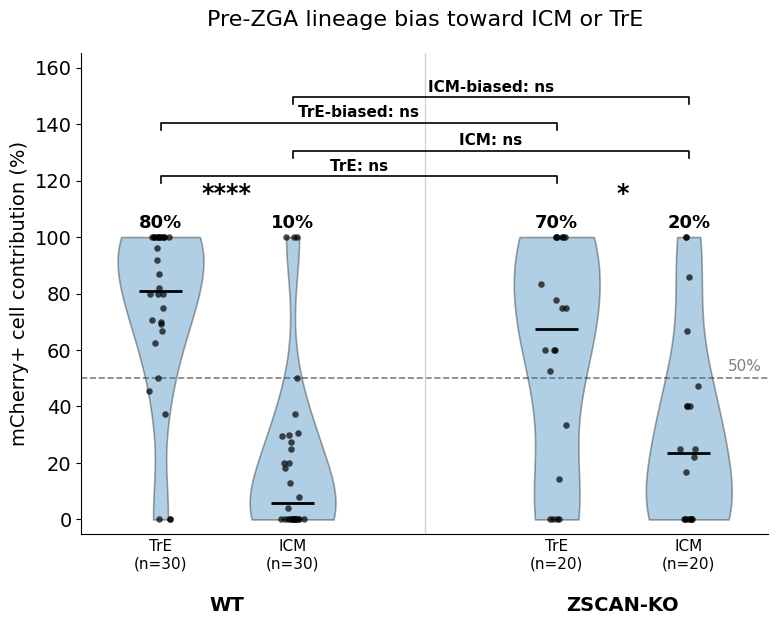

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import binomtest, mannwhitneyu


# ============================================================
# 0. Plot settings
# ============================================================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

np.random.seed(42)


# ============================================================
# 1. Read data
# ============================================================
df = pd.read_csv(
    "red_icm_te_count.txt",
    sep="\t"
)


# ============================================================
# 2. Extract data
# ============================================================
icm = pd.to_numeric(
    df["Red ICM/Red total%"],
    errors="coerce"
)

te = pd.to_numeric(
    df["Red TE/Red total%"],
    errors="coerce"
)

treatment = df["treatment"].astype(str)


# ============================================================
# 3. Remove missing values
# ============================================================
mask = ~(icm.isna() | te.isna())

icm = icm[mask].reset_index(drop=True)
te = te[mask].reset_index(drop=True)
treatment = treatment[mask].reset_index(drop=True)


# ============================================================
# 4. Define groups
#
# WT remains WT
# All non-WT samples are combined as ZSCAN-KO
# ============================================================
group = treatment.where(
    treatment == "WT",
    "ZSCAN-KO"
)


# ============================================================
# 5. Extract groups
# ============================================================
wt_mask = group == "WT"
ko_mask = group == "ZSCAN-KO"

wt_te = te[wt_mask].values
wt_icm = icm[wt_mask].values

ko_te = te[ko_mask].values
ko_icm = icm[ko_mask].values


wt_n = len(wt_te)
ko_n = len(ko_te)


print("\n========================================")
print("Sample size")
print("========================================")

print(f"WT       n = {wt_n}")
print(f"ZSCAN-KO n = {ko_n}")


# ============================================================
# 6. Significance function
# ============================================================
def get_significance_label(p):

    if p < 1e-4:
        return "****"

    elif p < 1e-3:
        return "***"

    elif p < 1e-2:
        return "**"

    elif p < 0.05:
        return "*"

    else:
        return "ns"


# ============================================================
# ============================================================
# 7. TEST 1
# Each distribution vs 50%
#
# WT-TrE and WT-ICM are symmetric.
# KO-TrE and KO-ICM are symmetric.
#
# Therefore:
#
# WT: one binomial test
# KO: one binomial test
#
# We use ICM-biased embryos as the success event.
# ============================================================
# ============================================================

# ------------------------------------------------------------
# Define ICM-biased embryos
# ------------------------------------------------------------
wt_icm_bias_n = int(
    np.sum(wt_icm > 50)
)

ko_icm_bias_n = int(
    np.sum(ko_icm > 50)
)


# ------------------------------------------------------------
# Binomial test against 0.5
# ------------------------------------------------------------

wt_binom = binomtest(
    k=wt_icm_bias_n,
    n=wt_n,
    p=0.5,
    alternative="two-sided"
)

ko_binom = binomtest(
    k=ko_icm_bias_n,
    n=ko_n,
    p=0.5,
    alternative="two-sided"
)


p_wt_50 = wt_binom.pvalue
p_ko_50 = ko_binom.pvalue


# ------------------------------------------------------------
# Observed biased proportions
# ------------------------------------------------------------

wt_icm_bias_prop = wt_icm_bias_n / wt_n
ko_icm_bias_prop = ko_icm_bias_n / ko_n

wt_te_bias_n = int(
    np.sum(wt_te > 50)
)

ko_te_bias_n = int(
    np.sum(ko_te > 50)
)

wt_te_bias_prop = wt_te_bias_n / wt_n
ko_te_bias_prop = ko_te_bias_n / ko_n


# ============================================================
# Print TEST 1
# ============================================================

print("\n========================================")
print("TEST 1: Distribution vs 50%")
print("========================================")

print(
    f"WT ICM-biased = "
    f"{wt_icm_bias_n}/{wt_n} "
    f"({wt_icm_bias_prop*100:.1f}%)"
)

print(
    f"WT TrE-biased = "
    f"{wt_te_bias_n}/{wt_n} "
    f"({wt_te_bias_prop*100:.1f}%)"
)

print(
    f"WT binomial test vs 0.5: "
    f"p = {p_wt_50:.3e} "
    f"({get_significance_label(p_wt_50)})"
)


print(
    f"\nZSCAN-KO ICM-biased = "
    f"{ko_icm_bias_n}/{ko_n} "
    f"({ko_icm_bias_prop*100:.1f}%)"
)

print(
    f"ZSCAN-KO TrE-biased = "
    f"{ko_te_bias_n}/{ko_n} "
    f"({ko_te_bias_prop*100:.1f}%)"
)

print(
    f"ZSCAN-KO binomial test vs 0.5: "
    f"p = {p_ko_50:.3e} "
    f"({get_significance_label(p_ko_50)})"
)


# ============================================================
# ============================================================
# 8. TEST 2
# Compare continuous distributions between groups
#
# WT-TrE vs KO-TrE
# WT-ICM vs KO-ICM
#
# Mann–Whitney U test
# ============================================================
# ============================================================

# ------------------------------------------------------------
# TrE distribution
# ------------------------------------------------------------
mw_te = mannwhitneyu(
    wt_te,
    ko_te,
    alternative="two-sided"
)

p_mw_te = mw_te.pvalue


# ------------------------------------------------------------
# ICM distribution
# ------------------------------------------------------------
mw_icm = mannwhitneyu(
    wt_icm,
    ko_icm,
    alternative="two-sided"
)

p_mw_icm = mw_icm.pvalue


# ============================================================
# Print TEST 2
# ============================================================

print("\n========================================")
print("TEST 2: Continuous distribution comparison")
print("========================================")

print(
    f"WT-TrE vs ZSCAN-KO-TrE: "
    f"MWU p = {p_mw_te:.3e} "
    f"({get_significance_label(p_mw_te)})"
)

print(
    f"WT-ICM vs ZSCAN-KO-ICM: "
    f"MWU p = {p_mw_icm:.3e} "
    f"({get_significance_label(p_mw_icm)})"
)


# ============================================================
# ============================================================
# 9. TEST 3
# Compare proportions of lineage-biased embryos
#
# ICM-biased:
#     WT = 3/30 = 0.10
#     KO = 4/20 = 0.20
#
# TrE-biased:
#     WT = 24/30 = 0.80
#     KO = 14/20 = 0.70
#
# Use exact binomial test with WT observed proportion
# as the null probability for KO.
# ============================================================
# ============================================================


# ------------------------------------------------------------
# ICM-biased: 0.10 vs 0.20
# ------------------------------------------------------------
binom_icm_between = binomtest(
    k=ko_icm_bias_n,
    n=ko_n,
    p=wt_icm_bias_prop,
    alternative="two-sided"
)

p_icm_bias_between = binom_icm_between.pvalue


# ------------------------------------------------------------
# TrE-biased: 0.80 vs 0.70
# ------------------------------------------------------------
binom_te_between = binomtest(
    k=ko_te_bias_n,
    n=ko_n,
    p=wt_te_bias_prop,
    alternative="two-sided"
)

p_te_bias_between = binom_te_between.pvalue


# ============================================================
# Print TEST 3
# ============================================================

print("\n========================================")
print("TEST 3: Biased-embryo proportion comparison")
print("========================================")

print(
    f"ICM-biased:\n"
    f"WT       = {wt_icm_bias_n}/{wt_n} "
    f"= {wt_icm_bias_prop:.3f}\n"
    f"ZSCAN-KO = {ko_icm_bias_n}/{ko_n} "
    f"= {ko_icm_bias_prop:.3f}\n"
    f"Binomial p = {p_icm_bias_between:.3e} "
    f"({get_significance_label(p_icm_bias_between)})"
)

print(
    f"\nTrE-biased:\n"
    f"WT       = {wt_te_bias_n}/{wt_n} "
    f"= {wt_te_bias_prop:.3f}\n"
    f"ZSCAN-KO = {ko_te_bias_n}/{ko_n} "
    f"= {ko_te_bias_prop:.3f}\n"
    f"Binomial p = {p_te_bias_between:.3e} "
    f"({get_significance_label(p_te_bias_between)})"
)

# ============================================================
# ============================================================
# 10. Plot data
# ============================================================
# ============================================================

data = [
    wt_te,
    wt_icm,
    ko_te,
    ko_icm
]

positions = [
    1,
    2,
    4,
    5
]

labels = [
    f"TrE\n(n={wt_n})",
    f"ICM\n(n={wt_n})",
    f"TrE\n(n={ko_n})",
    f"ICM\n(n={ko_n})"
]


# ============================================================
# 11. Create figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6.5)
)


# ============================================================
# 12. Violin plots
# ============================================================

vp = ax.violinplot(
    data,
    positions=positions,
    widths=0.65,
    showmeans=False,
    showmedians=True,
    showextrema=False
)


for body in vp["bodies"]:

    body.set_alpha(0.35)
    body.set_edgecolor("black")
    body.set_linewidth(1.2)

vp["cmedians"].set_color("black")
vp["cmedians"].set_linewidth(2)

# ============================================================
# 13. Individual points
# ============================================================

for pos, values in zip(
    positions,
    data
):

    jitter = np.random.normal(
        0,
        0.045,
        size=len(values)
    )

    jitter = np.clip(
        jitter,
        -0.15,
        0.15
    )

    ax.scatter(
        pos + jitter,
        values,
        color="black",
        alpha=0.70,
        s=22,
        linewidths=0,
        zorder=3
    )

# ============================================================
# 14. 50% reference line
# ============================================================

ax.axhline(
    50,
    linestyle="--",
    linewidth=1.2,
    color="grey",
    zorder=0
)

ax.text(
    5.55,
    51.5,
    "50%",
    ha="right",
    va="bottom",
    fontsize=11,
    color="grey"
)

# ============================================================
# 15. Observed biased proportions
#
# WT:
#     TrE = 80%
#     ICM = 10%
#
# KO:
#     TrE = 70%
#     ICM = 20%
# ============================================================

observed_props = [
    wt_te_bias_prop,
    wt_icm_bias_prop,
    ko_te_bias_prop,
    ko_icm_bias_prop
]

for pos, prop in zip(
    positions,
    observed_props
):

    ax.text(
        pos,
        102,
        f"{prop*100:.0f}%",
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold"
    )

# ============================================================
# 16. TEST 1 annotation
#
# One annotation per group because ICM/TrE are symmetric.
# ============================================================

ax.text(
    1.5,
    111,
    get_significance_label(p_wt_50),
    ha="center",
    va="bottom",
    fontsize=17,
    fontweight="bold"
)

ax.text(
    4.5,
    111,
    get_significance_label(p_ko_50),
    ha="center",
    va="bottom",
    fontsize=17,
    fontweight="bold"
)

# ============================================================
# 17. Bracket function
# ============================================================

def add_bracket(
    ax,
    x1,
    x2,
    y,
    h,
    text,
    fontsize=11
):

    ax.plot(
        [x1, x1, x2, x2],
        [y, y+h, y+h, y],
        color="black",
        linewidth=1.2,
        clip_on=False
    )

    ax.text(
        (x1 + x2) / 2,
        y + h + 1,
        text,
        ha="center",
        va="bottom",
        fontsize=fontsize,
        fontweight="bold"
    )

# ============================================================
# 18. TEST 2
# Continuous distribution comparison
#
# WT-TrE vs KO-TrE
# WT-ICM vs KO-ICM
# ============================================================

add_bracket(
    ax,
    1,
    4,
    y=119,
    h=2.5,
    text=f"TrE: {get_significance_label(p_mw_te)}"
)

add_bracket(
    ax,
    2,
    5,
    y=128,
    h=2.5,
    text=f"ICM: {get_significance_label(p_mw_icm)}"
)

# ============================================================
# 19. TEST 3
# Biased-embryo proportions
#
# One comparison for ICM-biased proportion
# One comparison for TrE-biased proportion
# ============================================================

add_bracket(
    ax,
    1,
    4,
    y=138,
    h=2.5,
    text=f"TrE-biased: {get_significance_label(p_te_bias_between)}"
)

add_bracket(
    ax,
    2,
    5,
    y=147,
    h=2.5,
    text=f"ICM-biased: {get_significance_label(p_icm_bias_between)}"
)

# ============================================================
# 20. WT / KO separator
# ============================================================

ax.axvline(
    3,
    color="lightgrey",
    linewidth=1,
    zorder=0
)

# ============================================================
# 21. Group labels
# ============================================================

ax.text(
    1.5,
    -0.13,
    "WT",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14,
    fontweight="bold"
)

ax.text(
    4.5,
    -0.13,
    "ZSCAN-KO",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14,
    fontweight="bold"
)

# ============================================================
# 22. Axis formatting
# ============================================================

ax.set_xticks(
    positions
)

ax.set_xticklabels(
    labels,
    fontsize=11
)

ax.set_xlim(
    0.4,
    5.6
)

ax.set_ylim(
    -5,
    165
)

ax.set_ylabel(
    "mCherry+ cell contribution (%)",
    fontsize=14
)

ax.set_title(
    "Pre-ZGA lineage bias toward ICM or TrE",
    fontsize=16,
    pad=20
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="x",
    length=0
)

# ============================================================
# 23. Save
# ============================================================

plt.tight_layout()

plt.savefig(
    "Lineage_allocation_WT_ZSCAN-KO_three_tests.svg",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()

In [24]:
# ============================================================
# Quick bootstrap sample-size analysis
# WT vs ZSCAN4-KO
#
# Current:
#   WT = 30
#   ZSCAN4-KO = 20
#
# Add:
#   +5, +10, +15, +20, ...
#
# Test:
#   Mann–Whitney U
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu

# ============================================================
# 1. Settings
# ============================================================

INPUT_FILE = "red_icm_te_count.txt"

N_REP = 100          # 每个增加量重复抽样次数
MAX_ADD = 100        # 最多增加100个
ALPHA = 0.05

np.random.seed(42)

# ============================================================
# 2. Read data
# ============================================================

df = pd.read_csv(
    INPUT_FILE,
    sep="\t"
)

# ============================================================
# 3. Extract data
# ============================================================

icm = pd.to_numeric(
    df["Red ICM/Red total%"],
    errors="coerce"
)

te = pd.to_numeric(
    df["Red TE/Red total%"],
    errors="coerce"
)

treatment = df["treatment"].astype(str)

# ============================================================
# 4. Remove missing
# ============================================================

mask = ~(icm.isna() | te.isna())

icm = icm[mask].reset_index(drop=True)
te = te[mask].reset_index(drop=True)
treatment = treatment[mask].reset_index(drop=True)

# ============================================================
# 5. Define groups
# ============================================================

group = treatment.where(
    treatment == "WT",
    "ZSCAN4-KO"
)

wt_mask = group == "WT"
ko_mask = group == "ZSCAN4-KO"

wt_icm = icm[wt_mask].values
ko_icm = icm[ko_mask].values

wt_te = te[wt_mask].values
ko_te = te[ko_mask].values

wt_n = len(wt_icm)
ko_n = len(ko_icm)

print("=" * 65)
print("Current sample size")
print("=" * 65)

print(f"WT        = {wt_n}")
print(f"ZSCAN4-KO = {ko_n}")

# ============================================================
# 6. Current P values
# ============================================================

current_icm = mannwhitneyu(
    wt_icm,
    ko_icm,
    alternative="two-sided"
)

current_te = mannwhitneyu(
    wt_te,
    ko_te,
    alternative="two-sided"
)

print("\nCurrent Mann–Whitney U:")
print(
    f"ICM: P = {current_icm.pvalue:.4f}"
)

print(
    f"TrE: P = {current_te.pvalue:.4f}"
)

# ============================================================
# 7. Bootstrap function
# ============================================================

def quick_bootstrap(
    wt_data,
    ko_data,
    add_n,
    n_rep=100
):

    p_values = []

    for i in range(n_rep):

        # 当前样本 + 增加样本
        new_wt_n = len(wt_data) + add_n
        new_ko_n = len(ko_data) + add_n

        # 从当前经验分布有放回抽样
        wt_sample = np.random.choice(
            wt_data,
            size=new_wt_n,
            replace=True
        )

        ko_sample = np.random.choice(
            ko_data,
            size=new_ko_n,
            replace=True
        )

        # Mann–Whitney U
        test = mannwhitneyu(
            wt_sample,
            ko_sample,
            alternative="two-sided"
        )

        p_values.append(test.pvalue)

    p_values = np.array(p_values)

    return {
        "mean_p": np.mean(p_values),
        "median_p": np.median(p_values),
        "min_p": np.min(p_values),
        "max_p": np.max(p_values),
        "significant_rate": np.mean(
            p_values < 0.05
        )
    }

# ============================================================
# 8. Run analysis
# ============================================================

results = []

print("\n" + "=" * 65)
print("Bootstrap sample-size analysis")
print("=" * 65)

for add_n in range(
    0,
    MAX_ADD + 1,
    5
):

    print(
        f"Running +{add_n} ..."
    )

    # -------------------------
    # ICM
    # -------------------------

    icm_result = quick_bootstrap(
        wt_icm,
        ko_icm,
        add_n,
        n_rep=N_REP
    )

    results.append({
        "endpoint": "ICM",
        "additional_each_group": add_n,
        "WT_n": wt_n + add_n,
        "KO_n": ko_n + add_n,
        "mean_p": icm_result["mean_p"],
        "median_p": icm_result["median_p"],
        "min_p": icm_result["min_p"],
        "max_p": icm_result["max_p"],
        "significant_rate": icm_result["significant_rate"]
    })

    # -------------------------
    # TrE
    # -------------------------

    te_result = quick_bootstrap(
        wt_te,
        ko_te,
        add_n,
        n_rep=N_REP
    )

    results.append({
        "endpoint": "TrE",
        "additional_each_group": add_n,
        "WT_n": wt_n + add_n,
        "KO_n": ko_n + add_n,
        "mean_p": te_result["mean_p"],
        "median_p": te_result["median_p"],
        "min_p": te_result["min_p"],
        "max_p": te_result["max_p"],
        "significant_rate": te_result["significant_rate"]
    })

# ============================================================
# 9. Results table
# ============================================================

result_df = pd.DataFrame(results)

# ============================================================
# 10. Print concise summary
# ============================================================

print("\n")
print("=" * 90)
print("RESULTS")
print("=" * 90)

print(
    result_df[
        [
            "endpoint",
            "additional_each_group",
            "WT_n",
            "KO_n",
            "median_p",
            "significant_rate"
        ]
    ].to_string(
        index=False,
        formatters={
            "median_p": "{:.4f}".format,
            "significant_rate": "{:.1%}".format
        }
    )
)

# ============================================================
# 11. Find first sample size with median P < 0.05
# ============================================================

print("\n")
print("=" * 90)
print("FIRST SAMPLE SIZE WITH MEDIAN P < 0.05")
print("=" * 90)

for endpoint in ["ICM", "TrE"]:

    tmp = result_df[
        (result_df["endpoint"] == endpoint) &
        (result_df["median_p"] < 0.05)
    ]

    if len(tmp) == 0:

        print(
            f"{endpoint}: "
            f"not reached within +{MAX_ADD}"
        )

    else:

        first = tmp.iloc[0]

        print(
            f"{endpoint}: "
            f"+{int(first['additional_each_group'])} "
            f"per group "
            f"(WT={int(first['WT_n'])}, "
            f"KO={int(first['KO_n'])}), "
            f"median P={first['median_p']:.4f}"
        )

# ============================================================
# 12. Find first sample size with >=50% significant
# ============================================================

print("\n")
print("=" * 90)
print("FIRST SAMPLE SIZE WITH >=50% SIGNIFICANT")
print("=" * 90)

for endpoint in ["ICM", "TrE"]:

    tmp = result_df[
        (result_df["endpoint"] == endpoint) &
        (result_df["significant_rate"] >= 0.50)
    ]

    if len(tmp) == 0:

        print(
            f"{endpoint}: "
            f"not reached within +{MAX_ADD}"
        )

    else:

        first = tmp.iloc[0]

        print(
            f"{endpoint}: "
            f"+{int(first['additional_each_group'])} "
            f"per group "
            f"(WT={int(first['WT_n'])}, "
            f"KO={int(first['KO_n'])}), "
            f"significant in "
            f"{first['significant_rate']:.1%} "
            f"of simulations"
        )

# ============================================================
# 13. Save results
# ============================================================

result_df.to_csv(
    "quick_bootstrap_sample_size_results.csv",
    index=False
)

print("\nResults saved to:")
print("quick_bootstrap_sample_size_results.csv")

Current sample size
WT        = 30
ZSCAN4-KO = 20

Current Mann–Whitney U:
ICM: P = 0.3150
TrE: P = 0.1850

Bootstrap sample-size analysis
Running +0 ...
Running +5 ...
Running +10 ...
Running +15 ...
Running +20 ...
Running +25 ...
Running +30 ...
Running +35 ...
Running +40 ...
Running +45 ...
Running +50 ...
Running +55 ...
Running +60 ...
Running +65 ...
Running +70 ...
Running +75 ...
Running +80 ...
Running +85 ...
Running +90 ...
Running +95 ...
Running +100 ...


RESULTS
endpoint  additional_each_group  WT_n  KO_n median_p significant_rate
     ICM                      0    30    20   0.3219            14.0%
     TrE                      0    30    20   0.1622            25.0%
     ICM                      5    35    25   0.2090            23.0%
     TrE                      5    35    25   0.0781            40.0%
     ICM                     10    40    30   0.2072            22.0%
     TrE                     10    40    30   0.1127            36.0%
     ICM                  

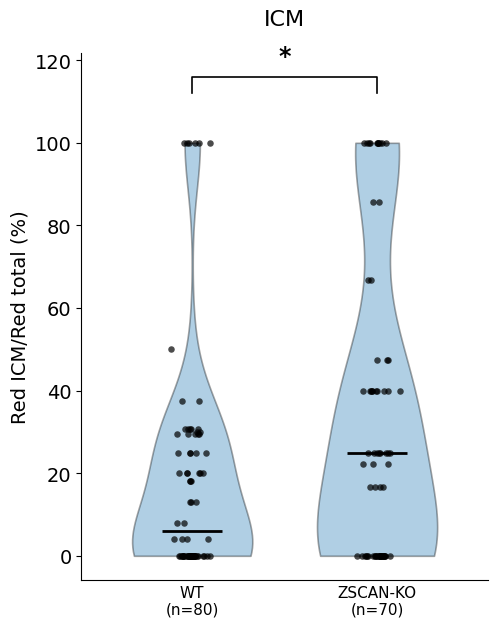


ICM simulated final sample
Additional samples per group = +50
WT       n = 80
ZSCAN-KO n = 70
Mann–Whitney U P = 0.0250582
Significance = *
Figure saved: ICM_simulated_final_distribution.svg


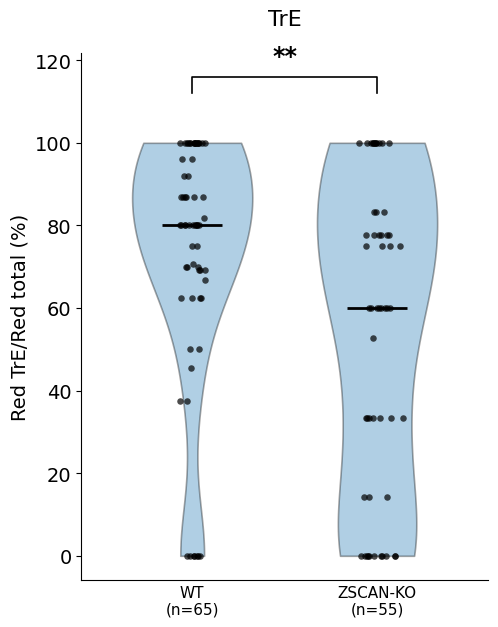


TrE simulated final sample
Additional samples per group = +35
WT       n = 65
ZSCAN-KO n = 55
Mann–Whitney U P = 0.00545658
Significance = **
Figure saved: TrE_simulated_final_distribution.svg


In [30]:
# ============================================================
# 14. Visualize simulated final sample distribution
#
# Style based on the user's existing lineage-allocation figure
#
# WT vs ZSCAN4-KO
# Mann–Whitney U
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import mannwhitneyu

# ============================================================
# Plot settings
# ============================================================

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ============================================================
# 15. Find first sample size with >=50% significant
# ============================================================

def get_first_significant_sample_size(
    result_df,
    endpoint,
    threshold=0.50
):

    tmp = result_df[
        (result_df["endpoint"] == endpoint) &
        (result_df["significant_rate"] >= threshold)
    ].sort_values(
        "additional_each_group"
    )

    if len(tmp) == 0:
        return None

    return int(
        tmp.iloc[0]["additional_each_group"]
    )

# ============================================================
# 16. Generate one representative final dataset
# ============================================================

def generate_final_sample(
    wt_data,
    ko_data,
    add_n
):

    final_wt_n = len(wt_data) + add_n
    final_ko_n = len(ko_data) + add_n

    wt_sample = np.random.choice(
        wt_data,
        size=final_wt_n,
        replace=True
    )

    ko_sample = np.random.choice(
        ko_data,
        size=final_ko_n,
        replace=True
    )

    return wt_sample, ko_sample

# ============================================================
# 17. Plot function
# ============================================================

def plot_final_sample_distribution(
    wt_data,
    ko_data,
    endpoint,
    add_n,
    output_prefix
):

    # --------------------------------------------------------
    # Generate representative final dataset
    # --------------------------------------------------------

    wt_sample, ko_sample = generate_final_sample(
        wt_data,
        ko_data,
        add_n
    )

    # --------------------------------------------------------
    # Mann–Whitney U test
    # --------------------------------------------------------

    mw = mannwhitneyu(
        wt_sample,
        ko_sample,
        alternative="two-sided"
    )

    p = mw.pvalue

    # --------------------------------------------------------
    # Sample sizes
    # --------------------------------------------------------

    wt_n_final = len(wt_sample)
    ko_n_final = len(ko_sample)

    # --------------------------------------------------------
    # Data
    # --------------------------------------------------------

    data = [
        wt_sample,
        ko_sample
    ]

    positions = [
        1,
        2
    ]

    labels = [
        f"WT\n(n={wt_n_final})",
        f"ZSCAN-KO\n(n={ko_n_final})"
    ]

    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(5.2, 6.5)
    )

    # --------------------------------------------------------
    # Violin
    # --------------------------------------------------------

    vp = ax.violinplot(
        data,
        positions=positions,
        widths=0.65,
        showmeans=False,
        showmedians=True,
        showextrema=False
    )

    for body in vp["bodies"]:

        body.set_alpha(0.35)
        body.set_edgecolor("black")
        body.set_linewidth(1.2)

    vp["cmedians"].set_color("black")
    vp["cmedians"].set_linewidth(2)

    # --------------------------------------------------------
    # Individual points
    # --------------------------------------------------------

    for pos, values in zip(
        positions,
        data
    ):

        jitter = np.random.normal(
            0,
            0.045,
            size=len(values)
        )

        jitter = np.clip(
            jitter,
            -0.15,
            0.15
        )

        ax.scatter(
            pos + jitter,
            values,
            color="black",
            alpha=0.70,
            s=22,
            linewidths=0,
            zorder=3
        )

    # --------------------------------------------------------
    # Significance label
    # --------------------------------------------------------

    def get_sig(p):

        if p < 1e-4:
            return "****"
        elif p < 1e-3:
            return "***"
        elif p < 1e-2:
            return "**"
        elif p < 0.05:
            return "*"
        else:
            return "ns"

    sig = get_sig(p)

    # --------------------------------------------------------
    # Bracket
    # --------------------------------------------------------

    ymax = max(
        np.max(wt_sample),
        np.max(ko_sample)
    )

    ymin = min(
        np.min(wt_sample),
        np.min(ko_sample)
    )

    data_range = ymax - ymin

    if data_range == 0:
        data_range = 1

    bracket_y = ymax + data_range * 0.12
    bracket_h = data_range * 0.04

    ax.plot(
        [
            1,
            1,
            2,
            2
        ],
        [
            bracket_y,
            bracket_y + bracket_h,
            bracket_y + bracket_h,
            bracket_y
        ],
        color="black",
        linewidth=1.2,
        clip_on=False
    )

    ax.text(
        1.5,
        bracket_y + bracket_h + data_range * 0.02,
        sig,
        ha="center",
        va="bottom",
        fontsize=17,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # Axis
    # --------------------------------------------------------

    ax.set_xticks(
        positions
    )

    ax.set_xticklabels(
        labels,
        fontsize=11
    )

    ax.set_xlim(
        0.4,
        2.6
    )

    ax.set_ylabel(
        f"Red {endpoint}/Red total (%)",
        fontsize=14
    )

    ax.set_title(
        f"{endpoint}",
        fontsize=16,
        pad=20
    )

    # --------------------------------------------------------
    # Spines
    # --------------------------------------------------------

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="x",
        length=0
    )

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    plt.tight_layout()

    outfile = (
        f"{output_prefix}_simulated_final_distribution.svg"
    )

    plt.savefig(
        outfile,
        dpi=300,
        bbox_inches="tight",
        transparent=True
    )

    plt.show()

    # --------------------------------------------------------
    # Print
    # --------------------------------------------------------

    print("\n========================================")
    print(f"{endpoint} simulated final sample")
    print("========================================")

    print(
        f"Additional samples per group = +{add_n}"
    )

    print(
        f"WT       n = {wt_n_final}"
    )

    print(
        f"ZSCAN-KO n = {ko_n_final}"
    )

    print(
        f"Mann–Whitney U P = {p:.6g}"
    )

    print(
        f"Significance = {sig}"
    )

    print(
        f"Figure saved: {outfile}"
    )

    return wt_sample, ko_sample, p

# ============================================================
# 18. ICM
# ============================================================

icm_add_n = get_first_significant_sample_size(
    result_df,
    "ICM",
    threshold=0.50
)

if icm_add_n is not None:

    icm_final_wt, icm_final_ko, icm_final_p = \
        plot_final_sample_distribution(
            wt_icm,
            ko_icm,
            "ICM",
            icm_add_n,
            "ICM"
        )

else:

    print(
        "\nICM: no sample size reached "
        ">=50% significant within the tested range."
    )

# ============================================================
# 19. TrE
# ============================================================

te_add_n = get_first_significant_sample_size(
    result_df,
    "TrE",
    threshold=0.50
)

if te_add_n is not None:

    te_final_wt, te_final_ko, te_final_p = \
        plot_final_sample_distribution(
            wt_te,
            ko_te,
            "TrE",
            te_add_n,
            "TrE"
        )

else:

    print(
        "\nTrE: no sample size reached "
        ">=50% significant within the tested range."
    )